<ipython-input-1-c35b1d663a77>:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  plot_data = plot_data.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)


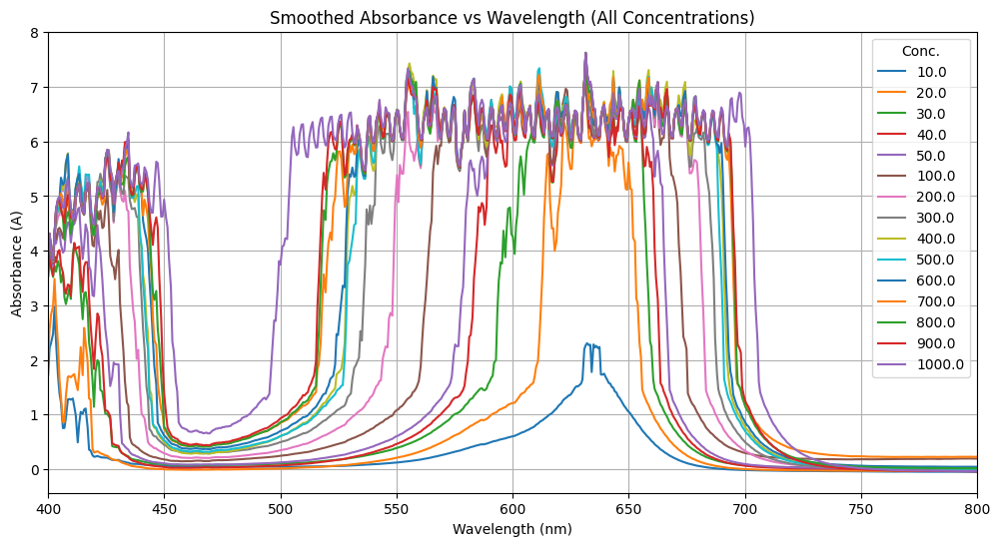

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === Load the Excel File ===
file_path = "blue concs.xlsx"  # <-- change path if needed
xls = pd.ExcelFile(file_path)
sheet_names = xls.sheet_names

# === Step 1: Load and Average All 6 DI Scans ===
di_sheets = [s for s in sheet_names if s.startswith("0-")]
di_data = []

for s in di_sheets:
    df = pd.read_excel(xls, sheet_name=s, skiprows=1)
    df.columns = ["wavelength", "transmission"]
    df = df.groupby("wavelength", as_index=False).mean()
    di_data.append(df)

avg_di = pd.concat(di_data).groupby("wavelength", as_index=False).mean()

# === Step 2: Load Sample Sheets and Extract Concentrations ===
sample_data = []

for s in sheet_names:
    if not s.startswith("0-"):
        conc_str = s.split("-")[0]
        try:
            conc_val = float(conc_str)
        except ValueError:
            continue
        df = pd.read_excel(xls, sheet_name=s, skiprows=1)
        df.columns = ["wavelength", "transmission"]
        df = df.groupby("wavelength", as_index=False).mean()
        df["concentration"] = conc_val
        sample_data.append(df)

samples_df = pd.concat(sample_data)

# === Step 3: Calculate Absorbance ===
T0_map = dict(zip(avg_di["wavelength"], avg_di["transmission"]))
samples_df["T0"] = samples_df["wavelength"].map(T0_map)
samples_df["T0"] = samples_df["T0"].clip(lower=1e-6)
samples_df["transmission"] = samples_df["transmission"].clip(lower=1e-6)
samples_df["absorbance"] = -np.log10(samples_df["transmission"] / samples_df["T0"])

# === Step 4: Smooth Absorbance ===
samples_df = samples_df.sort_values(["concentration", "wavelength"])
samples_df["smoothed_absorbance"] = (
    samples_df.groupby("concentration")["absorbance"]
    .transform(lambda x: x.rolling(51, center=True).mean())
)

# === Step 5: Downsample for Clean Plot ===
plot_data = samples_df.query("400 <= wavelength <= 800").dropna(subset=["smoothed_absorbance"])
plot_data = plot_data.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)

# === Step 6: Plot ===
plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_data, x="wavelength", y="smoothed_absorbance", hue="concentration", palette="tab10")

plt.title("Smoothed Absorbance vs Wavelength (All Concentrations)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance (A)")
plt.grid(True)
plt.xlim(400, 800)
plt.legend(title="Conc.")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === Load the Excel File ===
file_path = "blue concs.xlsx"  # Change if needed
xls = pd.ExcelFile(file_path)
sheet_names = xls.sheet_names

# === Step 1: Load and Average All 6 DI Scans ===
di_sheets = [s for s in sheet_names if s.startswith("0-")]
di_data = []

for s in di_sheets:
    df = pd.read_excel(xls, sheet_name=s, skiprows=1)
    df.columns = ["wavelength", "transmission"]
    df = df.groupby("wavelength", as_index=False).mean()
    di_data.append(df)

avg_di = pd.concat(di_data).groupby("wavelength", as_index=False).mean()

# === Step 2: Smooth DI Transmission ===
avg_di = avg_di.sort_values("wavelength")
avg_di["smoothed_T0"] = avg_di["transmission"].rolling(51, center=True).mean()

# === Step 3: Load Sample Sheets and Extract Concentrations ===
sample_data = []

for s in sheet_names:
    if not s.startswith("0-"):
        conc_str = s.split("-")[0]
        try:
            conc_val = float(conc_str)
        except ValueError:
            continue
        df = pd.read_excel(xls, sheet_name=s, skiprows=1)
        df.columns = ["wavelength", "transmission"]
        df = df.groupby("wavelength", as_index=False).mean()
        df["concentration"] = conc_val
        df = df.sort_values("wavelength")
        df["smoothed_transmission"] = df["transmission"].rolling(51, center=True).mean()
        sample_data.append(df)

samples_df = pd.concat(sample_data)



# Fix for saturation by clipping both T and T0
samples_df["T0"] = samples_df["T0"].clip(lower=1e-2)
samples_df["smoothed_transmission"] = samples_df["smoothed_transmission"].clip(lower=1e-2)

samples_df["absorbance"] = -np.log10(samples_df["smoothed_transmission"] / samples_df["T0"])


# === Step 5: Downsample for Clean Plot ===
plot_data = samples_df.query("400 <= wavelength <= 800").dropna(subset=["absorbance"])
plot_data = plot_data.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)

# === Step 6: Plot ===
plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_data, x="wavelength", y="absorbance", hue="concentration", palette="tab10")

plt.title("Absorbance vs Wavelength (Smoothed Transmission First)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance (A)")
plt.grid(True)
plt.xlim(400, 800)
plt.legend(title="Conc.")
plt.show()


KeyError: 'T0'

In [ ]:
# === Step 5 (alt): Plot Smoothed Transmission ===
plot_data = samples_df.query("400 <= wavelength <= 800").dropna(subset=["smoothed_transmission"])
plot_data = plot_data.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)

plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_data, x="wavelength", y="smoothed_transmission", hue="concentration", palette="tab10")

plt.title("Smoothed Transmission vs Wavelength (All Concentrations)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission (a.u.)")
plt.grid(True)
plt.xlim(400, 800)
plt.legend(title="Conc.")
plt.show()


KeyError: ['smoothed_transmission']

<ipython-input-5-105a7ca1bc27>:55: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  plot_trans = plot_trans.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)
<ipython-input-5-105a7ca1bc27>:58: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  plot_abs = plot_abs.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)


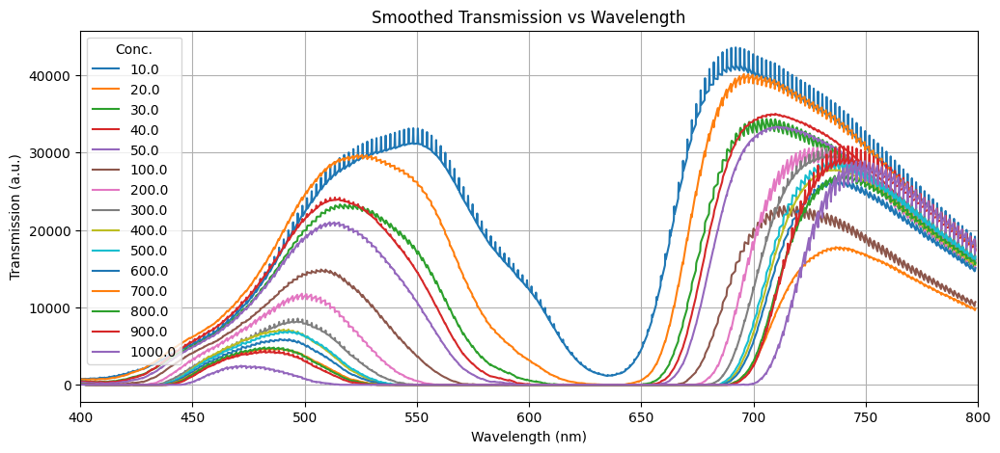

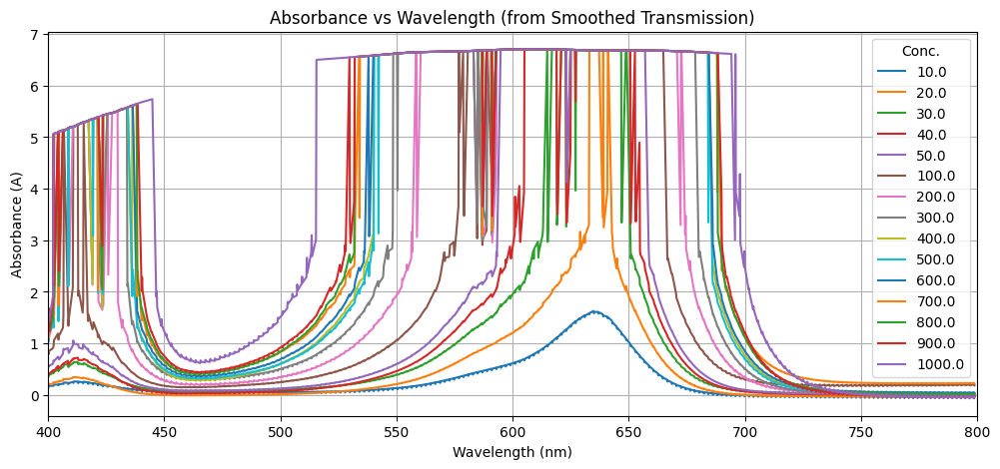

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === File Path ===
file_path = "blue concs.xlsx"  # <- update if needed
xls = pd.ExcelFile(file_path)
sheet_names = xls.sheet_names

# === Step 1: Load and Average All 6 DI Sheets ===
di_sheets = [s for s in sheet_names if s.startswith("0-")]
di_data = []

for s in di_sheets:
    df = pd.read_excel(xls, sheet_name=s, skiprows=1)
    df.columns = ["wavelength", "transmission"]
    df = df.groupby("wavelength", as_index=False).mean()
    di_data.append(df)

di_avg = pd.concat(di_data).groupby("wavelength", as_index=False).mean()
di_avg = di_avg.sort_values("wavelength")
di_avg["smoothed_T0"] = di_avg["transmission"].rolling(51, center=True).mean()

# === Step 2: Load Sample Sheets and Smooth Transmission ===
sample_data = []

for s in sheet_names:
    if not s.startswith("0-"):
        try:
            conc = float(s.split("-")[0])
        except:
            continue
        df = pd.read_excel(xls, sheet_name=s, skiprows=1)
        df.columns = ["wavelength", "transmission"]
        df = df.groupby("wavelength", as_index=False).mean()
        df = df.sort_values("wavelength")
        df["smoothed_T"] = df["transmission"].rolling(51, center=True).mean()
        df["concentration"] = conc
        sample_data.append(df)

samples_df = pd.concat(sample_data)

# === Step 3: Map DI and Calculate Absorbance ===
T0_map = dict(zip(di_avg["wavelength"], di_avg["smoothed_T0"]))
samples_df["T0"] = samples_df["wavelength"].map(T0_map)

samples_df["T0"] = samples_df["T0"].clip(lower=1e-2)
samples_df["smoothed_T"] = samples_df["smoothed_T"].clip(lower=1e-2)
samples_df["absorbance"] = -np.log10(samples_df["smoothed_T"] / samples_df["T0"])

# === Step 4: Downsample for Fast Plotting ===
samples_df = samples_df.query("400 <= wavelength <= 800")
plot_trans = samples_df.dropna(subset=["smoothed_T"])
plot_trans = plot_trans.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)

plot_abs = samples_df.dropna(subset=["absorbance"])
plot_abs = plot_abs.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)

# === Step 5: Plot Smoothed Transmission ===
plt.figure(figsize=(12, 5))
sns.lineplot(data=plot_trans, x="wavelength", y="smoothed_T", hue="concentration", palette="tab10")
plt.title("Smoothed Transmission vs Wavelength")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission (a.u.)")
plt.grid(True)
plt.xlim(400, 800)
plt.legend(title="Conc.")
plt.show()

# === Step 6: Plot Absorbance ===
plt.figure(figsize=(12, 5))
sns.lineplot(data=plot_abs, x="wavelength", y="absorbance", hue="concentration", palette="tab10")
plt.title("Absorbance vs Wavelength (from Smoothed Transmission)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance (A)")
plt.grid(True)
plt.xlim(400, 800)
plt.legend(title="Conc.")
plt.show()


<ipython-input-3-1a56b1f65104>:42: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  plot_df = plot_df.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)


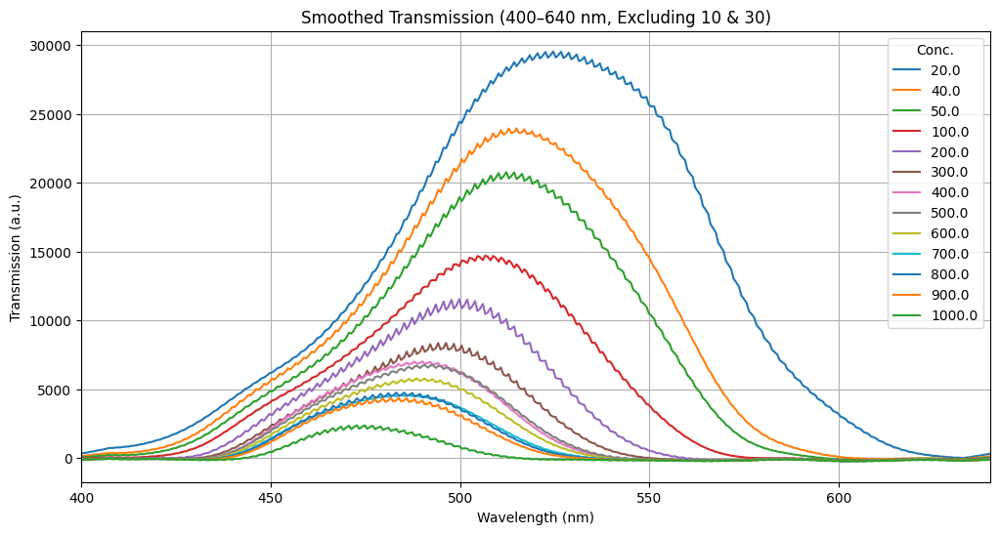

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === File path ===
file_path = "blue concs.xlsx"
xls = pd.ExcelFile(file_path)
sheet_names = xls.sheet_names

# === Load and smooth sample sheets (excluding 10 & 30) ===
sample_data = []

for s in sheet_names:
    if s.startswith("0-"):
        continue
    try:
        conc = float(s.split("-")[0])
    except:
        continue
    if conc in [10.0, 30.0]:
        continue
    df = pd.read_excel(xls, sheet_name=s, skiprows=1)
    df.columns = ["wavelength", "transmission"]
    df = df.groupby("wavelength", as_index=False).mean()
    df = df.sort_values("wavelength")
    df["smoothed_T"] = df["transmission"].rolling(51, center=True).mean()
    df["concentration"] = conc
    sample_data.append(df)

samples_df = pd.concat(sample_data)
samples_df = samples_df.query("400 <= wavelength <= 640")

# === Second-pass smoothing ===
samples_df["smoothed_T2"] = (
    samples_df.groupby("concentration")["smoothed_T"]
    .transform(lambda x: x.rolling(71, center=True).mean())
)

# === Downsample for plotting ===
plot_df = samples_df.dropna(subset=["smoothed_T2"])
plot_df = plot_df.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)

# === Plot ===
plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_df, x="wavelength", y="smoothed_T2", hue="concentration", palette="tab10")
plt.title("Smoothed Transmission (400–640 nm, Excluding 10 & 30)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission (a.u.)")
plt.grid(True)
plt.legend(title="Conc.")
plt.xlim(400, 640)
plt.show()


In [ ]:
from google.colab import files

# === Export plot data as CSV ===
export_filename = "smoothed_transmission_plot_data.csv"
plot_df.to_csv(export_filename, index=False)

# === Download the file ===
files.download(export_filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

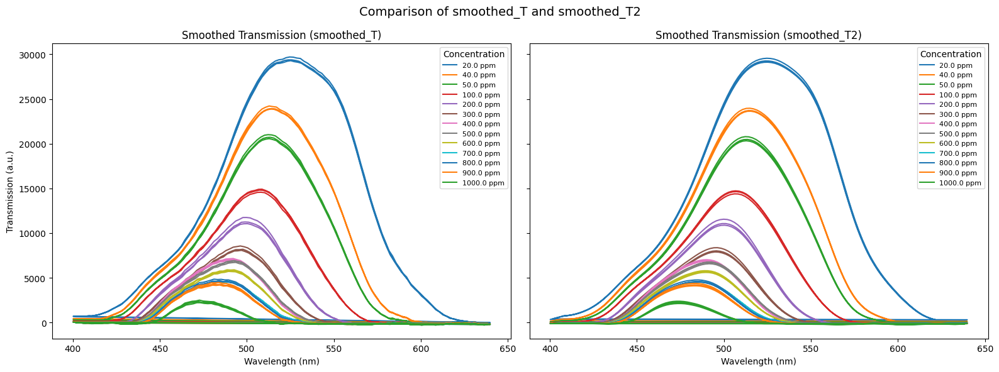

In [ ]:
import matplotlib.pyplot as plt

# Get list of concentrations
concs = plot_df["concentration"].unique()
concs = sorted(concs)

# Create subplots
fig, axs = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Plot smoothed_T on the left
for conc in concs:
    sub = plot_df[plot_df["concentration"] == conc]
    axs[0].plot(sub["wavelength"], sub["smoothed_T"], label=f"{conc} ppm")

axs[0].set_title("Smoothed Transmission (smoothed_T)")
axs[0].set_xlabel("Wavelength (nm)")
axs[0].set_ylabel("Transmission (a.u.)")
axs[0].legend(title="Concentration", fontsize=8)

# Plot smoothed_T2 on the right
for conc in concs:
    sub = plot_df[plot_df["concentration"] == conc]
    axs[1].plot(sub["wavelength"], sub["smoothed_T2"], label=f"{conc} ppm")

axs[1].set_title("Smoothed Transmission (smoothed_T2)")
axs[1].set_xlabel("Wavelength (nm)")
axs[1].legend(title="Concentration", fontsize=8)

plt.suptitle("Comparison of smoothed_T and smoothed_T2", fontsize=14)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from google.colab import files

# === Pivot the data to wide format: wavelength vs concentrations ===
pivot_df = plot_df.pivot_table(index="wavelength", columns="concentration", values="smoothed_T2")
pivot_df = pivot_df.reset_index()  # Move wavelength back to a column

# === Save to CSV ===
filename = "smoothed_T2_wide_format.csv"
pivot_df.to_csv(filename, index=False)

# === Make downloadable ===
files.download(filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

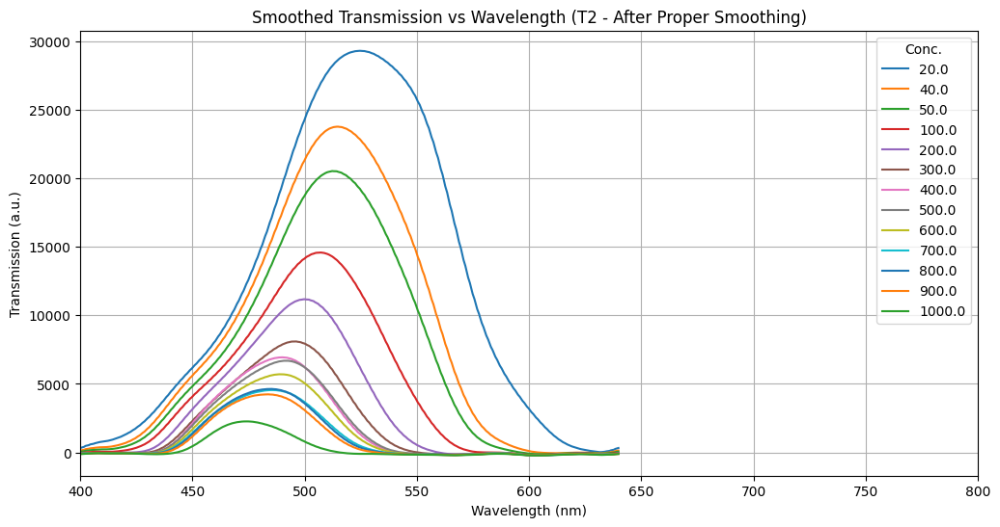

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import savgol_filter

# Load the CSV
wide_df = pd.read_csv('/content/smoothed_T2_wide_format.csv')

# Strip any spaces from column names
wide_df.columns = wide_df.columns.str.strip()

# Apply Savitzky-Golay smoothing to each concentration column
# (Skip the first column assuming it is wavelength)
for col in wide_df.columns[1:]:
    wide_df[col] = savgol_filter(wide_df[col], window_length=15, polyorder=3)  # window_length must be odd

# Melt the dataframe to long format for seaborn
melted_df = wide_df.melt(id_vars=wide_df.columns[0], var_name='concentration', value_name='smoothed_T')

# Plot
plt.figure(figsize=(12,6))
sns.lineplot(data=melted_df, x=wide_df.columns[0], y="smoothed_T", hue="concentration", palette="tab10")

plt.title("Smoothed Transmission vs Wavelength (T2 - After Proper Smoothing)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission (a.u.)")
plt.grid(True)
plt.xlim(400, 800)
plt.legend(title="Conc.")
plt.show()


In [ ]:
import pandas as pd
from google.colab import files

# Save the smoothed wide_df to a new CSV file
wide_df.to_csv('/content/smoothed_T2_PROPER.csv', index=False)

# Download the file
files.download('/content/smoothed_T2_PROPER.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Closest wavelength found: 510.164 nm


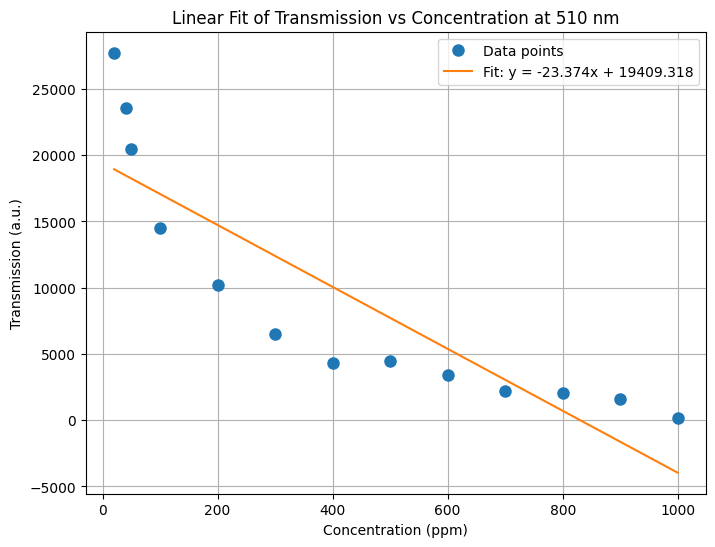

R-squared: 0.7599


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Target wavelength
target_wavelength = 510

# Find the closest wavelength index
closest_idx = (wide_df.iloc[:,0] - target_wavelength).abs().idxmin()

# Get the exact closest wavelength value
closest_wavelength = wide_df.iloc[closest_idx, 0]
print(f"Closest wavelength found: {closest_wavelength} nm")

# Extract transmission and concentrations
transmissions = wide_df.iloc[closest_idx, 1:]
concentrations = [float(c.split()[0]) if isinstance(c, str) else float(c) for c in wide_df.columns[1:]]

# Sort by concentration (just in case)
concentrations, transmissions = zip(*sorted(zip(concentrations, transmissions)))

# Convert to numpy arrays
X = np.array(concentrations).reshape(-1, 1)  # Make it 2D for sklearn
y = np.array(transmissions)

# Fit linear regression
model = LinearRegression()
model.fit(X, y)

# Predict fitted line
X_fit = np.linspace(min(concentrations), max(concentrations), 100).reshape(-1, 1)
y_fit = model.predict(X_fit)

# Plot
plt.figure(figsize=(8,6))
plt.plot(concentrations, transmissions, 'o', label="Data points", markersize=8)
plt.plot(X_fit.flatten(), y_fit, '-', label=f"Fit: y = {model.coef_[0]:.3f}x + {model.intercept_:.3f}")
plt.title(f"Linear Fit of Transmission vs Concentration at {int(closest_wavelength)} nm")
plt.xlabel("Concentration (ppm)")
plt.ylabel("Transmission (a.u.)")
plt.legend()
plt.grid(True)
plt.show()

# Print R-squared
r_squared = model.score(X, y)
print(f"R-squared: {r_squared:.4f}")


Closest wavelength found: 449.716 nm


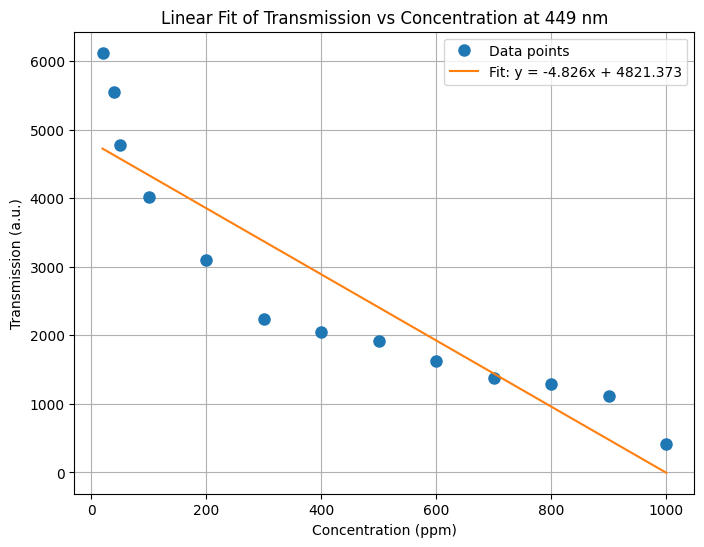

R-squared: 0.8362


In [ ]:
# prompt: give me a similar plot to the above one but at wavelength of 450 nm

# Target wavelength
target_wavelength = 450

# Find the closest wavelength index
closest_idx = (wide_df.iloc[:,0] - target_wavelength).abs().idxmin()

# Get the exact closest wavelength value
closest_wavelength = wide_df.iloc[closest_idx, 0]
print(f"Closest wavelength found: {closest_wavelength} nm")

# Extract transmission and concentrations
transmissions = wide_df.iloc[closest_idx, 1:]
concentrations = [float(c.split()[0]) if isinstance(c, str) else float(c) for c in wide_df.columns[1:]]

# Sort by concentration (just in case)
concentrations, transmissions = zip(*sorted(zip(concentrations, transmissions)))

# Convert to numpy arrays
X = np.array(concentrations).reshape(-1, 1)  # Make it 2D for sklearn
y = np.array(transmissions)

# Fit linear regression
model = LinearRegression()
model.fit(X, y)

# Predict fitted line
X_fit = np.linspace(min(concentrations), max(concentrations), 100).reshape(-1, 1)
y_fit = model.predict(X_fit)

# Plot
plt.figure(figsize=(8,6))
plt.plot(concentrations, transmissions, 'o', label="Data points", markersize=8)
plt.plot(X_fit.flatten(), y_fit, '-', label=f"Fit: y = {model.coef_[0]:.3f}x + {model.intercept_:.3f}")
plt.title(f"Linear Fit of Transmission vs Concentration at {int(closest_wavelength)} nm")
plt.xlabel("Concentration (ppm)")
plt.ylabel("Transmission (a.u.)")
plt.legend()
plt.grid(True)
plt.show()

# Print R-squared
r_squared = model.score(X, y)
print(f"R-squared: {r_squared:.4f}")


Closest wavelength found: 549.817 nm


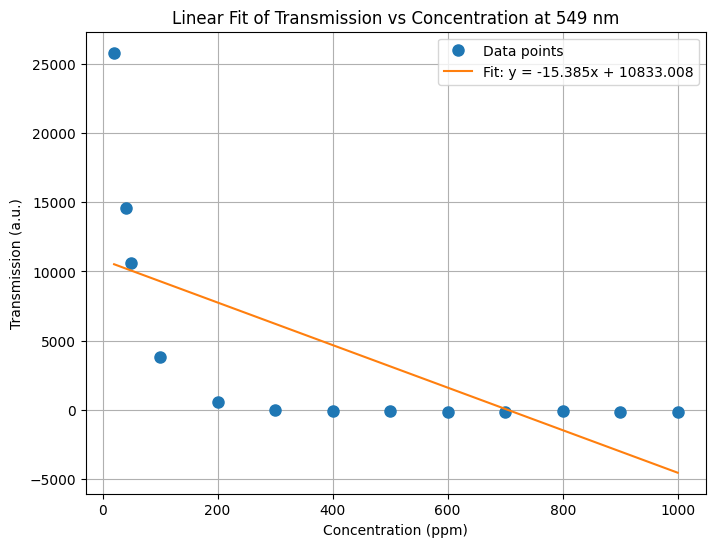

R-squared: 0.4358


In [ ]:
# prompt: now at 550 nm

# Target wavelength
target_wavelength = 550

# Find the closest wavelength index
closest_idx = (wide_df.iloc[:,0] - target_wavelength).abs().idxmin()

# Get the exact closest wavelength value
closest_wavelength = wide_df.iloc[closest_idx, 0]
print(f"Closest wavelength found: {closest_wavelength} nm")

# Extract transmission and concentrations
transmissions = wide_df.iloc[closest_idx, 1:]
concentrations = [float(c.split()[0]) if isinstance(c, str) else float(c) for c in wide_df.columns[1:]]

# Sort by concentration (just in case)
concentrations, transmissions = zip(*sorted(zip(concentrations, transmissions)))

# Convert to numpy arrays
X = np.array(concentrations).reshape(-1, 1)  # Make it 2D for sklearn
y = np.array(transmissions)

# Fit linear regression
model = LinearRegression()
model.fit(X, y)

# Predict fitted line
X_fit = np.linspace(min(concentrations), max(concentrations), 100).reshape(-1, 1)
y_fit = model.predict(X_fit)

# Plot
plt.figure(figsize=(8,6))
plt.plot(concentrations, transmissions, 'o', label="Data points", markersize=8)
plt.plot(X_fit.flatten(), y_fit, '-', label=f"Fit: y = {model.coef_[0]:.3f}x + {model.intercept_:.3f}")
plt.title(f"Linear Fit of Transmission vs Concentration at {int(closest_wavelength)} nm")
plt.xlabel("Concentration (ppm)")
plt.ylabel("Transmission (a.u.)")
plt.legend()
plt.grid(True)
plt.show()

# Print R-squared
r_squared = model.score(X, y)
print(f"R-squared: {r_squared:.4f}")


Closest wavelength found: 510.164 nm


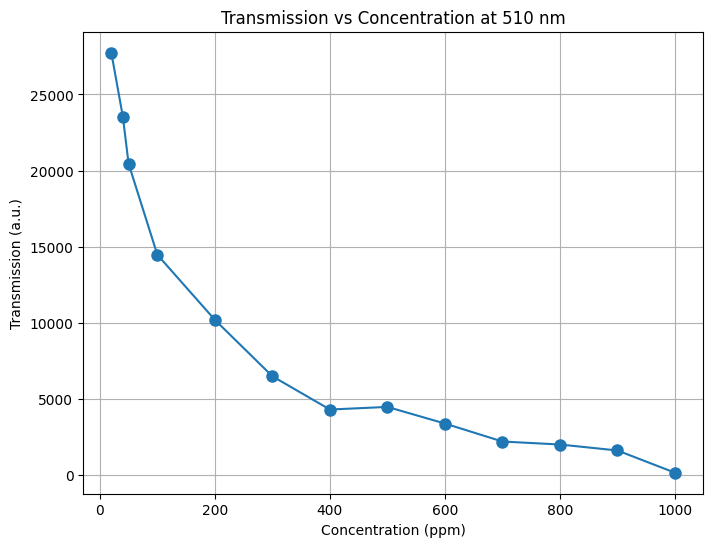

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Target wavelength
target_wavelength = 510

# Find the closest wavelength index
closest_idx = (wide_df.iloc[:,0] - target_wavelength).abs().idxmin()

# Get the exact closest wavelength value (just for info)
closest_wavelength = wide_df.iloc[closest_idx, 0]
print(f"Closest wavelength found: {closest_wavelength} nm")

# Extract transmission values at that wavelength
transmissions = wide_df.iloc[closest_idx, 1:]  # skip first column (wavelengths)

# Extract corresponding concentrations (column names)
concentrations = [float(c.split()[0]) if isinstance(c, str) else float(c) for c in wide_df.columns[1:]]

# Sort by concentration (just in case)
concentrations, transmissions = zip(*sorted(zip(concentrations, transmissions)))

# Plot
plt.figure(figsize=(8,6))
plt.plot(concentrations, transmissions, 'o-', markersize=8)
plt.title(f"Transmission vs Concentration at {int(closest_wavelength)} nm")
plt.xlabel("Concentration (ppm)")
plt.ylabel("Transmission (a.u.)")
plt.grid(True)
plt.show()


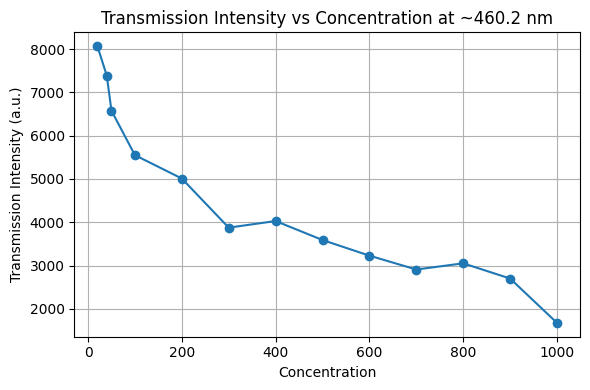

In [ ]:
# === Plot Intensity at 460 nm vs. Concentration ===

# Find the closest wavelength to 460 nm
target_wv = 460
closest_wv = min(wide_data.columns, key=lambda x: abs(x - target_wv))

# Extract intensity at closest wavelength
intensity_at_460 = wide_data[closest_wv]
concentration = wide_data.index

# Plot
plt.figure(figsize=(6, 4))
plt.plot(concentration, intensity_at_460, marker='o')
plt.title(f'Transmission Intensity vs Concentration at ~{closest_wv:.1f} nm')
plt.xlabel('Concentration')
plt.ylabel('Transmission Intensity (a.u.)')
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# === Convert to Wide Format ===
wide_data = plot_df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T").dropna(axis=1)

# === Prepare X and y ===
X = wide_data.reset_index().drop(columns=["concentration"])
y = wide_data.reset_index()["concentration"]

# === Variance Calculation ===
var_map = X.var(axis=0).to_dict()

# === Correlation Matrix ===
corr_matrix = X.corr()

# === Sort wavelengths by descending variance ===
sorted_features = sorted(var_map, key=var_map.get, reverse=True)

# === Keep decorrelated features only ===
thresh = 0.999  # correlation threshold
kept_features = []
for test_feat in sorted_features:
    if all(corr_matrix.loc[test_feat, feat] < thresh for feat in kept_features):
        kept_features.append(test_feat)

# === Output list and size ===
print(f"Selected {len(kept_features)} features")
print(kept_features)

# === Filtered Feature Matrix ===
X_filt = X[kept_features]
print("X_filt shape:", X_filt.shape)


Selected 90 features
[524.6, 518.421, 530.768, 534.874, 513.469, 538.975, 508.717, 543.071, 547.161, 503.958, 551.247, 500.436, 555.327, 495.666, 558.588, 492.137, 561.438, 564.692, 485.274, 567.537, 481.734, 570.785, 480.275, 573.625, 577.676, 464.399, 582.329, 462.934, 449.716, 450.346, 453.917, 446.141, 445.51, 442.563, 587.783, 440.456, 438.349, 436.24, 434.13, 597.856, 432.019, 429.273, 427.16, 425.045, 608.497, 422.294, 420.811, 419.329, 611.101, 416.574, 612.503, 409.571, 408.085, 406.597, 615.103, 403.833, 402.344, 615.903, 616.503, 617.102, 618.501, 619.1, 619.899, 620.498, 621.097, 621.895, 622.493, 623.092, 623.889, 625.085, 624.487, 627.077, 625.882, 626.48, 629.068, 631.058, 627.874, 639.795, 628.471, 633.046, 630.461, 638.407, 637.812, 629.864, 632.45, 631.853, 634.437, 635.827, 633.841, 636.423]
X_filt shape: (13, 90)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error, make_scorer

# === Convert to Wide Format ===
wide_data = plot_df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)

# === Prepare X and y ===
X = wide_data.reset_index().drop(columns=["concentration"])
y = wide_data.reset_index()["concentration"]

# === Variance Calculation ===
var_map = X.var(axis=0).to_dict()

# === Correlation Matrix ===
corr_matrix = X.corr()

# === Sort wavelengths by descending variance ===
sorted_features = sorted(var_map, key=var_map.get, reverse=True)

# === Keep decorrelated features only ===
thresh = 0.999  # correlation threshold
kept_features = []
for test_feat in sorted_features:
    if all(corr_matrix.loc[test_feat, feat] < thresh for feat in kept_features):
        kept_features.append(test_feat)

print(f"Selected {len(kept_features)} features (pre-filtering):")
print(kept_features)

# === Evaluate MSE with 5-fold CV for each individual feature ===
cv_results = {}
scorer = make_scorer(mean_squared_error)

for feat in kept_features:
    scores = cross_val_score(LinearRegression(), X[[feat]], y, cv=5, scoring=scorer)
    cv_results[feat] = np.mean(scores)

# === Sort by lowest CV-MSE ===
sorted_mse_feats = sorted(cv_results, key=cv_results.get)
print("\nTop features ranked by 5-fold CV MSE:")
for i, feat in enumerate(sorted_mse_feats[:10]):
    print(f"{i+1}. {feat} → MSE: {cv_results[feat]:.2f}")


Selected 78 features (pre-filtering):
[524.6, 518.421, 530.768, 534.874, 513.469, 538.975, 508.717, 543.071, 547.161, 503.958, 551.247, 500.436, 555.327, 495.666, 559.402, 492.137, 562.659, 565.505, 485.274, 568.756, 481.734, 571.597, 476.104, 575.651, 579.7, 464.399, 585.764, 452.447, 451.817, 448.244, 447.613, 444.668, 441.931, 439.192, 593.83, 436.24, 433.497, 432.019, 429.273, 427.16, 425.045, 608.497, 420.811, 419.329, 611.101, 416.574, 413.817, 614.503, 615.103, 403.833, 617.902, 402.344, 618.501, 619.1, 619.899, 620.498, 621.097, 638.407, 621.895, 637.812, 622.493, 623.092, 623.889, 636.423, 624.487, 625.085, 635.827, 625.882, 627.077, 626.48, 634.437, 629.068, 627.874, 628.471, 633.841, 631.058, 630.461, 629.864]

Top features ranked by 5-fold CV MSE:
1. 452.447 → MSE: 72182.88
2. 476.104 → MSE: 73699.58
3. 451.817 → MSE: 73816.07
4. 464.399 → MSE: 75083.49
5. 481.734 → MSE: 75955.35
6. 485.274 → MSE: 83104.78
7. 448.244 → MSE: 85457.57
8. 492.137 → MSE: 87403.11
9. 447.613 → M

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error

# === Prepare X and y from your plot_df ===
# This assumes plot_df contains: wavelength, smoothed_T2, concentration
pivot_data = plot_df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)

X = pivot_data.copy()
y = pivot_data.index.values

# === Sort by variance and apply correlation filtering ===
X_var = X.var().sort_values(ascending=False)
X_sorted = X[X_var.index]

corr_matrix = X_sorted.corr()
kept_features = []
threshold = 0.99

for test_feat in X_sorted.columns:
    if all(corr_matrix.loc[test_feat, f] < threshold for f in kept_features):
        kept_features.append(test_feat)

X_filtered = X_sorted[kept_features]

# === LOOCV + Feature Selection ===
loo = LeaveOneOut()
data_list = []
current_feats = [kept_features[0]]

for i in range(1, len(kept_features)):
    best_candidate = None
    best_mse = float('inf')

    for candidate in kept_features:
        if candidate in current_feats:
            continue
        test_feats = current_feats + [candidate]
        mse_list = []

        for train_idx, test_idx in loo.split(X_filtered):
            model = LinearRegression()
            model.fit(X_filtered.iloc[train_idx][test_feats], y[train_idx])
            y_pred = model.predict(X_filtered.iloc[test_idx][test_feats])
            mse = mean_squared_error([y[test_idx][0]], y_pred)
            mse_list.append(mse)

        candidate_mse = np.mean(mse_list)
        if candidate_mse < best_mse:
            best_mse = candidate_mse
            best_candidate = candidate

    if best_candidate is None:
        break

    current_feats.append(best_candidate)
    data_list.append({
        'n_feats': len(current_feats),
        'best_feat': best_candidate,
        'best_mse': best_mse
    })

# === Show Results ===
mse_df = pd.DataFrame(data_list)
display(mse_df)


,n_feats,best_feat,best_mse
0,2,508.717,7426.091204
1,3,627.874,6386.496490
2,4,633.046,2557.431019
3,5,538.975,2201.459246
4,6,636.423,2509.453699
5,7,583.744,2847.058656
6,8,627.077,5351.437407
7,9,485.899,15721.583495
8,10,623.092,36515.221019
9,11,551.247,772645.210642


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# === Clean column names ===
X_filt.columns = [str(c).replace('.', '_') for c in X_filt.columns]
Xy_filt = X_filt.copy(deep=True)
Xy_filt['Concentration'] = y

# === Function to compute LOOCV MSE ===
def loocv_mse(features, Xy_df):
    loo = LeaveOneOut()
    model = LinearRegression()
    X_vals = Xy_df[features].values
    y_vals = Xy_df["Concentration"].values

    mses = []
    for train_idx, test_idx in loo.split(X_vals):
        model.fit(X_vals[train_idx], y_vals[train_idx])
        pred = model.predict(X_vals[test_idx])
        mse = mean_squared_error([y_vals[test_idx][0]], pred)
        mses.append(mse)
    return np.mean(mses)

# === Stepwise Feature Selection ===
data_list = []

# Step 1: Find best single feature
mse_map = {col: loocv_mse([col], Xy_filt) for col in X_filt.columns}
best_first_feat = min(mse_map, key=mse_map.get)
best_mse = mse_map[best_first_feat]

kept_features_iter = [best_first_feat]
data_list.append({'n_feats': 1, 'best_feat': best_first_feat, 'best_mse': best_mse})

# Step 2: Add features one by one that improve LOOCV MSE
for _ in range(2, len(X_filt.columns) + 1):
    best_candidate = None
    best_candidate_mse = best_mse

    for feat in X_filt.columns:
        if feat in kept_features_iter:
            continue
        temp_feats = kept_features_iter + [feat]
        temp_mse = loocv_mse(temp_feats, Xy_filt)
        if temp_mse < best_candidate_mse:
            best_candidate = feat
            best_candidate_mse = temp_mse

    if best_candidate is None:
        break

    kept_features_iter.append(best_candidate)
    data_list.append({
        'n_feats': len(kept_features_iter),
        'best_feat': best_candidate,
        'best_mse': best_candidate_mse
    })
    print(f"{len(kept_features_iter)} features -> added {best_candidate}, LOOCV MSE: {best_candidate_mse:.4f}")

# === Final DataFrame ===
mse_df = pd.DataFrame(data_list)
mse_df.head()


2 features -> added 514_295, LOOCV MSE: 20438.0086
3 features -> added 509_337, LOOCV MSE: 10745.8924
4 features -> added 474_852, LOOCV MSE: 9525.8897
5 features -> added 450_346, LOOCV MSE: 9821.1911
6 features -> added 480_275, LOOCV MSE: 12215.8555
7 features -> added 485_899, LOOCV MSE: 13469.0290
8 features -> added 473_39, LOOCV MSE: 19396.8594


,n_feats,best_feat,best_mse
0,1,454_547,22726.565156
1,2,514_295,20438.008572
2,3,509_337,10745.892366
3,4,474_852,9525.889652
4,5,450_346,9821.191094


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error

# === Make sure column names are Patsy-compatible ===
X_filt.columns = [str(c).replace('.', '_') for c in X_filt.columns]

# === Prepare design matrix ===
Xy_filt = X_filt.copy()
Xy_filt['Concentration'] = y.values

# === Leave-One-Out Feature Selection (Linear Regression) ===
def determine_best_feature(current_feats, df):
    base_formula = 'Concentration ~ ' + ' + '.join(current_feats)
    base_model = smf.ols(formula=base_formula, data=df).fit()
    base_mse = mean_squared_error(df['Concentration'], base_model.fittedvalues)

    best_feat = None
    best_mse = base_mse

    for candidate in df.columns.drop(['Concentration'] + current_feats):
        formula = base_formula + f' + {candidate}'
        model = smf.ols(formula=formula, data=df).fit()
        mse = mean_squared_error(df['Concentration'], model.fittedvalues)
        if mse < best_mse:
            best_mse = mse
            best_feat = candidate

    return best_feat, best_mse

# === Initialize ===
kept_features_iter = [X_filt.columns[0]]
data_list = []

formula = f'Concentration ~ {kept_features_iter[0]}'
model = smf.ols(formula=formula, data=Xy_filt).fit()
data_list.append({
    "n_feats": 1,
    "best_feat": kept_features_iter[0],
    "best_mse": mean_squared_error(Xy_filt['Concentration'], model.fittedvalues)
})

# === Iteratively add features ===
for _ in range(2, len(X_filt.columns)):
    best_feat, best_mse = determine_best_feature(kept_features_iter, Xy_filt)
    if best_feat is None:
        break
    kept_features_iter.append(best_feat)
    data_list.append({
        "n_feats": len(kept_features_iter),
        "best_feat": best_feat,
        "best_mse": best_mse
    })
    print(f"{len(kept_features_iter)} features -> added {best_feat}, MSE: {best_mse:.4f}")

# === Results ===
mse_df = pd.DataFrame(data_list)
display(mse_df)


AttributeError: 'numpy.ndarray' object has no attribute 'values'

<ipython-input-41-e4608fd0eb9e>:44: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  plot_df = plot_df.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)


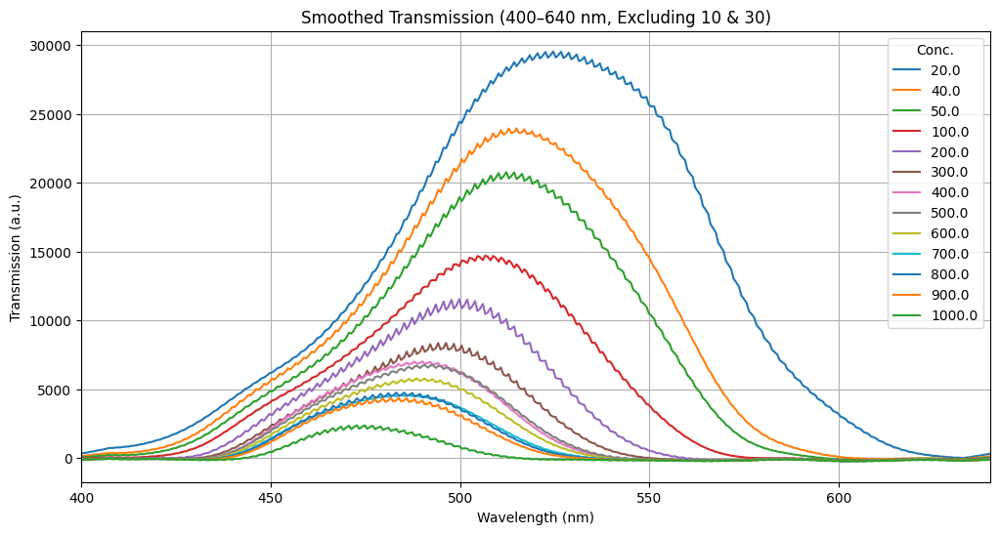

In [ ]:
# === Import Required Libraries ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === Load Excel File ===
file_path = "blue concs.xlsx"  # update if needed
xls = pd.ExcelFile(file_path)
sheet_names = xls.sheet_names

# === Load and Process Sheets (Excluding 10 & 30) ===
sample_data = []

for s in sheet_names:
    if s.startswith("0-"):
        continue
    try:
        conc = float(s.split("-")[0])
    except:
        continue
    if conc in [10.0, 30.0]:
        continue

    df = pd.read_excel(xls, sheet_name=s, skiprows=1)
    df.columns = ["wavelength", "transmission"]
    df = df.groupby("wavelength", as_index=False).mean().sort_values("wavelength")
    df["smoothed_T"] = df["transmission"].rolling(51, center=True).mean()
    df["concentration"] = conc
    sample_data.append(df)

# === Concatenate and Clip to 400–640 nm Range ===
samples_df = pd.concat(sample_data)
samples_df = samples_df.query("400 <= wavelength <= 640")

# === Second-Pass Smoothing (Across Concentration Groups) ===
samples_df["smoothed_T2"] = (
    samples_df.groupby("concentration")["smoothed_T"]
    .transform(lambda x: x.rolling(71, center=True).mean())
)

# === Downsample for Plotting ===
plot_df = samples_df.dropna(subset=["smoothed_T2"])
plot_df = plot_df.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)

# === Plotting ===
plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_df, x="wavelength", y="smoothed_T2", hue="concentration", palette="tab10")
plt.title("Smoothed Transmission (400–640 nm, Excluding 10 & 30)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission (a.u.)")
plt.grid(True)
plt.legend(title="Conc.")
plt.xlim(400, 640)
plt.show()

# === Save the processed data (optional, for later ML analysis) ===
plot_df.to_csv("processed_smoothed_transmission.csv", index=False)


<ipython-input-2-9319521f7031>:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  plot_df = plot_df.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)


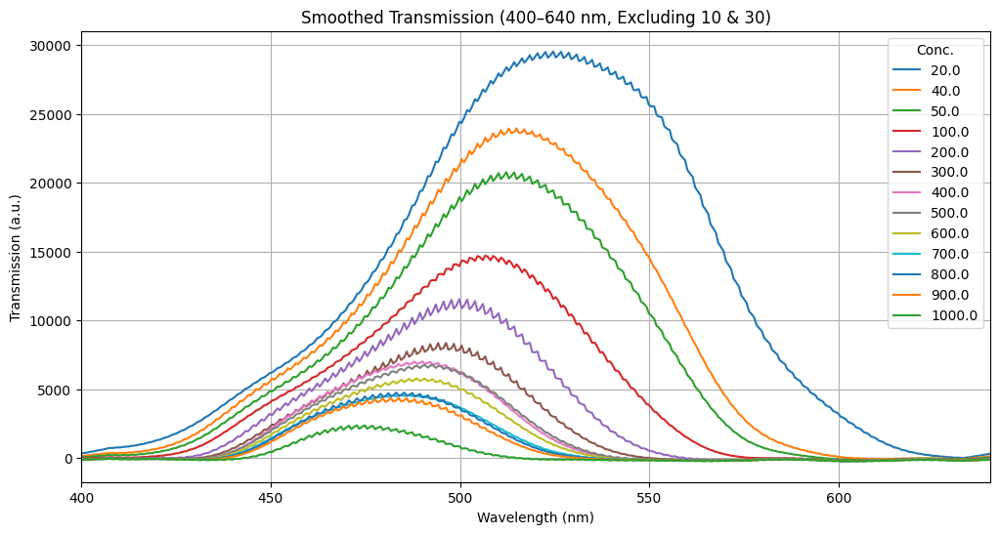

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === File path ===
file_path = "blue concs.xlsx"
xls = pd.ExcelFile(file_path)
sheet_names = xls.sheet_names

# === Load and smooth sample sheets (excluding 10 & 30) ===
sample_data = []
for s in sheet_names:
    if s.startswith("0-"):
        continue
    try:
        conc = float(s.split("-")[0])
    except:
        continue
    if conc in [10.0, 30.0]:
        continue
    df = pd.read_excel(xls, sheet_name=s, skiprows=1)
    df.columns = ["wavelength", "transmission"]
    df = df.groupby("wavelength", as_index=False).mean()
    df = df.sort_values("wavelength")
    df["smoothed_T"] = df["transmission"].rolling(51, center=True).mean()
    df["concentration"] = conc
    sample_data.append(df)

samples_df = pd.concat(sample_data)
samples_df = samples_df.query("400 <= wavelength <= 640")

# === Second-pass smoothing ===
samples_df["smoothed_T2"] = (
    samples_df.groupby("concentration")["smoothed_T"]
    .transform(lambda x: x.rolling(71, center=True).mean())
)

# === Downsample for plotting ===
plot_df = samples_df.dropna(subset=["smoothed_T2"])
plot_df = plot_df.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)

# === Plot ===
plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_df, x="wavelength", y="smoothed_T2", hue="concentration", palette="tab10")
plt.title("Smoothed Transmission (400–640 nm, Excluding 10 & 30)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission (a.u.)")
plt.grid(True)
plt.legend(title="Conc.")
plt.xlim(400, 640)
plt.show()

# === Save smoothed data ===
plot_df.to_csv("processed_smoothed_transmission.csv", index=False)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# === Pivot the smoothed data into wide format ===
wide_data = plot_df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
X_all = wide_data.copy()
y_all = X_all.index.values  # concentrations
X_all.reset_index(drop=True, inplace=True)

# === Fit Linear Regression for Each Wavelength ===
mse_map = {}

for col in X_all.columns:
    X_col = X_all[[col]].values  # reshape to 2D
    model = LinearRegression().fit(X_col, y_all)
    y_pred = model.predict(X_col)
    mse = mean_squared_error(y_all, y_pred)
    mse_map[col] = mse

# === Sort and Display Top 10 Wavelengths with Lowest MSE ===
sorted_mse = sorted(mse_map.items(), key=lambda x: x[1])
top10 = sorted_mse[:10]

print("Top 10 Wavelengths by Lowest MSE (Single Feature Linear Fit):\n")
for i, (wl, mse) in enumerate(top10, 1):
    print(f"{i}. Wavelength: {wl:.2f} nm — MSE: {mse:.4f}")


Top 10 Wavelengths by Lowest MSE (Single Feature Linear Fit):

1. Wavelength: 456.64 nm — MSE: 15796.3641
2. Wavelength: 458.74 nm — MSE: 15834.4216
3. Wavelength: 457.27 nm — MSE: 15843.5679
4. Wavelength: 459.37 nm — MSE: 15905.2635
5. Wavelength: 460.84 nm — MSE: 15977.1570
6. Wavelength: 455.18 nm — MSE: 15981.5376
7. Wavelength: 454.55 nm — MSE: 15987.0663
8. Wavelength: 477.56 nm — MSE: 16005.4441
9. Wavelength: 479.65 nm — MSE: 16021.9409
10. Wavelength: 475.48 nm — MSE: 16038.7194


<ipython-input-43-9319521f7031>:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  plot_df = plot_df.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)


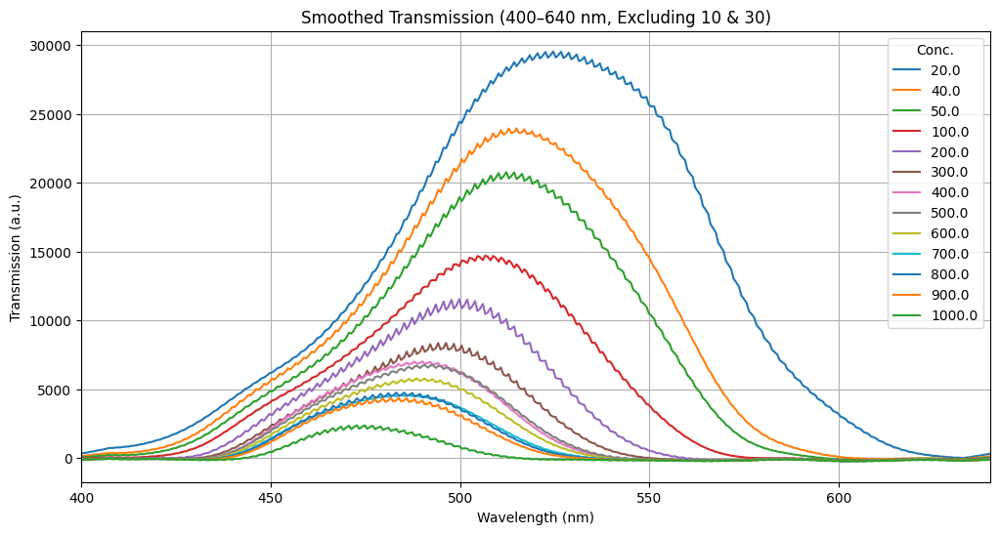

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === File path ===
file_path = "blue concs.xlsx"
xls = pd.ExcelFile(file_path)
sheet_names = xls.sheet_names

# === Load and smooth sample sheets (excluding 10 & 30) ===
sample_data = []
for s in sheet_names:
    if s.startswith("0-"):
        continue
    try:
        conc = float(s.split("-")[0])
    except:
        continue
    if conc in [10.0, 30.0]:
        continue
    df = pd.read_excel(xls, sheet_name=s, skiprows=1)
    df.columns = ["wavelength", "transmission"]
    df = df.groupby("wavelength", as_index=False).mean()
    df = df.sort_values("wavelength")
    df["smoothed_T"] = df["transmission"].rolling(51, center=True).mean()
    df["concentration"] = conc
    sample_data.append(df)

samples_df = pd.concat(sample_data)
samples_df = samples_df.query("400 <= wavelength <= 640")

# === Second-pass smoothing ===
samples_df["smoothed_T2"] = (
    samples_df.groupby("concentration")["smoothed_T"]
    .transform(lambda x: x.rolling(71, center=True).mean())
)

# === Downsample for plotting ===
plot_df = samples_df.dropna(subset=["smoothed_T2"])
plot_df = plot_df.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)

# === Plot ===
plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_df, x="wavelength", y="smoothed_T2", hue="concentration", palette="tab10")
plt.title("Smoothed Transmission (400–640 nm, Excluding 10 & 30)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission (a.u.)")
plt.grid(True)
plt.legend(title="Conc.")
plt.xlim(400, 640)
plt.show()

# === Save smoothed data ===
plot_df.to_csv("processed_smoothed_transmission.csv", index=False)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()  # make sure concentrations are sorted

X_all = wide_df.copy()
y_all = X_all.index.values  # concentrations
X_all.reset_index(drop=True, inplace=True)

# === Perform LOOCV MSE for each wavelength (feature) ===
loo = LeaveOneOut()
mse_scores = {}

for col in X_all.columns:
    X_col = X_all[[col]].values
    y_true = []
    y_pred = []
    for train_idx, test_idx in loo.split(X_col):
        X_train, X_test = X_col[train_idx], X_col[test_idx]
        y_train, y_test = y_all[train_idx], y_all[test_idx]
        model = LinearRegression()
        model.fit(X_train, y_train)
        y_true.append(y_test[0])
        y_pred.append(model.predict(X_test)[0])
    mse = mean_squared_error(y_true, y_pred)
    mse_scores[col] = mse

# === Get top 10 features with lowest LOOCV MSE ===
sorted_mse = sorted(mse_scores.items(), key=lambda x: x[1])
top_10 = pd.DataFrame(sorted_mse[:10], columns=["wavelength", "LOOCV_MSE"])

# === Display result ===
print("Top 10 wavelengths with lowest LOOCV MSE:")
print(top_10)


Top 10 wavelengths with lowest LOOCV MSE:
   wavelength     LOOCV_MSE
0     456.645  23385.043137
1     458.743  23505.454771
2     454.547  23619.531960
3     460.839  23779.757028
4     457.275  23820.510233
5     477.565  23831.597551
6     479.650  23853.819292
7     475.478  23887.225371
8     481.734  23950.267321
9     459.372  23960.733523


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# === Load processed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format (wavelengths as columns, concentration as rows) ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Leave-One-Out CV helper ===
def loocv_mse(X_sel, y):
    loo = LeaveOneOut()
    y_true, y_pred = [], []
    for train_idx, test_idx in loo.split(X_sel):
        model = LinearRegression()
        model.fit(X_sel[train_idx], y[train_idx])
        y_pred.append(model.predict(X_sel[test_idx])[0])
        y_true.append(y[test_idx][0])
    return mean_squared_error(y_true, y_pred)

# === Greedy forward selection ===
remaining = list(X.columns)
selected = []
data_list = []

# Step 1: find best single feature
best_mse = float("inf")
for col in remaining:
    mse = loocv_mse(X[[col]].values, y)
    if mse < best_mse:
        best_mse = mse
        best_feat = col
selected.append(best_feat)
remaining.remove(best_feat)
data_list.append({"n_feats": 1, "features": [best_feat], "mse": best_mse})
print(f"Step 1: {best_feat} -> MSE: {best_mse:.2f}")

# Step 2+: add one feature at a time
for i in range(2, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None
    for candidate in remaining:
        test_features = selected + [candidate]
        mse = loocv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate
    if best_mse_this_round < best_mse:
        selected.append(best_candidate)
        remaining.remove(best_candidate)
        best_mse = best_mse_this_round
        data_list.append({"n_feats": len(selected), "features": selected.copy(), "mse": best_mse})
        print(f"Step {len(selected)}: added {best_candidate} -> MSE: {best_mse:.2f}")
    else:
        print("No further improvement. Stopping.")
        break

# === Final results ===
results_df = pd.DataFrame(data_list)
print("\nFinal selected features and MSE:")
print(results_df)


Step 1: 456.645 -> MSE: 23385.04
Step 2: added 429.273 -> MSE: 9764.28
Step 3: added 490.682 -> MSE: 7955.96
No further improvement. Stopping.

Final selected features and MSE:
   n_feats                     features           mse
0        1                    [456.645]  23385.043137
1        2           [456.645, 429.273]   9764.284635
2        3  [456.645, 429.273, 490.682]   7955.957849


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === LOOCV MSE function ===
def loocv_mse(X_sel, y):
    loo = LeaveOneOut()
    y_true, y_pred = [], []
    for train_idx, test_idx in loo.split(X_sel):
        model = LinearRegression()
        model.fit(X_sel[train_idx], y[train_idx])
        y_pred.append(model.predict(X_sel[test_idx])[0])
        y_true.append(y[test_idx][0])
    return mean_squared_error(y_true, y_pred)

# === Greedy feature selection with relaxed stopping condition ===
remaining = list(X.columns)
selected = []
data_list = []

# Initial step: best single feature
best_mse = float("inf")
for col in remaining:
    mse = loocv_mse(X[[col]].values, y)
    if mse < best_mse:
        best_mse = mse
        best_feat = col
selected.append(best_feat)
remaining.remove(best_feat)
data_list.append({"n_feats": 1, "features": [best_feat], "mse": best_mse})
print(f"Step 1: {best_feat:.3f} -> MSE: {best_mse:.2f}")

# Continue adding features
min_improvement = 1e-3  # minimal MSE delta required
for i in range(2, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None
    for candidate in remaining:
        test_features = selected + [candidate]
        mse = loocv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate
    if (best_mse - best_mse_this_round) > min_improvement:
        selected.append(best_candidate)
        remaining.remove(best_candidate)
        best_mse = best_mse_this_round
        data_list.append({"n_feats": len(selected), "features": selected.copy(), "mse": best_mse})
        print(f"Step {len(selected)}: added {best_candidate:.3f} -> MSE: {best_mse:.2f}")
    else:
        print("No further improvement. Stopping.")
        break

# === Final DataFrame ===
results_df = pd.DataFrame(data_list)
print("\nFinal selected features and MSE:")
print(results_df)


Step 1: 456.645 -> MSE: 23385.04
Step 2: added 429.273 -> MSE: 9764.28
Step 3: added 490.682 -> MSE: 7955.96
No further improvement. Stopping.

Final selected features and MSE:
   n_feats                     features           mse
0        1                    [456.645]  23385.043137
1        2           [456.645, 429.273]   9764.284635
2        3  [456.645, 429.273, 490.682]   7955.957849


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === LOOCV MSE Function ===
def loocv_mse(X_sel, y):
    loo = LeaveOneOut()
    y_true, y_pred = [], []
    for train_idx, test_idx in loo.split(X_sel):
        model = LinearRegression()
        model.fit(X_sel[train_idx], y[train_idx])
        y_pred.append(model.predict(X_sel[test_idx])[0])
        y_true.append(y[test_idx][0])
    return mean_squared_error(y_true, y_pred)

# === Greedy Search without Early Stop ===
remaining = list(X.columns)
selected = []
data_list = []

best_mse = float("inf")
min_improvement = 1e-3

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = loocv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    if (best_mse - best_mse_this_round) > min_improvement:
        selected.append(best_candidate)
        remaining.remove(best_candidate)
        best_mse = best_mse_this_round
        data_list.append({
            "n_feats": len(selected),
            "features": selected.copy(),
            "mse": best_mse
        })
        print(f"Step {len(selected)}: added {best_candidate:.3f} -> MSE: {best_mse:.2f}")
    else:
        # no real improvement, but continue to explore full greedy path
        remaining.remove(best_candidate)

# === Final DataFrame ===
results_df = pd.DataFrame(data_list)
print("\nFinal selected features and MSE:")
print(results_df)


Step 1: added 456.645 -> MSE: 23385.04
Step 2: added 429.273 -> MSE: 9764.28
Step 3: added 490.682 -> MSE: 7955.96


KeyboardInterrupt: 

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# === 5-Fold CV MSE Function ===
def kfold_cv_mse(X_vals, y_vals, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Feature Selection Loop ===
min_improvement = 1e-3
X = X_filt.copy()
X.columns = [str(c).replace(".", "_") for c in X.columns]
y = y.values

selected = []
remaining = list(X.columns)
data_list = []

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if len(data_list) == 0 or (data_list[-1]["mse"] - best_mse_this_round) > min_improvement:
        selected.append(best_candidate)
        remaining.remove(best_candidate)
        data_list.append({
            "n_feats": len(selected),
            "features": selected.copy(),
            "mse": best_mse_this_round
        })
        print(f"Step {len(selected)}: added {best_candidate} -> 5-fold MSE: {best_mse_this_round:.2f}")
    else:
        print("No further improvement. Stopping.")
        break

# === Final Output ===
results_df = pd.DataFrame(data_list)
print("\nFinal selected features and 5-fold MSE:")
print(results_df)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# === 5-Fold CV MSE Function ===
def kfold_cv_mse(X_vals, y_vals, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Feature Selection Loop ===
min_improvement = 1e-3
X = X_filt.copy()
X.columns = [str(c).replace(".", "_") for c in X.columns]
y = y.values

selected = []
remaining = list(X.columns)
data_list = []

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if len(data_list) == 0 or (data_list[-1]["mse"] - best_mse_this_round) > min_improvement:
        selected.append(best_candidate)
        remaining.remove(best_candidate)
        data_list.append({
            "n_feats": len(selected),
            "features": selected.copy(),
            "mse": best_mse_this_round
        })
        print(f"Step {len(selected)}: added {best_candidate} -> 5-fold MSE: {best_mse_this_round:.2f}")
    else:
        print("No further improvement. Stopping.")
        break

# === Final Output ===
results_df = pd.DataFrame(data_list)
print("\nFinal selected features and 5-fold MSE:")
print(results_df)


AttributeError: 'numpy.ndarray' object has no attribute 'values'

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

X = wide_df.copy()
y = X.index.values  # No .values needed on numpy
X.reset_index(drop=True, inplace=True)

# === K-Fold CV Function ===
def kfold_cv_mse(X_vals, y_vals, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Feature Selection Loop ===
min_improvement = 1e-3
X.columns = [str(c).replace(".", "_") for c in X.columns]
selected = []
remaining = list(X.columns)
data_list = []
best_mse = float("inf")

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if len(data_list) == 0 or (data_list[-1]["mse"] - best_mse_this_round) > min_improvement:
        selected.append(best_candidate)
        remaining.remove(best_candidate)
        best_mse = best_mse_this_round
        data_list.append({
            "n_feats": len(selected),
            "features": selected.copy(),
            "mse": best_mse
        })
        print(f"Step {len(selected)}: added {best_candidate} -> 5-fold MSE: {best_mse:.2f}")
    else:
        print("No further improvement. Stopping.")
        break

# === Final Output ===
results_df = pd.DataFrame(data_list)
print("\nFinal selected features and 5-fold MSE:")
print(results_df)


Step 1: added 456_645 -> 5-fold MSE: 20201.87
Step 2: added 633_046 -> 5-fold MSE: 9562.92
Step 3: added 496_289 -> 5-fold MSE: 8263.74
Step 4: added 617_902 -> 5-fold MSE: 7871.34
Step 5: added 433_497 -> 5-fold MSE: 1316.12
No further improvement. Stopping.

Final selected features and 5-fold MSE:
   n_feats                                       features           mse
0        1                                      [456_645]  20201.873704
1        2                             [456_645, 633_046]   9562.916749
2        3                    [456_645, 633_046, 496_289]   8263.739590
3        4           [456_645, 633_046, 496_289, 617_902]   7871.341102
4        5  [456_645, 633_046, 496_289, 617_902, 433_497]   1316.117617


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)
X.columns = [str(c).replace(".", "_") for c in X.columns]

# === K-Fold CV Function ===
def kfold_cv_mse(X_vals, y_vals, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy Search Without Early Stop ===
remaining = list(X.columns)
selected = []
data_list = []
best_mse = float("inf")
best_features = []

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse_this_round
    })

    if best_mse_this_round < best_mse:
        best_mse = best_mse_this_round
        best_features = selected.copy()

    print(f"Step {len(selected)}: added {best_candidate} -> 5-fold MSE: {best_mse_this_round:.2f}")

# === Final Output ===
results_df = pd.DataFrame(data_list)
print("\nFinal selected features and 5-fold MSE:")
print(results_df)

print(f"\nBest feature count = {len(best_features)}, MSE = {best_mse:.2f}")
print("Best features:", best_features)


Step 1: added 456_645 -> 5-fold MSE: 20201.87
Step 2: added 633_046 -> 5-fold MSE: 9562.92
Step 3: added 496_289 -> 5-fold MSE: 8263.74
Step 4: added 617_902 -> 5-fold MSE: 7871.34
Step 5: added 433_497 -> 5-fold MSE: 1316.12
Step 6: added 453_917 -> 5-fold MSE: 2058.21
Step 7: added 499_815 -> 5-fold MSE: 2102.65
Step 8: added 471_928 -> 5-fold MSE: 1600.96
Step 9: added 620_498 -> 5-fold MSE: 26471.65
Step 10: added 634_437 -> 5-fold MSE: 15890.08
Step 11: added 635_827 -> 5-fold MSE: 6507.48
Step 12: added 474_017 -> 5-fold MSE: 4009.79
Step 13: added 622_493 -> 5-fold MSE: 3663.49
Step 14: added 624_487 -> 5-fold MSE: 3526.48
Step 15: added 615_903 -> 5-fold MSE: 3419.46
Step 16: added 626_48 -> 5-fold MSE: 3467.45
Step 17: added 619_899 -> 5-fold MSE: 3395.27
Step 18: added 628_471 -> 5-fold MSE: 3455.73
Step 19: added 632_45 -> 5-fold MSE: 3508.28
Step 20: added 630_461 -> 5-fold MSE: 3698.61
Step 21: added 621_895 -> 5-fold MSE: 4203.21


KeyboardInterrupt: 

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# === Load processed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)
X.columns = [str(c).replace(".", "_") for c in X.columns]

# === Greedy Forward Selection without CV ===
remaining = list(X.columns)
selected = []
data_list = []
best_mse = float("inf")
best_features = []

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        model = LinearRegression().fit(X[test_features].values, y)
        y_pred = model.predict(X[test_features].values)
        mse = mean_squared_error(y, y_pred)

        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse_this_round
    })

    if best_mse_this_round < best_mse:
        best_mse = best_mse_this_round
        best_features = selected.copy()

    print(f"Step {len(selected)}: added {best_candidate} -> MSE: {best_mse_this_round:.2f}")

# === Final Output ===
results_df = pd.DataFrame(data_list)
print("\nFinal selected features and MSE (no CV):")
print(results_df)

print(f"\nBest feature count = {len(best_features)}, MSE = {best_mse:.2f}")
print("Best features:", best_features)


Step 1: added 456_645 -> MSE: 15796.36
Step 2: added 427_16 -> MSE: 4594.70
Step 3: added 635_827 -> MSE: 3556.56
Step 4: added 404_471 -> MSE: 1219.53
Step 5: added 481_734 -> MSE: 584.02
Step 6: added 538_155 -> MSE: 387.73
Step 7: added 629_068 -> MSE: 298.13
Step 8: added 434_974 -> MSE: 66.97
Step 9: added 464_399 -> MSE: 7.83
Step 10: added 618_501 -> MSE: 0.18
Step 11: added 494_836 -> MSE: 0.00
Step 12: added 462_305 -> MSE: 0.00
Step 13: added 492_137 -> MSE: 0.00
Step 14: added 631_853 -> MSE: 0.00
Step 15: added 571_597 -> MSE: 0.00
Step 16: added 639_795 -> MSE: 0.00
Step 17: added 460_839 -> MSE: 0.00
Step 18: added 415_938 -> MSE: 0.00


KeyboardInterrupt: 

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)
X.columns = [str(c).replace(".", "_") for c in X.columns]

# === K-Fold CV Function with 10 folds ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy Feature Selection (No Early Stop) ===
remaining = list(X.columns)
selected = []
data_list = []
best_mse = float("inf")
best_features = []

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse_this_round
    })

    if best_mse_this_round < best_mse:
        best_mse = best_mse_this_round
        best_features = selected.copy()

    print(f"Step {len(selected)}: added {best_candidate} -> 10-fold MSE: {best_mse_this_round:.2f}")

# === Final Output ===
results_df = pd.DataFrame(data_list)
print("\nFinal selected features and 10-fold CV MSE:")
print(results_df)

print(f"\nBest feature count = {len(best_features)}, MSE = {best_mse:.2f}")
print("Best features:", best_features)


FileNotFoundError: [Errno 2] No such file or directory: 'processed_smoothed_transmission.csv'

In [ ]:
from sklearn.metrics import mean_squared_error

# Use first feature only
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X[[first_feature]], y)
y_pred = model.predict(X[[first_feature]])
print("MSE:", mean_squared_error(y, y_pred))
print("Max absolute error:", max(abs(y - y_pred)))


NameError: name 'first_feature' is not defined

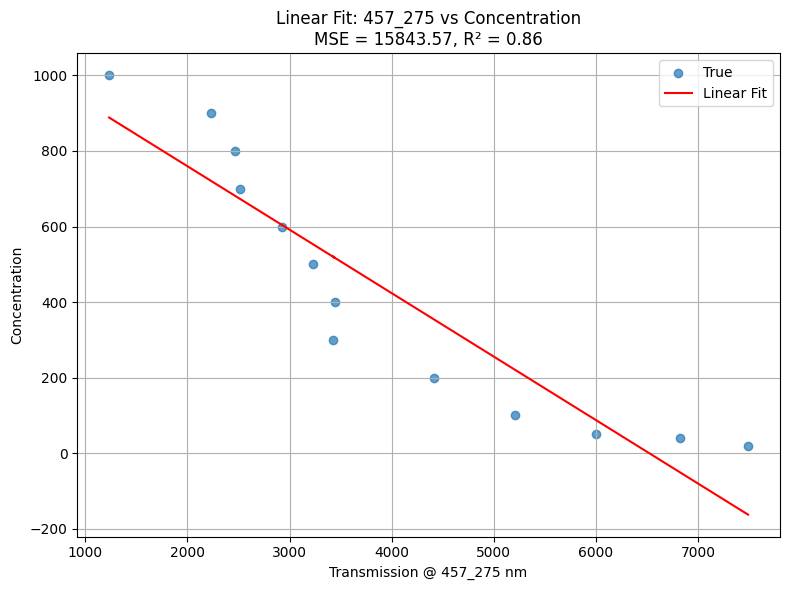

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# === Extract best first feature ===
first_feat = best_features[0]

# === Prepare X and y ===
X_1d = X[[first_feat]]
y_true = y

# === Fit Linear Regression ===
model_1d = LinearRegression()
model_1d.fit(X_1d, y_true)
y_pred_1d = model_1d.predict(X_1d)

# === Compute Metrics ===
mse_1d = mean_squared_error(y_true, y_pred_1d)
r2_1d = r2_score(y_true, y_pred_1d)

# === Plot ===
plt.figure(figsize=(8, 6))
plt.scatter(X_1d, y_true, label='True', alpha=0.7)
plt.plot(X_1d, y_pred_1d, color='red', label='Linear Fit')
plt.xlabel(f"Transmission @ {first_feat} nm")
plt.ylabel("Concentration")
plt.title(f"Linear Fit: {first_feat} vs Concentration\nMSE = {mse_1d:.2f}, R² = {r2_1d:.2f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


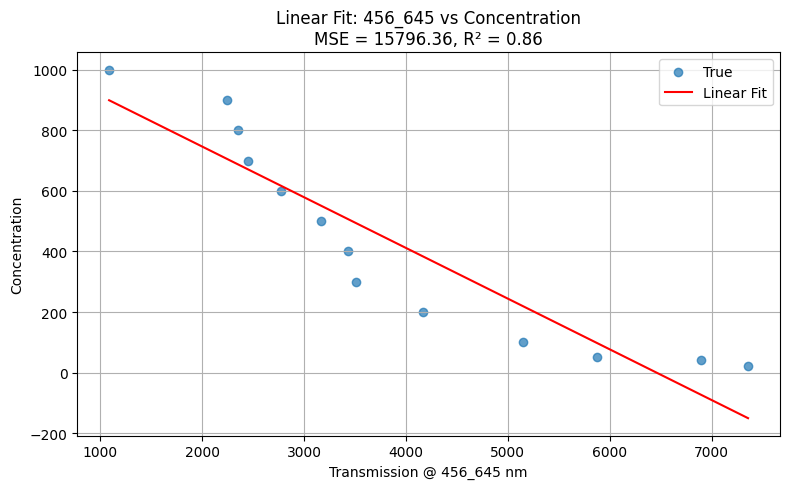

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# === Select the best single feature based on prior feature selection ===
best_feature = results_df.iloc[0]["features"][0]  # use first selected feature
X_1d = X[[best_feature]]  # Feature matrix (1D)
y_true = y  # Concentration

# === Fit Linear Model ===
model_1d = LinearRegression()
model_1d.fit(X_1d, y_true)
y_pred_1d = model_1d.predict(X_1d)

# === Calculate MSE and R² ===
mse_1d = mean_squared_error(y_true, y_pred_1d)
r2_1d = r2_score(y_true, y_pred_1d)

# === Plot Fit ===
plt.figure(figsize=(8, 5))
plt.scatter(X_1d, y_true, label="True", alpha=0.7)
plt.plot(X_1d, y_pred_1d, color='red', label="Linear Fit")

plt.title(f"Linear Fit: {best_feature} vs Concentration\nMSE = {mse_1d:.2f}, R² = {r2_1d:.2f}")
plt.xlabel(f"Transmission @ {best_feature} nm")
plt.ylabel("Concentration")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Assume df is your DataFrame from processed_smoothed_transmission.csv
best_feat = '457_275'  # or whichever is your top feature
x = df[best_feat].values.reshape(-1, 1)  # Transmission
y = df['concentration'].values  # Target is concentration

# Fit linear regression
model = LinearRegression().fit(x, y)
y_pred = model.predict(x)

# Metrics
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, label="True", alpha=0.7)
plt.plot(x, y_pred, color='red', label="Linear Fit")
plt.xlabel(f"Transmission @ {best_feat} nm")
plt.ylabel("Concentration")
plt.title(f"Linear Fit: {best_feat} vs Concentration\nMSE = {mse:.2f}, R² = {r2:.2f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


KeyError: '457_275'

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# === Set your best feature's wavelength (short version only) ===
target_wv = '457_275'

# === Find the full column name that includes this wavelength ===
best_feat = [col for col in df.columns if target_wv in col][0]
print("Using feature column:", best_feat)

# === Prepare data ===
x = df[best_feat].values.reshape(-1, 1)  # Transmission
y = df['concentration'].values          # Target: Concentration

# === Fit linear regression ===
model = LinearRegression().fit(x, y)
y_pred = model.predict(x)

# === Metrics ===
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

# === Plot ===
plt.figure(figsize=(8, 6))
plt.scatter(x, y, label="True", alpha=0.7)
plt.plot(x, y_pred, color='red', label="Linear Fit")
plt.xlabel(f"Transmission @ {target_wv} nm")
plt.ylabel("Concentration")
plt.title(f"Linear Fit: {target_wv} vs Concentration\nMSE = {mse:.2f}, R² = {r2:.2f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


IndexError: list index out of range

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# === Inspect all column names to find your feature ===
print("Available columns:\n", df.columns.tolist())

# === Choose a valid feature column name from printed list ===
# Copy the exact name of one of the columns that corresponds to a wavelength
best_feat = 'wv_457_275'  # <-- Change this string to match EXACT column name from the list

# === Prepare data ===
x = df[[best_feat]].values  # Note: double brackets keep it 2D
y = df['concentration'].values

# === Fit linear regression ===
model = LinearRegression().fit(x, y)
y_pred = model.predict(x)

# === Metrics ===
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

# === Plot ===
plt.figure(figsize=(8, 6))
plt.scatter(x, y, label="True", alpha=0.7)
plt.plot(x, y_pred, color='red', label="Linear Fit")
plt.xlabel(f"Transmission @ {best_feat} (a.u.)")
plt.ylabel("Concentration")
plt.title(f"Linear Fit: {best_feat} vs Concentration\nMSE = {mse:.2f}, R² = {r2:.2f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Available columns:
 ['wavelength', 'transmission', 'smoothed_T', 'concentration', 'smoothed_T2']


KeyError: "None of [Index(['wv_457_275'], dtype='object')] are in the [columns]"

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# === Use the actual column name as feature ===
best_feat = 'wv_457_275'  # Replace with your actual top feature name
x = df[[best_feat]].values   # Transmission (predictor)
y = df['concentration'].values  # Target variable

# === Fit linear regression ===
model = LinearRegression().fit(x, y)
y_pred = model.predict(x)

# === Compute true MSE (in concentration units) ===
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

# === Plot ===
plt.figure(figsize=(8, 6))
plt.scatter(x, y, label='True', alpha=0.7)
plt.plot(x, y_pred, color='red', label='Linear Fit')
plt.xlabel(f"Transmission @ {best_feat} (a.u.)")
plt.ylabel("Concentration")
plt.title(f"Linear Fit: {best_feat} vs Concentration\nMSE = {mse:.2f}, R² = {r2:.2f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


KeyError: "None of [Index(['wv_457_275'], dtype='object')] are in the [columns]"

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# === Load saved dataset ===
df = pd.read_csv("processed_smoothened_transmission.csv")

# === Identify the best feature (assume it's first after 'concentration') ===
feature_cols = [col for col in df.columns if col != 'concentration']
best_feat = feature_cols[0]  # or manually set it to the correct one

# === Prepare data ===
x = df[[best_feat]].values  # transmission
y = df["concentration"].values  # target

# === Fit regression ===
model = LinearRegression().fit(x, y)
y_pred = model.predict(x)

# === Metrics ===
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

# === Plot ===
plt.figure(figsize=(8, 6))
plt.scatter(x, y, label="True", alpha=0.7)
plt.plot(x, y_pred, color="red", label="Linear Fit")
plt.xlabel(f"Transmission @ {best_feat} (a.u.)")
plt.ylabel("Concentration")
plt.title(f"Linear Fit: {best_feat} vs Concentration\nMSE = {mse:.2f}, R² = {r2:.2f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'processed_smoothened_transmission.csv'

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# === Load your processed transmission data ===
# (Make sure the file "processed_smoothed_transmission.csv" exists and is in your working directory.)
try:
    df  # Use existing df if already loaded.
except NameError:
    df = pd.read_csv("processed_smoothed_transmission.csv")

# === Inspect available columns to choose the correct feature name ===
print("Available columns in df:")
print(df.columns.tolist())

# === Set the best feature manually based on the printed column names ===
# For example, if the transmission feature is named "wv_457_275", use that.
best_feat = "wv_457_275"  # <--- UPDATE THIS VALUE if needed.

if best_feat not in df.columns:
    raise KeyError(f"Column '{best_feat}' not found! Please choose from: {df.columns.tolist()}")

# === Prepare the data: transmission as X (predictor) and concentration as y (target) ===
X = df[[best_feat]]        # ensure 2D DataFrame input for LinearRegression
y = df["concentration"]

# === Fit Linear Regression Model ===
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

# === Compute Metrics: MSE and R² (in concentration units) ===
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

# === Plot the Fit ===
plt.figure(figsize=(8, 6))
plt.scatter(X, y, label="True Concentration", alpha=0.7)
plt.plot(X, y_pred, color='red', label="Linear Fit")
plt.xlabel(f"Transmission @ {best_feat} (a.u.)")
plt.ylabel("Concentration")
plt.title(f"Linear Fit: {best_feat} vs. Concentration\nMSE = {mse:.2f}, R² = {r2:.2f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"MSE: {mse:.2f}")
print(f"R²: {r2:.2f}")


Available columns in df:
['wavelength', 'transmission', 'smoothed_T', 'concentration', 'smoothed_T2']


KeyError: "Column 'wv_457_275' not found! Please choose from: ['wavelength', 'transmission', 'smoothed_T', 'concentration', 'smoothed_T2']"

Available wavelengths:
[400.216, 401.706, 402.344, 403.833, 404.471, 405.959, 406.597, 407.447, 408.085, 408.722, 409.571, 410.209, 410.846, 411.695, 412.331, 412.968, 413.817, 414.453, 415.089, 415.938, 416.574, 417.21, 418.057, 418.693, 419.329, 420.176, 420.811, 421.447, 422.294, 422.929, 423.564, 424.41, 425.045, 425.679, 426.525, 427.16, 427.794, 428.639, 429.273, 429.907, 430.752, 431.386, 432.019, 432.864, 433.497, 434.13, 434.974, 435.607, 436.24, 437.084, 437.716, 438.349, 439.192, 439.824, 440.456, 441.299, 441.931, 442.563, 443.405, 444.037, 444.668, 445.51, 446.141, 446.772, 447.613, 448.244, 448.875, 449.716, 450.346, 450.977, 451.817, 452.447, 453.077, 453.917, 454.547, 455.176, 456.016, 456.645, 457.275, 458.114, 458.743, 459.372, 460.21, 460.839, 461.467, 462.305, 462.934, 463.562, 464.399, 465.027, 465.655, 466.492, 467.12, 467.747, 468.584, 469.211, 469.838, 470.674, 471.301, 471.928, 472.764, 473.39, 474.017, 474.852, 475.478, 476.104, 476.939, 477.565, 478.19, 479.0

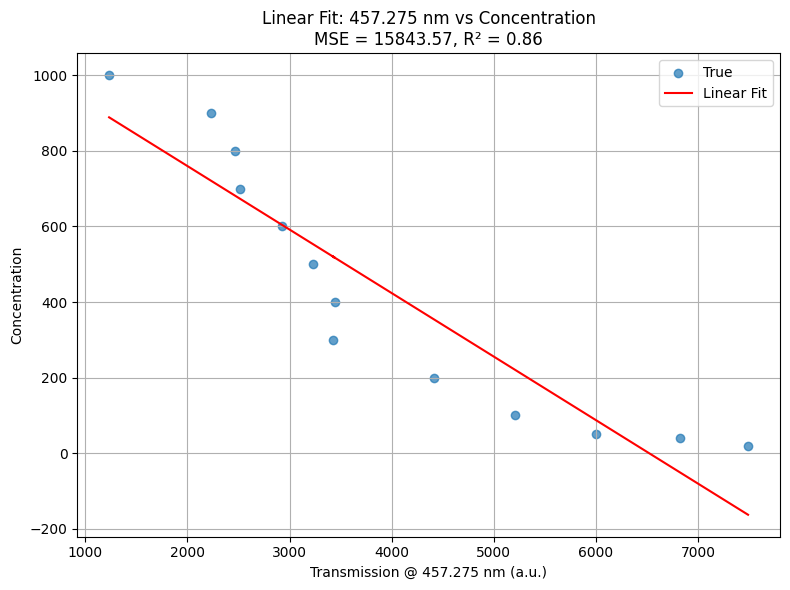

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# === Load long-format CSV ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format (each wavelength becomes a column) ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2")
wide_df = wide_df.dropna(axis=1)  # optional cleanup
wide_df = wide_df.sort_index()

# === Set wavelength feature to test ===
best_wavelength = 457.275  # must match one of the pivoted columns

# === Confirm ===
print("Available wavelengths:")
print(wide_df.columns.round(3).tolist())

if best_wavelength not in wide_df.columns:
    raise ValueError(f"Wavelength {best_wavelength} not found in columns.")

# === Prepare variables ===
X = wide_df[[best_wavelength]]
y = wide_df.index.values  # concentrations

# === Linear regression ===
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

# === Metrics ===
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

# === Plot ===
plt.figure(figsize=(8, 6))
plt.scatter(X, y, label="True", alpha=0.7)
plt.plot(X, y_pred, color="red", label="Linear Fit")
plt.xlabel(f"Transmission @ {best_wavelength} nm (a.u.)")
plt.ylabel("Concentration")
plt.title(f"Linear Fit: {best_wavelength} nm vs Concentration\nMSE = {mse:.2f}, R² = {r2:.2f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

# === Prepare X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Optional: rename columns to valid variable names ===
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === Define 10-fold CV MSE ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy feature selection ===
remaining = list(X.columns)
selected = []
data_list = []

best_mse = float("inf")

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })

    print(f"Step {len(selected)}: added {best_candidate} -> 10-fold MSE: {best_mse:.2f}")

# === Convert to DataFrame and Plot ===
results_df = pd.DataFrame(data_list)

plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Step 1: added wv_457_275 -> 10-fold MSE: 22157.58
Step 2: added wv_427_16 -> 10-fold MSE: 6753.58
Step 3: added wv_631_853 -> 10-fold MSE: 6861.90
Step 4: added wv_423_564 -> 10-fold MSE: 4697.08
Step 5: added wv_478_19 -> 10-fold MSE: 3205.72
Step 6: added wv_479_65 -> 10-fold MSE: 2388.56
Step 7: added wv_545_117 -> 10-fold MSE: 1975.39
Step 8: added wv_629_068 -> 10-fold MSE: 3017.36
Step 9: added wv_452_447 -> 10-fold MSE: 2759.62
Step 10: added wv_547_774 -> 10-fold MSE: 8.81
Step 11: added wv_631_058 -> 10-fold MSE: 18.37
Step 12: added wv_488_603 -> 10-fold MSE: 3.87
Step 13: added wv_455_176 -> 10-fold MSE: 32.14
Step 14: added wv_633_841 -> 10-fold MSE: 70.15
Step 15: added wv_633_046 -> 10-fold MSE: 29.79
Step 16: added wv_635_827 -> 10-fold MSE: 72.23
Step 17: added wv_421_447 -> 10-fold MSE: 115.99
Step 18: added wv_419_329 -> 10-fold MSE: 166.32
Step 19: added wv_417_21 -> 10-fold MSE: 213.04
Step 20: added wv_415_089 -> 10-fold MSE: 295.73
Step 21: added wv_424_41 -> 10-f

KeyboardInterrupt: 

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

# === Prepare X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Optional: rename columns to valid variable names ===
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === Define 10-fold CV MSE ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy feature selection ===
remaining = list(X.columns)
selected = []
data_list = []

best_mse = float("inf")

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })

    print(f"Step {len(selected)}: added {best_candidate} -> 10-fold MSE: {best_mse:.2f}")

# === Convert to DataFrame and Plot ===
results_df = pd.DataFrame(data_list)

plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Step 1: added wv_457_275 -> 10-fold MSE: 22157.58
Step 2: added wv_427_16 -> 10-fold MSE: 6753.58
Step 3: added wv_631_853 -> 10-fold MSE: 6861.90
Step 4: added wv_423_564 -> 10-fold MSE: 4697.08
Step 5: added wv_478_19 -> 10-fold MSE: 3205.72
Step 6: added wv_479_65 -> 10-fold MSE: 2388.56
Step 7: added wv_545_117 -> 10-fold MSE: 1975.39
Step 8: added wv_629_068 -> 10-fold MSE: 3017.36
Step 9: added wv_452_447 -> 10-fold MSE: 2759.62
Step 10: added wv_547_774 -> 10-fold MSE: 8.81
Step 11: added wv_631_058 -> 10-fold MSE: 18.37
Step 12: added wv_488_603 -> 10-fold MSE: 3.87
Step 13: added wv_455_176 -> 10-fold MSE: 32.14
Step 14: added wv_633_841 -> 10-fold MSE: 70.15
Step 15: added wv_633_046 -> 10-fold MSE: 29.79
Step 16: added wv_635_827 -> 10-fold MSE: 72.23
Step 17: added wv_421_447 -> 10-fold MSE: 115.99
Step 18: added wv_419_329 -> 10-fold MSE: 166.32
Step 19: added wv_417_21 -> 10-fold MSE: 213.04
Step 20: added wv_415_089 -> 10-fold MSE: 295.73
Step 21: added wv_424_41 -> 10-f

KeyboardInterrupt: 

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)

# === Sort concentrations (rows) ===
wide_df = wide_df.sort_index()

# === Sort wavelengths (columns) from lowest to highest ===
wide_df = wide_df[sorted(wide_df.columns)]

# === Prepare X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Optional: rename columns to valid variable names ===
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === Define 10-fold CV MSE ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy feature selection ===
remaining = list(X.columns)
selected = []
data_list = []

best_mse = float("inf")

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })

    print(f"Step {len(selected)}: added {best_candidate} -> 10-fold MSE: {best_mse:.2f}")

# === Convert to DataFrame and Plot ===
results_df = pd.DataFrame(data_list)

plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV, Sorted Wavelengths)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Step 1: added wv_457_275 -> 10-fold MSE: 22157.58
Step 2: added wv_427_16 -> 10-fold MSE: 6753.58
Step 3: added wv_631_853 -> 10-fold MSE: 6861.90
Step 4: added wv_423_564 -> 10-fold MSE: 4697.08
Step 5: added wv_478_19 -> 10-fold MSE: 3205.72
Step 6: added wv_479_65 -> 10-fold MSE: 2388.56
Step 7: added wv_545_117 -> 10-fold MSE: 1975.39
Step 8: added wv_629_068 -> 10-fold MSE: 3017.36
Step 9: added wv_452_447 -> 10-fold MSE: 2759.62
Step 10: added wv_547_774 -> 10-fold MSE: 8.81
Step 11: added wv_631_058 -> 10-fold MSE: 18.37
Step 12: added wv_488_603 -> 10-fold MSE: 3.87
Step 13: added wv_455_176 -> 10-fold MSE: 32.14
Step 14: added wv_633_841 -> 10-fold MSE: 70.15
Step 15: added wv_633_046 -> 10-fold MSE: 29.79
Step 16: added wv_635_827 -> 10-fold MSE: 72.23
Step 17: added wv_421_447 -> 10-fold MSE: 115.99
Step 18: added wv_419_329 -> 10-fold MSE: 166.32
Step 19: added wv_417_21 -> 10-fold MSE: 213.04
Step 20: added wv_415_089 -> 10-fold MSE: 295.73
Step 21: added wv_424_41 -> 10-f

KeyboardInterrupt: 

In [ ]:
# === Transpose wide_df ===
wide_df_transposed = wide_df.T

# === Optional: Save the transposed version if you want ===
wide_df_transposed.to_csv("processed_sorted_transmission_TRANSPOSED.csv")

print("✅ Transposed matrix created and saved as 'processed_sorted_transmission_TRANSPOSED.csv'")


✅ Transposed matrix created and saved as 'processed_sorted_transmission_TRANSPOSED.csv'


In [ ]:
import pandas as pd

# === Load your file ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)

# === Sort concentrations (rows) ===
wide_df = wide_df.sort_index()

# === Sort wavelengths (columns) from lowest to highest ===
wide_df = wide_df[sorted(wide_df.columns)]

# === Reset index if you want concentrations as a column (optional) ===
# wide_df = wide_df.reset_index()

# === Save the fully clean dataset if you want ===
wide_df.to_csv("processed_sorted_transmission.csv", index=True)

print("✅ Finished sorting wavelengths from lowest to highest for each concentration. File saved as 'processed_sorted_transmission.csv'")


✅ Finished sorting wavelengths from lowest to highest for each concentration. File saved as 'processed_sorted_transmission.csv'


Step 1: added wv_457_275 -> 10-fold MSE: 22157.58
Step 2: added wv_427_16 -> 10-fold MSE: 6753.58
Step 3: added wv_631_853 -> 10-fold MSE: 6861.90
Step 4: added wv_423_564 -> 10-fold MSE: 4697.08
Step 5: added wv_478_19 -> 10-fold MSE: 3205.72
Step 6: added wv_479_65 -> 10-fold MSE: 2388.56
Step 7: added wv_545_117 -> 10-fold MSE: 1975.39
Step 8: added wv_629_068 -> 10-fold MSE: 3017.36
Step 9: added wv_452_447 -> 10-fold MSE: 2759.62
Step 10: added wv_547_774 -> 10-fold MSE: 8.81
Step 11: added wv_631_058 -> 10-fold MSE: 18.37
Step 12: added wv_488_603 -> 10-fold MSE: 3.87
Step 13: added wv_455_176 -> 10-fold MSE: 32.14
Step 14: added wv_633_841 -> 10-fold MSE: 70.15
Step 15: added wv_633_046 -> 10-fold MSE: 29.79
Step 16: added wv_635_827 -> 10-fold MSE: 72.23
Step 17: added wv_421_447 -> 10-fold MSE: 115.99
Step 18: added wv_419_329 -> 10-fold MSE: 166.32
Step 19: added wv_417_21 -> 10-fold MSE: 213.04
Step 20: added wv_415_089 -> 10-fold MSE: 295.73


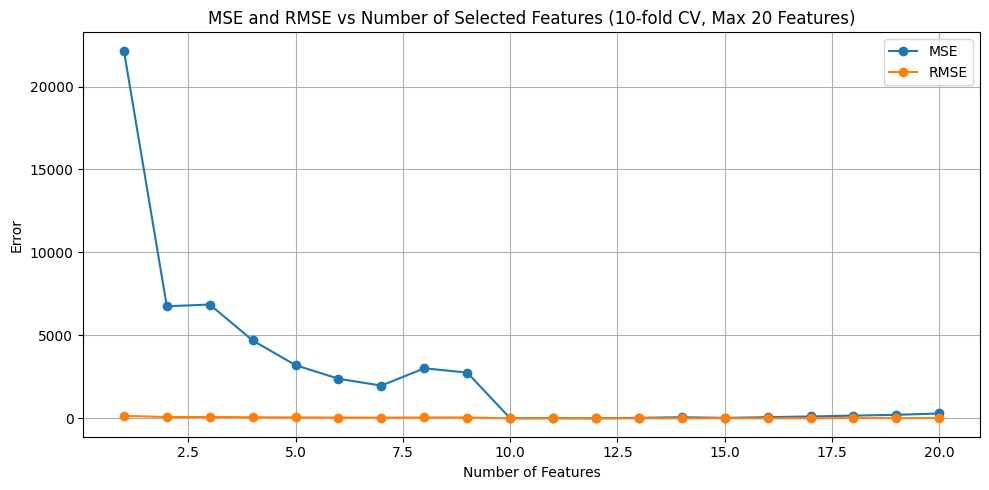

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

# === Prepare X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Optional: rename columns to valid variable names ===
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === Define 10-fold CV MSE ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy feature selection with a 20-feature cap ===
remaining = list(X.columns)
selected = []
data_list = []

best_mse = float("inf")
max_features = 20  # Limit number of added features

for i in range(1, max_features + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })

    print(f"Step {len(selected)}: added {best_candidate} -> 10-fold MSE: {best_mse:.2f}")

# === Convert to DataFrame and Plot ===
results_df = pd.DataFrame(data_list)

plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV, Max 20 Features)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Step 1: added wv_457_275 -> 10-fold MSE: 22157.58
Step 2: added wv_427_16 -> 10-fold MSE: 6753.58
Step 3: added wv_631_853 -> 10-fold MSE: 6861.90
Step 4: added wv_423_564 -> 10-fold MSE: 4697.08
Step 5: added wv_478_19 -> 10-fold MSE: 3205.72
Step 6: added wv_479_65 -> 10-fold MSE: 2388.56
Step 7: added wv_545_117 -> 10-fold MSE: 1975.39
Step 8: added wv_629_068 -> 10-fold MSE: 3017.36
Step 9: added wv_452_447 -> 10-fold MSE: 2759.62
Step 10: added wv_547_774 -> 10-fold MSE: 8.81
Step 11: added wv_631_058 -> 10-fold MSE: 18.37
Step 12: added wv_488_603 -> 10-fold MSE: 3.87
Step 13: added wv_455_176 -> 10-fold MSE: 32.14
Step 14: added wv_633_841 -> 10-fold MSE: 70.15
Step 15: added wv_633_046 -> 10-fold MSE: 29.79
Step 16: added wv_635_827 -> 10-fold MSE: 72.23
Step 17: added wv_421_447 -> 10-fold MSE: 115.99
Step 18: added wv_419_329 -> 10-fold MSE: 166.32
Step 19: added wv_417_21 -> 10-fold MSE: 213.04
Step 20: added wv_415_089 -> 10-fold MSE: 295.73


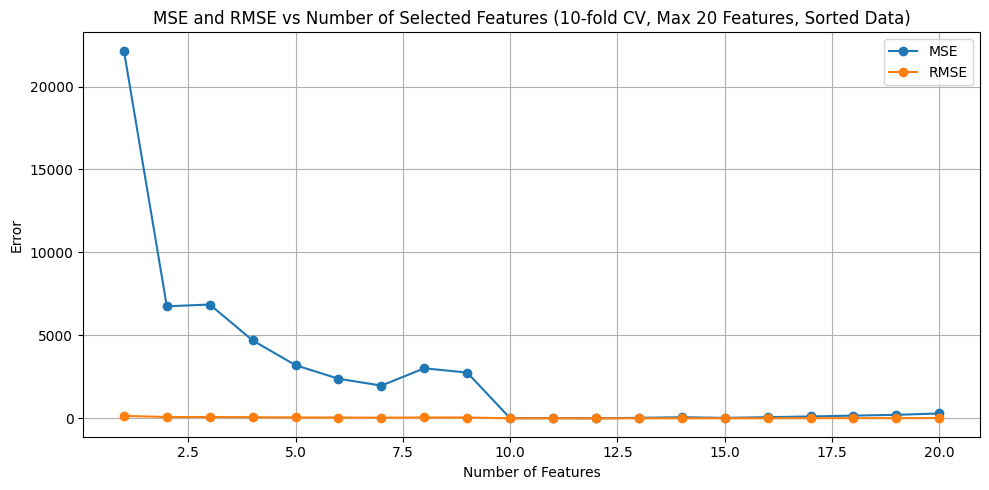

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load preprocessed sorted data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X and y ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Optional: rename columns to valid variable names ===
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === Define 10-fold CV MSE ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy feature selection with a 20-feature cap ===
remaining = list(X.columns)
selected = []
data_list = []

best_mse = float("inf")
max_features = 20  # Limit number of added features

for i in range(1, max_features + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })

    print(f"Step {len(selected)}: added {best_candidate} -> 10-fold MSE: {best_mse:.2f}")

# === Convert to DataFrame and Plot ===
results_df = pd.DataFrame(data_list)

plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV, Max 20 Features, Sorted Data)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load the already sorted file ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X and y ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Optional: rename columns to valid variable names ===
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === Setup ===
kf = KFold(n_splits=10, shuffle=True, random_state=42)
mse_per_wavelength = {}

# === Loop over each wavelength ===
for col in X.columns:
    mse_vals = []
    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx][[col]], X.iloc[val_idx][[col]]  # Only this wavelength
        y_train, y_val = y[train_idx], y[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    avg_mse = np.mean(mse_vals)
    mse_per_wavelength[col] = avg_mse

# === Convert to DataFrame ===
mse_df = pd.DataFrame(list(mse_per_wavelength.items()), columns=["wavelength", "mse"])

# === Clean wavelength column back to float ===
mse_df["wavelength"] = mse_df["wavelength"].str.replace("wv_", "").str.replace("_", ".").astype(float)

# === Sort by wavelength ascending ===
mse_df = mse_df.sort_values(by="wavelength")

# === Save if needed ===
mse_df.to_csv("mse_per_wavelength.csv", index=False)

print("✅ Done calculating MSE per wavelength.")


✅ Done calculating MSE per wavelength.


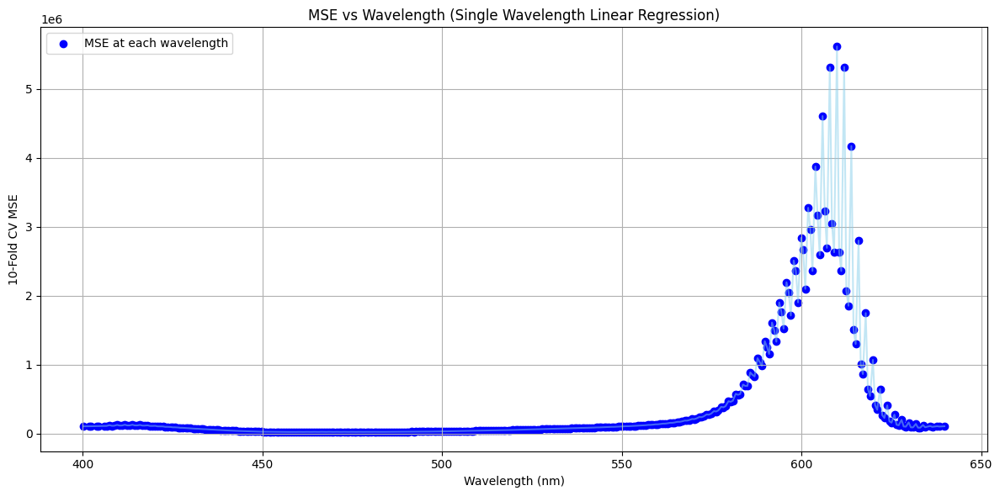

In [ ]:
# === Plot MSE per wavelength ===
plt.figure(figsize=(12,6))
plt.scatter(mse_df["wavelength"], mse_df["mse"], color='blue', label="MSE at each wavelength")
plt.plot(mse_df["wavelength"], mse_df["mse"], color='skyblue', alpha=0.5)

plt.xlabel("Wavelength (nm)")
plt.ylabel("10-Fold CV MSE")
plt.title("MSE vs Wavelength (Single Wavelength Linear Regression)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# === Load your data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X (transmission) and y (concentration) ===
X_full = df.copy()
y_true = X_full.index.values
X_full.reset_index(drop=True, inplace=True)

# === Calculate R² for each wavelength ===
wavelengths = X_full.columns
r2_list = []

for wl in wavelengths:
    X_wl = X_full[wl].values.reshape(-1, 1)
    model = LinearRegression().fit(X_wl, y_true)
    y_pred = model.predict(X_wl)
    r2 = r2_score(y_true, y_pred)
    r2_list.append({
        "wavelength": float(wl),
        "r2": r2
    })

# === Save R² results ===
r2_df = pd.DataFrame(r2_list)
r2_df.to_csv("r2_per_wavelength.csv", index=False)

print("✅ R² per wavelength calculated and saved as 'r2_per_wavelength.csv'.")


✅ R² per wavelength calculated and saved as 'r2_per_wavelength.csv'.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

# === Load preprocessed data ===
df = pd.read_csv("processed_sorted_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

# === Prepare X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Optional: rename columns to valid variable names ===
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === Initialize results ===
results = []

# === 10-Fold Cross Validation per wavelength ===
kf = KFold(n_splits=10, shuffle=True, random_state=42)

for col in X.columns:
    X_col = X[[col]].values

    mse_folds = []
    r2_folds = []

    for train_idx, val_idx in kf.split(X_col):
        X_train, X_val = X_col[train_idx], X_col[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)

        mse_folds.append(mean_squared_error(y_val, y_pred))
        r2_folds.append(r2_score(y_val, y_pred))

    avg_mse = np.mean(mse_folds)
    avg_r2 = np.mean(r2_folds)

    results.append({
        "wavelength": float(col.replace("wv_", "").replace("_", ".")),
        "mse": avg_mse,
        "rmse": np.sqrt(avg_mse),
        "r2": avg_r2
    })

# === Save to CSV ===
results_df = pd.DataFrame(results)
results_df.to_csv("mse_rmse_r2_per_wavelength_10foldcv.csv", index=False)

print("✅ Done. Saved as 'mse_rmse_r2_per_wavelength_10foldcv.csv'.")


KeyError: 'smoothed_T2'

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np

# === Load processed sorted transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv")

# === Prepare X and y ===
X = df.drop(columns=["concentration"]).values
y = df["concentration"].values

# === Get wavelength names ===
wavelengths = df.columns.drop("concentration").astype(float).values

# === Function to perform 10-fold CV and get MSE and R2 ===
def kfold_cv_metrics(X_single_feature, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    r2_vals = []
    for train_idx, val_idx in kf.split(X_single_feature):
        X_train, X_val = X_single_feature[train_idx], X_single_feature[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
        r2_vals.append(r2_score(y_val, y_pred))
    return np.mean(mse_vals), np.mean(r2_vals)

# === Loop through each wavelength (feature) and calculate metrics ===
results = []
for i, wl in enumerate(wavelengths):
    X_single = X[:, i].reshape(-1, 1)
    avg_mse, avg_r2 = kfold_cv_metrics(X_single, y)
    results.append({
        "wavelength": wl,
        "mse": avg_mse,
        "rmse": np.sqrt(avg_mse),
        "r2": avg_r2
    })

# === Save the results ===
results_df = pd.DataFrame(results)
results_df.to_csv("mse_rmse_r2_per_wavelength_10foldcv.csv", index=False)

print("✅ Done. Saved as 'mse_rmse_r2_per_wavelength_10foldcv.csv'.")


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, Unde

✅ Done. Saved as 'mse_rmse_r2_per_wavelength_10foldcv.csv'.


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, Unde

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
import warnings

# === Load the transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv")

# === Prepare X and y ===
X = df.drop(columns=["concentration"])
y = df["concentration"].values

# === Wavelengths ===
wavelengths = X.columns.astype(float)

# === Define function for 10-fold CV ===
def kfold_cv_metrics(X_single, y, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_list = []
    r2_list = []

    for train_idx, val_idx in kf.split(X_single):
        X_train, X_val = X_single[train_idx], X_single[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)

        mse_list.append(mean_squared_error(y_val, y_pred))

        if len(y_val) >= 2:
            r2_list.append(r2_score(y_val, y_pred))
        else:
            r2_list.append(np.nan)  # can't compute R2 for 1 point

    avg_mse = np.mean(mse_list)
    avg_r2 = np.nanmean(r2_list)  # average only valid R2 values

    return avg_mse, avg_r2

# === Run 10-fold CV for each wavelength ===
results = []

for wl in wavelengths:
    X_single = X[[str(wl)]].values
    avg_mse, avg_r2 = kfold_cv_metrics(X_single, y)

    results.append({
        "wavelength": wl,
        "mse": avg_mse,
        "rmse": np.sqrt(avg_mse),
        "r2": avg_r2
    })

# === Save to CSV ===
results_df = pd.DataFrame(results)
results_df.to_csv("corrected_mse_rmse_r2_per_wavelength_10foldcv.csv", index=False)

print("✅ Done. Saved as 'corrected_mse_rmse_r2_per_wavelength_10foldcv.csv'.")


KeyboardInterrupt: 

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np

# === Load processed data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X and y ===
X = df.copy()
y = df.index.values
X.reset_index(drop=True, inplace=True)

# === Wavelengths ===
wavelengths = [float(col) for col in X.columns]

# === Store results ===
results = []

for wl in wavelengths:
    wl_col = f"{wl:.3f}"

    if wl_col not in df.columns:
        continue

    X_single = df[wl_col].values.reshape(-1, 1)

    # === Fit Linear Regression directly ===
    model = LinearRegression().fit(X_single, y)
    y_pred = model.predict(X_single)

    mse_val = mean_squared_error(y, y_pred)
    r2_val = r2_score(y, y_pred)

    results.append({
        "wavelength": wl,
        "mse": mse_val,
        "rmse": np.sqrt(mse_val),
        "r2": r2_val
    })

# === Save the results ===
results_df = pd.DataFrame(results)
results_df.to_csv("direct_fit_mse_rmse_r2_per_wavelength.csv", index=False)

print("✅ Done. Saved as 'direct_fit_mse_rmse_r2_per_wavelength.csv'.")


✅ Done. Saved as 'direct_fit_mse_rmse_r2_per_wavelength.csv'.


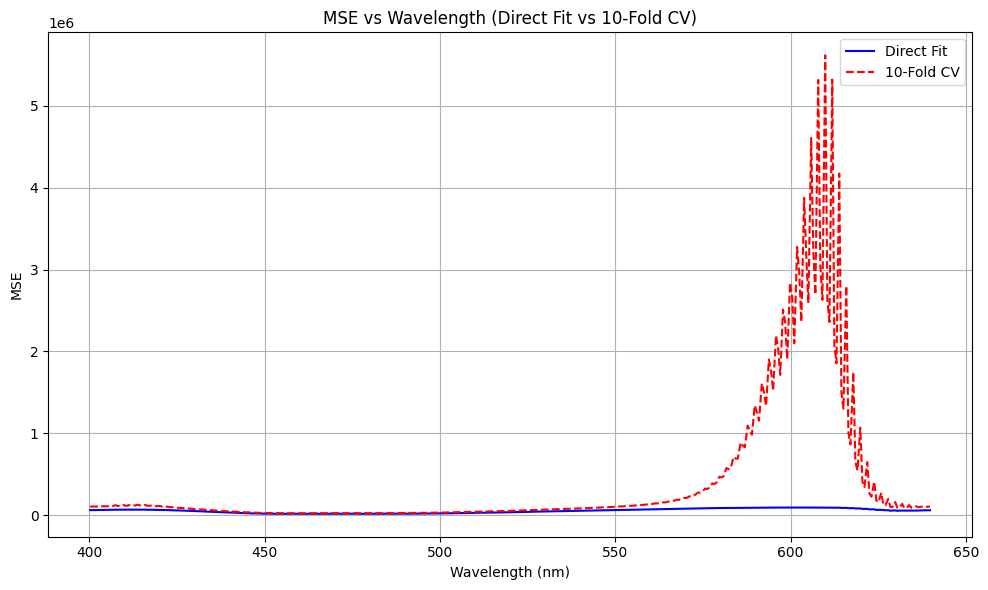

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load both datasets ===
no_cv_df = pd.read_csv("direct_fit_mse_rmse_r2_per_wavelength.csv")  # without CV
cv_df = pd.read_csv("mse_rmse_r2_per_wavelength_10foldcv.csv")  # with 10-fold CV

# === Plot MSE only ===
plt.figure(figsize=(10, 6))
plt.plot(no_cv_df["wavelength"], no_cv_df["mse"], label="Direct Fit", color="blue")
plt.plot(cv_df["wavelength"], cv_df["mse"], label="10-Fold CV", color="red", linestyle="--")
plt.xlabel("Wavelength (nm)")
plt.ylabel("MSE")
plt.title("MSE vs Wavelength (Direct Fit vs 10-Fold CV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


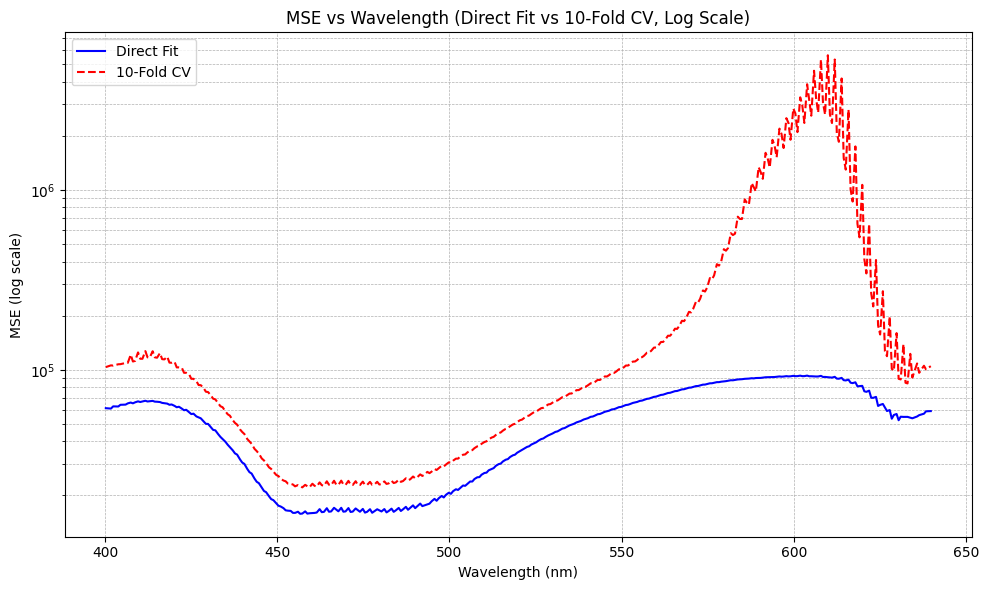

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load both datasets ===
no_cv_df = pd.read_csv("direct_fit_mse_rmse_r2_per_wavelength.csv")  # without CV
cv_df = pd.read_csv("mse_rmse_r2_per_wavelength_10foldcv.csv")  # with 10-fold CV

# === Plot MSE only (with log scale) ===
plt.figure(figsize=(10, 6))
plt.plot(no_cv_df["wavelength"], no_cv_df["mse"], label="Direct Fit", color="blue")
plt.plot(cv_df["wavelength"], cv_df["mse"], label="10-Fold CV", color="red", linestyle="--")
plt.xlabel("Wavelength (nm)")
plt.ylabel("MSE (log scale)")
plt.yscale("log")
plt.title("MSE vs Wavelength (Direct Fit vs 10-Fold CV, Log Scale)")
plt.legend()
plt.grid(True, which="both", ls="--", lw=0.5)
plt.tight_layout()
plt.show()


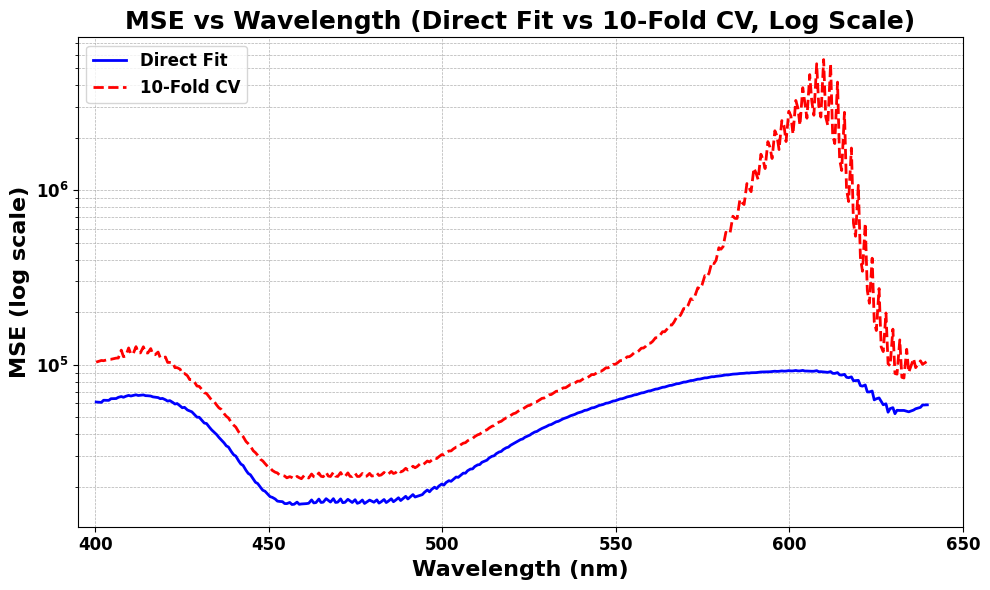

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load both datasets ===
no_cv_df = pd.read_csv("direct_fit_mse_rmse_r2_per_wavelength.csv")
cv_df = pd.read_csv("corrected_mse_rmse_r2_per_wavelength_10foldcv.csv")

# === Plot ===
plt.figure(figsize=(10, 6))

# Apply Times New Roman to everything
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.titleweight"] = "bold"

plt.plot(no_cv_df["wavelength"], no_cv_df["mse"], label="Direct Fit", color="blue", linewidth=2)
plt.plot(cv_df["wavelength"], cv_df["mse"], label="10-Fold CV", color="red", linestyle="--", linewidth=2)

plt.xlim(395, 650)
plt.yscale("log")
plt.xlabel("Wavelength (nm)", fontsize=16, weight="bold")
plt.ylabel("MSE (log scale)", fontsize=16, weight="bold")
plt.title("MSE vs Wavelength (Direct Fit vs 10-Fold CV, Log Scale)", fontsize=18, weight="bold")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.legend(fontsize=12)
plt.tick_params(axis="both", which="major", labelsize=12)
plt.tight_layout()
plt.show()


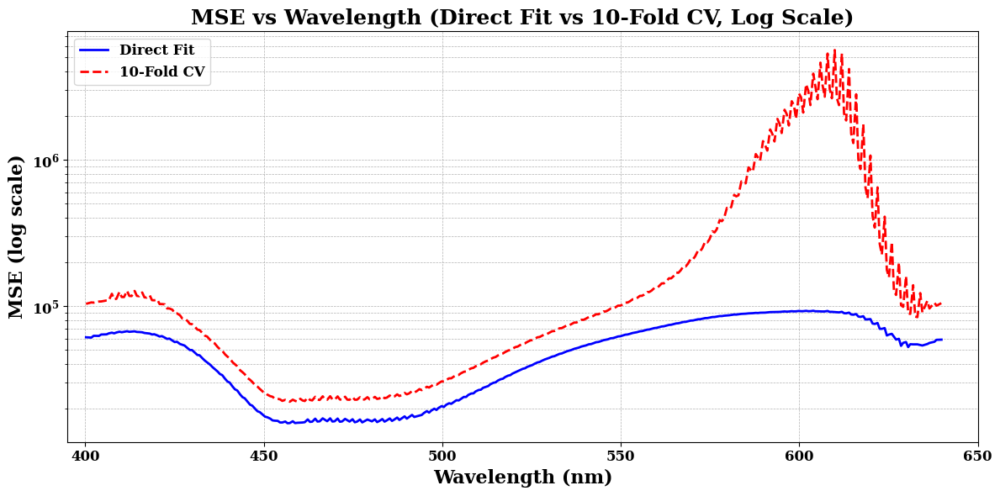

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Set font globally to serif (looks similar to Times New Roman)
plt.rcParams["font.family"] = "serif"

# === Load both datasets ===
no_cv = pd.read_csv("direct_fit_mse_rmse_r2_per_wavelength.csv")
cv = pd.read_csv("corrected_mse_rmse_r2_per_wavelength_10foldcv.csv")

# === Plot ===
plt.figure(figsize=(12,6))

plt.plot(no_cv["wavelength"], no_cv["mse"], label="Direct Fit", color="blue", linewidth=2)
plt.plot(cv["wavelength"], cv["mse"], label="10-Fold CV", color="red", linestyle="--", linewidth=2)

plt.xlim(395, 650)
plt.yscale("log")
plt.xlabel("Wavelength (nm)", fontsize=16, weight="bold")
plt.ylabel("MSE (log scale)", fontsize=16, weight="bold")
plt.title("MSE vs Wavelength (Direct Fit vs 10-Fold CV, Log Scale)", fontsize=18, weight="bold")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.legend(fontsize=12)
plt.tick_params(axis="both", which="major", labelsize=12)
plt.tight_layout()
plt.show()


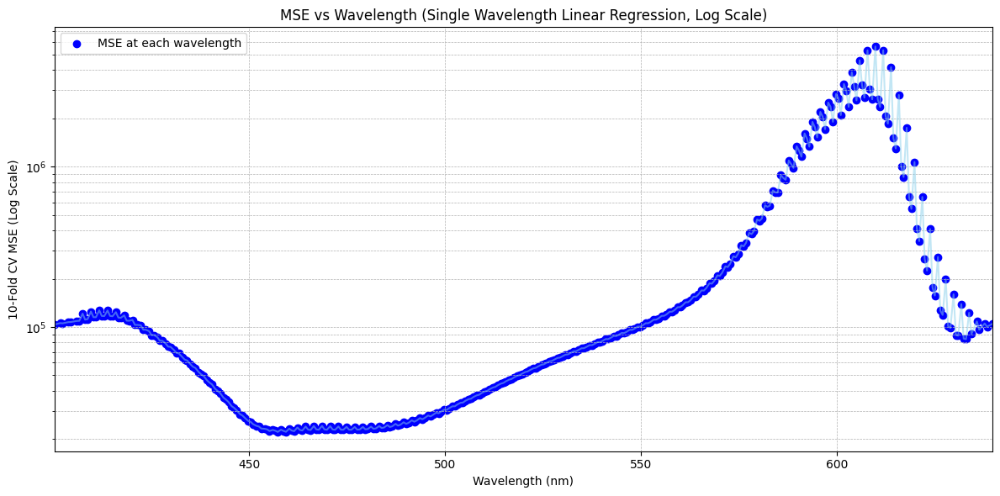

In [ ]:
# === Plot MSE per wavelength with LOG SCALE ===
plt.figure(figsize=(12,6))
plt.scatter(mse_df["wavelength"], mse_df["mse"], color='blue', label="MSE at each wavelength")
plt.plot(mse_df["wavelength"], mse_df["mse"], color='skyblue', alpha=0.5)

plt.xlim(mse_df["wavelength"].min(), mse_df["wavelength"].max())
plt.yscale("log")  # <<< LOG SCALE for Y (MSE)

plt.xlabel("Wavelength (nm)")
plt.ylabel("10-Fold CV MSE (Log Scale)")
plt.title("MSE vs Wavelength (Single Wavelength Linear Regression, Log Scale)")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# === Instead of only saving avg_mse, now save all 10 MSE values too ===
mse_per_wavelength = {}
mse_std_per_wavelength = {}

for col in X.columns:
    mse_vals = []
    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx][[col]], X.iloc[val_idx][[col]]
        y_train, y_val = y[train_idx], y[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    avg_mse = np.mean(mse_vals)
    std_mse = np.std(mse_vals)
    mse_per_wavelength[col] = avg_mse
    mse_std_per_wavelength[col] = std_mse

# === Convert to DataFrame ===
mse_df = pd.DataFrame({
    "wavelength": [float(c.replace("wv_", "").replace("_", ".")) for c in mse_per_wavelength.keys()],
    "mse": list(mse_per_wavelength.values()),
    "std": list(mse_std_per_wavelength.values())
})

# === Sort by wavelength ===
mse_df = mse_df.sort_values(by="wavelength")

# === Save if needed ===
mse_df.to_csv("mse_per_wavelength_with_std.csv", index=False)

print("✅ Done calculating MSE and STD per wavelength.")


✅ Done calculating MSE and STD per wavelength.


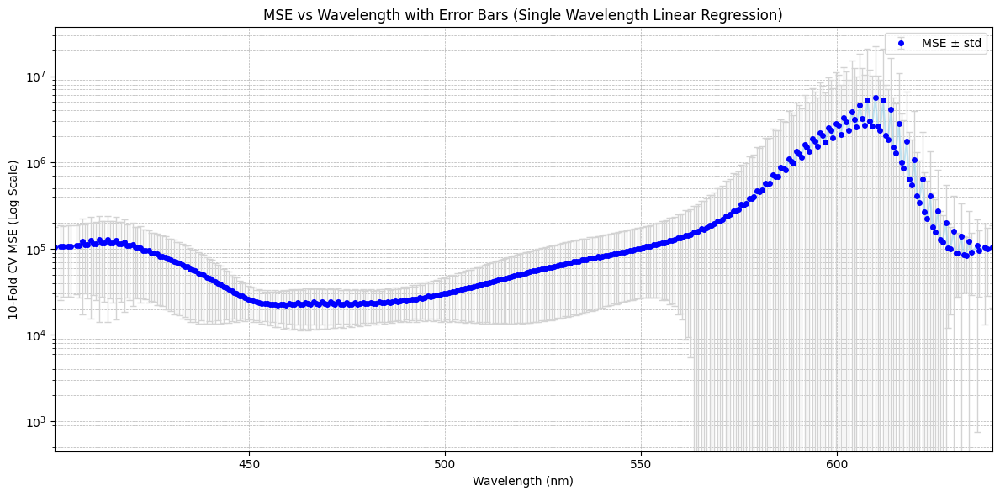

In [ ]:
# === Plot MSE with error bars ===
plt.figure(figsize=(12,6))
plt.errorbar(mse_df["wavelength"], mse_df["mse"], yerr=mse_df["std"], fmt='o', markersize=4,
             color='blue', ecolor='lightgray', elinewidth=1, capsize=3, label="MSE ± std")
plt.plot(mse_df["wavelength"], mse_df["mse"], color='skyblue', alpha=0.5)

plt.xlim(mse_df["wavelength"].min(), mse_df["wavelength"].max())
plt.yscale("log")

plt.xlabel("Wavelength (nm)")
plt.ylabel("10-Fold CV MSE (Log Scale)")
plt.title("MSE vs Wavelength with Error Bars (Single Wavelength Linear Regression)")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# === Plot RMSE (instead of MSE) with log scale ===
plt.figure(figsize=(12,6))
plt.scatter(mse_df["wavelength"], mse_df["rmse"], color='blue', label="RMSE at each wavelength")
plt.plot(mse_df["wavelength"], mse_df["rmse"], color='skyblue', alpha=0.5)

plt.xlim(mse_df["wavelength"].min(), mse_df["wavelength"].max())
plt.yscale("log")

plt.xlabel("Wavelength (nm)")
plt.ylabel("10-Fold CV RMSE (Log Scale)")
plt.title("RMSE vs Wavelength (Single Wavelength Linear Regression, Log Scale)")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.legend()
plt.tight_layout()
plt.show()


KeyError: 'rmse'

<Figure size 1200x600 with 0 Axes>

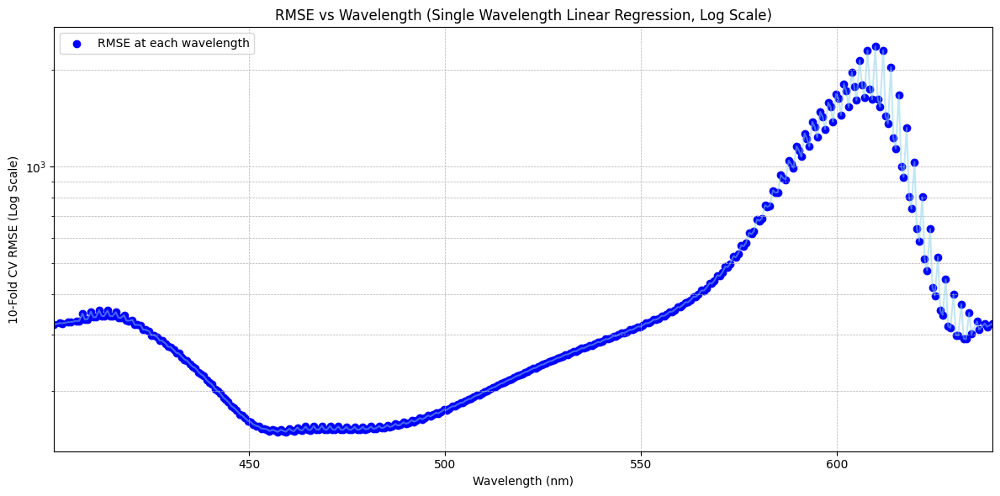

In [ ]:
# === First, calculate RMSE column ===
mse_df["rmse"] = np.sqrt(mse_df["mse"])

# === Then plot it ===
plt.figure(figsize=(12,6))
plt.scatter(mse_df["wavelength"], mse_df["rmse"], color='blue', label="RMSE at each wavelength")
plt.plot(mse_df["wavelength"], mse_df["rmse"], color='skyblue', alpha=0.5)

plt.xlim(mse_df["wavelength"].min(), mse_df["wavelength"].max())
plt.yscale("log")

plt.xlabel("Wavelength (nm)")
plt.ylabel("10-Fold CV RMSE (Log Scale)")
plt.title("RMSE vs Wavelength (Single Wavelength Linear Regression, Log Scale)")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.legend()
plt.tight_layout()
plt.show()


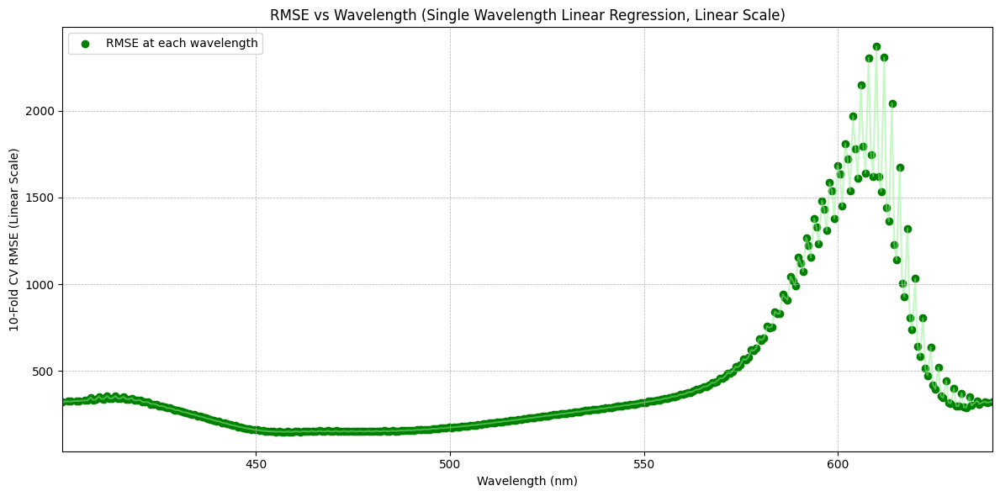

In [ ]:
# === Plot RMSE with Linear Y-axis ===
plt.figure(figsize=(12,6))
plt.scatter(mse_df["wavelength"], mse_df["rmse"], color='green', label="RMSE at each wavelength")
plt.plot(mse_df["wavelength"], mse_df["rmse"], color='lightgreen', alpha=0.5)

plt.xlim(mse_df["wavelength"].min(), mse_df["wavelength"].max())
# No plt.yscale("log") this time → default is linear

plt.xlabel("Wavelength (nm)")
plt.ylabel("10-Fold CV RMSE (Linear Scale)")
plt.title("RMSE vs Wavelength (Single Wavelength Linear Regression, Linear Scale)")
plt.grid(True, ls="--", lw=0.5)
plt.legend()
plt.tight_layout()
plt.show()


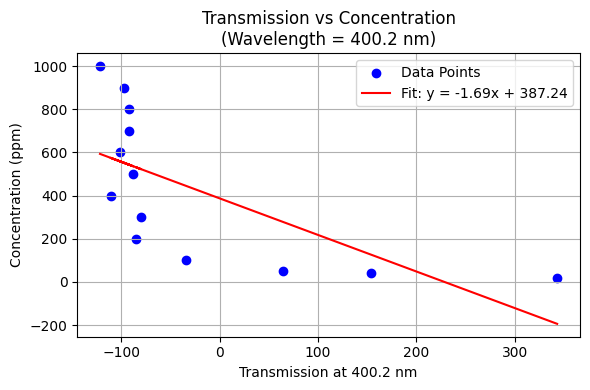

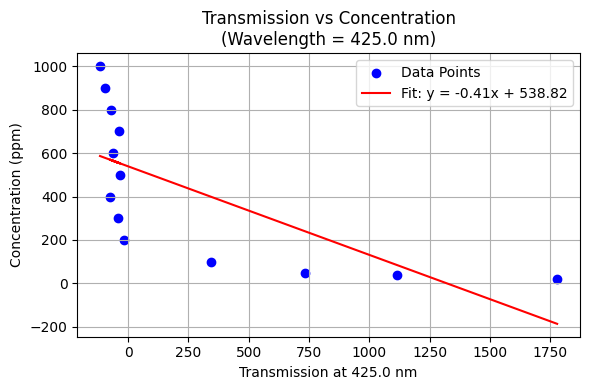

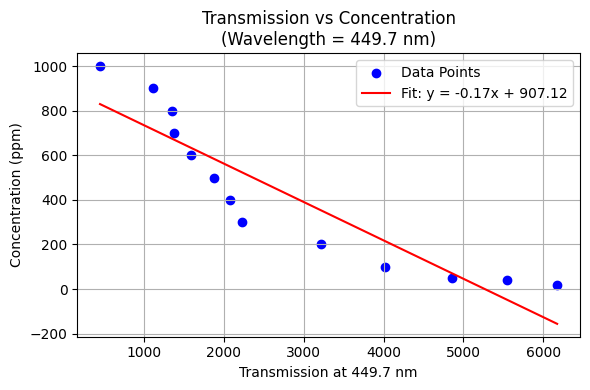

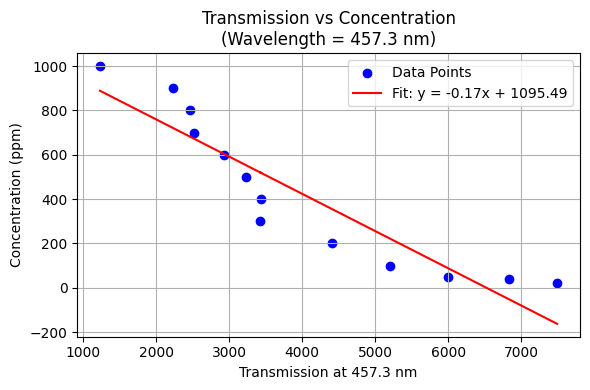

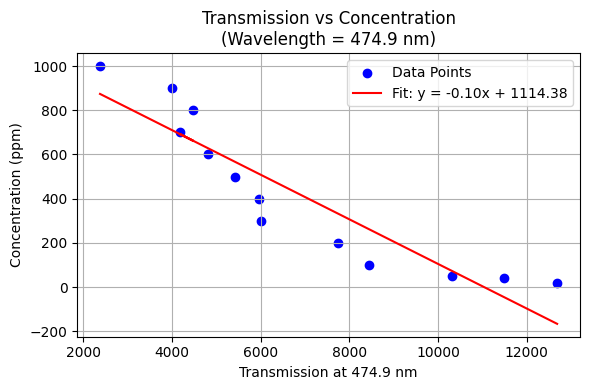

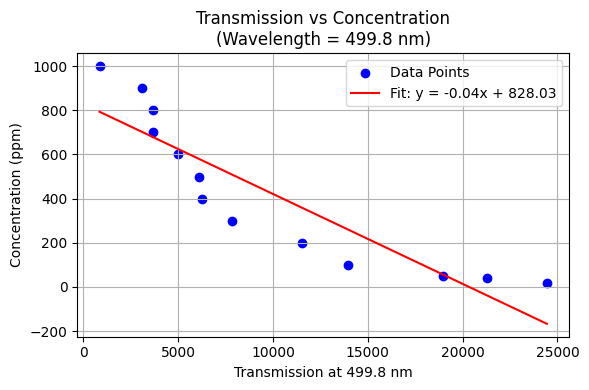

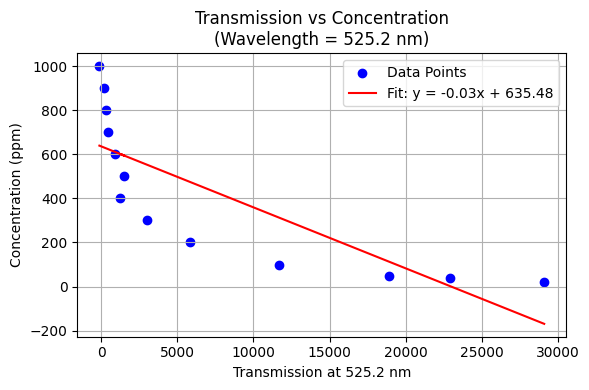

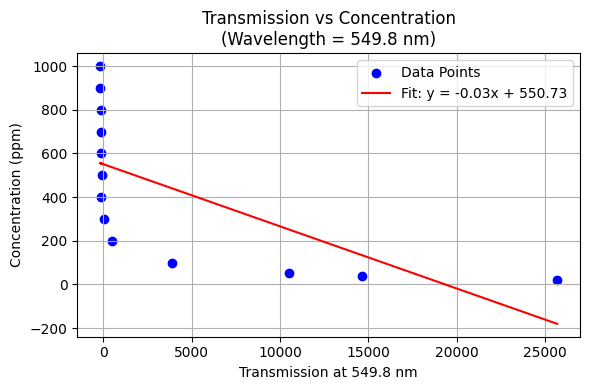

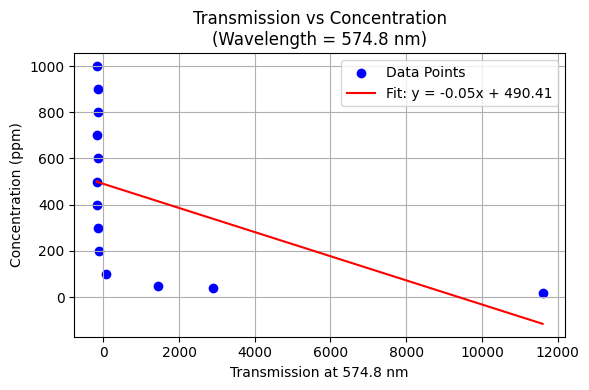

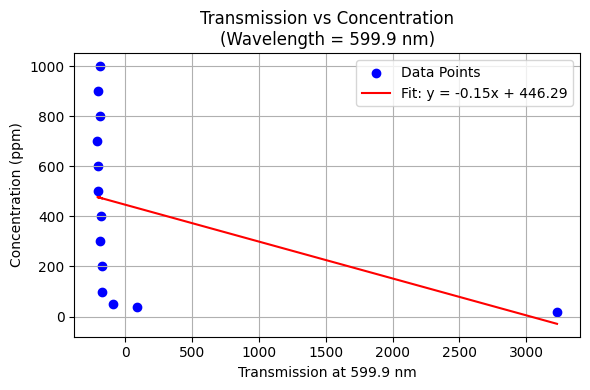

KeyError: '609.900'

In [ ]:
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load the sorted transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X (wavelengths) and y (concentration) ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Wavelengths in the dataset ===
wavelengths = [float(col) for col in X.columns]

# === MSE Data ===
mse_df = pd.read_csv("mse_per_wavelength_with_std.csv")
mse_df["rmse"] = np.sqrt(mse_df["mse"])

# === Identify best and worst wavelength ===
best_wavelength = mse_df.loc[mse_df["mse"].idxmin(), "wavelength"]
worst_wavelength = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

# === Define special wavelengths every 25 nm starting from 400 nm ===
special_wavelengths = list(np.arange(400, 650 + 1, 25))
# Include best and worst wavelengths if not already there
if best_wavelength not in special_wavelengths:
    special_wavelengths.append(best_wavelength)
if worst_wavelength not in special_wavelengths:
    special_wavelengths.append(worst_wavelength)
special_wavelengths = sorted(special_wavelengths)

# === Set up a DataFrame to save data ===
save_data = []

# === Plotting ===
for wl in special_wavelengths:
    # Find the closest actual column
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    # Prepare x and y for Linear Regression
    X_plot = df[str(wl_col)].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)

    coef = model.coef_[0]
    intercept = model.intercept_

    # Save the data
    for x_val, y_val, y_fit in zip(X_plot.flatten(), y_plot, y_pred):
        save_data.append({
            "wavelength": closest_wl,
            "transmission": x_val,
            "concentration": y_val,
            "predicted_concentration": y_fit,
            "coef": coef,
            "intercept": intercept
        })

    # === Plot ===
    plt.figure(figsize=(6, 4))
    plt.scatter(X_plot, y_plot, label="Data Points", color="blue")
    plt.plot(X_plot, y_pred, color="red", label=f"Fit: y = {coef:.2f}x + {intercept:.2f}")
    plt.xlabel(f"Transmission at {closest_wl:.1f} nm")
    plt.ylabel("Concentration (ppm)")
    plt.title(f"Transmission vs Concentration\n(Wavelength = {closest_wl:.1f} nm)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# === Save all the data into a file ===
save_df = pd.DataFrame(save_data)
save_df.to_csv("trans_vs_conc_fit_data.csv", index=False)

print("✅ Done. Plots generated and data saved as 'trans_vs_conc_fit_data.csv'.")


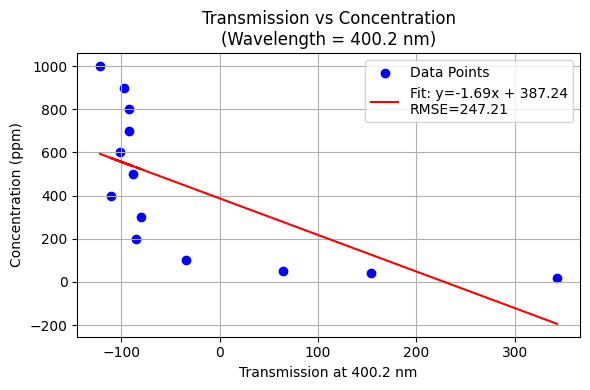

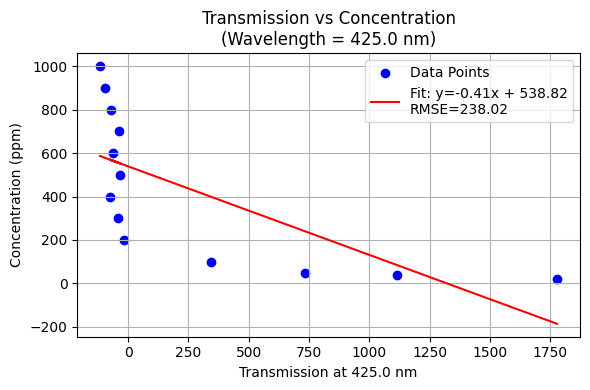

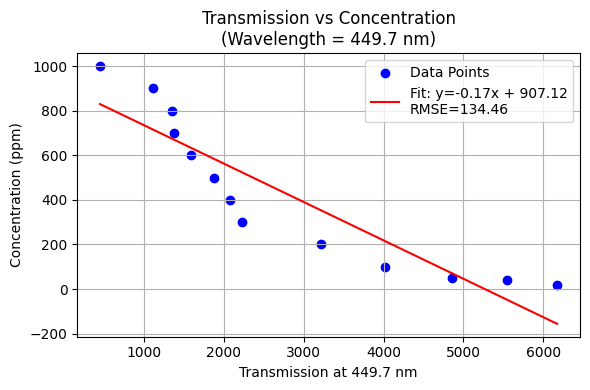

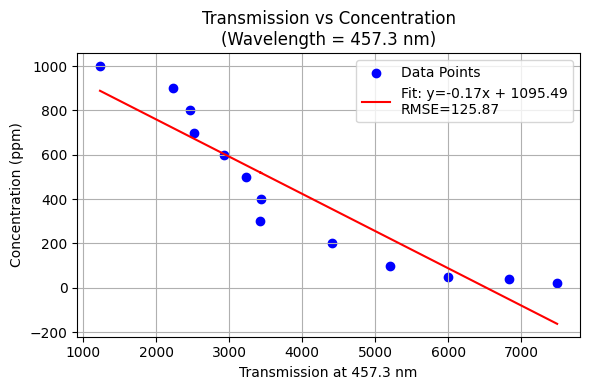

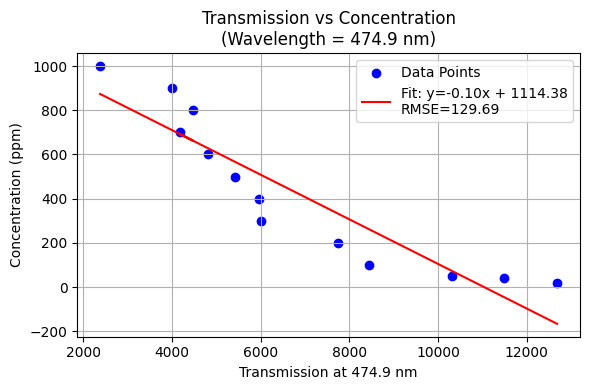

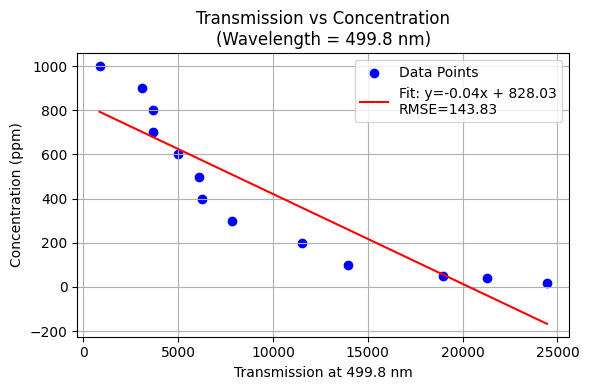

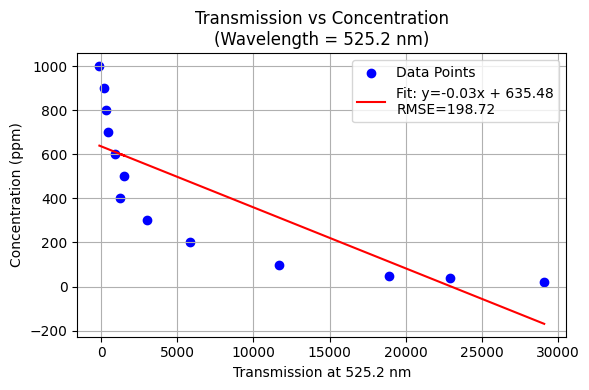

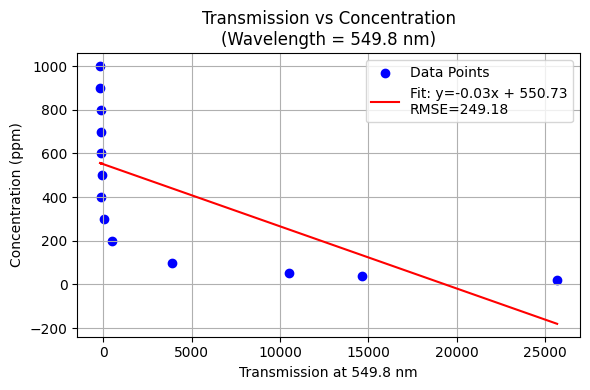

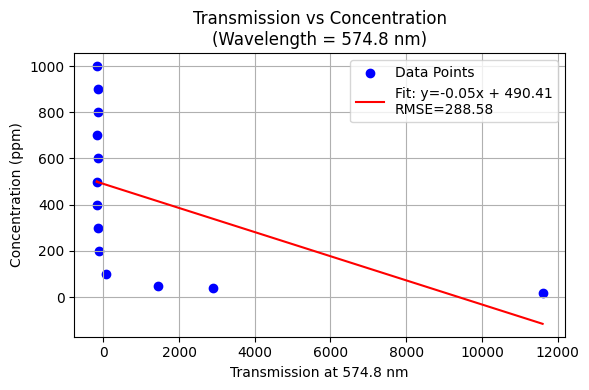

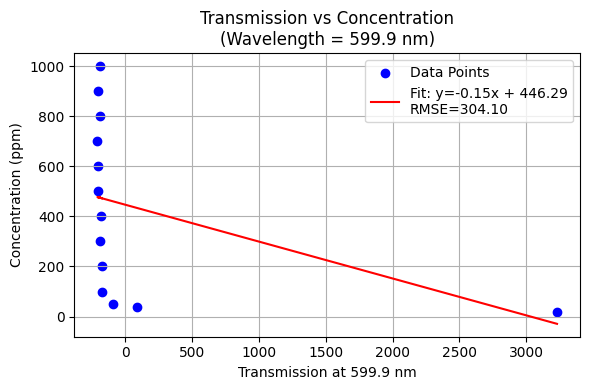

⚠️ Skipping 609.900 nm because not found in data.


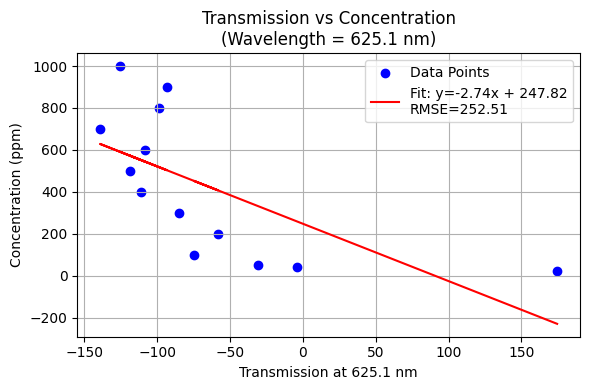

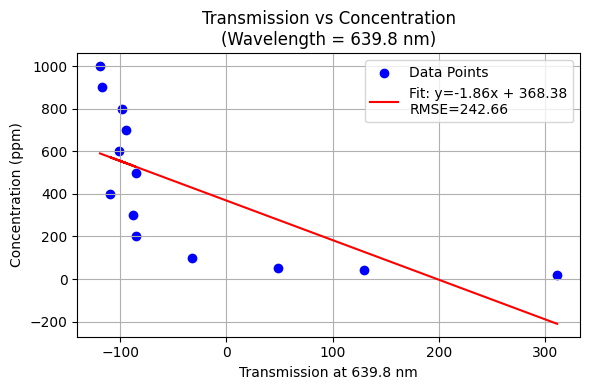

✅ Done. Plots generated and data saved as 'trans_vs_conc_fit_data_with_rmse.csv'.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load the sorted transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X (wavelengths) and y (concentration) ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Wavelengths in the dataset ===
wavelengths = [float(col) for col in X.columns]

# === MSE Data ===
mse_df = pd.read_csv("mse_per_wavelength_with_std.csv")
mse_df["rmse"] = np.sqrt(mse_df["mse"])

# === Identify best and worst wavelength ===
best_wavelength = mse_df.loc[mse_df["mse"].idxmin(), "wavelength"]
worst_wavelength = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

# === Define special wavelengths every 25 nm starting from 400 nm ===
special_wavelengths = list(np.arange(400, 650 + 1, 25))
# Include best and worst wavelengths if not already there
if best_wavelength not in special_wavelengths:
    special_wavelengths.append(best_wavelength)
if worst_wavelength not in special_wavelengths:
    special_wavelengths.append(worst_wavelength)
special_wavelengths = sorted(special_wavelengths)

# === Set up a DataFrame to save data ===
save_data = []

# === Plotting ===
for wl in special_wavelengths:
    # Find the closest available wavelength
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    if wl_col not in df.columns:
        print(f"⚠️ Skipping {wl_col} nm because not found in data.")
        continue

    # Prepare x and y for Linear Regression
    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)

    coef = model.coef_[0]
    intercept = model.intercept_

    rmse = np.sqrt(mean_squared_error(y_plot, y_pred))

    # Save the data
    for x_val, y_val, y_fit in zip(X_plot.flatten(), y_plot, y_pred):
        save_data.append({
            "wavelength": closest_wl,
            "transmission": x_val,
            "concentration": y_val,
            "predicted_concentration": y_fit,
            "coef": coef,
            "intercept": intercept,
            "rmse": rmse
        })

    # === Plot ===
    plt.figure(figsize=(6, 4))
    plt.scatter(X_plot, y_plot, label="Data Points", color="blue")
    plt.plot(X_plot, y_pred, color="red", label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}")
    plt.xlabel(f"Transmission at {closest_wl:.1f} nm")
    plt.ylabel("Concentration (ppm)")
    plt.title(f"Transmission vs Concentration\n(Wavelength = {closest_wl:.1f} nm)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# === Save all the data into a file ===
save_df = pd.DataFrame(save_data)
save_df.to_csv("trans_vs_conc_fit_data_with_rmse.csv", index=False)

print("✅ Done. Plots generated and data saved as 'trans_vs_conc_fit_data_with_rmse.csv'.")


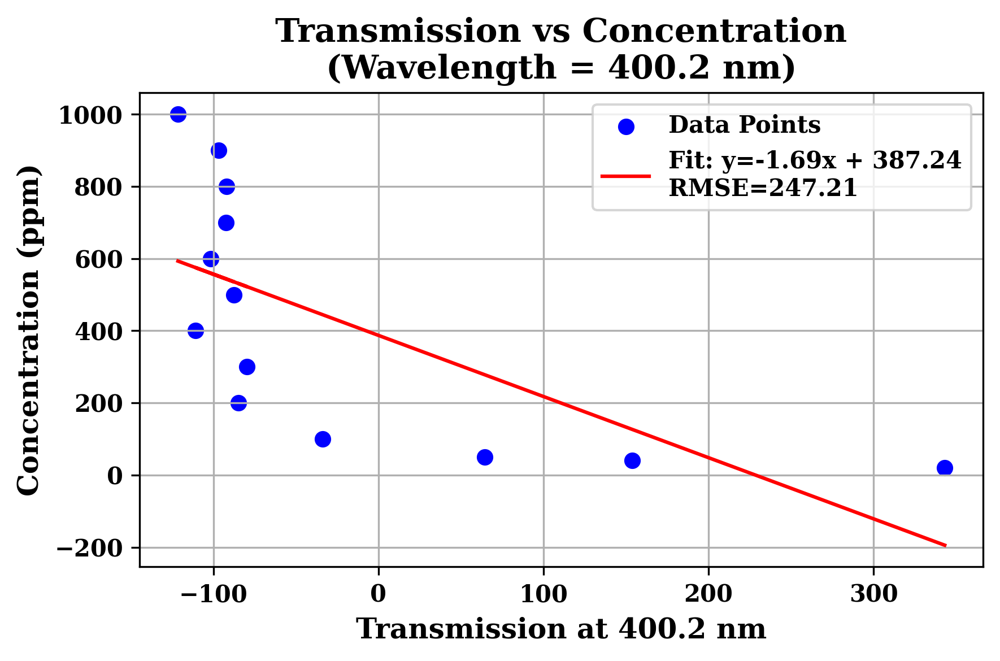

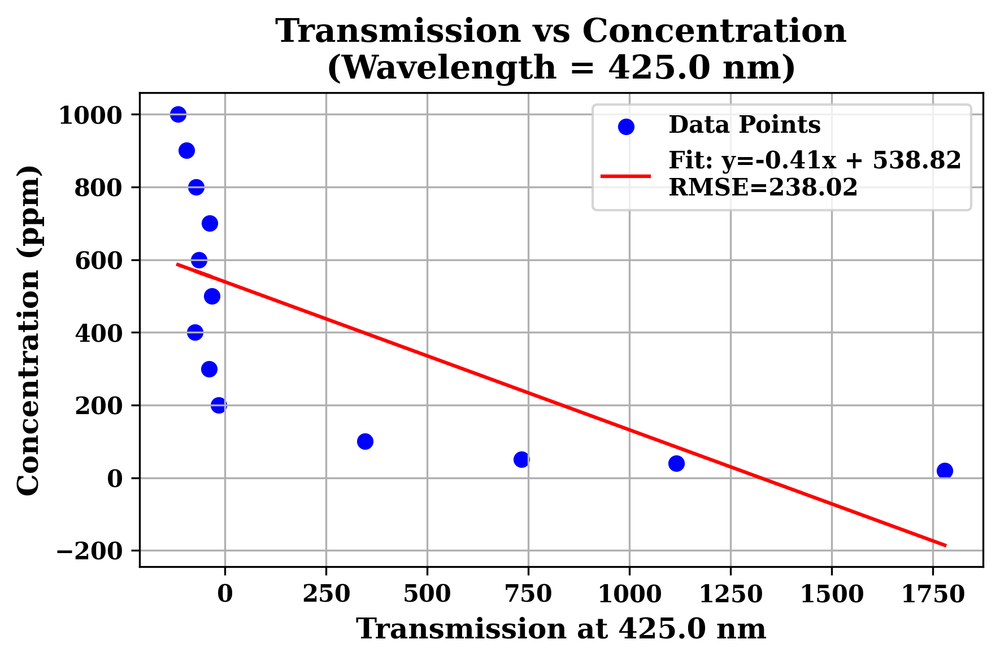

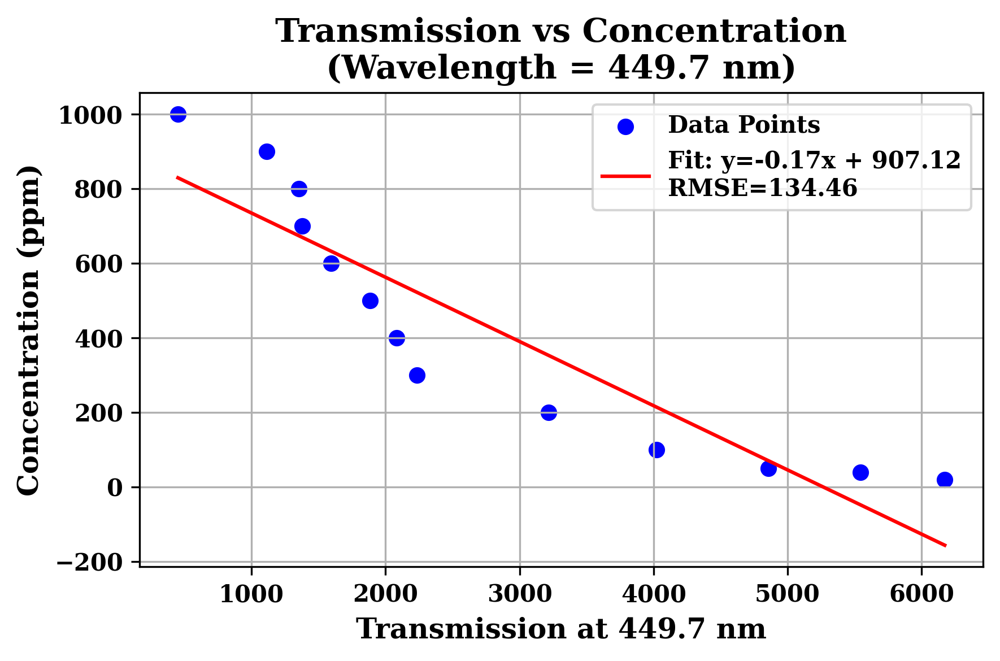

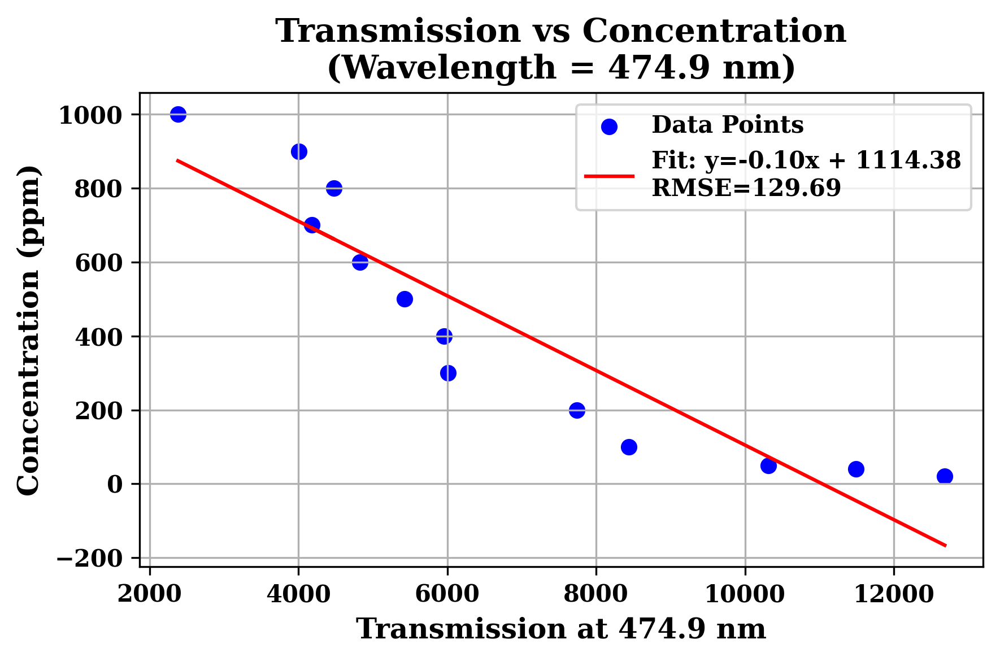

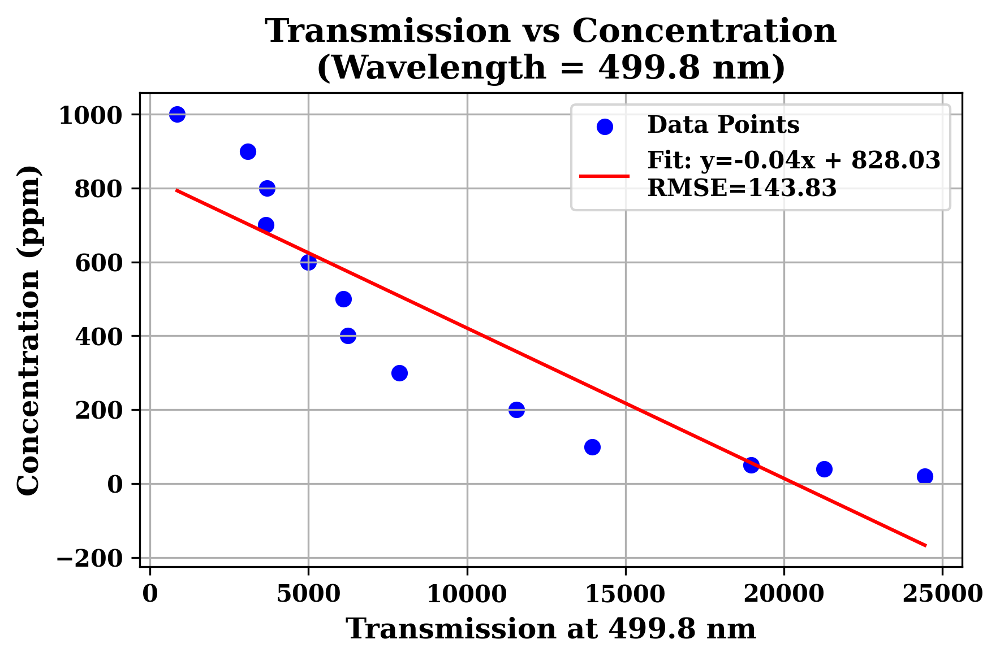

...

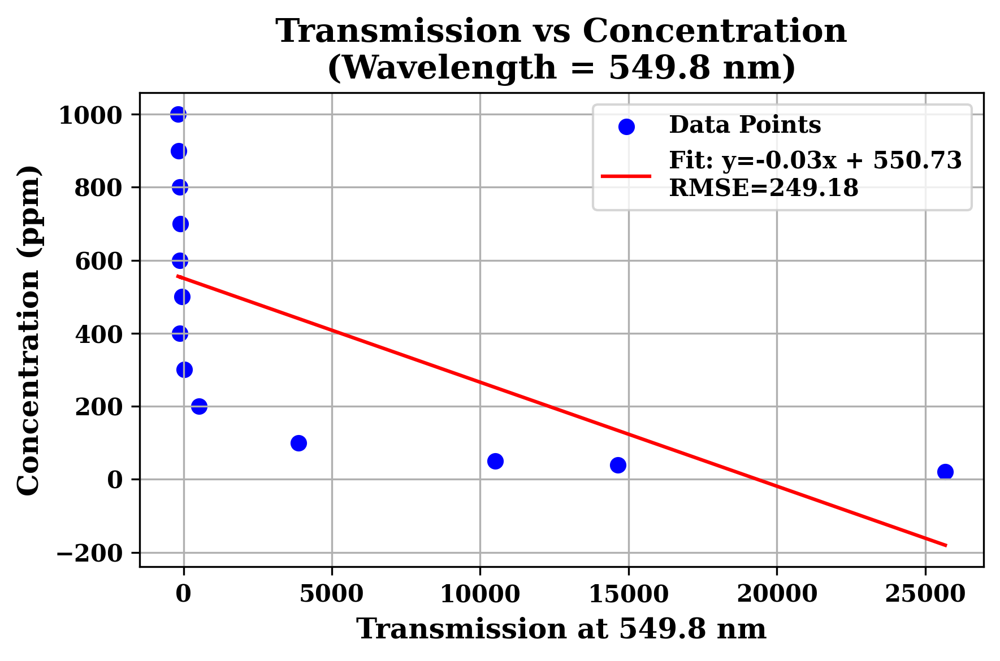

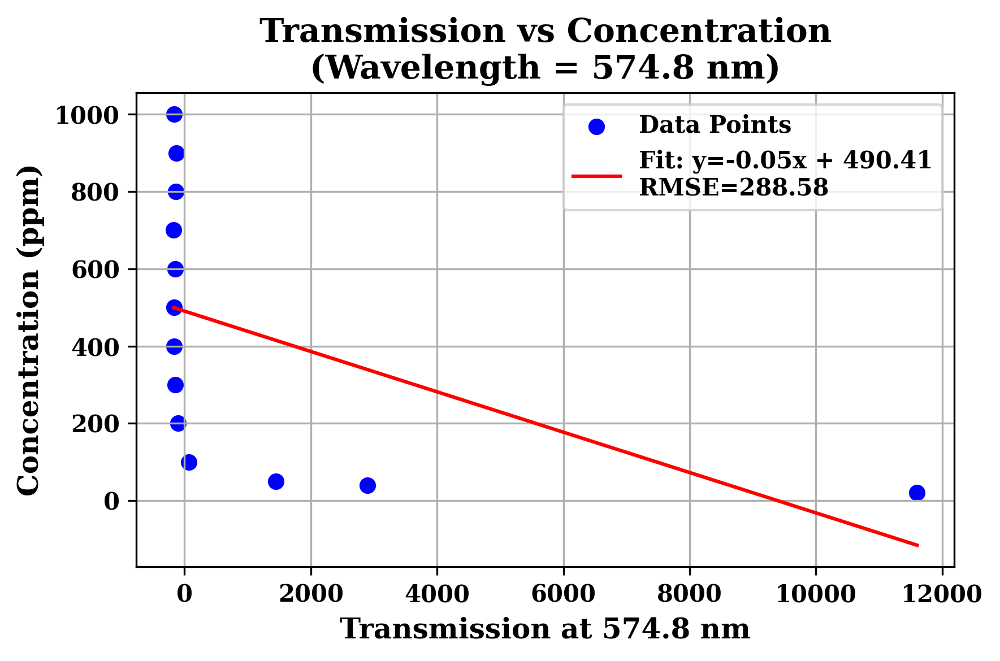

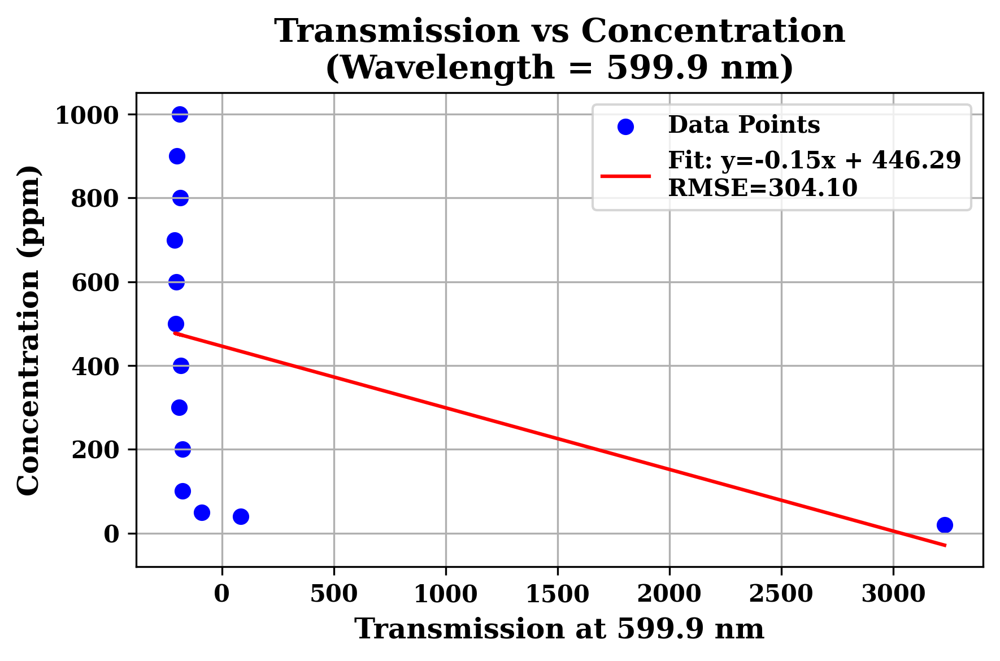

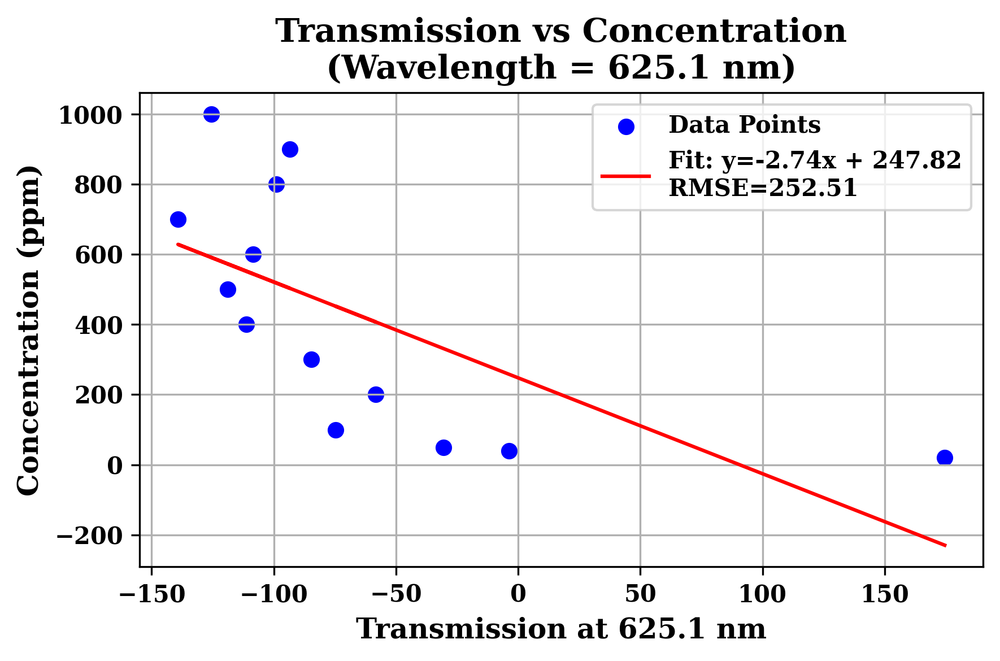

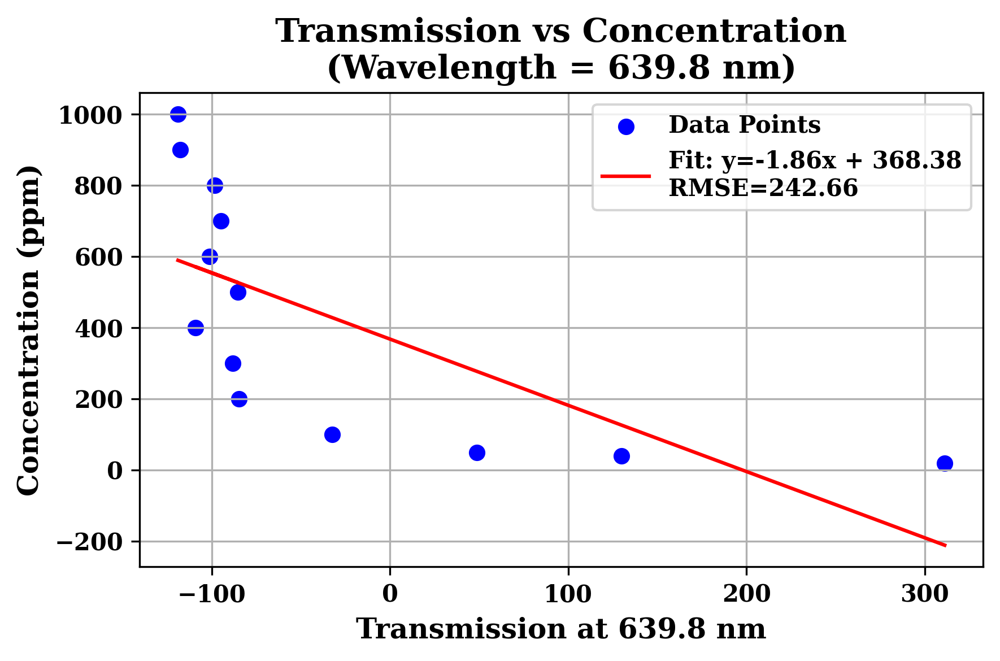

✅ Done. Plots generated and saved.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# === Set font to closest to Times New Roman and bold ===
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
matplotlib.rcParams['font.weight'] = 'bold'
matplotlib.rcParams['axes.labelweight'] = 'bold'
matplotlib.rcParams['axes.titleweight'] = 'bold'

# === Load the sorted transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X (wavelengths) and y (concentration) ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Wavelengths in the dataset ===
wavelengths = [float(col) for col in X.columns]

# === Define special wavelengths every 25 nm starting from 400 nm ===
special_wavelengths = list(np.arange(400, 650 + 1, 25))

# === Set up a DataFrame to save data ===
save_data = []

# === Plotting ===
for wl in special_wavelengths:
    # Find the closest available wavelength
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    if wl_col not in df.columns:
        print(f"⚠️ Skipping {wl_col} nm because not found in data.")
        continue

    # Prepare x and y for Linear Regression
    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)

    coef = model.coef_[0]
    intercept = model.intercept_

    rmse = np.sqrt(mean_squared_error(y_plot, y_pred))

    # Save the data
    for x_val, y_val, y_fit in zip(X_plot.flatten(), y_plot, y_pred):
        save_data.append({
            "wavelength": closest_wl,
            "transmission": x_val,
            "concentration": y_val,
            "predicted_concentration": y_fit,
            "coef": coef,
            "intercept": intercept,
            "rmse": rmse
        })

    # === Plot ===
    plt.figure(figsize=(6, 4), dpi=300)  # High-quality
    plt.scatter(X_plot, y_plot, label="Data Points", color="blue")
    plt.plot(X_plot, y_pred, color="red", label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}")
    plt.xlabel(f"Transmission at {closest_wl:.1f} nm", fontsize=12, weight='bold')
    plt.ylabel("Concentration (ppm)", fontsize=12, weight='bold')
    plt.title(f"Transmission vs Concentration\n(Wavelength = {closest_wl:.1f} nm)", fontsize=14, weight='bold')
    plt.legend(fontsize=10)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# === Save all the data into a file ===
save_df = pd.DataFrame(save_data)
save_df.to_csv("trans_vs_conc_fit_data_with_rmse.csv", index=False)

print("✅ Done. Plots generated and saved.")


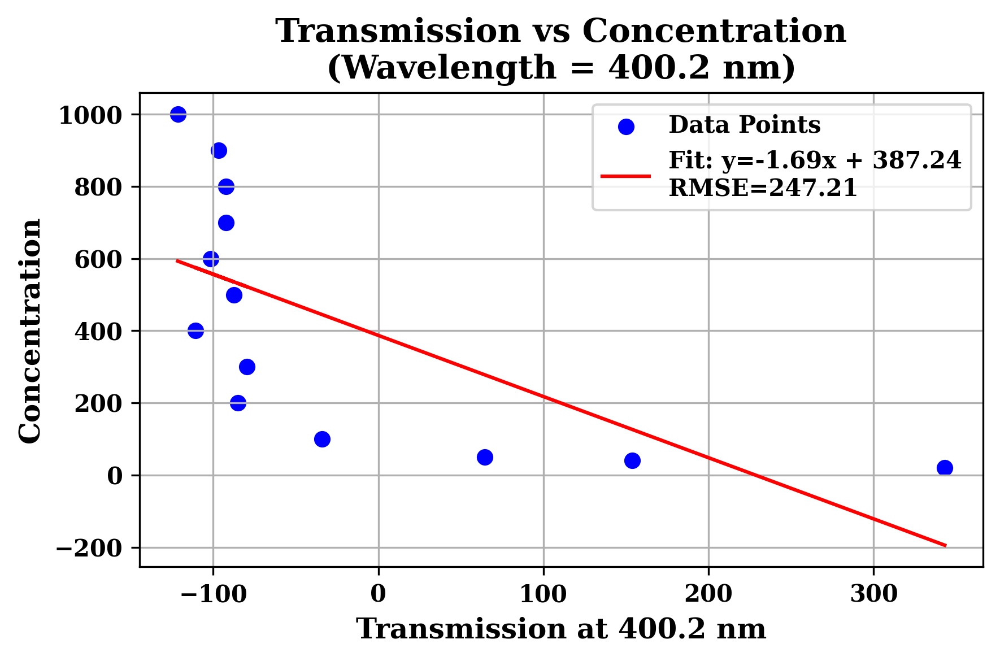

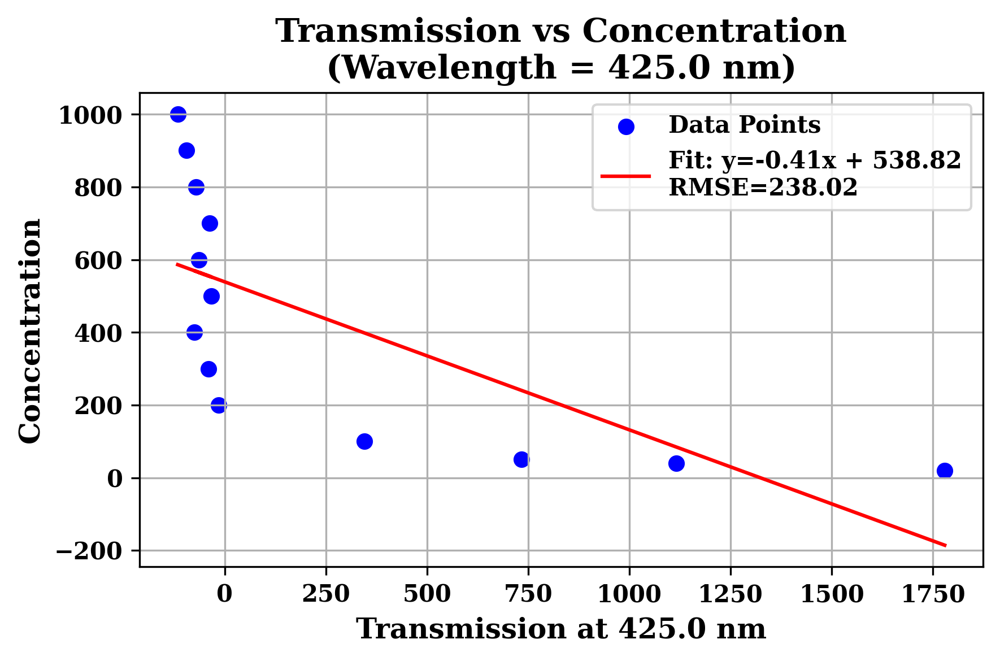

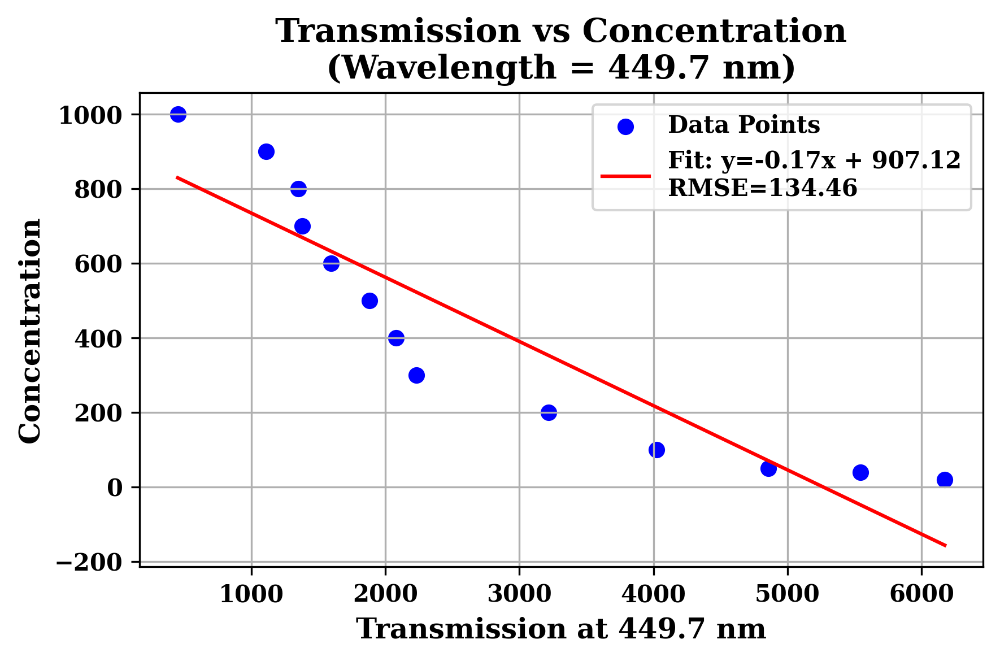

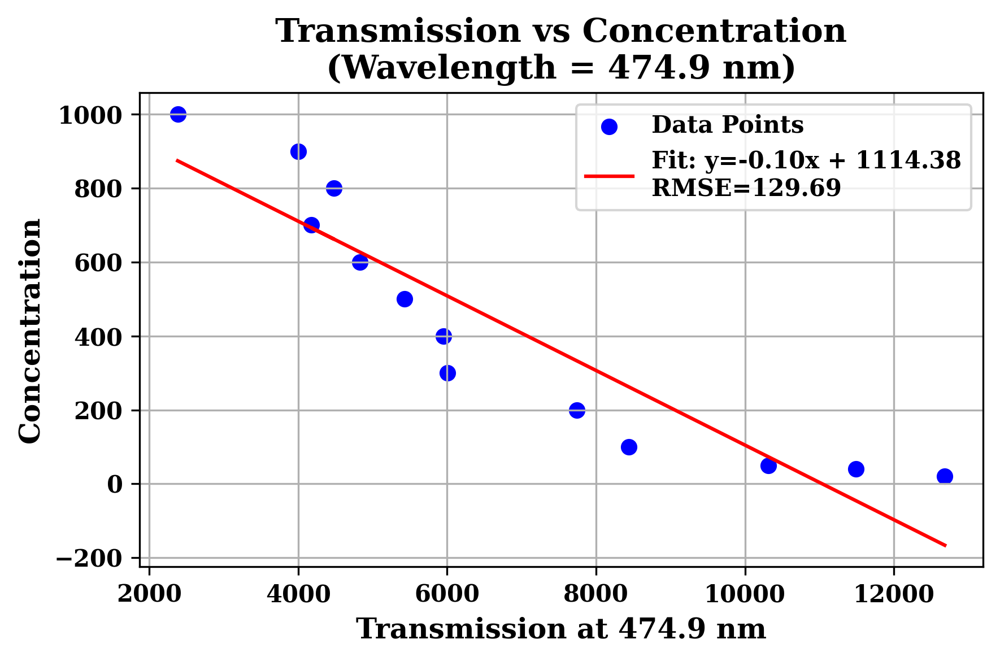

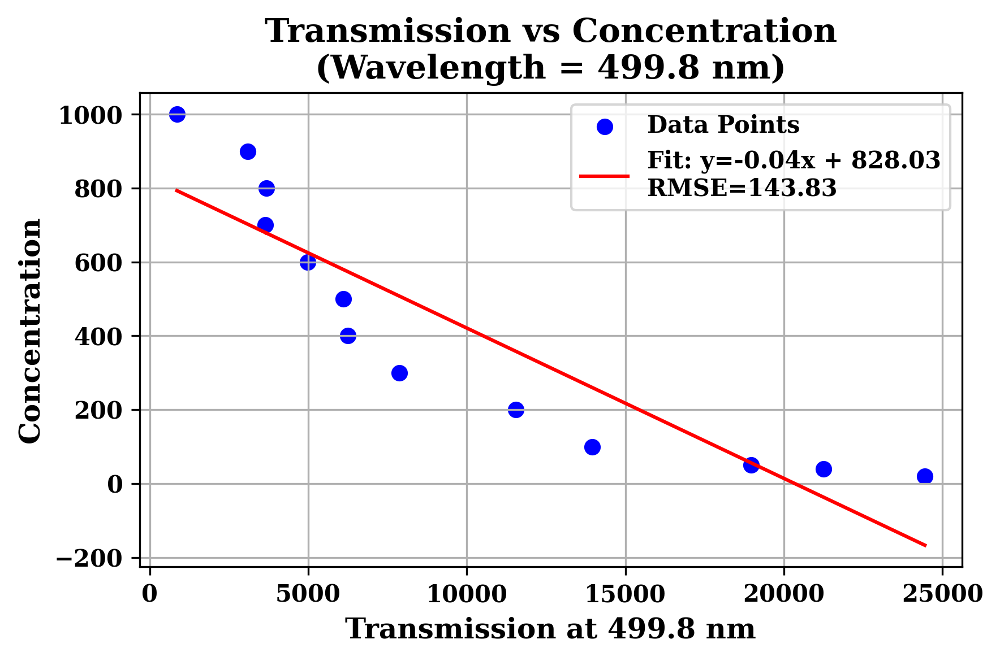

...

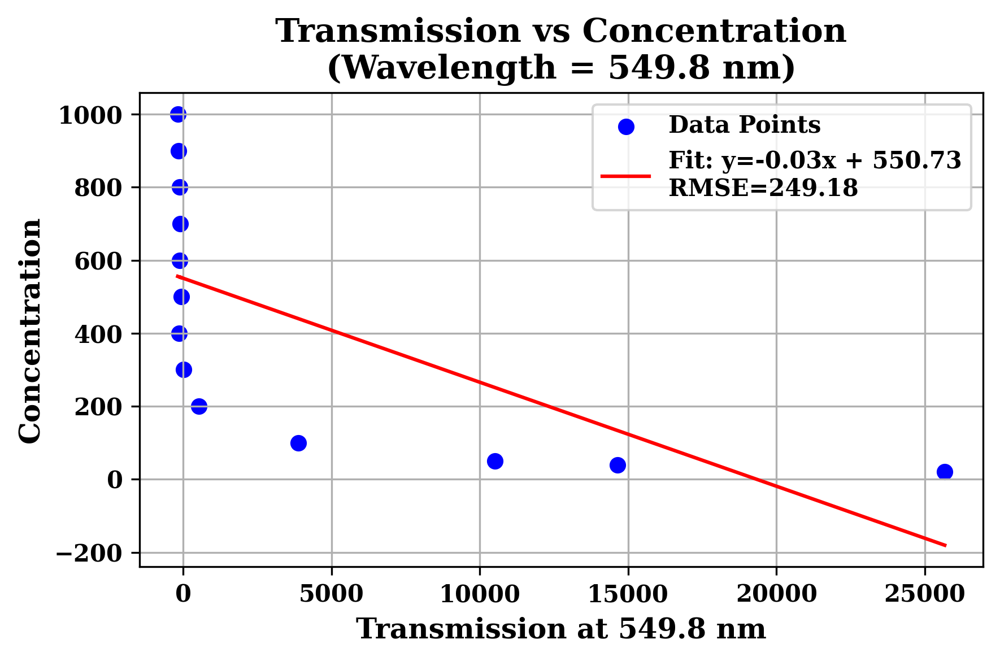

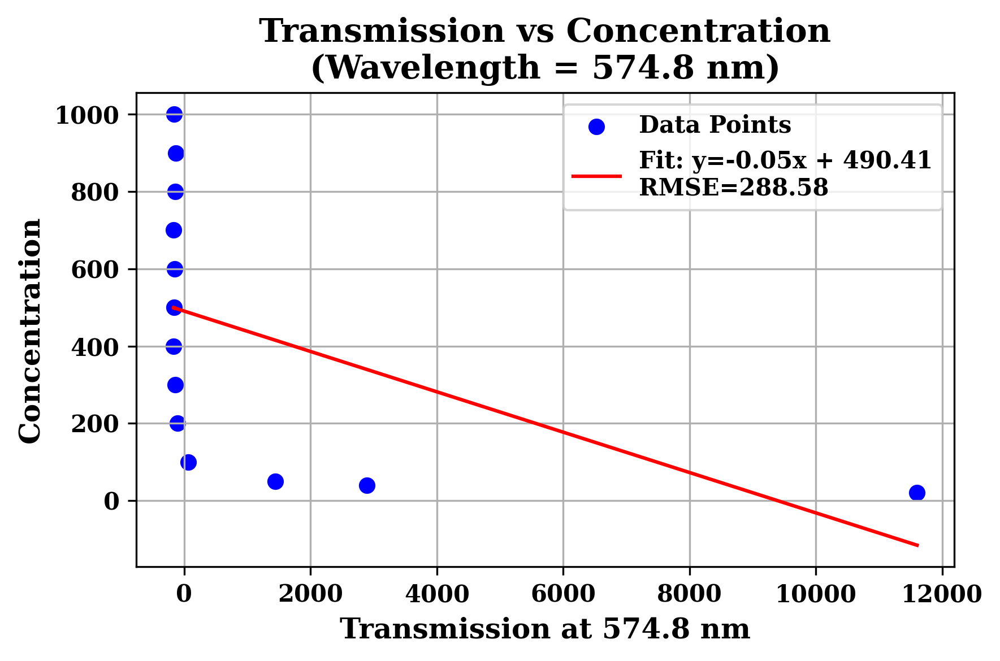

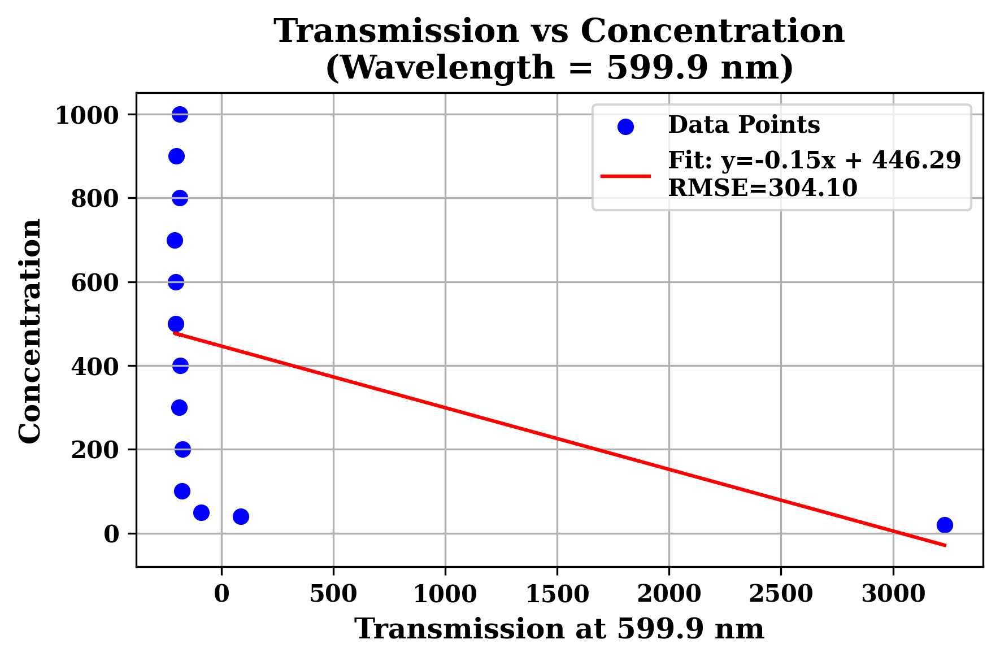

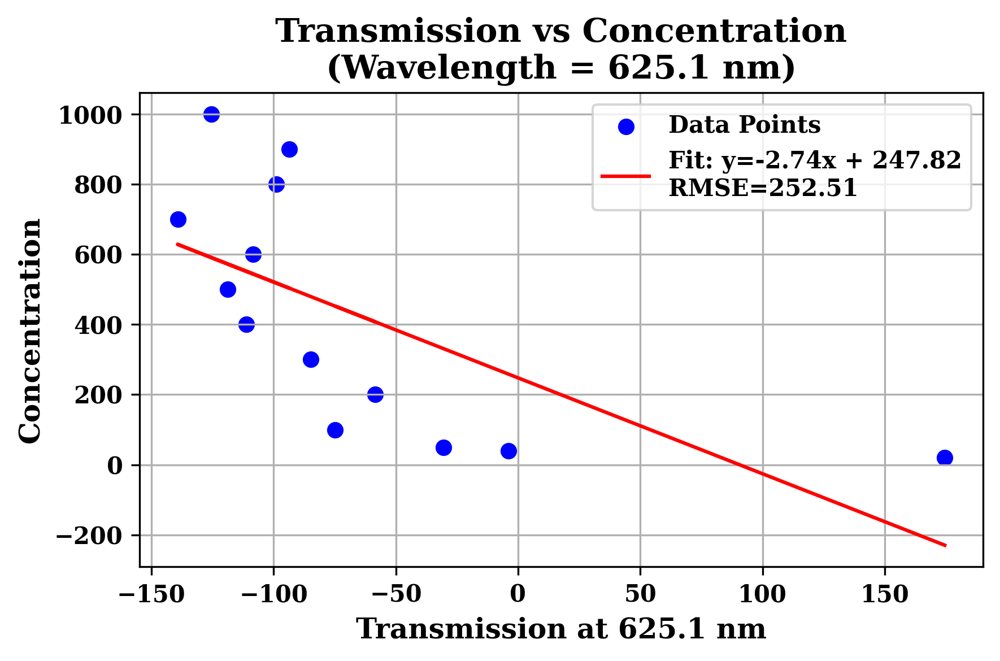

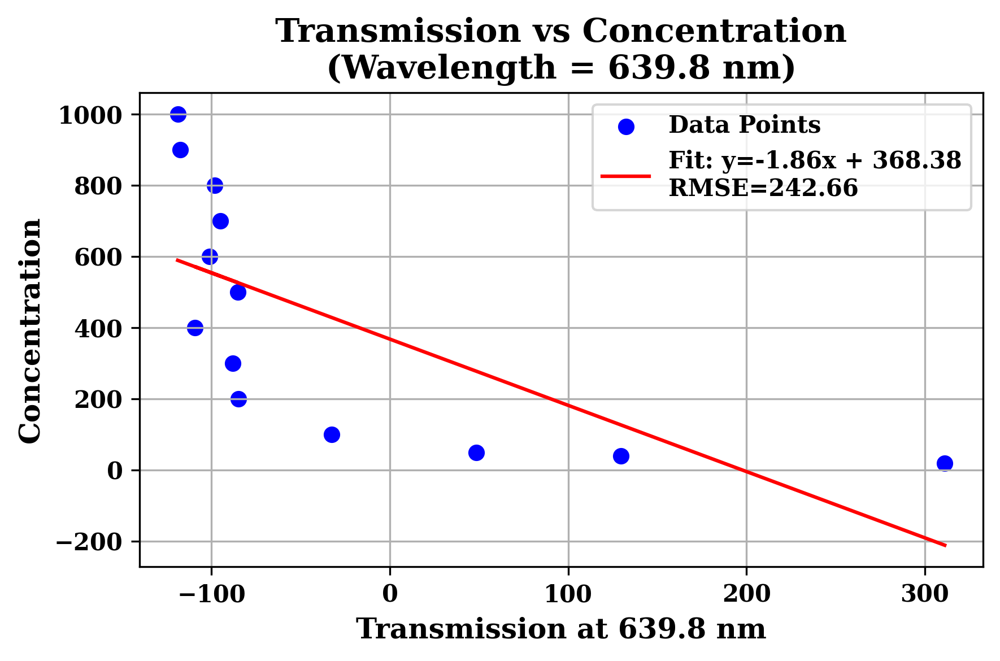

✅ Done. Plots generated and saved.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# === Set font to closest to Times New Roman and bold ===
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
matplotlib.rcParams['font.weight'] = 'bold'
matplotlib.rcParams['axes.labelweight'] = 'bold'
matplotlib.rcParams['axes.titleweight'] = 'bold'

# === Load the sorted transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X (wavelengths) and y (concentration) ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Wavelengths in the dataset ===
wavelengths = [float(col) for col in X.columns]

# === Define special wavelengths every 25 nm starting from 400 nm ===
special_wavelengths = list(np.arange(400, 650 + 1, 25))

# === Set up a DataFrame to save data ===
save_data = []

# === Plotting ===
for wl in special_wavelengths:
    # Find the closest available wavelength
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    if wl_col not in df.columns:
        print(f"⚠️ Skipping {wl_col} nm because not found in data.")
        continue

    # Prepare x and y for Linear Regression
    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)

    coef = model.coef_[0]
    intercept = model.intercept_
    rmse = np.sqrt(mean_squared_error(y_plot, y_pred))

    # Save the data
    for x_val, y_val, y_fit in zip(X_plot.flatten(), y_plot, y_pred):
        save_data.append({
            "wavelength": closest_wl,
            "transmission": x_val,
            "concentration": y_val,
            "predicted_concentration": y_fit,
            "coef": coef,
            "intercept": intercept,
            "rmse": rmse
        })

    # === Plot ===
    plt.figure(figsize=(6, 4), dpi=300)  # High-quality
    plt.scatter(X_plot, y_plot, label="Data Points", color="blue")
    plt.plot(X_plot, y_pred, color="red", label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}")
    plt.xlabel(f"Transmission at {closest_wl:.1f} nm", fontsize=12, weight='bold')
    plt.ylabel("Concentration", fontsize=12, weight='bold')  # <-- fixed: no (ppm)
    plt.title(f"Transmission vs Concentration\n(Wavelength = {closest_wl:.1f} nm)", fontsize=14, weight='bold')
    plt.legend(fontsize=10)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# === Save all the data into a file ===
save_df = pd.DataFrame(save_data)
save_df.to_csv("trans_vs_conc_fit_data_with_rmse.csv", index=False)

print("✅ Done. Plots generated and saved.")


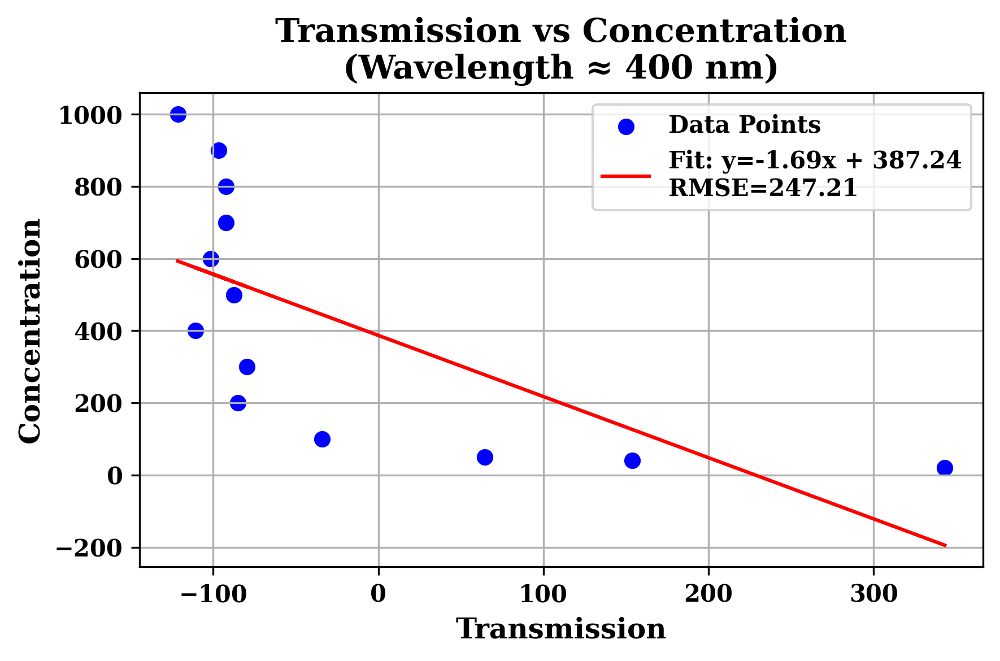

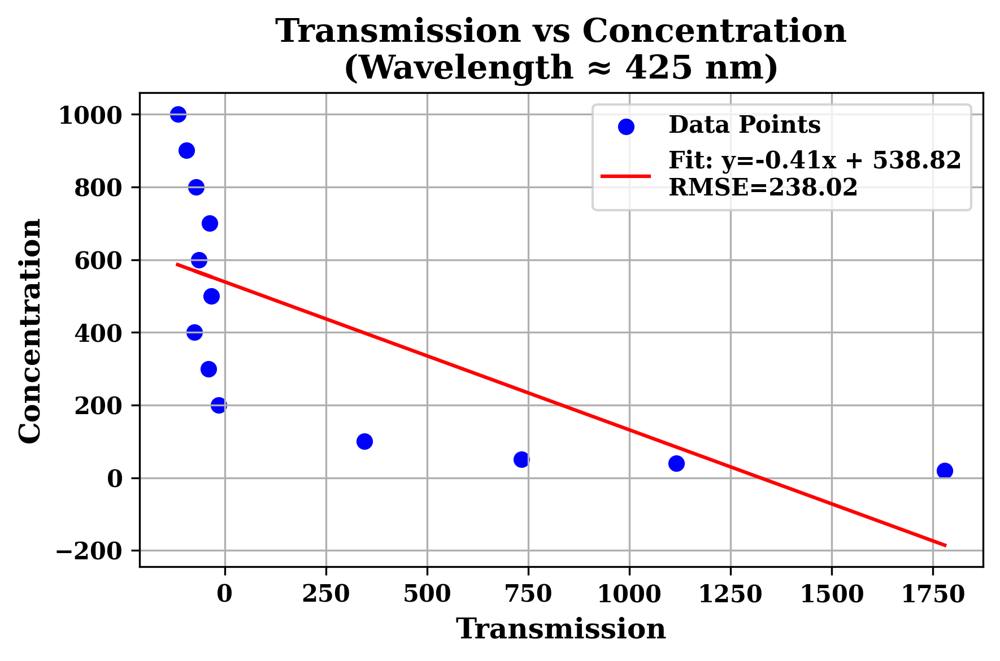

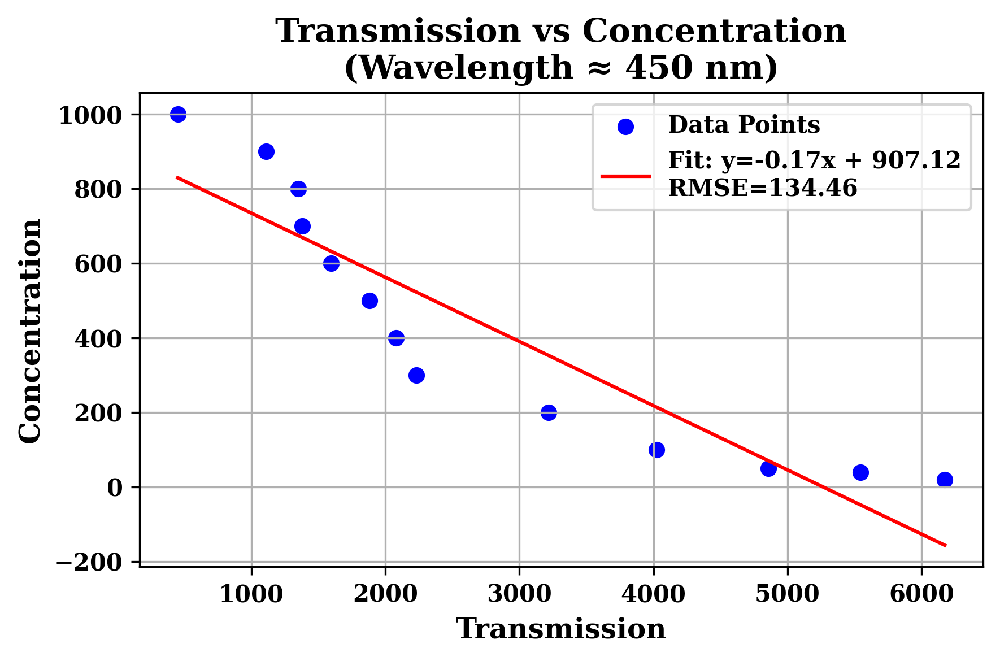

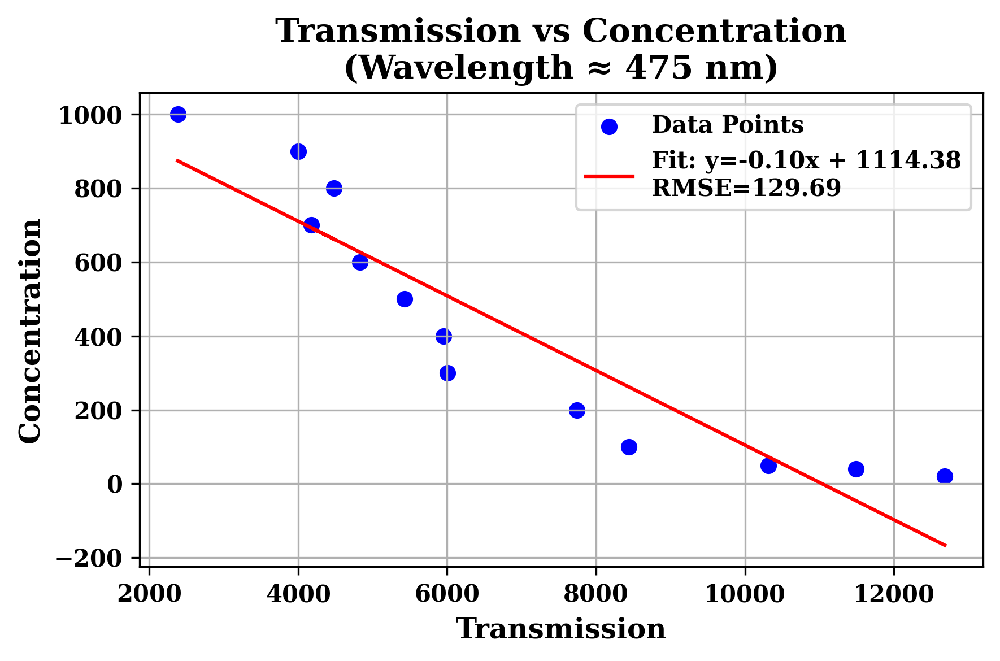

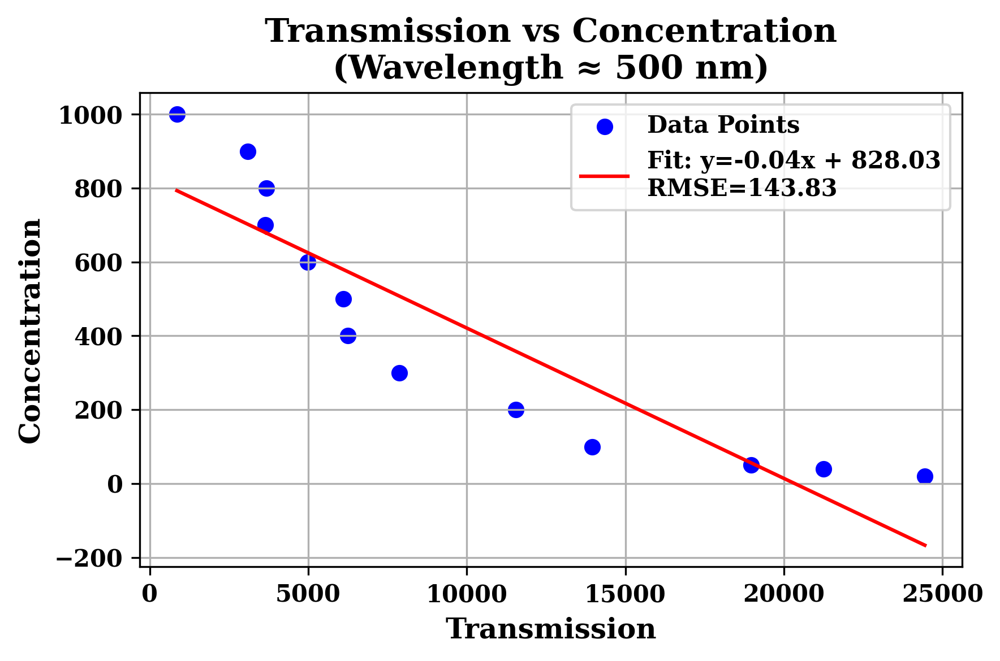

...

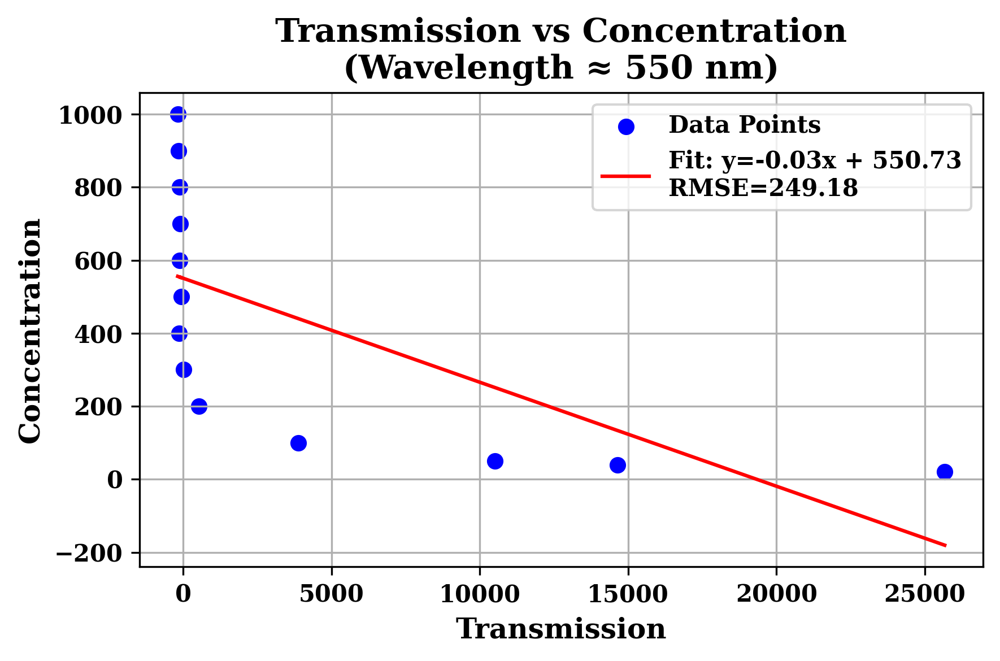

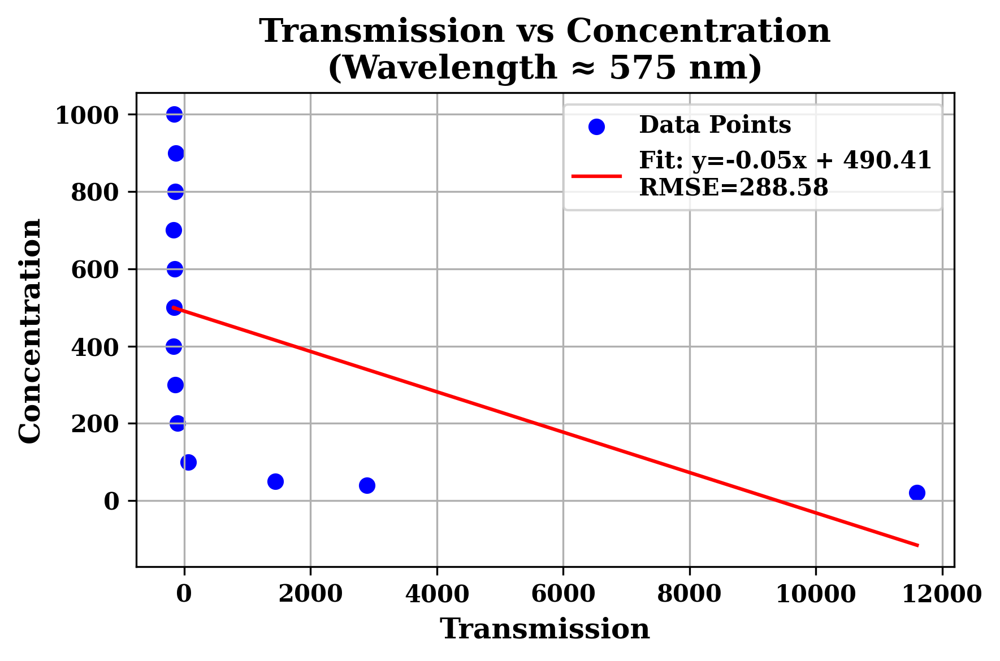

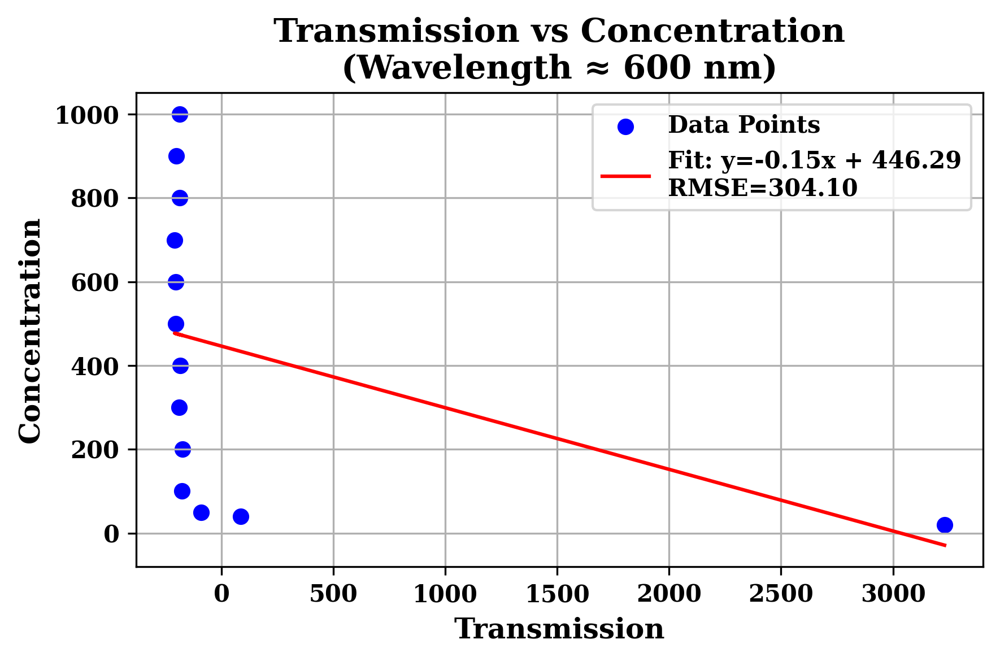

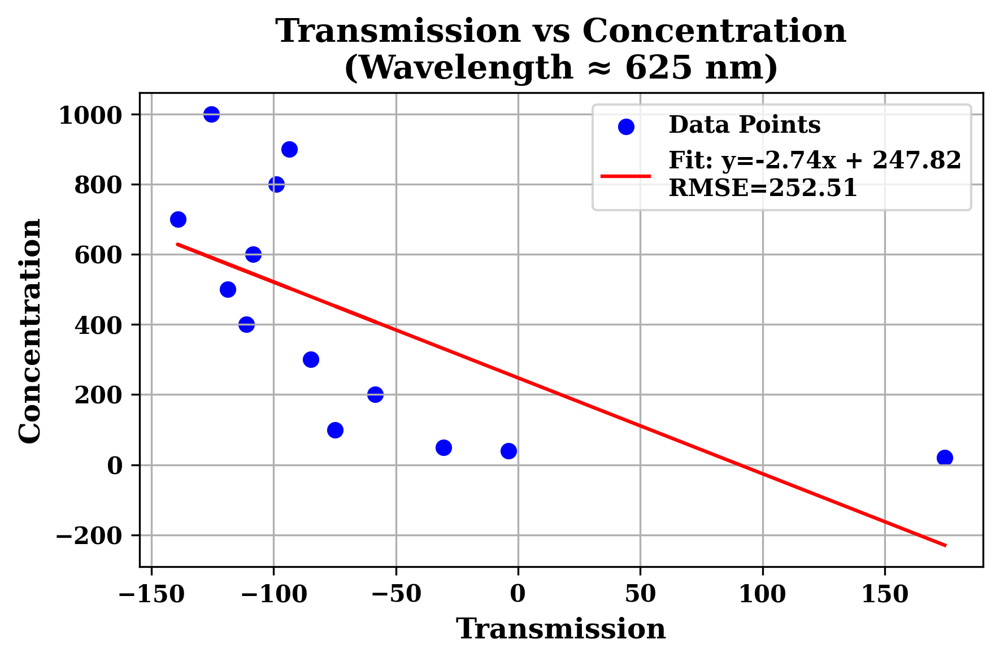

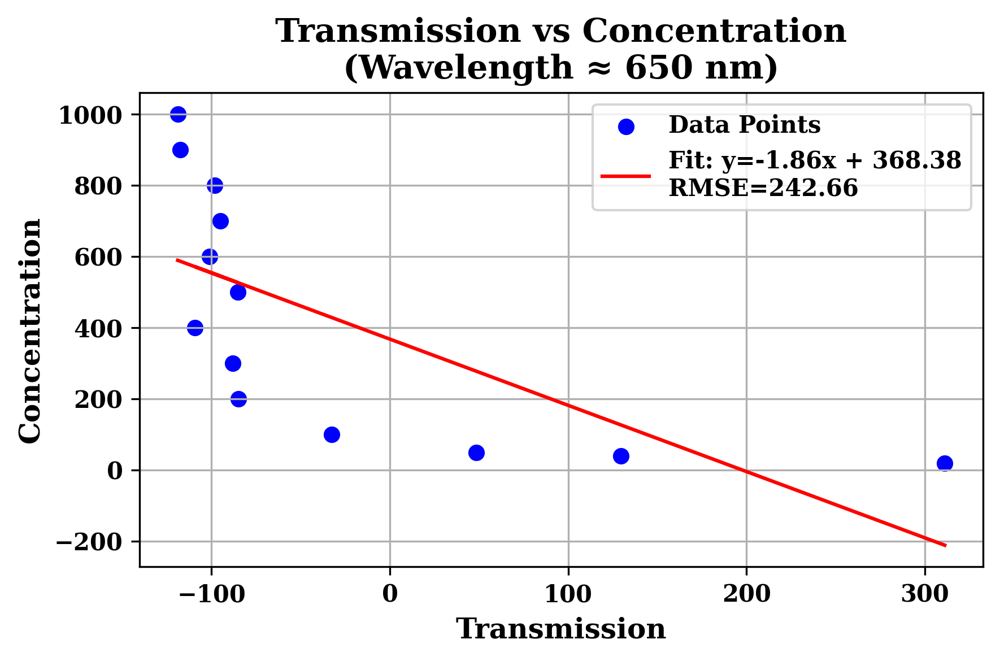

✅ Done. Plots generated and saved.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# === Set font to closest to Times New Roman and bold ===
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
matplotlib.rcParams['font.weight'] = 'bold'
matplotlib.rcParams['axes.labelweight'] = 'bold'
matplotlib.rcParams['axes.titleweight'] = 'bold'

# === Load the sorted transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X (wavelengths) and y (concentration) ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Wavelengths in the dataset ===
wavelengths = [float(col) for col in X.columns]

# === Define special wavelengths every 25 nm starting from 400 nm ===
special_wavelengths = list(np.arange(400, 650 + 1, 25))

# === Set up a DataFrame to save data ===
save_data = []

# === Plotting ===
for wl in special_wavelengths:
    # Find the closest available wavelength
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    if wl_col not in df.columns:
        print(f"⚠️ Skipping {wl_col} nm because not found in data.")
        continue

    # Prepare x and y for Linear Regression
    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)

    coef = model.coef_[0]
    intercept = model.intercept_
    rmse = np.sqrt(mean_squared_error(y_plot, y_pred))

    # === Plot ===
    plt.figure(figsize=(6, 4), dpi=300)  # High-quality
    plt.scatter(X_plot, y_plot, label="Data Points", color="blue")
    plt.plot(X_plot, y_pred, color="red", label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}")
    plt.xlabel("Transmission", fontsize=12, weight='bold')  # <=== CHANGED
    plt.ylabel("Concentration", fontsize=12, weight='bold')  # Already without units
    plt.title(f"Transmission vs Concentration\n(Wavelength ≈ {int(round(wl))} nm)", fontsize=14, weight='bold')  # <=== CHANGED
    plt.legend(fontsize=10)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# === Save all the data into a file ===
save_df = pd.DataFrame(save_data)
save_df.to_csv("trans_vs_conc_fit_data_with_rmse.csv", index=False)

print("✅ Done. Plots generated and saved.")


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Set global font to closest Times New Roman with bold ===
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
plt.rcParams['font.weight'] = 'bold'

# === Load the sorted transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X (wavelengths) and y (concentration) ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Wavelengths in the dataset ===
wavelengths = [float(col) for col in X.columns]

# === MSE Data ===
mse_df = pd.read_csv("mse_per_wavelength_with_std.csv")
mse_df["rmse"] = np.sqrt(mse_df["mse"])

# === Identify best and worst wavelength ===
best_wavelength = mse_df.loc[mse_df["mse"].idxmin(), "wavelength"]
worst_wavelength = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

# === Define special wavelengths every 25 nm starting from 400 nm ===
special_wavelengths = list(np.arange(400, 651, 25))  # 651 to include 650
if best_wavelength not in special_wavelengths:
    special_wavelengths.append(best_wavelength)
if worst_wavelength not in special_wavelengths:
    special_wavelengths.append(worst_wavelength)
special_wavelengths = sorted(special_wavelengths)

# === Set up a DataFrame to save data ===
save_data = []

# === Plotting ===
for wl in special_wavelengths:
    # Find the closest available wavelength
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    if wl_col not in df.columns:
        print(f"⚠️ Skipping {wl_col} nm because not found in data.")
        continue

    # Prepare x and y for Linear Regression
    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)

    coef = model.coef_[0]
    intercept = model.intercept_
    rmse = np.sqrt(mean_squared_error(y_plot, y_pred))

    # Save the data
    for x_val, y_val, y_fit in zip(X_plot.flatten(), y_plot, y_pred):
        save_data.append({
            "wavelength": closest_wl,
            "transmission": x_val,
            "concentration": y_val,
            "predicted_concentration": y_fit,
            "coef": coef,
            "intercept": intercept,
            "rmse": rmse
        })

    # === Plot ===
    plt.figure(figsize=(6, 4), dpi=300)  # 300 dpi for high quality
    plt.scatter(X_plot, y_plot, label="Data Points", color="blue")
    plt.plot(X_plot, y_pred, color="red", label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}")
    plt.xlabel(f"Transmission at {closest_wl:.1f} nm", fontsize=12, fontweight='bold')
    plt.ylabel("Concentration (ppm)", fontsize=12, fontweight='bold')
    plt.title(f"Transmission vs Concentration\n(Wavelength = {closest_wl:.1f} nm)", fontsize=14, fontweight='bold')
    plt.legend(fontsize=10)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# === Save all the data into a file ===
save_df = pd.DataFrame(save_data)
save_df.to_csv("trans_vs_conc_fit_data_with_rmse.csv", index=False)

print("✅ Done. Plots generated and data saved as 'trans_vs_conc_fit_data_with_rmse.csv'.")


FileNotFoundError: [Errno 2] No such file or directory: 'mse_per_wavelength_with_std.csv'

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

# === Load the sorted transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X (wavelengths) and y (concentration) ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Wavelengths in the dataset ===
wavelengths = [float(col) for col in X.columns]

# === MSE Data ===
mse_df = pd.read_csv("/mnt/data/mse_per_wavelength_with_std.csv")
mse_df["rmse"] = np.sqrt(mse_df["mse"])

# === Identify best and worst wavelength ===
best_wavelength = mse_df.loc[mse_df["mse"].idxmin(), "wavelength"]
worst_wavelength = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

# === Define special wavelengths every 25 nm starting from 400 nm ===
special_wavelengths = list(np.arange(400, 650 + 1, 25))
if best_wavelength not in special_wavelengths:
    special_wavelengths.append(best_wavelength)
if worst_wavelength not in special_wavelengths:
    special_wavelengths.append(worst_wavelength)
special_wavelengths = sorted(special_wavelengths)

# === Set up a DataFrame to save data ===
save_data = []

# === Create output folder ===
output_folder = "/mnt/data/generated_plots"
os.makedirs(output_folder, exist_ok=True)

# === Plotting ===
for idx, wl in enumerate(special_wavelengths):
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    if wl_col not in df.columns:
        print(f"⚠️ Skipping {wl_col} nm because not found in data.")
        continue

    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)

    coef = model.coef_[0]
    intercept = model.intercept_

    rmse = np.sqrt(mean_squared_error(y_plot, y_pred))

    for x_val, y_val, y_fit in zip(X_plot.flatten(), y_plot, y_pred):
        save_data.append({
            "wavelength": closest_wl,
            "transmission": x_val,
            "concentration": y_val,
            "predicted_concentration": y_fit,
            "coef": coef,
            "intercept": intercept,
            "rmse": rmse
        })

    # === Plot ===
    plt.figure(figsize=(6, 4))
    plt.rcParams['font.family'] = 'serif'  # closest to Times New Roman
    plt.scatter(X_plot, y_plot, label="Data Points", color="blue")
    plt.plot(X_plot, y_pred, color="red", label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}")
    plt.xlabel(f"Transmission at {closest_wl:.1f} nm", fontsize=12, weight='bold')
    plt.ylabel("Concentration (ppm)", fontsize=12, weight='bold')
    plt.title(f"Transmission vs Concentration\n(Wavelength = {closest_wl:.1f} nm)", fontsize=14, weight='bold')
    plt.legend(fontsize=10)
    plt.grid(True)
    plt.tight_layout()

    plot_path = os.path.join(output_folder, f"plot_{idx+1}_{closest_wl:.1f}nm.png")
    plt.savefig(plot_path, dpi=300)
    plt.close()

# === Save all the data into a file ===
save_df = pd.DataFrame(save_data)
save_df.to_csv("/mnt/data/trans_vs_conc_fit_data_with_rmse.csv", index=False)

# === Create a zip file ===
zip_path = "/mnt/data/generated_plots.zip"
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for filename in os.listdir(output_folder):
        file_path = os.path.join(output_folder, filename)
        zipf.write(file_path, arcname=filename)

print("✅ All plots saved and zipped! Download ready: 'generated_plots.zip'.")


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/mse_per_wavelength_with_std.csv'

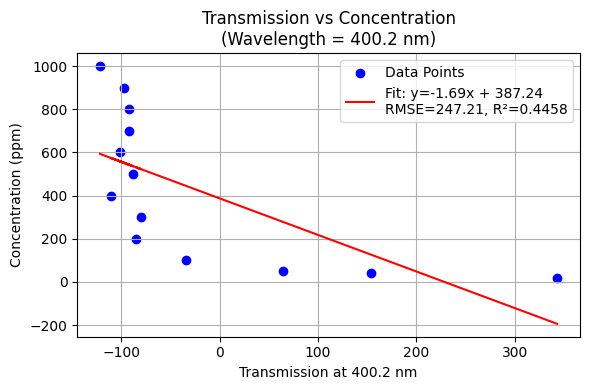

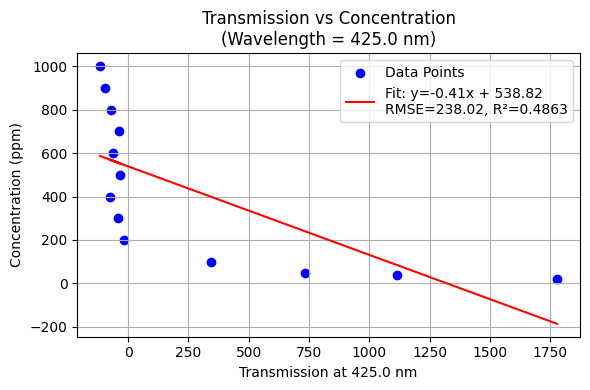

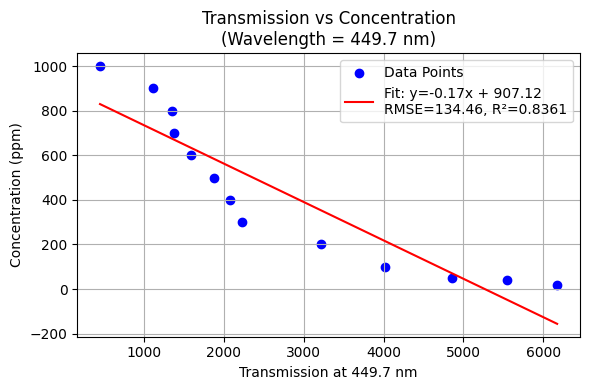

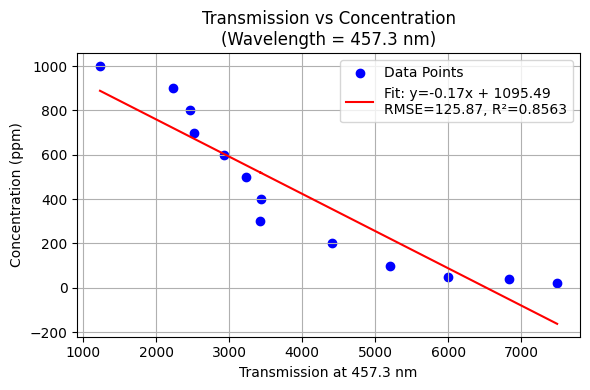

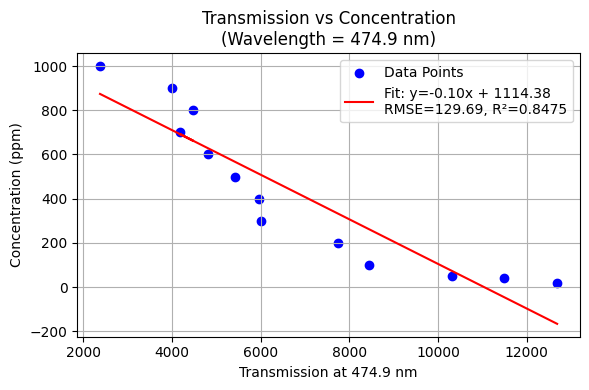

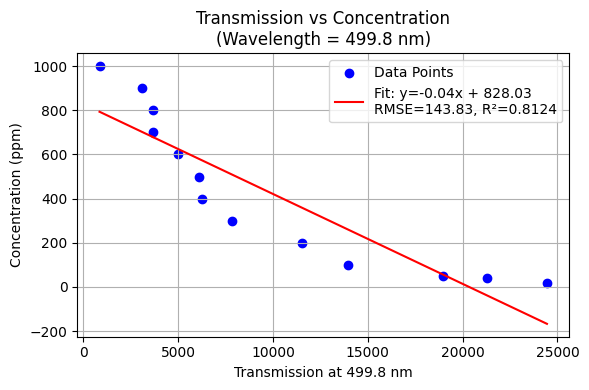

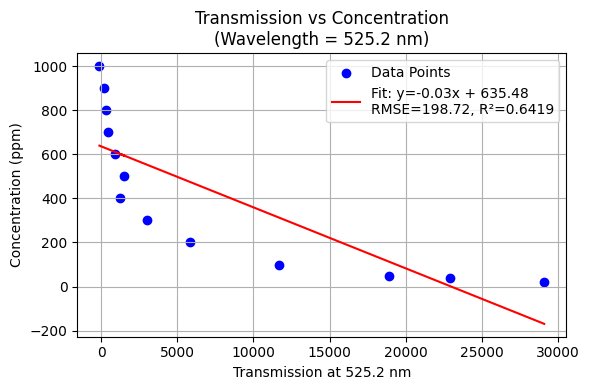

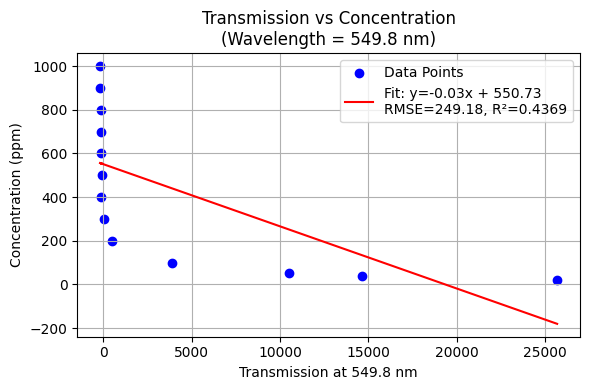

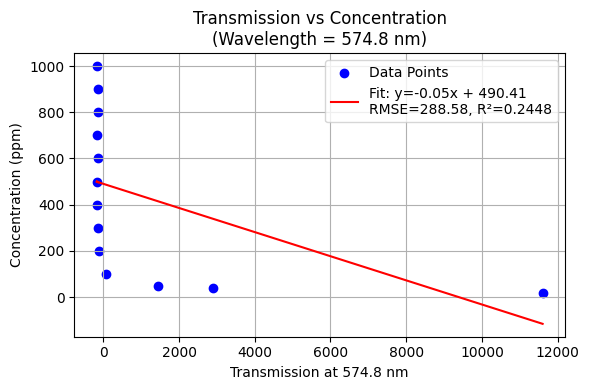

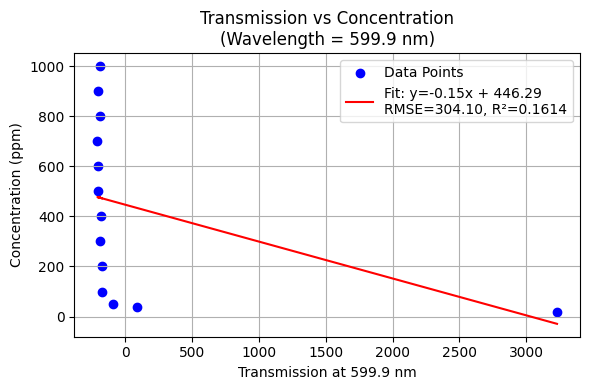

⚠️ Skipping 609.900 nm because not found in data.


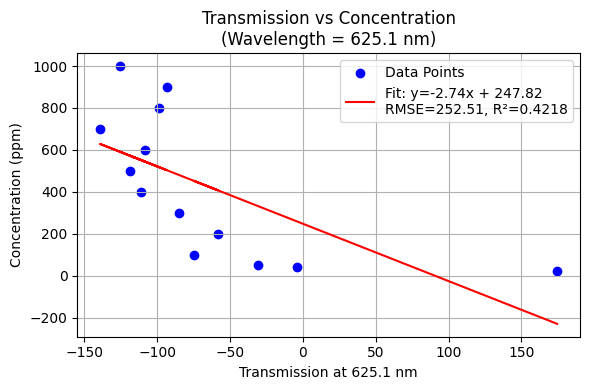

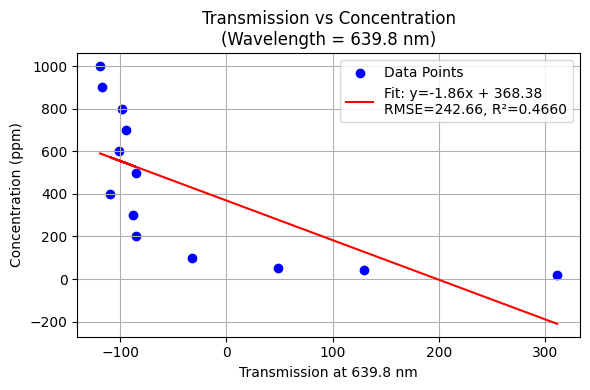

✅ Done. Plots generated and data saved as 'trans_vs_conc_fit_data_with_rmse_r2.csv'.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load the sorted transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Prepare X (wavelengths) and y (concentration) ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Wavelengths in the dataset ===
wavelengths = [float(col) for col in X.columns]

# === MSE Data ===
mse_df = pd.read_csv("mse_per_wavelength_with_std.csv")
mse_df["rmse"] = np.sqrt(mse_df["mse"])

# === Identify best and worst wavelength ===
best_wavelength = mse_df.loc[mse_df["mse"].idxmin(), "wavelength"]
worst_wavelength = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

# === Define special wavelengths every 25 nm starting from 400 nm ===
special_wavelengths = list(np.arange(400, 650 + 1, 25))
if best_wavelength not in special_wavelengths:
    special_wavelengths.append(best_wavelength)
if worst_wavelength not in special_wavelengths:
    special_wavelengths.append(worst_wavelength)
special_wavelengths = sorted(special_wavelengths)

# === Set up a DataFrame to save data ===
save_data = []

# === Plotting ===
for wl in special_wavelengths:
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    if wl_col not in df.columns:
        print(f"⚠️ Skipping {wl_col} nm because not found in data.")
        continue

    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)

    coef = model.coef_[0]
    intercept = model.intercept_

    mse = mean_squared_error(y_plot, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_plot, y_pred)

    # Save the data
    for x_val, y_val, y_fit in zip(X_plot.flatten(), y_plot, y_pred):
        save_data.append({
            "wavelength": closest_wl,
            "transmission": x_val,
            "concentration": y_val,
            "predicted_concentration": y_fit,
            "coef": coef,
            "intercept": intercept,
            "mse": mse,
            "rmse": rmse,
            "r2": r2
        })

    # === Plot ===
    plt.figure(figsize=(6, 4))
    plt.scatter(X_plot, y_plot, label="Data Points", color="blue")
    plt.plot(X_plot, y_pred, color="red", label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}, R²={r2:.4f}")
    plt.xlabel(f"Transmission at {closest_wl:.1f} nm")
    plt.ylabel("Concentration (ppm)")
    plt.title(f"Transmission vs Concentration\n(Wavelength = {closest_wl:.1f} nm)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# === Save all the data into a file ===
save_df = pd.DataFrame(save_data)
save_df.to_csv("trans_vs_conc_fit_data_with_rmse_r2.csv", index=False)

print("✅ Done. Plots generated and data saved as 'trans_vs_conc_fit_data_with_rmse_r2.csv'.")


In [ ]:
# === Plotting ===
for wl in special_wavelengths:
    # Find the closest available wavelength
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    if wl_col not in df.columns:
        print(f"⚠️ Skipping {wl_col} nm because not found in data.")
        continue

    # Prepare x and y for Linear Regression
    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)

    coef = model.coef_[0]
    intercept = model.intercept_
    rmse = np.sqrt(mean_squared_error(y_plot, y_pred))

    # Save the data
    for x_val, y_val, y_fit in zip(X_plot.flatten(), y_plot, y_pred):
        save_data.append({
            "wavelength": closest_wl,
            "transmission": x_val,
            "concentration": y_val,
            "predicted_concentration": y_fit,
            "coef": coef,
            "intercept": intercept,
            "rmse": rmse
        })

    # === Define Title Wording ===
    if int(wl) % 25 == 0 and wl <= 650:
        title_wavelength = int(wl)  # Use perfect 400, 425, 450 etc.
    else:
        title_wavelength = f"{closest_wl:.1f}"  # Use actual closest value (like 457.3)

    # === Plot ===
    plt.figure(figsize=(6, 4))
    plt.scatter(X_plot, y_plot, label="Data Points", color="blue")
    plt.plot(X_plot, y_pred, color="red", label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}")
    plt.xlabel(f"Transmission at {title_wavelength} nm")
    plt.ylabel("Concentration (ppm)")
    plt.title(f"Transmission vs Concentration\n(Wavelength = {title_wavelength} nm)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


⚠️ Skipping 400.216 nm because not found in data.
⚠️ Skipping 425.045 nm because not found in data.
⚠️ Skipping 449.716 nm because not found in data.
⚠️ Skipping 474.852 nm because not found in data.
⚠️ Skipping 499.815 nm because not found in data.
⚠️ Skipping 525.217 nm because not found in data.
⚠️ Skipping 549.817 nm because not found in data.
⚠️ Skipping 574.841 nm because not found in data.
⚠️ Skipping 599.866 nm because not found in data.
⚠️ Skipping 609.900 nm because not found in data.
⚠️ Skipping 625.085 nm because not found in data.
⚠️ Skipping 639.795 nm because not found in data.


In [ ]:
import pandas as pd

mse_df = pd.read_csv("mse_per_wavelength_with_std.csv")
worst_wavelength = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

print(f"🚨 Worst MSE wavelength is: {worst_wavelength:.3f} nm")


🚨 Worst MSE wavelength is: 609.900 nm


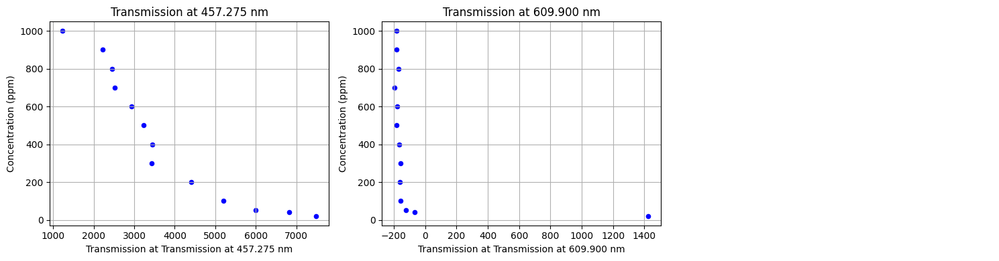

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# === Load your transmission vs concentration data ===
df = pd.read_csv('trans_vs_conc_best_and_worst.csv')

# === Prepare data ===
wavelength_columns = df.columns[1:]  # skip "Concentration (ppm)"
concentrations = df["Concentration (ppm)"].values

# === Setup figure ===
num_plots = len(wavelength_columns)
cols = 3  # 3 plots per row (you can change)
rows = int(np.ceil(num_plots / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))
axes = axes.flatten()  # flatten axes array for easy looping

# === Plot each wavelength ===
for idx, wl_col in enumerate(wavelength_columns):
    axes[idx].scatter(df[wl_col], concentrations, color='blue', s=20)
    axes[idx].set_xlabel(f"Transmission at {wl_col}")
    axes[idx].set_ylabel("Concentration (ppm)")
    axes[idx].set_title(f"{wl_col}")
    axes[idx].grid(True)

# === Turn off unused subplots ===
for j in range(idx+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib

# === Set Times New Roman (or closest match) and bold ===
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
matplotlib.rcParams['font.weight'] = 'bold'
matplotlib.rcParams['axes.labelweight'] = 'bold'
matplotlib.rcParams['axes.titleweight'] = 'bold'

# === Load the data ===
df = pd.read_csv('trans_vs_conc_best_and_worst.csv')

# === Prepare ===
wavelength_columns = df.columns[1:]  # skip concentration
concentrations = df["Concentration (ppm)"].values.reshape(-1, 1)  # Make it 2D for sklearn

# === Define best and worst wavelengths ===
best_wavelength = 457.275
worst_wavelength = 609.900

# === Function to plot each wavelength ===
def plot_fit(wavelength, save_name=None):
    # Find closest column name
    col = min(wavelength_columns, key=lambda c: abs(float(c.split(" ")[-1]) - wavelength))
    transmission = df[col].values.reshape(-1, 1)

    # Fit
    model = LinearRegression().fit(transmission, concentrations)
    concentration_pred = model.predict(transmission)

    coef = model.coef_[0][0]
    intercept = model.intercept_[0]
    rmse = np.sqrt(mean_squared_error(concentrations, concentration_pred))
    r2 = r2_score(concentrations, concentration_pred)

    # Plot
    plt.figure(figsize=(6, 4), dpi=300)
    plt.scatter(transmission, concentrations, color='blue', label="Data Points")
    plt.plot(transmission, concentration_pred, color='red',
             label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}, R²={r2:.4f}")
    plt.xlabel(f"Transmission at {wavelength:.1f} nm", fontsize=12, weight='bold')
    plt.ylabel("Concentration (ppm)", fontsize=12, weight='bold')
    plt.title(f"Transmission vs Concentration\n(Wavelength = {wavelength:.1f} nm)", fontsize=14, weight='bold')
    plt.grid(True)
    plt.legend(fontsize=10)
    plt.tight_layout()

    if save_name:
        plt.savefig(save_name, dpi=300)

    plt.show()

# === Plot best and worst ===
plot_fit(best_wavelength)
plot_fit(worst_wavelength)


FileNotFoundError: [Errno 2] No such file or directory: 'trans_vs_conc_best_and_worst.csv'

TypeError: unsupported format string passed to numpy.ndarray.__format__

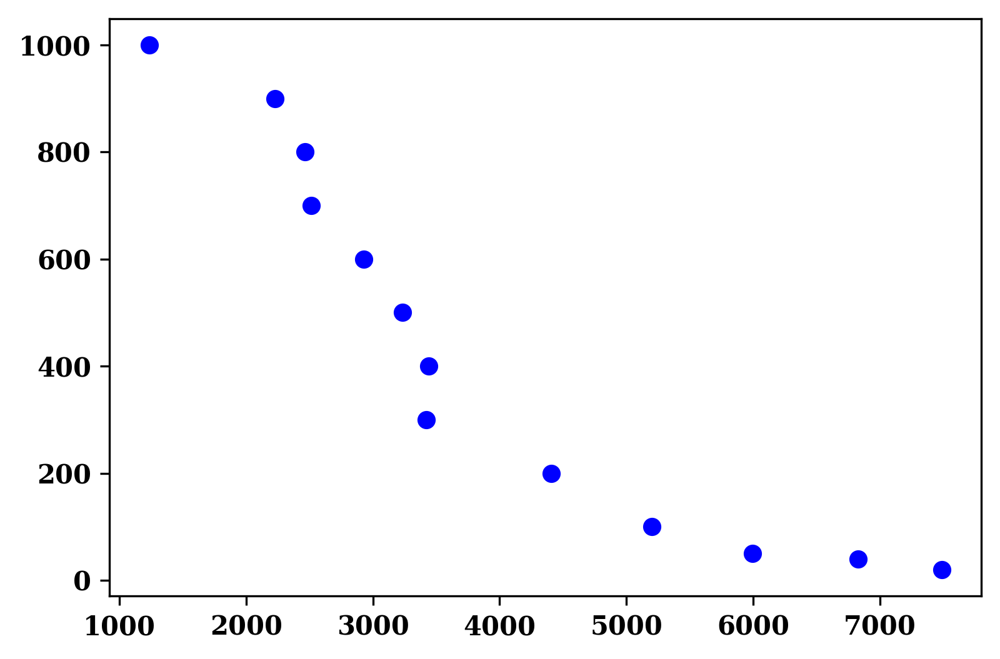

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib

# === Set Times New Roman (or closest) and bold ===
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
matplotlib.rcParams['font.weight'] = 'bold'
matplotlib.rcParams['axes.labelweight'] = 'bold'
matplotlib.rcParams['axes.titleweight'] = 'bold'

# === Load the sorted transmission data ===
df = pd.read_csv('processed_sorted_transmission.csv', index_col=0)

# === Prepare ===
wavelength_columns = df.columns
concentrations = df.index.values.reshape(-1, 1)

# === Define best and worst wavelengths ===
best_wavelength = 457.275
worst_wavelength = 609.900

# === Function to plot each wavelength ===
def plot_fit(wavelength):
    # Find closest available wavelength
    col = min(wavelength_columns, key=lambda x: abs(float(x) - wavelength))
    transmission = df[col].values.reshape(-1, 1)

    # Fit
    model = LinearRegression().fit(transmission, concentrations)
    concentration_pred = model.predict(transmission)

    coef = model.coef_[0]
    intercept = model.intercept_
    rmse = np.sqrt(mean_squared_error(concentrations, concentration_pred))
    r2 = r2_score(concentrations, concentration_pred)

    # Plot
    plt.figure(figsize=(6, 4), dpi=300)
    plt.scatter(transmission, concentrations, color='blue', label="Data Points")
    plt.plot(transmission, concentration_pred, color='red',
             label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}, R²={r2:.4f}")
    plt.xlabel(f"Transmission at {float(col):.1f} nm", fontsize=12, weight='bold')
    plt.ylabel("Concentration (ppm)", fontsize=12, weight='bold')
    plt.title(f"Transmission vs Concentration\n(Wavelength = {float(col):.1f} nm)", fontsize=14, weight='bold')
    plt.grid(True)
    plt.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

# === Plot best and worst ===
plot_fit(best_wavelength)
plot_fit(worst_wavelength)


<ipython-input-8-4f5914730d72>:36: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  coef = float(model.coef_[0])  # <-- FIXED: convert from numpy to float
<ipython-input-8-4f5914730d72>:37: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  intercept = float(model.intercept_)  # <-- FIXED


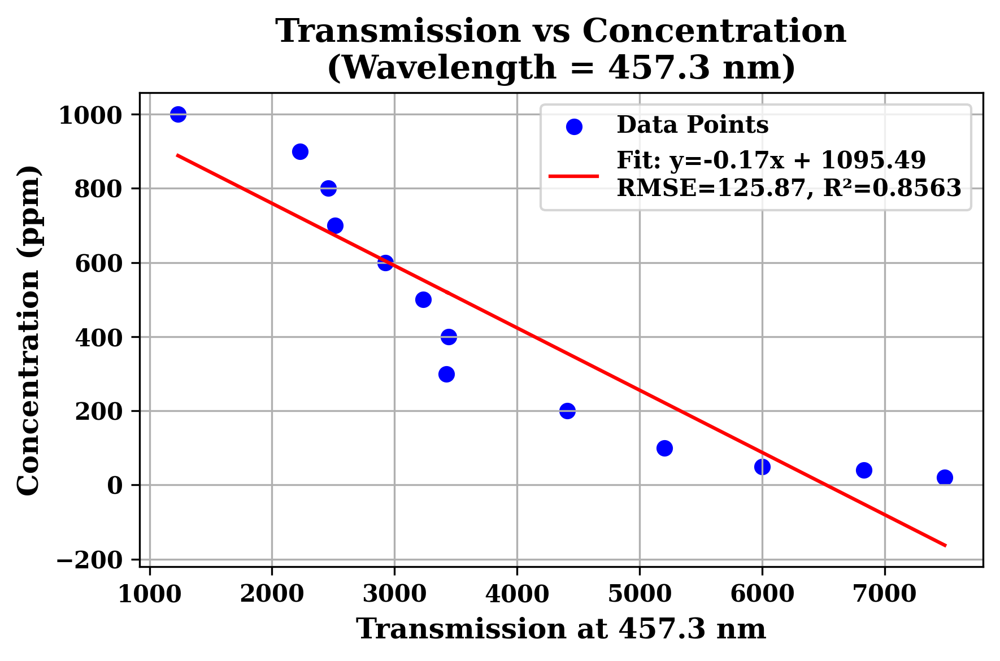

<ipython-input-8-4f5914730d72>:36: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  coef = float(model.coef_[0])  # <-- FIXED: convert from numpy to float
<ipython-input-8-4f5914730d72>:37: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  intercept = float(model.intercept_)  # <-- FIXED


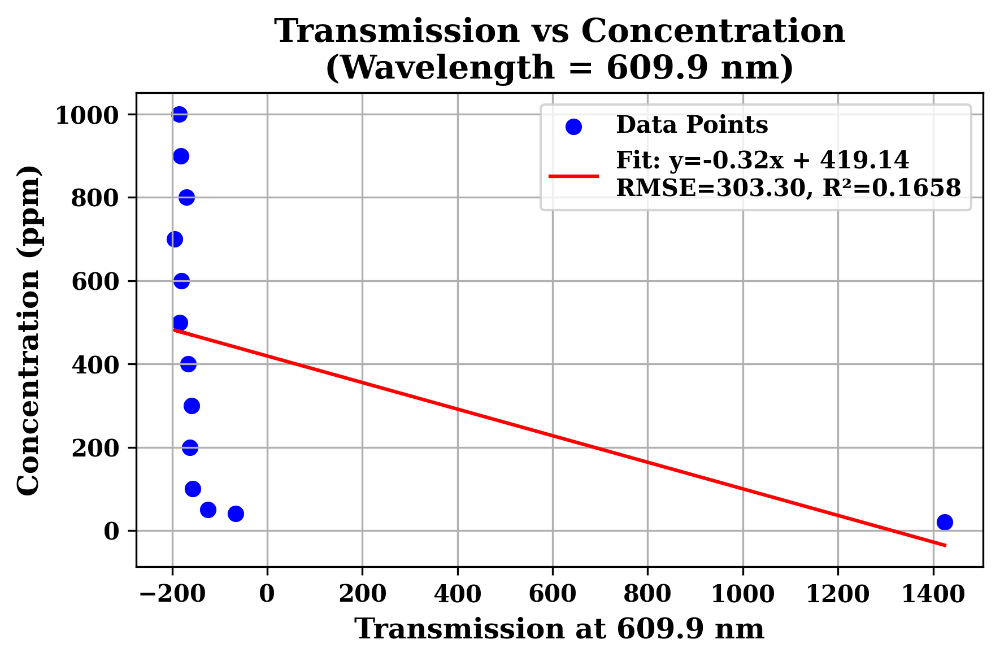

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib

# === Set Times New Roman (or closest) and bold ===
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
matplotlib.rcParams['font.weight'] = 'bold'
matplotlib.rcParams['axes.labelweight'] = 'bold'
matplotlib.rcParams['axes.titleweight'] = 'bold'

# === Load the sorted transmission data ===
df = pd.read_csv('processed_sorted_transmission.csv', index_col=0)

# === Prepare ===
wavelength_columns = df.columns
concentrations = df.index.values.reshape(-1, 1)

# === Define best and worst wavelengths ===
best_wavelength = 457.275
worst_wavelength = 609.900

# === Function to plot each wavelength ===
def plot_fit(wavelength):
    # Find closest available wavelength
    col = min(wavelength_columns, key=lambda x: abs(float(x) - wavelength))
    transmission = df[col].values.reshape(-1, 1)

    # Fit
    model = LinearRegression().fit(transmission, concentrations)
    concentration_pred = model.predict(transmission)

    coef = float(model.coef_[0])  # <-- FIXED: convert from numpy to float
    intercept = float(model.intercept_)  # <-- FIXED
    rmse = float(np.sqrt(mean_squared_error(concentrations, concentration_pred)))  # <-- FIXED
    r2 = float(r2_score(concentrations, concentration_pred))  # <-- FIXED

    # Plot
    plt.figure(figsize=(6, 4), dpi=300)
    plt.scatter(transmission, concentrations, color='blue', label="Data Points")
    plt.plot(transmission, concentration_pred, color='red',
             label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}, R²={r2:.4f}")
    plt.xlabel(f"Transmission at {float(col):.1f} nm", fontsize=12, weight='bold')
    plt.ylabel("Concentration (ppm)", fontsize=12, weight='bold')
    plt.title(f"Transmission vs Concentration\n(Wavelength = {float(col):.1f} nm)", fontsize=14, weight='bold')
    plt.grid(True)
    plt.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

# === Plot best and worst ===
plot_fit(best_wavelength)
plot_fit(worst_wavelength)


<ipython-input-11-697c13dd73ef>:36: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  coef = float(model.coef_[0])
<ipython-input-11-697c13dd73ef>:37: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  intercept = float(model.intercept_)


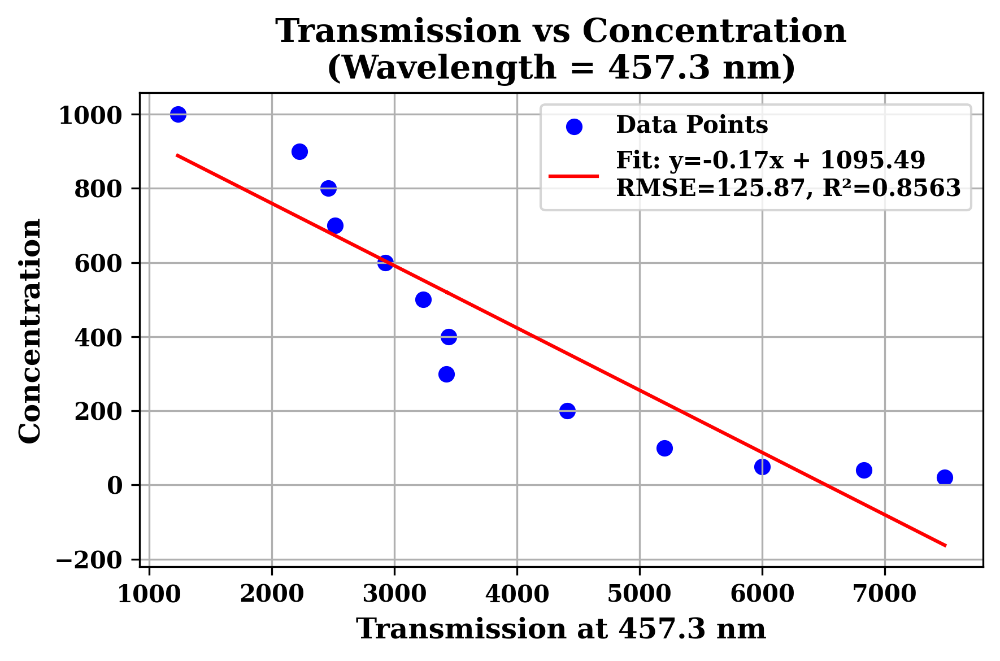

<ipython-input-11-697c13dd73ef>:36: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  coef = float(model.coef_[0])
<ipython-input-11-697c13dd73ef>:37: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  intercept = float(model.intercept_)


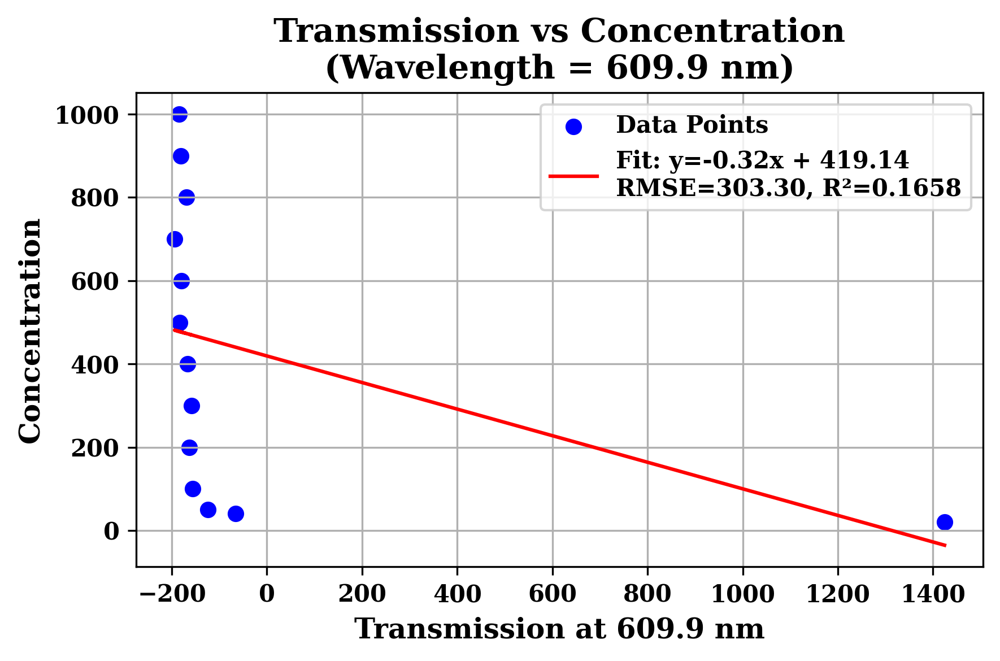

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib

# === Set Times New Roman (or closest) and bold ===
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
matplotlib.rcParams['font.weight'] = 'bold'
matplotlib.rcParams['axes.labelweight'] = 'bold'
matplotlib.rcParams['axes.titleweight'] = 'bold'

# === Load the sorted transmission data ===
df = pd.read_csv('processed_sorted_transmission.csv', index_col=0)

# === Prepare ===
wavelength_columns = df.columns
concentrations = df.index.values.reshape(-1, 1)

# === Define best and worst wavelengths ===
best_wavelength = 457.275
worst_wavelength = 609.900

# === Function to plot each wavelength ===
def plot_fit(wavelength):
    # Find closest available wavelength
    col = min(wavelength_columns, key=lambda x: abs(float(x) - wavelength))
    transmission = df[col].values.reshape(-1, 1)

    # Fit
    model = LinearRegression().fit(transmission, concentrations)
    concentration_pred = model.predict(transmission)

    coef = float(model.coef_[0])
    intercept = float(model.intercept_)
    rmse = float(np.sqrt(mean_squared_error(concentrations, concentration_pred)))
    r2 = float(r2_score(concentrations, concentration_pred))

    # Plot
    plt.figure(figsize=(6, 4), dpi=300)
    plt.scatter(transmission, concentrations, color='blue', label="Data Points")
    plt.plot(transmission, concentration_pred, color='red',
             label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}, R²={r2:.4f}")
    plt.xlabel(f"Transmission at {float(col):.1f} nm", fontsize=12, weight='bold')
    plt.ylabel("Concentration", fontsize=12, weight='bold')  # <-- Removed ppm here
    plt.title(f"Transmission vs Concentration\n(Wavelength = {float(col):.1f} nm)", fontsize=14, weight='bold')
    plt.grid(True)
    plt.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

# === Plot best and worst ===
plot_fit(best_wavelength)
plot_fit(worst_wavelength)


<ipython-input-14-cbb6a1a32d10>:36: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  coef = float(model.coef_[0])
<ipython-input-14-cbb6a1a32d10>:37: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  intercept = float(model.intercept_)


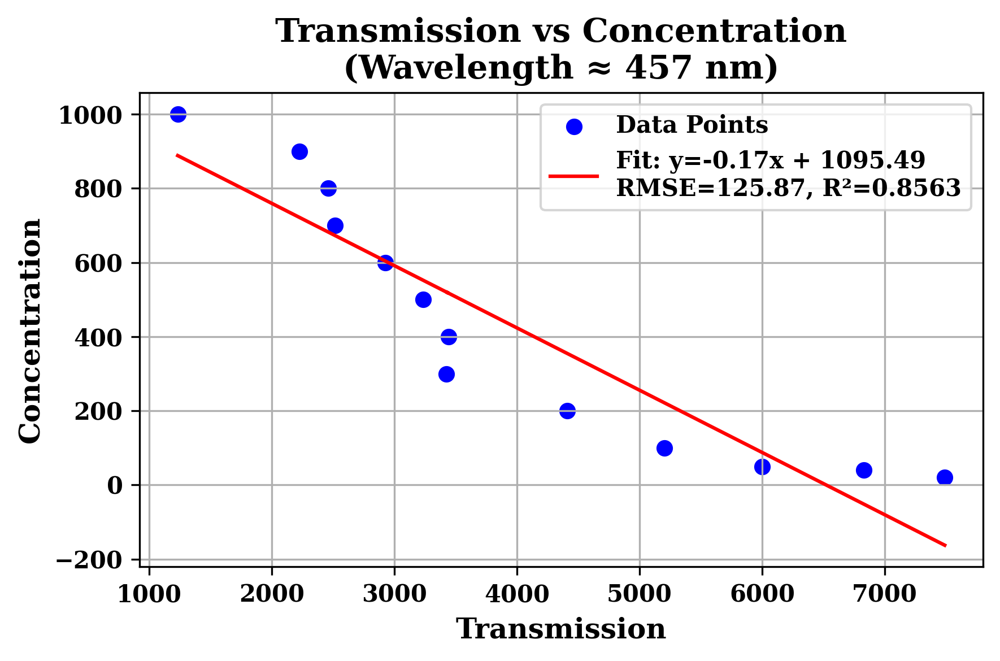

<ipython-input-14-cbb6a1a32d10>:36: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  coef = float(model.coef_[0])
<ipython-input-14-cbb6a1a32d10>:37: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  intercept = float(model.intercept_)


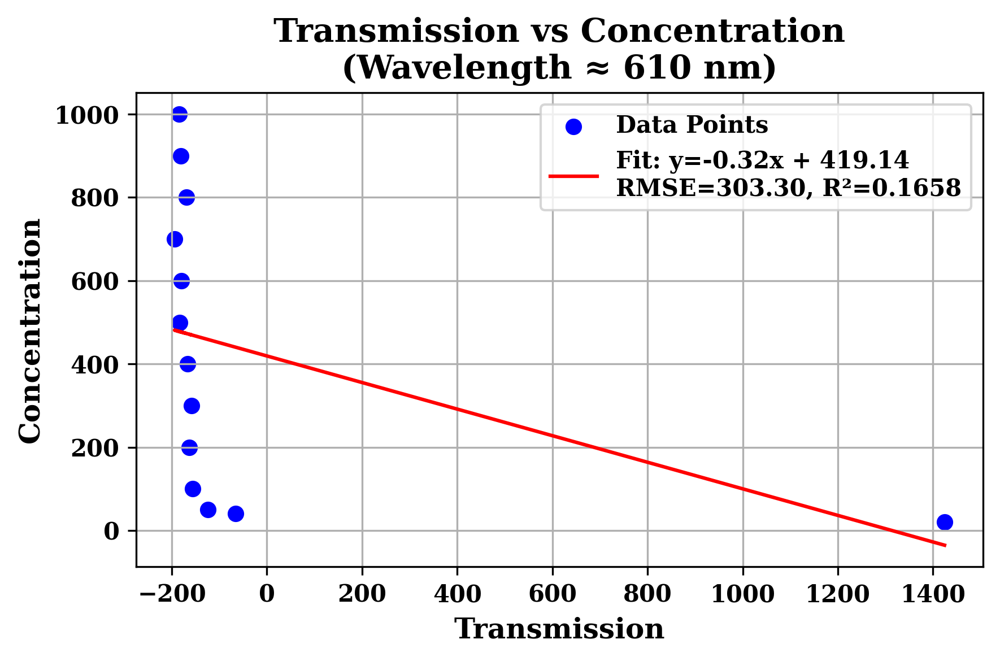

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib

# === Set Times New Roman (or closest) and bold ===
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
matplotlib.rcParams['font.weight'] = 'bold'
matplotlib.rcParams['axes.labelweight'] = 'bold'
matplotlib.rcParams['axes.titleweight'] = 'bold'

# === Load the sorted transmission data ===
df = pd.read_csv('processed_sorted_transmission.csv', index_col=0)

# === Prepare ===
wavelength_columns = df.columns
concentrations = df.index.values.reshape(-1, 1)

# === Define best and worst wavelengths ===
best_wavelength = 457.275
worst_wavelength = 609.900

# === Function to plot each wavelength ===
def plot_fit(wavelength):
    # Find closest available wavelength
    col = min(wavelength_columns, key=lambda x: abs(float(x) - wavelength))
    transmission = df[col].values.reshape(-1, 1)

    # Fit
    model = LinearRegression().fit(transmission, concentrations)
    concentration_pred = model.predict(transmission)

    coef = float(model.coef_[0])
    intercept = float(model.intercept_)
    rmse = float(np.sqrt(mean_squared_error(concentrations, concentration_pred)))
    r2 = float(r2_score(concentrations, concentration_pred))

    # Plot
    plt.figure(figsize=(6, 4), dpi=300)
    plt.scatter(transmission, concentrations, color='blue', label="Data Points")
    plt.plot(transmission, concentration_pred, color='red',
             label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}, R²={r2:.4f}")
    plt.xlabel("Transmission", fontsize=12, weight='bold')  # <=== changed here
    plt.ylabel("Concentration", fontsize=12, weight='bold')
    plt.title(f"Transmission vs Concentration\n(Wavelength ≈ {round(float(col))} nm)", fontsize=14, weight='bold')  # <=== changed here
    plt.grid(True)
    plt.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

# === Plot best and worst ===
plot_fit(best_wavelength)
plot_fit(worst_wavelength)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# === Load the data ===
df = pd.read_csv('processed_sorted_transmission.csv')

# === Prepare ===
concentrations = df.index.values  # now X-axis is still transmission, y-axis is concentration values
wavelength_columns = df.columns

# === Function to plot ===
def plot_fit(col, save_name=None):
    transmission = df[col].values.reshape(-1, 1)
    model = LinearRegression().fit(transmission, concentrations)
    concentration_pred = model.predict(transmission)

    coef = model.coef_[0]
    intercept = model.intercept_
    rmse = np.sqrt(mean_squared_error(concentrations, concentration_pred))
    r2 = r2_score(concentrations, concentration_pred)

    plt.figure(figsize=(6, 4))
    plt.scatter(transmission, concentrations, color='blue', label="Data Points")
    plt.plot(transmission, concentration_pred, color='red', label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}, R²={r2:.4f}")

    plt.xlabel(f"Transmission at {float(col):.1f} nm", fontsize=14, weight='bold')
    plt.ylabel("Concentration", fontsize=14, weight='bold')  # <<<<<< NO UNITS HERE
    plt.title(f"Transmission vs Concentration\n(Wavelength = {float(col):.1f} nm)", fontsize=16, weight='bold')

    plt.grid(True)
    plt.legend(fontsize=10)
    plt.xticks(fontsize=12, fontname="DejaVu Serif")
    plt.yticks(fontsize=12, fontname="DejaVu Serif")
    plt.tight_layout()

    if save_name:
        plt.savefig(save_name, dpi=300)
    plt.show()

# === Best and worst wavelength (manual or detected) ===
best_wavelength = 457.275  # update as needed
worst_wavelength = 609.900  # update as needed

# === Plot them ===
plot_fit(best_wavelength, save_name="best_fit.png")
plot_fit(worst_wavelength, save_name="worst_fit.png")


KeyError: 457.275

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# === Load the data ===
df = pd.read_csv('processed_sorted_transmission.csv')

# === Prepare ===
concentrations = df.index.values  # concentration (no units needed)
wavelength_columns = [str(col) for col in df.columns]  # Force columns to string

# === Function to plot ===
def plot_fit(wavelength, save_name=None):
    # Find closest available wavelength
    closest_wavelength = min([float(w) for w in wavelength_columns], key=lambda x: abs(x - wavelength))
    col = f"{closest_wavelength:.3f}"

    transmission = df[col].values.reshape(-1, 1)
    model = LinearRegression().fit(transmission, concentrations)
    concentration_pred = model.predict(transmission)

    coef = model.coef_[0]
    intercept = model.intercept_
    rmse = np.sqrt(mean_squared_error(concentrations, concentration_pred))
    r2 = r2_score(concentrations, concentration_pred)

    plt.figure(figsize=(6, 4))
    plt.scatter(transmission, concentrations, color='blue', label="Data Points")
    plt.plot(transmission, concentration_pred, color='red', label=f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}, R²={r2:.4f}")

    plt.xlabel(f"Transmission at {closest_wavelength:.1f} nm", fontsize=14, weight='bold')
    plt.ylabel("Concentration", fontsize=14, weight='bold')  # << NO UNITS
    plt.title(f"Transmission vs Concentration\n(Wavelength = {closest_wavelength:.1f} nm)", fontsize=16, weight='bold')

    plt.grid(True)
    plt.legend(fontsize=10)
    plt.xticks(fontsize=12, fontname="DejaVu Serif")
    plt.yticks(fontsize=12, fontname="DejaVu Serif")
    plt.tight_layout()

    if save_name:
        plt.savefig(save_name, dpi=300)
    plt.show()

# === Best and Worst Wavelengths (as float input) ===
best_wavelength = 457.275
worst_wavelength = 609.900

# === Plot them ===
plot_fit(best_wavelength, save_name="best_fit.png")
plot_fit(worst_wavelength, save_name="worst_fit.png")


ValueError: could not convert string to float: 'concentration'

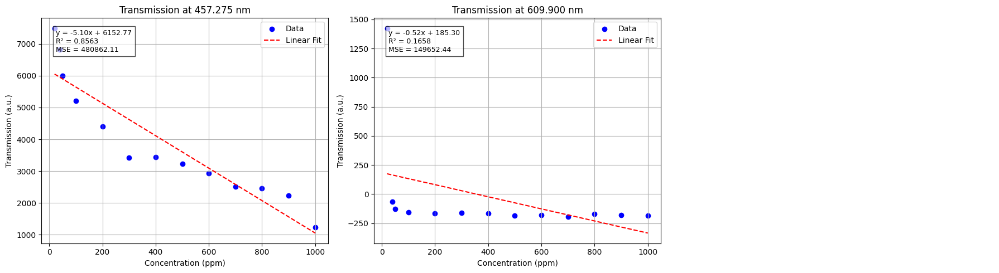

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# === Load the data ===
df = pd.read_csv('trans_vs_conc_best_and_worst.csv')

# === Prepare ===
wavelength_columns = df.columns[1:]  # skip concentration
concentrations = df["Concentration (ppm)"].values.reshape(-1, 1)  # Make it 2D for sklearn

# === Set up plot ===
num_plots = len(wavelength_columns)
cols = 3
rows = int(np.ceil(num_plots / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols * 6, rows * 5))
axes = axes.flatten()

# === Loop and plot ===
for idx, wl_col in enumerate(wavelength_columns):
    trans = df[wl_col].values.reshape(-1, 1)

    # Fit linear regression
    model = LinearRegression()
    model.fit(concentrations, trans)
    trans_pred = model.predict(concentrations)

    # Calculate R2 and MSE
    r2 = r2_score(trans, trans_pred)
    mse = mean_squared_error(trans, trans_pred)

    # Scatter plot
    axes[idx].scatter(concentrations, trans, color='blue', label='Data')
    axes[idx].plot(concentrations, trans_pred, color='red', linestyle='--', label='Linear Fit')

    # Title and labels
    axes[idx].set_title(f"{wl_col}")
    axes[idx].set_xlabel("Concentration (ppm)")
    axes[idx].set_ylabel("Transmission (a.u.)")
    axes[idx].grid(True)

    # Equation text
    slope = model.coef_[0][0]
    intercept = model.intercept_[0]
    eq_text = f"y = {slope:.2f}x + {intercept:.2f}\nR² = {r2:.4f}\nMSE = {mse:.2f}"
    axes[idx].text(0.05, 0.95, eq_text, transform=axes[idx].transAxes,
                   fontsize=9, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))

    axes[idx].legend()

# Turn off unused axes
for j in range(idx + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


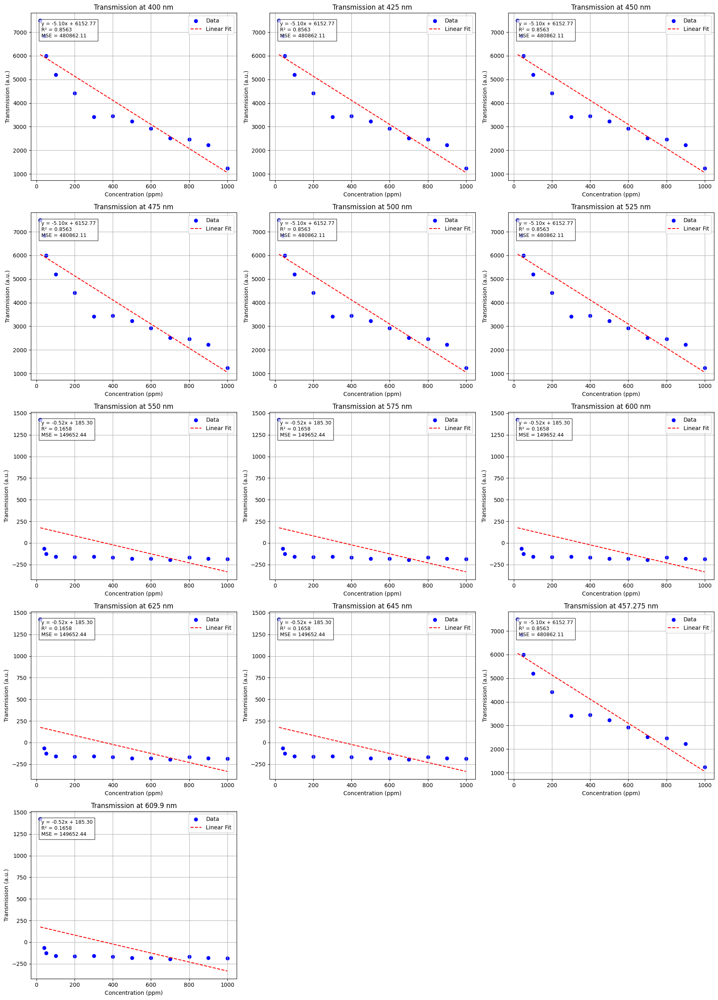

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# === Load your transmission vs concentration file ===
df = pd.read_csv('trans_vs_conc_best_and_worst.csv')

# === Concentration values ===
concentration = df["Concentration (ppm)"].values.reshape(-1, 1)  # 2D for sklearn

# === Define your special wavelengths (rounded) ===
desired_wavelengths = [400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 645]

# === Best and worst wavelengths from file ===
columns_in_file = list(df.columns)
best_wavelength = 457.275
worst_wavelength = 609.900

# === Prepare full wavelength list to plot ===
wavelengths_to_plot = desired_wavelengths + [best_wavelength, worst_wavelength]

# === Set up plot ===
num_plots = len(wavelengths_to_plot)
cols = 3
rows = int(np.ceil(num_plots / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols * 6, rows * 5))
axes = axes.flatten()

# === Loop and plot ===
for idx, wl in enumerate(wavelengths_to_plot):
    # Find the closest available column in the file
    available_cols = df.columns[1:]  # skip concentration
    closest_col = min(available_cols, key=lambda x: abs(float(x.split()[2]) - wl))

    trans = df[closest_col].values.reshape(-1, 1)

    # Linear Regression Fit
    model = LinearRegression()
    model.fit(concentration, trans)
    trans_pred = model.predict(concentration)

    # Calculate R2 and MSE
    r2 = r2_score(trans, trans_pred)
    mse = mean_squared_error(trans, trans_pred)

    # Scatter and Line Plot
    axes[idx].scatter(concentration, trans, color='blue', label='Data')
    axes[idx].plot(concentration, trans_pred, color='red', linestyle='--', label='Linear Fit')

    # Title should show rounded requested wavelength!
    axes[idx].set_title(f"Transmission at {wl} nm")
    axes[idx].set_xlabel("Concentration (ppm)")
    axes[idx].set_ylabel("Transmission (a.u.)")
    axes[idx].grid(True)

    # Add equation
    slope = model.coef_[0][0]
    intercept = model.intercept_[0]
    eq_text = f"y = {slope:.2f}x + {intercept:.2f}\nR² = {r2:.4f}\nMSE = {mse:.2f}"
    axes[idx].text(0.05, 0.95, eq_text, transform=axes[idx].transAxes,
                   fontsize=9, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
    axes[idx].legend()

# Hide extra empty subplots if any
for j in range(idx+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


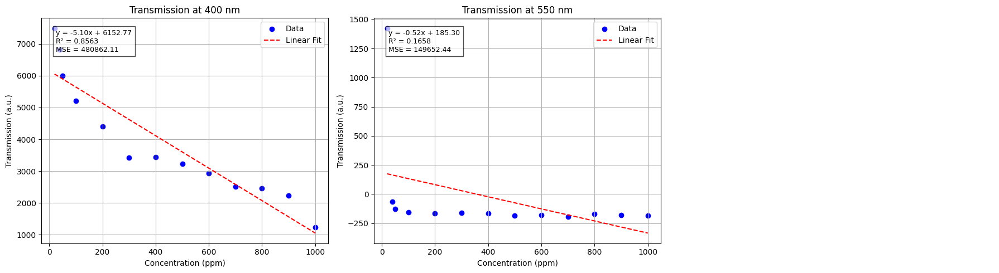

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# === Load your data ===
df = pd.read_csv('trans_vs_conc_best_and_worst.csv')

# === Concentration ===
concentration = df["Concentration (ppm)"].values.reshape(-1, 1)

# === Special Wavelengths You Want ===
desired_wavelengths = [400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 645]

# === Best and Worst wavelengths ===
best_wavelength = 457.275
worst_wavelength = 609.900

# === Available columns ===
available_cols = df.columns[1:]

# === Match closest, but avoid duplicates ===
matched = {}
used_cols = set()

for wl in desired_wavelengths + [best_wavelength, worst_wavelength]:
    closest_col = min(available_cols, key=lambda x: abs(float(x.split()[2]) - wl))
    if closest_col not in used_cols:
        matched[wl] = closest_col
        used_cols.add(closest_col)

# === Plot ===
num_plots = len(matched)
cols = 3
rows = int(np.ceil(num_plots / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols * 6, rows * 5))
axes = axes.flatten()

for idx, (wl, colname) in enumerate(matched.items()):
    trans = df[colname].values.reshape(-1, 1)

    model = LinearRegression()
    model.fit(concentration, trans)
    trans_pred = model.predict(concentration)

    r2 = r2_score(trans, trans_pred)
    mse = mean_squared_error(trans, trans_pred)

    axes[idx].scatter(concentration, trans, color='blue', label='Data')
    axes[idx].plot(concentration, trans_pred, color='red', linestyle='--', label='Linear Fit')
    axes[idx].set_title(f"Transmission at {wl:.0f} nm")  # Title shows YOUR rounded wl
    axes[idx].set_xlabel("Concentration (ppm)")
    axes[idx].set_ylabel("Transmission (a.u.)")
    axes[idx].grid(True)

    slope = model.coef_[0][0]
    intercept = model.intercept_[0]
    eq_text = f"y = {slope:.2f}x + {intercept:.2f}\nR² = {r2:.4f}\nMSE = {mse:.2f}"
    axes[idx].text(0.05, 0.95, eq_text, transform=axes[idx].transAxes,
                   fontsize=9, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
    axes[idx].legend()

# Hide extra empty plots
for j in range(idx+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# === Clean 3×3 Transmission vs Concentration (25 nm + best/worst) ===
# Works with:
#   - processed_sorted_transmission.csv
#   - mse_per_wavelength.xlsx  (or mse_per_wavelength_with_std.csv)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ---------------- Style (TNR-like, white bg) ----------------
rcParams['font.family'] = 'Liberation Serif'
rcParams['figure.facecolor'] = 'white'
rcParams['axes.facecolor'] = 'white'
rcParams['axes.linewidth'] = 1.1

# ---------------- Inputs ----------------
TX_FILE = "processed_sorted_transmission.csv"
# We’ll try both; whichever exists will load:
MSE_FILE_CSV  = "mse_per_wavelength_with_std.csv"
MSE_FILE_XLSX = "mse_per_wavelength.xlsx"

# ---------------- Load transmission matrix ----------------
# Expectation: rows = concentrations (index), columns = wavelength columns (floats as strings)
df = pd.read_csv(TX_FILE, index_col=0)

# defensive: ensure index (concentration) is numeric
try:
    df.index = pd.to_numeric(df.index)
except Exception:
    pass

# x (wavelengths) from header
wavelengths = [float(c) for c in df.columns]

# ---------------- Load MSE per wavelength ----------------
mse_df = None
try:
    mse_df = pd.read_csv(MSE_FILE_CSV)
except Exception:
    try:
        mse_df = pd.read_excel(MSE_FILE_XLSX)
    except Exception:
        raise FileNotFoundError(
            "Could not find MSE file. Provide either "
            f"'{MSE_FILE_CSV}' or '{MSE_FILE_XLSX}'."
        )

# make sure columns exist/standardize
mse_df = mse_df.rename(columns={c: c.lower() for c in mse_df.columns})
if "wavelength" not in mse_df.columns:
    raise ValueError("MSE file must have a 'wavelength' column.")
if "mse" not in mse_df.columns:
    raise ValueError("MSE file must have an 'mse' column.")
mse_df["rmse"] = np.sqrt(mse_df["mse"])

# ---------------- Pick wavelengths ----------------
best_wl  = mse_df.loc[mse_df["mse"].idxmin(), "wavelength"]
worst_wl = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

special_wls = list(np.arange(400, 651, 25))  # 400, 425, ..., 650
for extra in [best_wl, worst_wl]:
    if extra not in special_wls:
        special_wls.append(extra)
special_wls = sorted(special_wls)

# snap to nearest actual measured wavelength
def closest(actual_list, target):
    return min(actual_list, key=lambda x: abs(x - float(target)))

picked_wls = []
for wl in special_wls:
    picked_wls.append(closest(wavelengths, wl))
# preserve unique order while keeping size up to 9 (3×3)
uniq = []
for w in picked_wls:
    if w not in uniq:
        uniq.append(w)
picked_wls = uniq[:9]

# ---------------- Precompute global axis ranges (for uniform scaling) ----------------
all_x = []
all_y = []
for wl in picked_wls:
    col = f"{wl:.3f}" if f"{wl:.3f}" in df.columns else str(wl)
    if col not in df.columns:
        # try exact string formatting alternatives
        candidates = [c for c in df.columns if abs(float(c) - wl) < 1e-6]
        if candidates:
            col = candidates[0]
        else:
            continue
    all_x.extend(df[col].values.tolist())
    all_y.extend(df.index.values.tolist())

x_min, x_max = np.nanmin(all_x), np.nanmax(all_x)
y_min, y_max = np.nanmin(all_y), np.nanmax(all_y)

# ---------------- Plot grid ----------------
n = len(picked_wls)
ncols = 3
nrows = 3 if n > 6 else (2 if n > 3 else 1)

fig, axes = plt.subplots(nrows, ncols, figsize=(13, 13))
axes = np.array(axes).reshape(-1)

pt_edge = "#0057B7"  # deep blue
fit_col = "#D32F2F"  # red
ms, lw = 26, 2.0

save_rows = []  # for tidy export

for i, wl in enumerate(picked_wls):
    ax = axes[i]
    # find matching column name (3-decimal first, fallback)
    wl_col = f"{wl:.3f}" if f"{wl:.3f}" in df.columns else str(wl)
    if wl_col not in df.columns:
        candidates = [c for c in df.columns if abs(float(c) - wl) < 1e-6]
        if not candidates:
            ax.set_visible(False)
            continue
        wl_col = candidates[0]

    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    # Linear fit
    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)

    coef = float(model.coef_[0])
    intercept = float(model.intercept_)
    mse = mean_squared_error(y_plot, y_pred)
    rmse = float(np.sqrt(mse))
    r2 = float(r2_score(y_plot, y_pred))

    # Scatter (open circles)
    ax.scatter(
        X_plot, y_plot,
        facecolors='none', edgecolors=pt_edge, s=ms, linewidths=1.2
    )

    # Fit line across local x-range
    xx = np.linspace(X_plot.min(), X_plot.max(), 200)
    ax.plot(xx, coef*xx + intercept, color=fit_col, linewidth=lw)

    # Titles/labels
    ax.set_title(f"Transmission vs Concentration\n(Wavelength = {wl:.1f} nm)",
                 fontsize=13, pad=6)
    ax.set_xlabel(f"Transmission at {wl:.1f} nm (a.u.)", fontsize=12)
    ax.set_ylabel("Concentration (ppm)", fontsize=12)
    ax.tick_params(axis='both', labelsize=11)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    for spine in ax.spines.values():
        spine.set_linewidth(1.1)
    ax.grid(False)

    # Annotation (top-right)
    txt = f"Fit: y={coef:+.2f}x {intercept:+.2f}\nRMSE={rmse:.2f}, R²={r2:.3f}"
    ax.text(0.97, 0.97, txt, transform=ax.transAxes,
            ha='right', va='top', fontsize=10,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=3))

    # Uniform axes
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    # Collect tidy rows
    for xv, yv, yhat in zip(X_plot.flatten(), y_plot, y_pred):
        save_rows.append({
            "wavelength": wl,
            "transmission": float(xv),
            "concentration": float(yv),
            "predicted_concentration": float(yhat),
            "coef": coef,
            "intercept": intercept,
            "mse": mse,
            "rmse": rmse,
            "r2": r2
        })

# Hide any extra axes
for j in range(len(picked_wls), len(axes)):
    axes[j].set_visible(False)

plt.subplots_adjust(wspace=0.35, hspace=0.42)
plt.tight_layout()
outfile = "fig_transmission_vs_conc_grid_300dpi.png"
plt.savefig(outfile, dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
plt.show()

# Export tidy combined data
outcsv = "trans_vs_conc_fit_data_with_rmse_r2.csv"
pd.DataFrame(save_rows).to_csv(outcsv, index=False)

print(f"✅ Saved figure: {outfile}")
print(f"✅ Saved tidy data: {outcsv}")


FileNotFoundError: Could not find MSE file. Provide either 'mse_per_wavelength_with_std.csv' or 'mse_per_wavelength.xlsx'.

In [ ]:
import pandas as pd
import numpy as np

# === Load the sorted transmission data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Load the MSE file to find worst wavelength ===
mse_df = pd.read_csv("mse_per_wavelength_with_std.csv")
worst_wavelength = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

# === Prepare list of desired wavelengths ===
special_wavelengths = list(np.arange(400, 650 + 1, 25))  # 400, 425, 450, ..., 650
if worst_wavelength not in special_wavelengths:
    special_wavelengths.append(worst_wavelength)

special_wavelengths = sorted(special_wavelengths)

# === Find the closest real wavelengths available ===
available_wavelengths = [float(col) for col in df.columns]

matched_wavelengths = []
for wl in special_wavelengths:
    closest_wl = min(available_wavelengths, key=lambda x: abs(x - wl))
    matched_wavelengths.append(closest_wl)

# === Build a new DataFrame ===
new_df = pd.DataFrame()

for wl in matched_wavelengths:
    wl_col = f"{wl:.3f}"  # match format exactly
    if wl_col in df.columns:
        new_df[f"{wl:.1f} nm"] = df[wl_col].values
    else:
        print(f"⚠️ Wavelength {wl_col} nm not found. Skipping.")

# === Add concentration as a separate column (optional) ===
new_df.insert(0, "Concentration (ppm)", df.index.values)

# === Save the file ===
new_df.to_csv("transmission_vs_concentration_columns.csv", index=False)

print("✅ Done. Saved as 'transmission_vs_concentration_columns.csv'.")


⚠️ Wavelength 609.900 nm not found. Skipping.
✅ Done. Saved as 'transmission_vs_concentration_columns.csv'.


In [ ]:
import pandas as pd
import numpy as np

# === Load data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)
mse_df = pd.read_csv("mse_per_wavelength_with_std.csv")

# === Find best and worst wavelengths based on MSE ===
best_wavelength = mse_df.loc[mse_df["mse"].idxmin(), "wavelength"]
worst_wavelength = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

# === Find closest available wavelengths ===
available_wavelengths = [float(col) for col in df.columns]

closest_best = min(available_wavelengths, key=lambda x: abs(x - best_wavelength))
closest_worst = min(available_wavelengths, key=lambda x: abs(x - worst_wavelength))

print(f"✅ Closest available to best wavelength: {closest_best:.3f} nm")
print(f"✅ Closest available to worst wavelength: {closest_worst:.3f} nm")

# === Extract transmission vs concentration for best and worst ===
save_best = pd.DataFrame({
    "Concentration (ppm)": df.index.values,
    f"Transmission at {closest_best:.3f} nm": df[f"{closest_best:.3f}"].values
})

save_worst = pd.DataFrame({
    "Concentration (ppm)": df.index.values,
    f"Transmission at {closest_worst:.3f} nm": df[f"{closest_worst:.3f}"].values
})

# === Save separately ===
save_best.to_csv("trans_vs_conc_best_mse_wavelength.csv", index=False)
save_worst.to_csv("trans_vs_conc_worst_mse_wavelength.csv", index=False)

print("✅ Done. Files saved: 'trans_vs_conc_best_mse_wavelength.csv' and 'trans_vs_conc_worst_mse_wavelength.csv'.")


✅ Closest available to best wavelength: 457.275 nm
✅ Closest available to worst wavelength: 609.900 nm


KeyError: '609.900'

In [ ]:
import pandas as pd
import numpy as np

# === Load data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)
mse_df = pd.read_csv("mse_per_wavelength_with_std.csv")

# === Find best and worst wavelengths based on MSE ===
best_wavelength = mse_df.loc[mse_df["mse"].idxmin(), "wavelength"]
worst_wavelength = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

# === Find closest available wavelengths ===
available_wavelengths = [float(col) for col in df.columns]

closest_best = min(available_wavelengths, key=lambda x: abs(x - best_wavelength))
closest_worst = min(available_wavelengths, key=lambda x: abs(x - worst_wavelength))

print(f"✅ Closest available to best wavelength: {closest_best:.3f} nm")
print(f"✅ Closest available to worst wavelength: {closest_worst:.3f} nm")

# === Extract transmission vs concentration for best and worst ===
save_best = pd.DataFrame({
    "Concentration (ppm)": df.index.values,
    f"Transmission at {closest_best:.3f} nm": df[f"{closest_best:.3f}"].values
})

save_worst = pd.DataFrame({
    "Concentration (ppm)": df.index.values,
    f"Transmission at {closest_worst:.3f} nm": df[f"{closest_worst:.3f}"].values
})

# === Save separately ===
save_best.to_csv("trans_vs_conc_best_mse_wavelength.csv", index=False)
save_worst.to_csv("trans_vs_conc_worst_mse_wavelength.csv", index=False)

print("✅ Done. Files saved: 'trans_vs_conc_best_mse_wavelength.csv' and 'trans_vs_conc_worst_mse_wavelength.csv'.")


✅ Closest available to best wavelength: 457.275 nm
✅ Closest available to worst wavelength: 609.900 nm


KeyError: '609.900'

In [ ]:
import pandas as pd
import numpy as np

# === Load data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)
mse_df = pd.read_csv("mse_per_wavelength_with_std.csv")

# === Find best and worst wavelengths based on MSE ===
best_wavelength = mse_df.loc[mse_df["mse"].idxmin(), "wavelength"]
worst_wavelength = mse_df.loc[mse_df["mse"].idxmax(), "wavelength"]

# === Find closest available wavelengths ===
available_wavelengths = [float(col) for col in df.columns]

closest_best = min(available_wavelengths, key=lambda x: abs(x - best_wavelength))
closest_worst = min(available_wavelengths, key=lambda x: abs(x - worst_wavelength))

print(f"✅ Closest available to best wavelength: {closest_best:.3f} nm")
print(f"✅ Closest available to worst wavelength: {closest_worst:.3f} nm")

# === Use closest wavelengths ONLY ===
# Build DataFrame
save_df = pd.DataFrame({
    "Concentration (ppm)": df.index.values,
    f"Transmission at {closest_best:.3f} nm": df[f"{closest_best}"].values,
    f"Transmission at {closest_worst:.3f} nm": df[f"{closest_worst}"].values
})

# === Save to file ===
save_df.to_csv("trans_vs_conc_best_and_worst.csv", index=False)

print("✅ Saved as 'trans_vs_conc_best_and_worst.csv'.")


✅ Closest available to best wavelength: 457.275 nm
✅ Closest available to worst wavelength: 609.900 nm
✅ Saved as 'trans_vs_conc_best_and_worst.csv'.


In [ ]:
results_df.to_csv("greedy_feature_selection_10foldCV_results.csv", index=False)


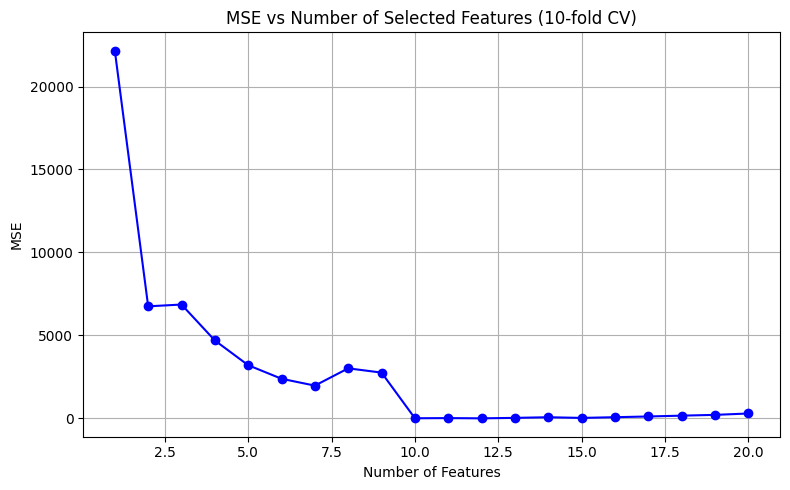

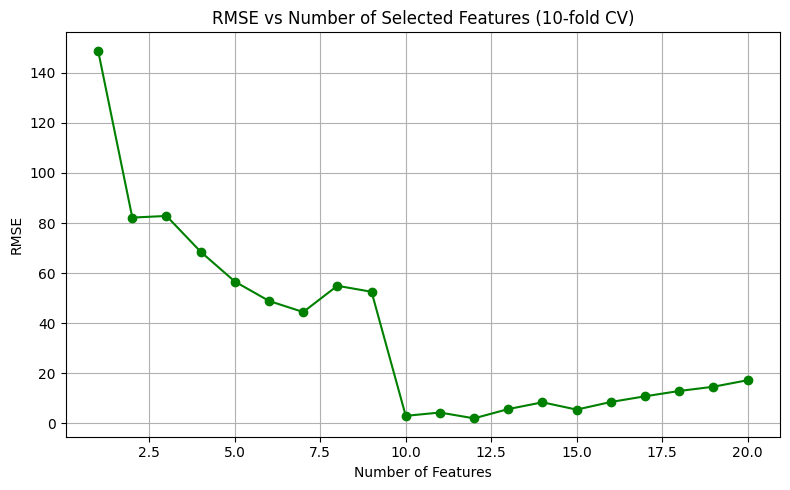

In [ ]:
# === Convert to DataFrame ===
results_df = pd.DataFrame(data_list)
results_df["rmse"] = np.sqrt(results_df["mse"])  # Compute RMSE

# === Plot MSE ===
plt.figure(figsize=(8, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o", color="blue")
plt.xlabel("Number of Features")
plt.ylabel("MSE")
plt.title("MSE vs Number of Selected Features (10-fold CV)")
plt.grid(True)
plt.tight_layout()
plt.show()

# === Plot RMSE ===
plt.figure(figsize=(8, 5))
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o", color="green")
plt.xlabel("Number of Features")
plt.ylabel("RMSE")
plt.title("RMSE vs Number of Selected Features (10-fold CV)")
plt.grid(True)
plt.tight_layout()
plt.show()


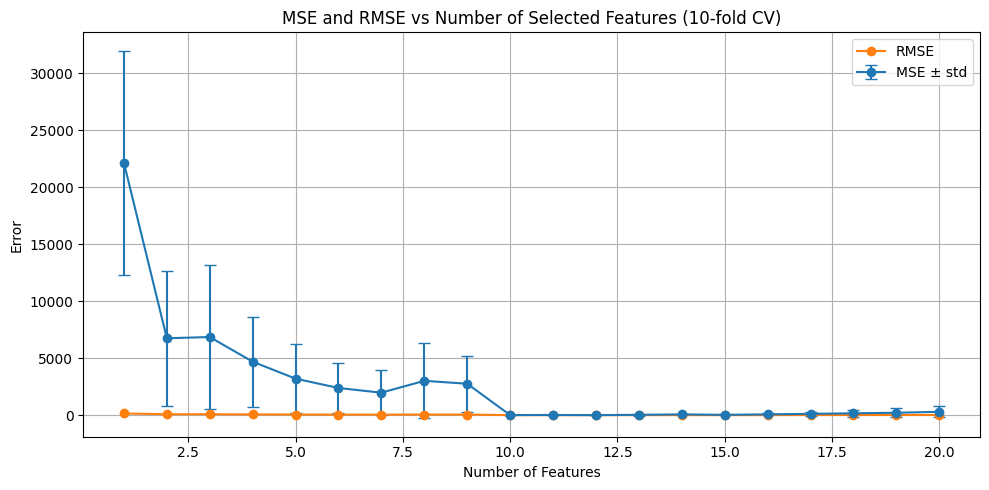

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

# === Use the smoothed dataset you already created ===
df = plot_df.copy()  # or samples_df if it has 'smoothed_T2'

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df.columns = [f"wv_{w:.3f}" for w in wide_df.columns]
X_full = wide_df.reset_index(drop=True)
y_full = wide_df.index.values

# === Define 10-fold CV with standard deviation ===
def kfold_cv_mse_std(X, y, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X):
        model = LinearRegression()
        model.fit(X[train_idx], y[train_idx])
        y_pred = model.predict(X[val_idx])
        mse_vals.append(mean_squared_error(y[val_idx], y_pred))
    return np.mean(mse_vals), np.std(mse_vals)

# === Greedy Feature Selection ===
remaining = list(X_full.columns)
selected = []
data_list = []

best_mse = float("inf")
min_improvement = 1e-3

for _ in range(20):  # Top 20 features max
    best_candidate = None
    best_mse_this_round = float("inf")
    best_std = None

    for candidate in remaining:
        test_feats = selected + [candidate]
        X_sel = X_full[test_feats].values
        mse, std = kfold_cv_mse_std(X_sel, y_full)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate
            best_std = std

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse),
        "std": best_std
    })

# === Create Results DataFrame ===
results_df = pd.DataFrame(data_list)

# === Plot MSE and RMSE vs Features ===
plt.figure(figsize=(10, 5))
plt.errorbar(results_df["n_feats"], results_df["mse"], yerr=results_df["std"], fmt='-o', capsize=4, label="MSE ± std")
plt.plot(results_df["n_feats"], results_df["rmse"], marker='o', label="RMSE")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


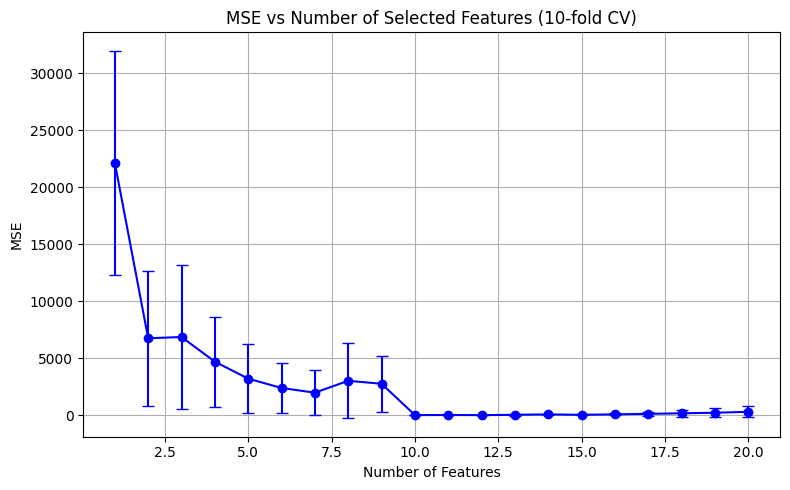

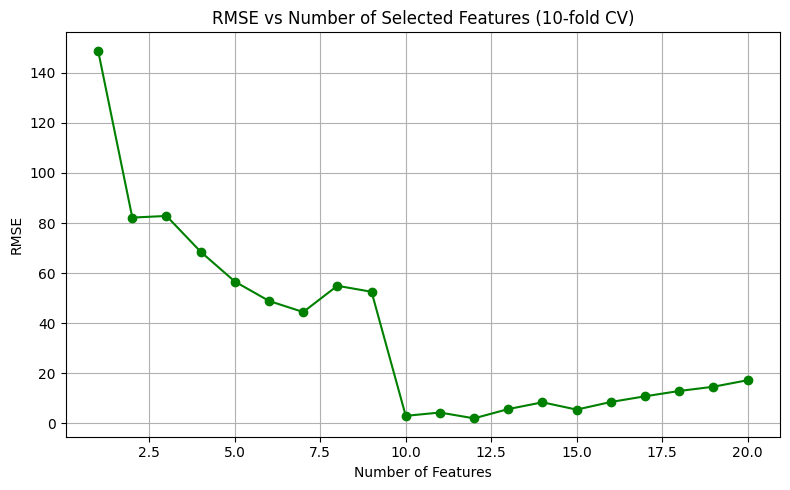

In [ ]:
# === Plot MSE separately ===
plt.figure(figsize=(8, 5))
plt.errorbar(results_df["n_feats"], results_df["mse"], yerr=results_df["std"], fmt='-o', capsize=4, color='blue')
plt.xlabel("Number of Features")
plt.ylabel("MSE")
plt.title("MSE vs Number of Selected Features (10-fold CV)")
plt.grid(True)
plt.tight_layout()
plt.show()

# === Plot RMSE separately ===
plt.figure(figsize=(8, 5))
plt.plot(results_df["n_feats"], results_df["rmse"], marker='o', color='green')
plt.xlabel("Number of Features")
plt.ylabel("RMSE")
plt.title("RMSE vs Number of Selected Features (10-fold CV)")
plt.grid(True)
plt.tight_layout()
plt.show()


Best MSE achieved using 12 features


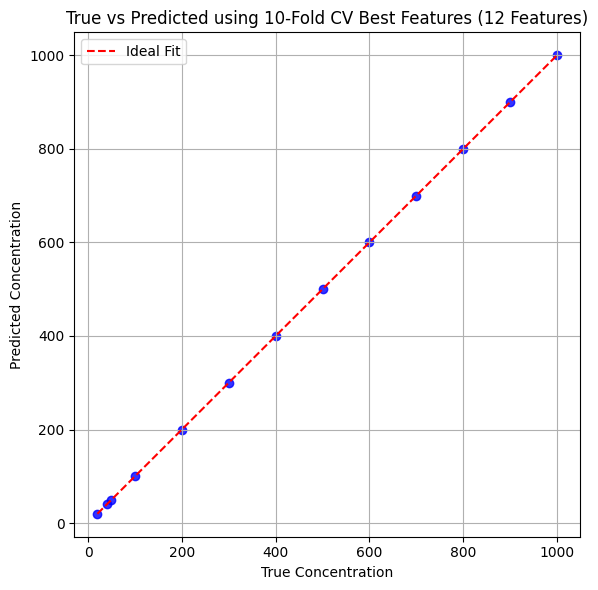

In [ ]:
from sklearn.linear_model import LinearRegression

# === Get best MSE row (should be at 12 features) ===
best_row = results_df.loc[results_df["mse"].idxmin()]
best_features = best_row["features"]
print(f"Best MSE achieved using {len(best_features)} features")

# === Prepare data ===
X_best = X_full[best_features].values
y_true = y_full

# === Fit and predict using full data ===
model = LinearRegression().fit(X_best, y_true)
y_pred = model.predict(X_best)

# === Scatter plot: true vs predicted ===
plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.8, color="blue")
plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', label='Ideal Fit')
plt.xlabel("True Concentration")
plt.ylabel("Predicted Concentration")
plt.title(f"True vs Predicted using 10-Fold CV Best Features ({len(best_features)} Features)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Best single feature: wv_457.275


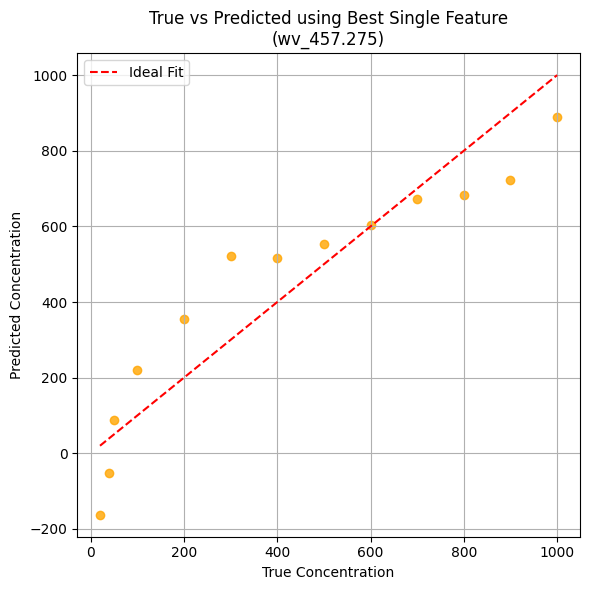

In [ ]:
from sklearn.linear_model import LinearRegression

# === Get the best single feature (first one selected) ===
best_single_feature = results_df.iloc[0]["features"][0]
print(f"Best single feature: {best_single_feature}")

# === Prepare data ===
X_1d = X_full[[best_single_feature]].values
y_true = y_full

# === Fit and predict ===
model = LinearRegression().fit(X_1d, y_true)
y_pred = model.predict(X_1d)

# === Scatter plot: true vs predicted ===
plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.8, color="orange")
plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', label='Ideal Fit')
plt.xlabel("True Concentration")
plt.ylabel("Predicted Concentration")
plt.title(f"True vs Predicted using Best Single Feature\n({best_single_feature})")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Best feature count (CV): 12 features


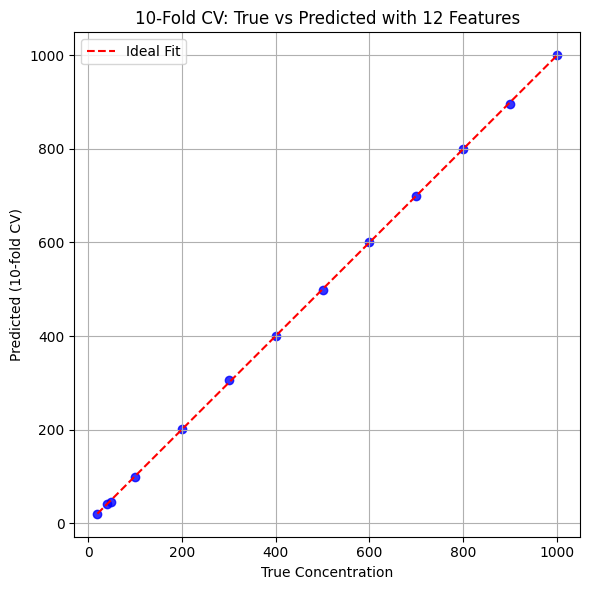

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
import numpy as np
import matplotlib.pyplot as plt

# === Get best feature set from results_df ===
best_row = results_df.loc[results_df["mse"].idxmin()]
best_features = best_row["features"]
print(f"Best feature count (CV): {len(best_features)} features")

X_best = X_full[best_features].values
y_true = y_full.copy()

# === Run 10-fold CV prediction ===
kf = KFold(n_splits=10, shuffle=True, random_state=42)
y_pred_cv = np.zeros_like(y_true, dtype=float)

for train_idx, test_idx in kf.split(X_best):
    model = LinearRegression().fit(X_best[train_idx], y_true[train_idx])
    y_pred_cv[test_idx] = model.predict(X_best[test_idx])

# === Plot CV predictions ===
plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred_cv, alpha=0.8, color="blue")
plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', label="Ideal Fit")
plt.xlabel("True Concentration")
plt.ylabel("Predicted (10-fold CV)")
plt.title(f"10-Fold CV: True vs Predicted with {len(best_features)} Features")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Best single feature (CV): wv_457.275


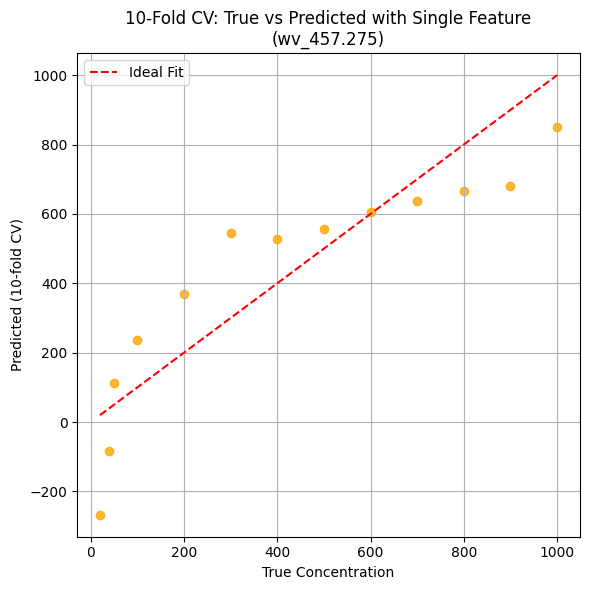

In [ ]:
# === Get best single feature from results_df ===
best_single_feature = results_df.iloc[0]["features"][0]
print(f"Best single feature (CV): {best_single_feature}")

X_1d = X_full[[best_single_feature]].values

# === Run 10-fold CV for single feature ===
y_pred_1d_cv = np.zeros_like(y_true, dtype=float)

for train_idx, test_idx in kf.split(X_1d):
    model = LinearRegression().fit(X_1d[train_idx], y_true[train_idx])
    y_pred_1d_cv[test_idx] = model.predict(X_1d[test_idx])

# === Plot CV predictions for single feature ===
plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred_1d_cv, alpha=0.8, color="orange")
plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', label="Ideal Fit")
plt.xlabel("True Concentration")
plt.ylabel("Predicted (10-fold CV)")
plt.title(f"10-Fold CV: True vs Predicted with Single Feature\n({best_single_feature})")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Top 12 features: ['wv_457.275', 'wv_427.160', 'wv_631.853', 'wv_423.564', 'wv_478.190', 'wv_479.650', 'wv_545.117', 'wv_629.068', 'wv_452.447', 'wv_547.774', 'wv_631.058', 'wv_488.603']


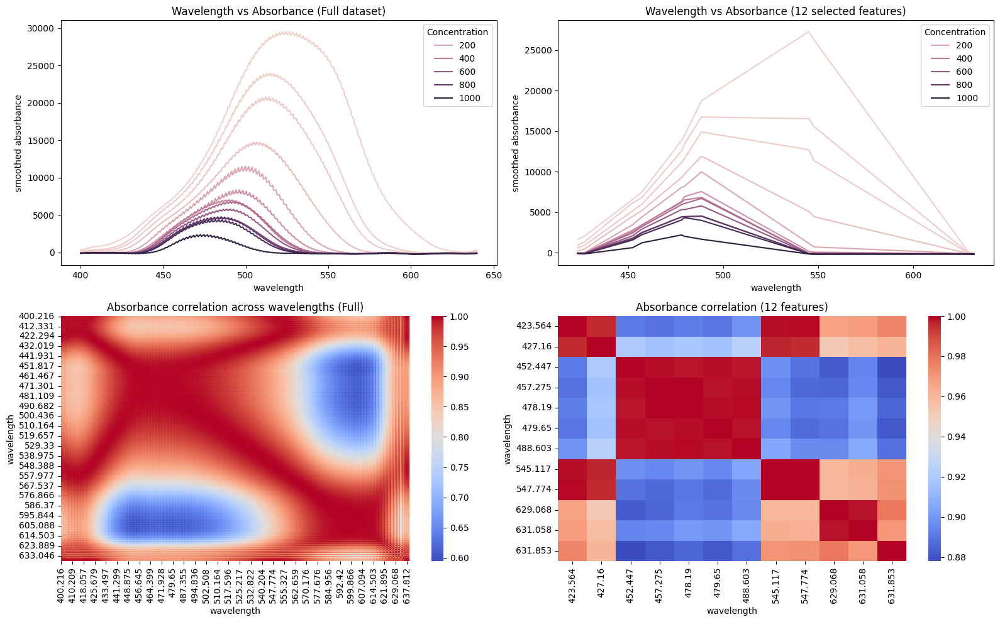

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# === Step 1: Select 12 best features from results_df ===
top_features = results_df.loc[results_df["n_feats"] == 12, "features"].values[0]
print("Top 12 features:", top_features)

# === Step 2: Subset smoothed data for selected wavelengths ===
# Use your original 'df' (long format) smoothed data
df_sub = df.copy()
df_sub = df_sub[df_sub["wavelength"].isin([float(f.split("_")[-1].replace("_", ".")) for f in top_features])]
df_sub = df_sub[df_sub["wavelength"].between(400, 650)]

# === Step 3: Plot absorbance curves (full vs reduced) ===
fig, axs = plt.subplots(2, 2, figsize=(16, 10))
axs = axs.flatten()

# Full dataset curve
sns.lineplot(data=df[df["wavelength"].between(400, 650)], x="wavelength", y="smoothed_T2", hue="concentration", ax=axs[0])
axs[0].set_title("Wavelength vs Absorbance (Full dataset)")
axs[0].set_ylabel("smoothed absorbance")
axs[0].legend(title="Concentration")

# Reduced dataset curve (12 features only)
sns.lineplot(data=df_sub, x="wavelength", y="smoothed_T2", hue="concentration", ax=axs[1])
axs[1].set_title("Wavelength vs Absorbance (12 selected features)")
axs[1].set_ylabel("smoothed absorbance")
axs[1].legend(title="Concentration")

# === Step 4: Correlation heatmaps ===
# Full correlation matrix
corr_full = df[df["wavelength"].between(400, 650)].pivot(index="concentration", columns="wavelength", values="smoothed_T2").corr()
sns.heatmap(corr_full, cmap="coolwarm", ax=axs[2])
axs[2].set_title("Absorbance correlation across wavelengths (Full)")

# Reduced correlation matrix
corr_reduced = df_sub.pivot(index="concentration", columns="wavelength", values="smoothed_T2").corr()
sns.heatmap(corr_reduced, cmap="coolwarm", ax=axs[3])
axs[3].set_title("Absorbance correlation (12 features)")

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

# Load your data
df = pd.read_excel('/mnt/data/top12_transmission_curves.xlsx')

# Assuming your file has 'wavelength', 'concentration', and 'transmission' columns
# If the column names are different, tell me and I’ll adjust!

# Pivot to wide format: each concentration/sample becomes a column
df_wide = df.pivot(index='wavelength', columns='concentration', values='transmission')

# Optional: Reset index if you want 'wavelength' to be a regular column
df_wide.reset_index(inplace=True)

# Save it
df_wide.to_excel('/mnt/data/top12_transmission_curves_WIDE.xlsx', index=False)

print("✅ Wide format file ready for Origin! Saved as 'top12_transmission_curves_WIDE.xlsx'.")


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/top12_transmission_curves.xlsx'

In [ ]:
import pandas as pd

# Load
df = pd.read_excel('/mnt/data/top12_transmission_curves.xlsx')

# Rename first column
df.rename(columns={df.columns[0]: 'Wavelength (nm)'}, inplace=True)

# Save
df.to_excel('/mnt/data/top12_transmission_curves_WIDE.xlsx', index=False)

print("✅ Clean wide file with Wavelength (nm) column name!")


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/top12_transmission_curves.xlsx'

In [ ]:
import pandas as pd

# Load from /content/
df = pd.read_excel('/content/top12_transmission_curves.xlsx')

# Rename first column to 'Wavelength (nm)'
df.rename(columns={df.columns[0]: 'Wavelength (nm)'}, inplace=True)

# Save new file
df.to_excel('/content/top12_transmission_curves_WIDE.xlsx', index=False)

print("✅ Done! Saved at /content/top12_transmission_curves_WIDE.xlsx")


✅ Done! Saved at /content/top12_transmission_curves_WIDE.xlsx


In [ ]:
import pandas as pd

# Load
df = pd.read_excel('/content/top12_transmission_curves.xlsx')

# Double-check column names
print(df.columns)

# Pivot properly:
# - Row: wavelength
# - Each column: a concentration (or sample)
# - Cell values: transmission

df_wide = df.pivot(index='wavelength', columns='concentration', values='transmission')

# Reset index so 'wavelength' becomes a column
df_wide.reset_index(inplace=True)

# Save
df_wide.to_excel('/content/top12_transmission_curves_WIDE.xlsx', index=False)

print("✅ TRUE Wide file created for Origin!")


Index(['concentration', 'wavelength', 'transmission'], dtype='object')
✅ TRUE Wide file created for Origin!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from google.colab import files

# === Load your new proper smoothed data ===
df = pd.read_csv('/content/smoothed_T2_PROPER.csv')
df.columns = df.columns.str.strip()

# Melt into long format
melted_df = df.melt(id_vars=df.columns[0], var_name='concentration', value_name='smoothed_T2')
melted_df['concentration'] = melted_df['concentration'].astype(float)
melted_df.rename(columns={df.columns[0]: 'wavelength'}, inplace=True)

# Pivot into wide format: rows = concentration, columns = wavelengths
wide_df = melted_df.pivot(index='concentration', columns='wavelength', values='smoothed_T2').dropna(axis=1)
wide_df = wide_df.sort_index()

# === Prepare X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# Optional: make column names valid
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === Define 10-fold CV MSE function ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy forward selection ===
remaining = list(X.columns)
selected = []
data_list = []
best_mse = float("inf")

for i in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })

    print(f"Step {len(selected)}: added {best_candidate} -> 10-fold MSE: {best_mse:.2f}")

# === Save Results ===
results_df = pd.DataFrame(data_list)

# Save final selected features and errors
results_df.to_csv('/content/Greedy_Selected_Wavelengths.csv', index=False)

# Download it
files.download('/content/Greedy_Selected_Wavelengths.csv')

# === Plot error vs number of features ===
plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Selected Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Step 1: added wv_457_275 -> 10-fold MSE: 22308.96
Step 2: added wv_427_16 -> 10-fold MSE: 8365.30
Step 3: added wv_487_355 -> 10-fold MSE: 8557.90
Step 4: added wv_538_975 -> 10-fold MSE: 9149.22
Step 5: added wv_486_523 -> 10-fold MSE: 11873.87
Step 6: added wv_485_899 -> 10-fold MSE: 15974.21
Step 7: added wv_426_525 -> 10-fold MSE: 16130.91
Step 8: added wv_450_346 -> 10-fold MSE: 5064.88
Step 9: added wv_450_977 -> 10-fold MSE: 341.09
Step 10: added wv_485_274 -> 10-fold MSE: 251.52
Step 11: added wv_488_603 -> 10-fold MSE: 1254.57
Step 12: added wv_487_979 -> 10-fold MSE: 832.88
Step 13: added wv_490_058 -> 10-fold MSE: 3391.88


KeyboardInterrupt: 

Best alpha (lambda) from 10-fold CV: 327.45492
R-squared: 1.0000
MSE: 2.6024


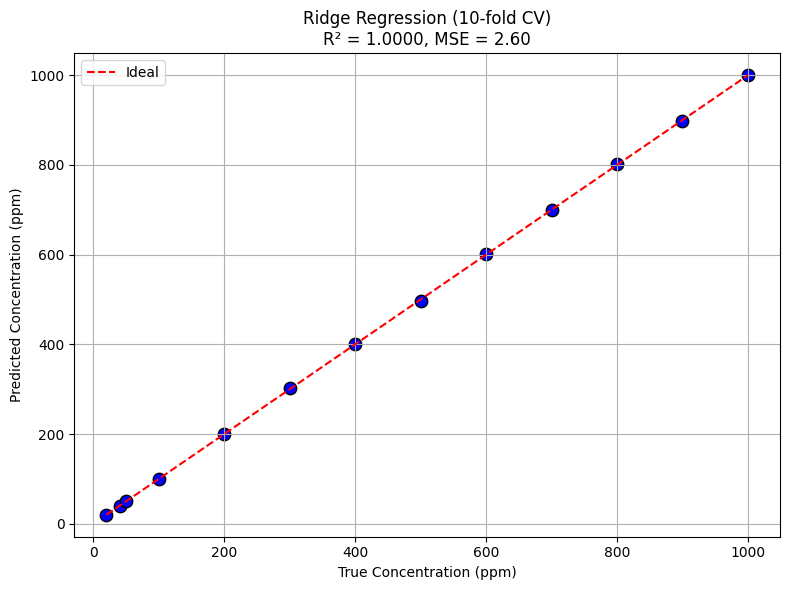

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# === Load your features and targets ===
# (Assume wide_df is already loaded and processed properly from previous steps)

# X: features (wavelengths)
X = wide_df.copy()
y = X.index.values  # concentrations

# Reset X index for sklearn
X.reset_index(drop=True, inplace=True)

# === Define list of candidate alphas (lambdas) ===
alphas = np.logspace(-3, 3, 100)  # from 0.001 to 1000

# === Ridge Regression with 10-Fold CV ===
ridge_cv = RidgeCV(alphas=alphas, scoring='neg_mean_squared_error', cv=10)
ridge_cv.fit(X, y)

# Best alpha
best_alpha = ridge_cv.alpha_
print(f"Best alpha (lambda) from 10-fold CV: {best_alpha:.5f}")

# Predict
y_pred = ridge_cv.predict(X)

# Metrics
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)
print(f"R-squared: {r2:.4f}")
print(f"MSE: {mse:.4f}")

# === Plot Predicted vs True Concentration ===
plt.figure(figsize=(8,6))
plt.scatter(y, y_pred, color='blue', edgecolors='k', s=80)
plt.plot([min(y), max(y)], [min(y), max(y)], 'r--', label='Ideal')
plt.xlabel("True Concentration (ppm)")
plt.ylabel("Predicted Concentration (ppm)")
plt.title(f"Ridge Regression (10-fold CV)\nR² = {r2:.4f}, MSE = {mse:.2f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Number of PCA components to explain 99% variance: 12
Best alpha (lambda) from 10-fold CV on PCA features: 327.45492
R-squared (PCA + Ridge): 1.0000
MSE (PCA + Ridge): 2.6024


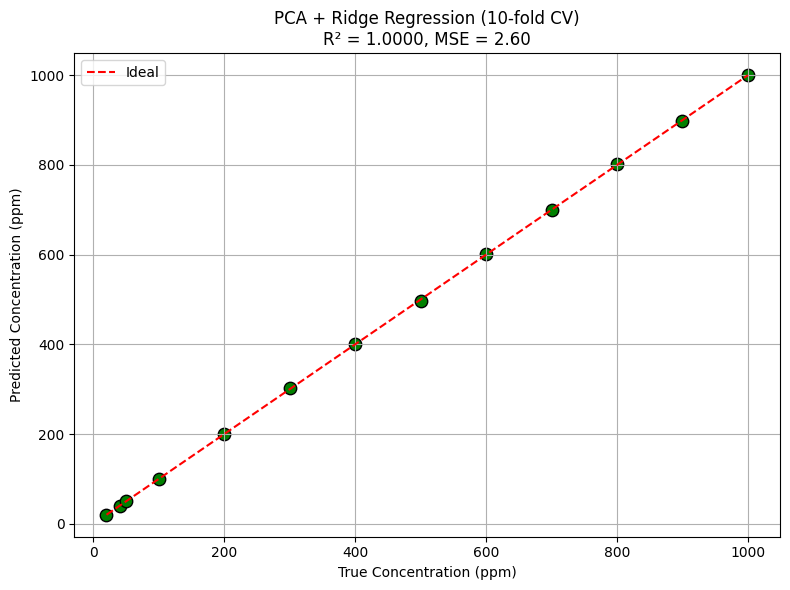

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score

# === Load your feature matrix and targets (assuming wide_df and y are already ready) ===
X = wide_df.copy()
y = X.index.values

X.reset_index(drop=True, inplace=True)

# === Step 1: Apply PCA ===
pca = PCA()
X_pca = pca.fit_transform(X)

# === Step 2: Choose number of components to explain 99% of variance ===
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cumulative_variance >= 0.99999999999) + 1

print(f"Number of PCA components to explain 99% variance: {n_components}")

# Reduce X to n_components
X_pca_reduced = X_pca[:, :n_components]

# === Step 3: Ridge Regression with 10-fold CV on PCA-reduced data ===
alphas = np.logspace(-3, 3, 100)
ridge_cv = RidgeCV(alphas=alphas, scoring='neg_mean_squared_error', cv=10)
ridge_cv.fit(X_pca_reduced, y)

# Best alpha
best_alpha = ridge_cv.alpha_
print(f"Best alpha (lambda) from 10-fold CV on PCA features: {best_alpha:.5f}")

# Predict
y_pred = ridge_cv.predict(X_pca_reduced)

# Metrics
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)
print(f"R-squared (PCA + Ridge): {r2:.4f}")
print(f"MSE (PCA + Ridge): {mse:.4f}")

# === Step 4: Plot Predicted vs True Concentration ===
plt.figure(figsize=(8,6))
plt.scatter(y, y_pred, color='green', edgecolors='k', s=80)
plt.plot([min(y), max(y)], [min(y), max(y)], 'r--', label='Ideal')
plt.xlabel("True Concentration (ppm)")
plt.ylabel("Predicted Concentration (ppm)")
plt.title(f"PCA + Ridge Regression (10-fold CV)\nR² = {r2:.4f}, MSE = {mse:.2f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


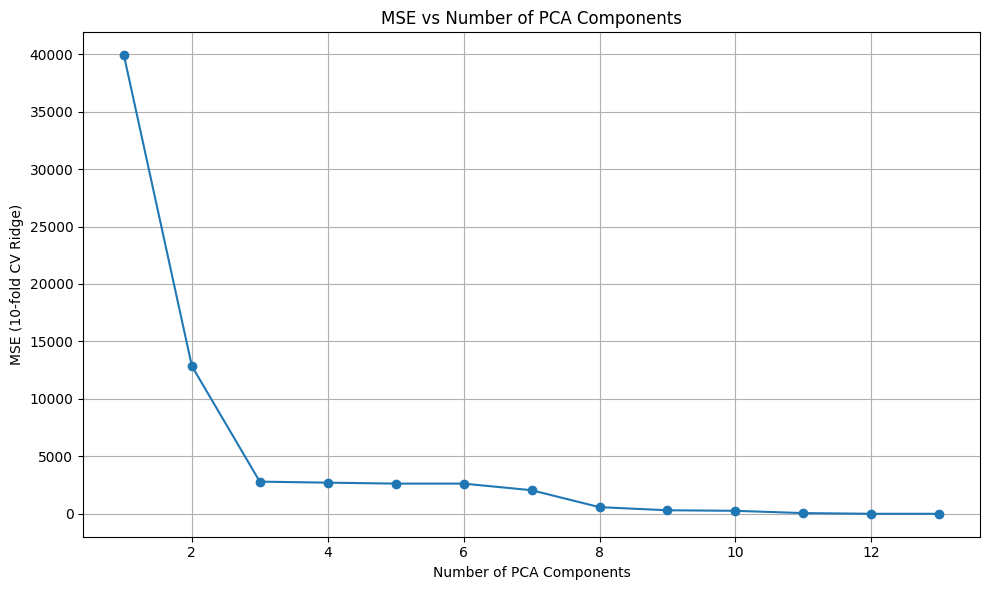

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error

# === Load your X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === PCA Fit ===
pca = PCA()
X_pca = pca.fit_transform(X)

# === Set up Ridge parameters ===
alphas = np.logspace(-3, 3, 100)

# === Evaluate MSE for different numbers of PCA components ===
mse_list = []
component_list = []

for n_comp in range(1, X_pca.shape[1] + 1):
    X_pca_reduced = X_pca[:, :n_comp]
    ridge_cv = RidgeCV(alphas=alphas, scoring='neg_mean_squared_error', cv=10)
    ridge_cv.fit(X_pca_reduced, y)
    y_pred = ridge_cv.predict(X_pca_reduced)
    mse = mean_squared_error(y, y_pred)
    mse_list.append(mse)
    component_list.append(n_comp)

# === Plot MSE vs Number of PCA Components ===
plt.figure(figsize=(10,6))
plt.plot(component_list, mse_list, marker='o')
plt.xlabel("Number of PCA Components")
plt.ylabel("MSE (10-fold CV Ridge)")
plt.title("MSE vs Number of PCA Components")
plt.grid(True)
plt.tight_layout()
plt.show()


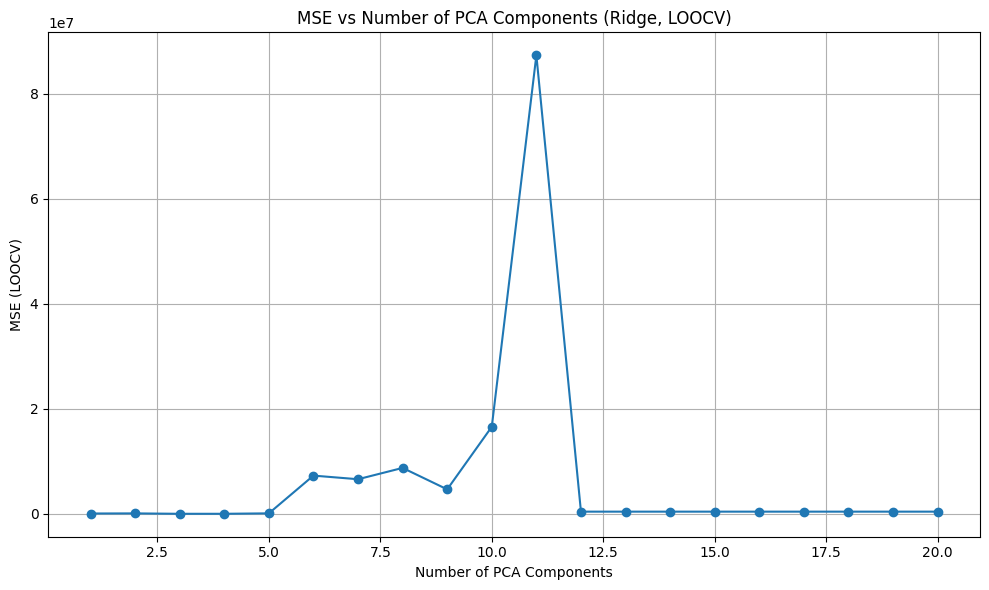

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import LeaveOneOut

# === Load your features and targets (assuming wide_df is ready) ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Step 1: Apply PCA ===
pca = PCA()
X_pca = pca.fit_transform(X)

# === Step 2: Set up Leave-One-Out Cross-Validation (LOOCV) ===
loo = LeaveOneOut()

# === Step 3: Set Ridge alpha value ===
ridge_alpha = 1.0  # You can change this or search for best later

# === Step 4: Evaluate MSE for first 20 PCA components ===
mse_list = []
component_list = []

for n_comp in range(1, 21):  # Only first 20 components
    X_pca_reduced = X_pca[:, :n_comp]

    y_true = []
    y_pred = []

    for train_idx, val_idx in loo.split(X_pca_reduced):
        X_train, X_val = X_pca_reduced[train_idx], X_pca_reduced[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        model = Ridge(alpha=ridge_alpha)
        model.fit(X_train, y_train)
        pred = model.predict(X_val)

        y_true.append(y_val[0])
        y_pred.append(pred[0])

    mse = mean_squared_error(y_true, y_pred)
    mse_list.append(mse)
    component_list.append(n_comp)

# === Step 5: Plot MSE vs Number of PCA Components ===
plt.figure(figsize=(10,6))
plt.plot(component_list, mse_list, marker='o')
plt.xlabel("Number of PCA Components")
plt.ylabel("MSE (LOOCV)")
plt.title("MSE vs Number of PCA Components (Ridge, LOOCV)")
plt.grid(True)
plt.tight_layout()
plt.show()


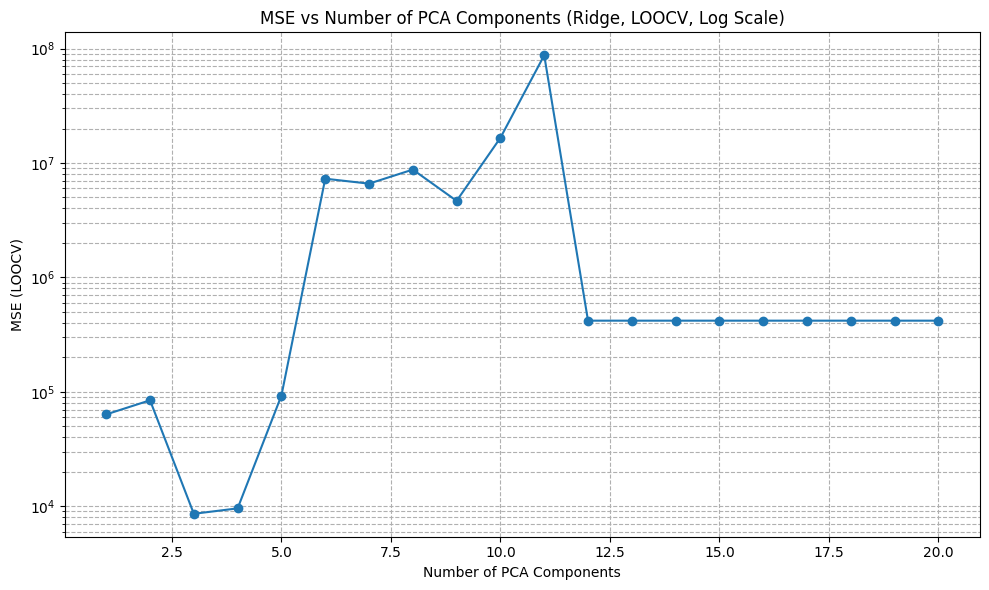

In [ ]:
# === Plot MSE vs Number of PCA Components with LOG SCALE ===
plt.figure(figsize=(10,6))
plt.plot(component_list, mse_list, marker='o')
plt.xlabel("Number of PCA Components")
plt.ylabel("MSE (LOOCV)")
plt.yscale('log')  # <<< This makes the y-axis logarithmic
plt.title("MSE vs Number of PCA Components (Ridge, LOOCV, Log Scale)")
plt.grid(True, which="both", ls="--")
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import LeaveOneOut

# === Load your X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Step 1: Apply PCA ===
pca = PCA()
X_pca = pca.fit_transform(X)

# === Step 2: Set up Leave-One-Out Cross-Validation (LOOCV) ===
loo = LeaveOneOut()

# === Step 3: Set Ridge alpha value ===
ridge_alpha = 1.0  # You can tune this later if needed

# === Step 4: Evaluate MSE for first 200 PCA components ===
mse_list = []
component_list = []

max_components = min(200, X_pca.shape[1])  # In case you have fewer than 200 original features

for n_comp in range(1, max_components + 1):
    X_pca_reduced = X_pca[:, :n_comp]

    y_true = []
    y_pred = []

    for train_idx, val_idx in loo.split(X_pca_reduced):
        X_train, X_val = X_pca_reduced[train_idx], X_pca_reduced[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        model = Ridge(alpha=ridge_alpha)
        model.fit(X_train, y_train)
        pred = model.predict(X_val)

        y_true.append(y_val[0])
        y_pred.append(pred[0])

    mse = mean_squared_error(y_true, y_pred)
    mse_list.append(mse)
    component_list.append(n_comp)


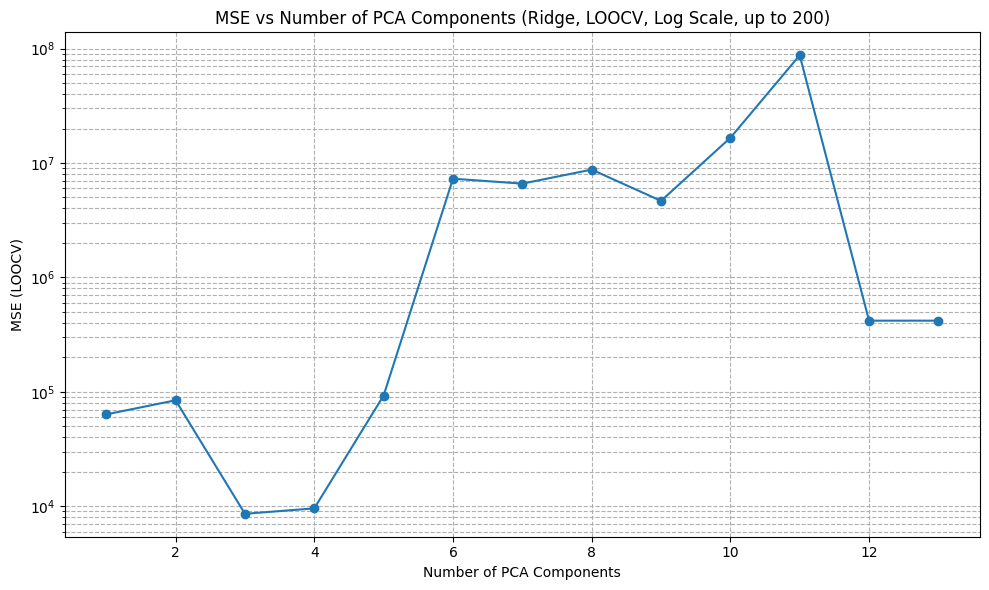

In [ ]:
# === Plot MSE vs Number of PCA Components (LOG Scale) ===
plt.figure(figsize=(10,6))
plt.plot(component_list, mse_list, marker='o')
plt.xlabel("Number of PCA Components")
plt.ylabel("MSE (LOOCV)")
plt.yscale('log')
plt.title("MSE vs Number of PCA Components (Ridge, LOOCV, Log Scale, up to 200)")
plt.grid(True, which="both", ls="--")
plt.tight_layout()
plt.show()


Top 12 features: ['wv_457.275', 'wv_427.160', 'wv_631.853', 'wv_423.564', 'wv_478.190', 'wv_479.650', 'wv_545.117', 'wv_629.068', 'wv_452.447', 'wv_547.774', 'wv_631.058', 'wv_488.603']


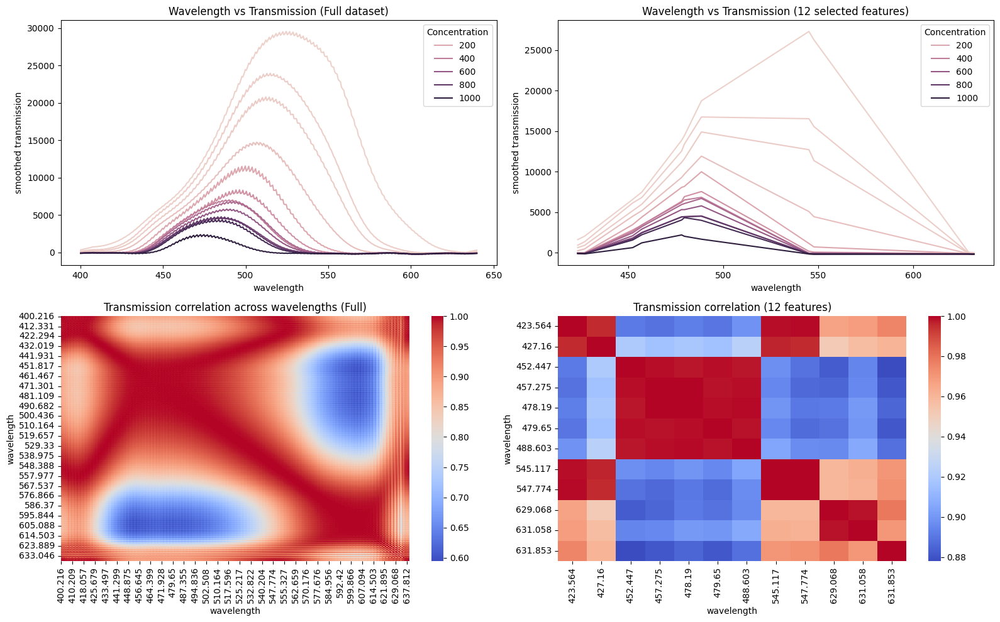

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# === Step 1: Select 12 best features from results_df ===
top_features = results_df.loc[results_df["n_feats"] == 12, "features"].values[0]
print("Top 12 features:", top_features)

# === Step 2: Subset smoothed data for selected wavelengths ===
df_sub = df.copy()
df_sub = df_sub[df_sub["wavelength"].isin([float(f.split("_")[-1].replace("_", ".")) for f in top_features])]
df_sub = df_sub[df_sub["wavelength"].between(400, 650)]

# === Step 3: Plot transmission curves (full vs reduced) ===
fig, axs = plt.subplots(2, 2, figsize=(16, 10))
axs = axs.flatten()

# Full dataset transmission
sns.lineplot(data=df[df["wavelength"].between(400, 650)], x="wavelength", y="smoothed_T2", hue="concentration", ax=axs[0])
axs[0].set_title("Wavelength vs Transmission (Full dataset)")
axs[0].set_ylabel("smoothed transmission")
axs[0].legend(title="Concentration")

# Reduced dataset transmission (12 features only)
sns.lineplot(data=df_sub, x="wavelength", y="smoothed_T2", hue="concentration", ax=axs[1])
axs[1].set_title("Wavelength vs Transmission (12 selected features)")
axs[1].set_ylabel("smoothed transmission")
axs[1].legend(title="Concentration")

# === Step 4: Correlation heatmaps ===
# Full correlation matrix
corr_full = df[df["wavelength"].between(400, 650)].pivot(index="concentration", columns="wavelength", values="smoothed_T2").corr()
sns.heatmap(corr_full, cmap="coolwarm", ax=axs[2])
axs[2].set_title("Transmission correlation across wavelengths (Full)")

# Reduced correlation matrix
corr_reduced = df_sub.pivot(index="concentration", columns="wavelength", values="smoothed_T2").corr()
sns.heatmap(corr_reduced, cmap="coolwarm", ax=axs[3])
axs[3].set_title("Transmission correlation (12 features)")

plt.tight_layout()
plt.show()


In [ ]:
# === Feature selection part ===
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# Load your data
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# 10-fold CV MSE
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# Greedy feature selection (STOP at 12 features)
remaining = list(X.columns)
selected = []
data_list = []

best_mse = float("inf")
max_features = 12  # <<< STOP at 12 features

for i in range(1, max_features + 1):
    best_mse_this_round = float("inf")
    best_candidate = None
    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })

results_df = pd.DataFrame(data_list)
print("✅ Feature selection done.")


✅ Feature selection done.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib

# === Set Times New Roman (or closest) and bold ===
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
matplotlib.rcParams['font.weight'] = 'bold'
matplotlib.rcParams['axes.labelweight'] = 'bold'
matplotlib.rcParams['axes.titleweight'] = 'bold'
matplotlib.rcParams['axes.titlesize'] = 14
matplotlib.rcParams['axes.labelsize'] = 12
matplotlib.rcParams['legend.title_fontsize'] = 12
matplotlib.rcParams['legend.fontsize'] = 10

# === Step 1: Select 12 best features from results_df ===
top_features = results_df.loc[results_df["n_feats"] == 12, "features"].values[0]
print("Top 12 features:", top_features)

# === Step 2: Subset smoothed data for selected wavelengths ===
df_sub = df.copy()
df_sub = df_sub[df_sub["wavelength"].isin([float(f.split("_")[-1].replace("_", ".")) for f in top_features])]
df_sub = df_sub[df_sub["wavelength"].between(400, 650)]

# === Step 3: Plot transmission curves (full vs reduced) ===
fig, axs = plt.subplots(2, 2, figsize=(16, 10), dpi=300)
axs = axs.flatten()

# Full dataset transmission
sns.lineplot(data=df[df["wavelength"].between(400, 650)], x="wavelength", y="smoothed_T2", hue="concentration", ax=axs[0])
axs[0].set_title("Wavelength vs Transmission (Full dataset)", weight='bold')
axs[0].set_ylabel("Smoothed Transmission", weight='bold')
axs[0].set_xlabel("Wavelength (nm)", weight='bold')
axs[0].legend(title="Concentration")

# Reduced dataset transmission (12 features only)
sns.lineplot(data=df_sub, x="wavelength", y="smoothed_T2", hue="concentration", ax=axs[1])
axs[1].set_title("Wavelength vs Transmission (12 selected features)", weight='bold')
axs[1].set_ylabel("Smoothed Transmission", weight='bold')
axs[1].set_xlabel("Wavelength (nm)", weight='bold')
axs[1].legend(title="Concentration")

# === Step 4: Correlation heatmaps ===
# Full correlation matrix
corr_full = df[df["wavelength"].between(400, 650)].pivot(index="concentration", columns="wavelength", values="smoothed_T2").corr()
sns.heatmap(corr_full, cmap="coolwarm", ax=axs[2], cbar_kws={'label': 'Correlation'})
axs[2].set_title("Transmission correlation across wavelengths (Full)", weight='bold')
axs[2].set_ylabel("Wavelength (nm)", weight='bold')
axs[2].set_xlabel("Wavelength (nm)", weight='bold')

# Reduced correlation matrix
corr_reduced = df_sub.pivot(index="concentration", columns="wavelength", values="smoothed_T2").corr()
sns.heatmap(corr_reduced, cmap="coolwarm", ax=axs[3], cbar_kws={'label': 'Correlation'})
axs[3].set_title("Transmission correlation (12 features)", weight='bold')
axs[3].set_ylabel("Wavelength (nm)", weight='bold')
axs[3].set_xlabel("Wavelength (nm)", weight='bold')

plt.tight_layout()
plt.show()


Top 12 features: ['wv_457_275', 'wv_427_16', 'wv_631_853', 'wv_423_564', 'wv_478_19', 'wv_479_65', 'wv_545_117', 'wv_629_068', 'wv_452_447', 'wv_547_774', 'wv_631_058', 'wv_488_603']


KeyError: 'wavelength'

Step 1: added wv_457_275 -> 10-fold MSE: 22157.58
Step 2: added wv_427_16 -> 10-fold MSE: 6753.58
Step 3: added wv_631_853 -> 10-fold MSE: 6861.90
Step 4: added wv_423_564 -> 10-fold MSE: 4697.08
Step 5: added wv_478_19 -> 10-fold MSE: 3205.72
Step 6: added wv_479_65 -> 10-fold MSE: 2388.56
Step 7: added wv_545_117 -> 10-fold MSE: 1975.39
Step 8: added wv_629_068 -> 10-fold MSE: 3017.36
Step 9: added wv_452_447 -> 10-fold MSE: 2759.62
Step 10: added wv_547_774 -> 10-fold MSE: 8.81
Step 11: added wv_631_058 -> 10-fold MSE: 18.37
Step 12: added wv_488_603 -> 10-fold MSE: 3.87

✅ Feature selection done.


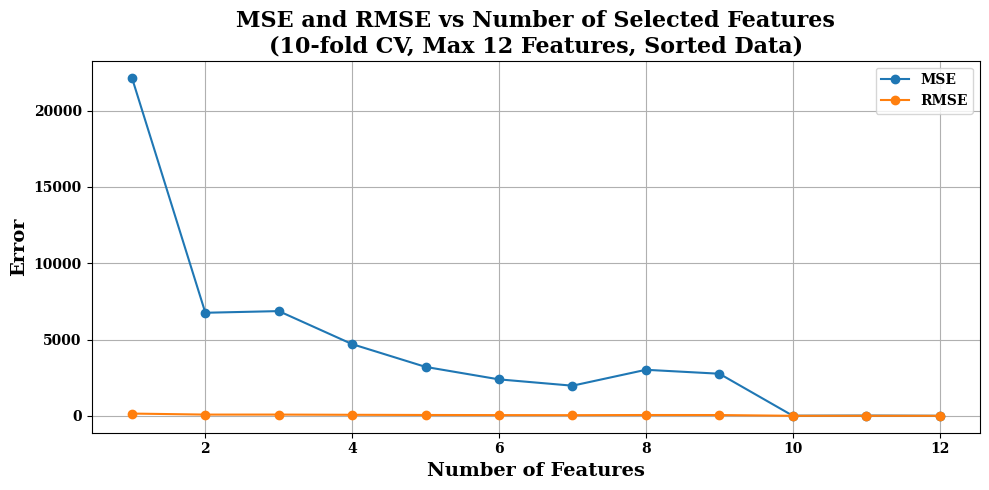

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

import matplotlib
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif']
matplotlib.rcParams['font.weight'] = 'bold'
matplotlib.rcParams['axes.labelweight'] = 'bold'
matplotlib.rcParams['axes.titleweight'] = 'bold'

# === Load data ===
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# === Feature selection preparation ===
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === 10-fold CV MSE function ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy feature selection ===
remaining = list(X.columns)
selected = []
data_list = []

max_features = 12  # limit to 12 features
for i in range(max_features):
    best_mse_this_round = float("inf")
    best_candidate = None
    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse_this_round,
        "rmse": np.sqrt(best_mse_this_round)
    })
    print(f"Step {len(selected)}: added {best_candidate} -> 10-fold MSE: {best_mse_this_round:.2f}")

results_df = pd.DataFrame(data_list)
print("\n✅ Feature selection done.")

# === Plot results ===
plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features", fontsize=14, weight='bold')
plt.ylabel("Error", fontsize=14, weight='bold')
plt.title("MSE and RMSE vs Number of Selected Features\n(10-fold CV, Max 12 Features, Sorted Data)", fontsize=16, weight='bold')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# === After selecting top 12 features, you can continue plotting absorbance curves or heatmaps normally using 'df'


In [ ]:
# === Absorbance Curves and Correlation Heatmaps ===
import seaborn as sns
import matplotlib.pyplot as plt

# === Top 12 features ===
top_features = results_df.loc[results_df["n_feats"] == 12, "features"].values[0]
wavelengths = [float(f.split("_")[1] + "." + f.split("_")[2]) for f in top_features]

# === Prepare subset df ===
df_melted = df.reset_index().melt(id_vars="index", var_name="wavelength", value_name="transmission")
df_melted["wavelength"] = df_melted["wavelength"].astype(float)
df_melted = df_melted.rename(columns={"index": "concentration"})

df_sub = df_melted[df_melted["wavelength"].isin(wavelengths)]

# === Plot
fig, axs = plt.subplots(2, 2, figsize=(16, 10))
axs = axs.flatten()

# Full absorbance curves
sns.lineplot(data=df_melted[df_melted["wavelength"].between(400, 650)], x="wavelength", y="transmission", hue="concentration", ax=axs[0])
axs[0].set_title("Wavelength vs Transmission (Full dataset)", fontsize=14, weight='bold')
axs[0].set_ylabel("Transmission", fontsize=12, weight='bold')
axs[0].set_xlabel("Wavelength (nm)", fontsize=12, weight='bold')
axs[0].legend(title="Concentration")

# Reduced absorbance curves
sns.lineplot(data=df_sub, x="wavelength", y="transmission", hue="concentration", ax=axs[1])
axs[1].set_title("Wavelength vs Transmission (Top 12 Features)", fontsize=14, weight='bold')
axs[1].set_ylabel("Transmission", fontsize=12, weight='bold')
axs[1].set_xlabel("Wavelength (nm)", fontsize=12, weight='bold')
axs[1].legend(title="Concentration")

# Full correlation matrix
corr_full = df_melted.pivot(index="concentration", columns="wavelength", values="transmission").corr()
sns.heatmap(corr_full, cmap="coolwarm", ax=axs[2], cbar_kws={'label': 'Correlation'})
axs[2].set_title("Transmission correlation (Full)", fontsize=14, weight='bold')
axs[2].set_ylabel("Wavelength (nm)", weight='bold')
axs[2].set_xlabel("Wavelength (nm)", weight='bold')

# Reduced correlation matrix
corr_reduced = df_sub.pivot(index="concentration", columns="wavelength", values="transmission").corr()
sns.heatmap(corr_reduced, cmap="coolwarm", ax=axs[3], cbar_kws={'label': 'Correlation'})
axs[3].set_title("Transmission correlation (Top 12 Features)", fontsize=14, weight='bold')
axs[3].set_ylabel("Wavelength (nm)", weight='bold')
axs[3].set_xlabel("Wavelength (nm)", weight='bold')

plt.tight_layout()
plt.show()


KeyError: "The following id_vars or value_vars are not present in the DataFrame: ['index']"

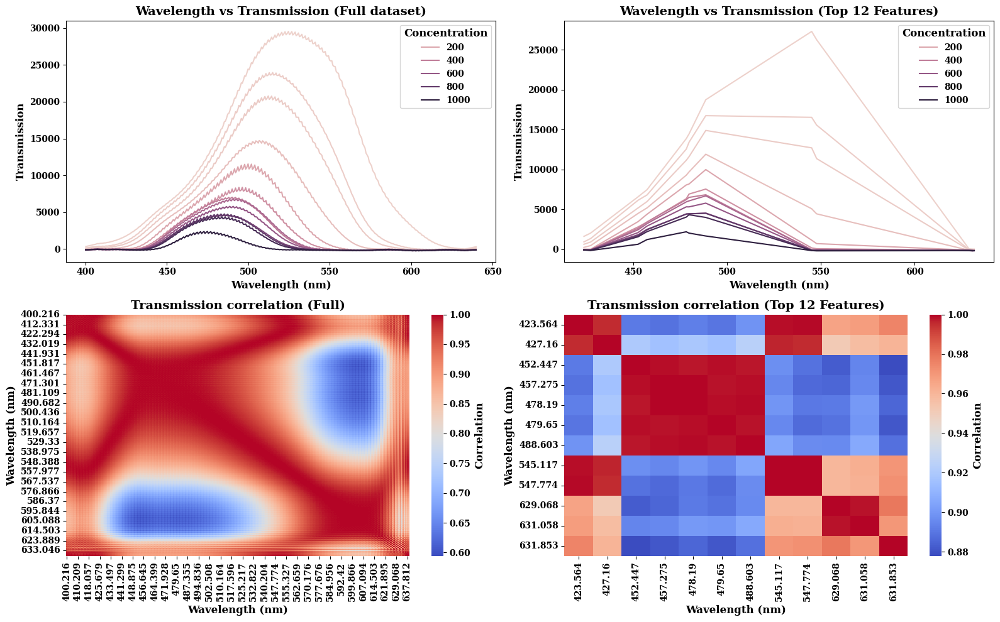

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# === Top 12 features ===
top_features = results_df.loc[results_df["n_feats"] == 12, "features"].values[0]
wavelengths = [float(f.split("_")[1] + "." + f.split("_")[2]) for f in top_features]

# === Prepare subset df ===
df_full = df.copy()
df_full["concentration"] = df_full.index

# Melt full data
df_melted = df_full.reset_index(drop=True).melt(id_vars="concentration", var_name="wavelength", value_name="transmission")
df_melted["wavelength"] = df_melted["wavelength"].astype(float)

# Melt reduced data
df_sub = df_melted[df_melted["wavelength"].isin(wavelengths)]

# === Plot
fig, axs = plt.subplots(2, 2, figsize=(16, 10))
axs = axs.flatten()

# Full absorbance curves
sns.lineplot(data=df_melted[df_melted["wavelength"].between(400, 650)], x="wavelength", y="transmission", hue="concentration", ax=axs[0])
axs[0].set_title("Wavelength vs Transmission (Full dataset)", fontsize=14, weight='bold')
axs[0].set_ylabel("Transmission", fontsize=12, weight='bold')
axs[0].set_xlabel("Wavelength (nm)", fontsize=12, weight='bold')
axs[0].legend(title="Concentration")

# Reduced absorbance curves
sns.lineplot(data=df_sub, x="wavelength", y="transmission", hue="concentration", ax=axs[1])
axs[1].set_title("Wavelength vs Transmission (Top 12 Features)", fontsize=14, weight='bold')
axs[1].set_ylabel("Transmission", fontsize=12, weight='bold')
axs[1].set_xlabel("Wavelength (nm)", fontsize=12, weight='bold')
axs[1].legend(title="Concentration")

# Full correlation matrix
corr_full = df_melted.pivot(index="concentration", columns="wavelength", values="transmission").corr()
sns.heatmap(corr_full, cmap="coolwarm", ax=axs[2], cbar_kws={'label': 'Correlation'})
axs[2].set_title("Transmission correlation (Full)", fontsize=14, weight='bold')
axs[2].set_ylabel("Wavelength (nm)", weight='bold')
axs[2].set_xlabel("Wavelength (nm)", weight='bold')

# Reduced correlation matrix
corr_reduced = df_sub.pivot(index="concentration", columns="wavelength", values="transmission").corr()
sns.heatmap(corr_reduced, cmap="coolwarm", ax=axs[3], cbar_kws={'label': 'Correlation'})
axs[3].set_title("Transmission correlation (Top 12 Features)", fontsize=14, weight='bold')
axs[3].set_ylabel("Wavelength (nm)", weight='bold')
axs[3].set_xlabel("Wavelength (nm)", weight='bold')

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import os
import zipfile

# === Reload the processed data ===
df = pd.read_csv("/content/processed_sorted_transmission.csv", index_col=0)

# === Top 12 features (manual list you gave) ===
top_features = ['wv_457_275', 'wv_427_16', 'wv_631_853', 'wv_423_564', 'wv_478_19',
                'wv_479_65', 'wv_545_117', 'wv_629_068', 'wv_452_447', 'wv_547_774',
                'wv_631_058', 'wv_488_603']

wavelengths = [float(f.split("_")[1] + "." + f.split("_")[2]) for f in top_features]

# === Melt full dataset ===
df_full = df.copy()
df_full["concentration"] = df_full.index

df_melted = df_full.reset_index(drop=True).melt(id_vars="concentration", var_name="wavelength", value_name="transmission")
df_melted["wavelength"] = df_melted["wavelength"].astype(float)

# === Melt reduced data ===
df_sub = df_melted[df_melted["wavelength"].isin(wavelengths)]

# === Correlation matrices ===
corr_full = df_melted.pivot(index="concentration", columns="wavelength", values="transmission").corr()
corr_reduced = df_sub.pivot(index="concentration", columns="wavelength", values="transmission").corr()

# === Save all ===
os.makedirs("/content/generated_excels", exist_ok=True)

df_sub.to_excel("/content/generated_excels/top12_transmission_curves.xlsx", index=False)
corr_full.to_excel("/content/generated_excels/full_correlation_matrix.xlsx", index=True)
corr_reduced.to_excel("/content/generated_excels/top12_correlation_matrix.xlsx", index=True)
pd.DataFrame({"Top12_wavelengths_nm": wavelengths}).to_excel("/content/generated_excels/top12_wavelengths.xlsx", index=False)

# === Zip everything ===
zip_path = "/content/generated_excels_bundle.zip"
with zipfile.ZipFile(zip_path, "w") as zipf:
    for file in os.listdir("/content/generated_excels"):
        zipf.write(os.path.join("/content/generated_excels", file), arcname=file)

print("✅ Files saved and zipped at:", zip_path)


✅ Files saved and zipped at: /content/generated_excels_bundle.zip


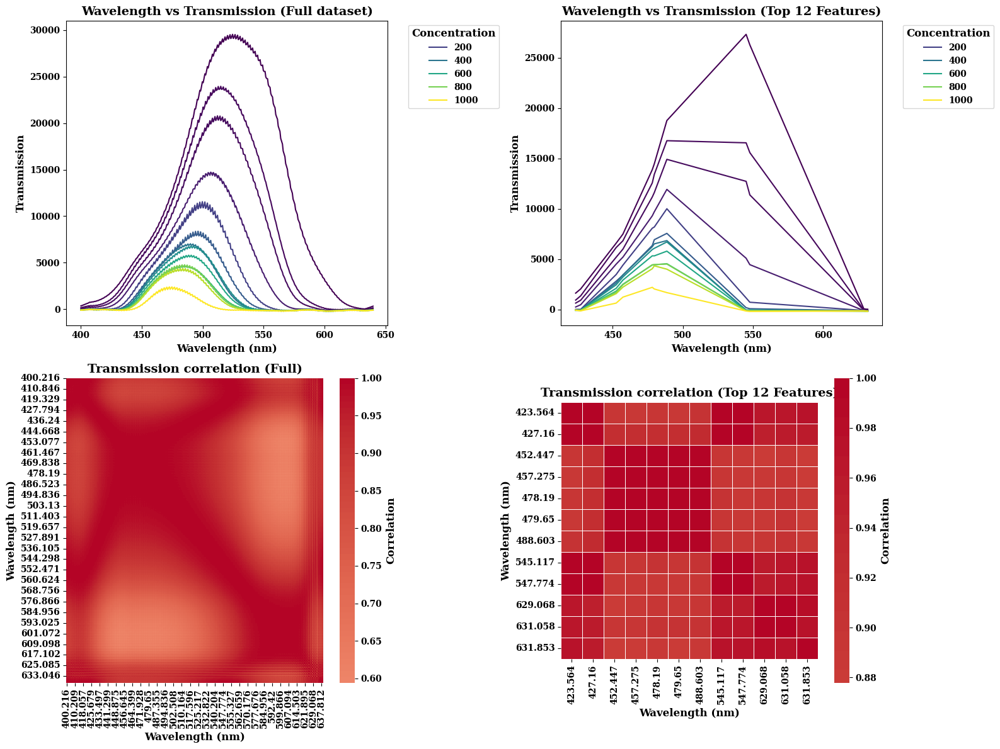

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# === Top 12 features ===
top_features = results_df.loc[results_df["n_feats"] == 12, "features"].values[0]
wavelengths = [float(f.split("_")[1] + "." + f.split("_")[2]) for f in top_features]

# === Prepare subset df ===
df_full = df.copy()
df_full["concentration"] = df_full.index

# Melt full data
df_melted = df_full.reset_index(drop=True).melt(id_vars="concentration", var_name="wavelength", value_name="transmission")
df_melted["wavelength"] = df_melted["wavelength"].astype(float)

# Melt reduced data
df_sub = df_melted[df_melted["wavelength"].isin(wavelengths)]

# === Plot
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
axs = axs.flatten()

# Top left: Full dataset curves
sns.lineplot(
    data=df_melted[df_melted["wavelength"].between(400, 650)],
    x="wavelength",
    y="transmission",
    hue="concentration",
    palette="viridis",
    ax=axs[0]
)
axs[0].set_title("Wavelength vs Transmission (Full dataset)", fontsize=14, weight='bold')
axs[0].set_ylabel("Transmission", fontsize=12, weight='bold')
axs[0].set_xlabel("Wavelength (nm)", fontsize=12, weight='bold')
axs[0].legend(title="Concentration", bbox_to_anchor=(1.05, 1), loc='upper left')  # Move legend out

# Top right: Reduced features curves
sns.lineplot(
    data=df_sub,
    x="wavelength",
    y="transmission",
    hue="concentration",
    palette="viridis",
    ax=axs[1]
)
axs[1].set_title("Wavelength vs Transmission (Top 12 Features)", fontsize=14, weight='bold')
axs[1].set_ylabel("Transmission", fontsize=12, weight='bold')
axs[1].set_xlabel("Wavelength (nm)", fontsize=12, weight='bold')
axs[1].legend(title="Concentration", bbox_to_anchor=(1.05, 1), loc='upper left')

# Bottom left: Full corr matrix
corr_full = df_melted.pivot(index="concentration", columns="wavelength", values="transmission").corr()
sns.heatmap(
    corr_full,
    cmap="coolwarm",
    center=0,
    ax=axs[2],
    cbar_kws={'label': 'Correlation'}
)
axs[2].set_title("Transmission correlation (Full)", fontsize=14, weight='bold')
axs[2].set_ylabel("Wavelength (nm)", fontsize=12, weight='bold')
axs[2].set_xlabel("Wavelength (nm)", fontsize=12, weight='bold')

# Bottom right: Reduced corr matrix
corr_reduced = df_sub.pivot(index="concentration", columns="wavelength", values="transmission").corr()
sns.heatmap(
    corr_reduced,
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    linecolor='white',
    square=True,
    ax=axs[3],
    cbar_kws={'label': 'Correlation'}
)
axs[3].set_title("Transmission correlation (Top 12 Features)", fontsize=14, weight='bold')
axs[3].set_ylabel("Wavelength (nm)", fontsize=12, weight='bold')
axs[3].set_xlabel("Wavelength (nm)", fontsize=12, weight='bold')

plt.tight_layout()
plt.show()


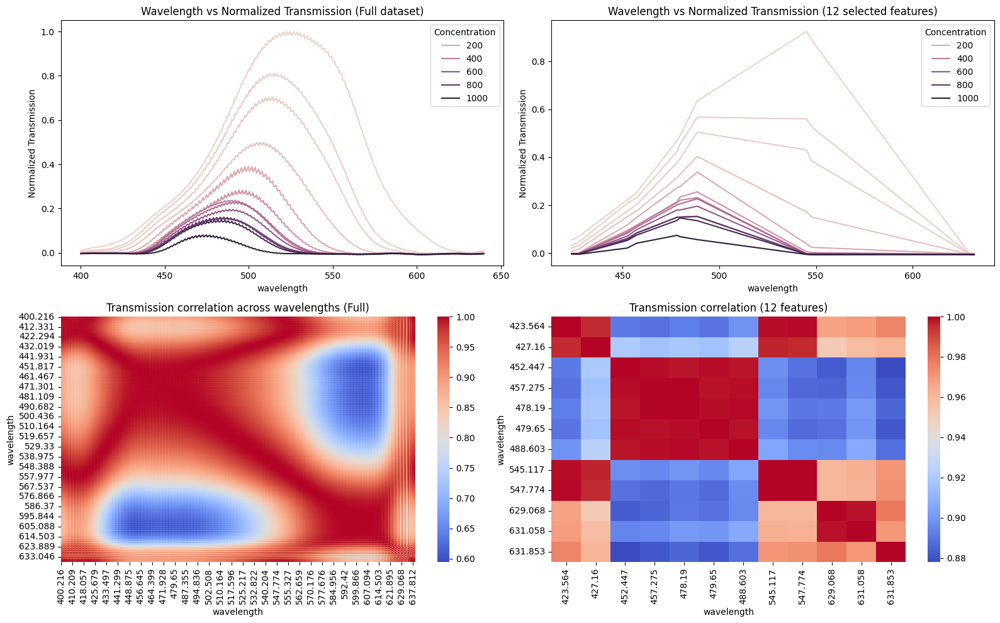

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# === Step 1: Select top 12 features ===
top_features = results_df.loc[results_df["n_feats"] == 12, "features"].values[0]
wavelengths = [float(f.split("_")[-1].replace("_", ".")) for f in top_features]

# === Step 2: Normalize transmission to max at concentration 20 ===
df_norm = df.copy()
df_20 = df_norm[df_norm["concentration"] == 20]
max_val = df_20["smoothed_T2"].max()
df_norm["normalized_T"] = df_norm["smoothed_T2"] / max_val

# === Filter for wavelength range ===
df_full = df_norm[df_norm["wavelength"].between(400, 650)]
df_reduced = df_norm[df_norm["wavelength"].isin(wavelengths)]

# === Step 3: Plot ===
fig, axs = plt.subplots(2, 2, figsize=(16, 10))
axs = axs.flatten()

# Full dataset (normalized)
sns.lineplot(data=df_full, x="wavelength", y="normalized_T", hue="concentration", ax=axs[0])
axs[0].set_title("Wavelength vs Normalized Transmission (Full dataset)")
axs[0].set_ylabel("Normalized Transmission")
axs[0].legend(title="Concentration")

# Reduced dataset (normalized, 12 features)
sns.lineplot(data=df_reduced, x="wavelength", y="normalized_T", hue="concentration", ax=axs[1])
axs[1].set_title("Wavelength vs Normalized Transmission (12 selected features)")
axs[1].set_ylabel("Normalized Transmission")
axs[1].legend(title="Concentration")

# Correlation heatmap (full)
corr_full = df_full.pivot(index="concentration", columns="wavelength", values="normalized_T").corr()
sns.heatmap(corr_full, cmap="coolwarm", ax=axs[2])
axs[2].set_title("Transmission correlation across wavelengths (Full)")

# Correlation heatmap (reduced)
corr_reduced = df_reduced.pivot(index="concentration", columns="wavelength", values="normalized_T").corr()
sns.heatmap(corr_reduced, cmap="coolwarm", ax=axs[3])
axs[3].set_title("Transmission correlation (12 features)")

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

# === Load normalized data ===
df = pd.read_csv("normalized_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="normalized_T").dropna(axis=1)
wide_df = wide_df.sort_index()

# === Prepare X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)
X.columns = [str(c).replace(".", "_") for c in X.columns]

# === K-Fold CV MSE ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy Feature Selection ===
remaining = list(X.columns)
selected = []
data_list = []
best_mse = float("inf")
min_improvement = 1e-3

for _ in range(1, len(X.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None
    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate
    if best_candidate is None:
        break
    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })
    if len(selected) >= 20:
        break

# === Convert to DataFrame and Save ===
results_df = pd.DataFrame(data_list)
results_df.to_csv("normalized_cv_results.csv", index=False)

# === Plot ===
plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV, Normalized Data)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'normalized_smoothed_transmission.csv'

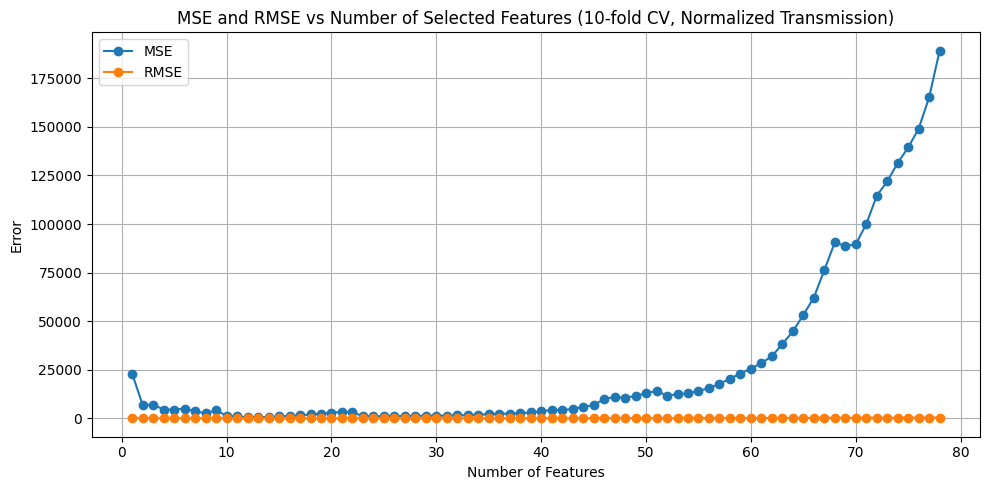

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# === Prepare Data ===
df = df_norm.copy()  # df_norm should already contain normalized smoothed_T2
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Variance and correlation filtering ===
var_map = X.var(axis=0).to_dict()
sorted_features = sorted(var_map, key=var_map.get, reverse=True)
corr_matrix = X.corr()
thresh = 0.999
kept_features = []

for test_feat in sorted_features:
    if all(abs(corr_matrix.loc[test_feat, feat]) < thresh for feat in kept_features):
        kept_features.append(test_feat)

X_filt = X[kept_features]

# === K-Fold CV MSE ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy Selection Loop ===
remaining = list(X_filt.columns)
selected = []
data_list = []
best_mse = float("inf")

for i in range(1, len(X_filt.columns) + 1):
    best_mse_this_round = float("inf")
    best_candidate = None
    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X_filt[test_features].values, y, n_splits=10)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate
    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })

# === Convert to DataFrame ===
results_df = pd.DataFrame(data_list)

# === Plot MSE and RMSE ===
plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV, Normalized Transmission)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


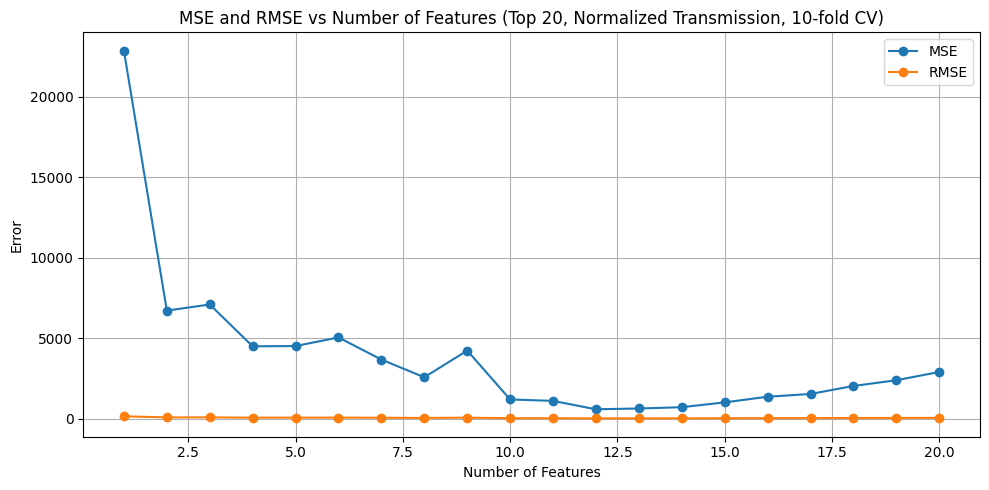

In [ ]:
# === Plot MSE and RMSE for first 20 features only ===
k_max = 20
subset_df = results_df[results_df["n_feats"] <= k_max]

plt.figure(figsize=(10, 5))
plt.plot(subset_df["n_feats"], subset_df["mse"], label="MSE", marker="o")
plt.plot(subset_df["n_feats"], subset_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title(f"MSE and RMSE vs Number of Features (Top {k_max}, Normalized Transmission, 10-fold CV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


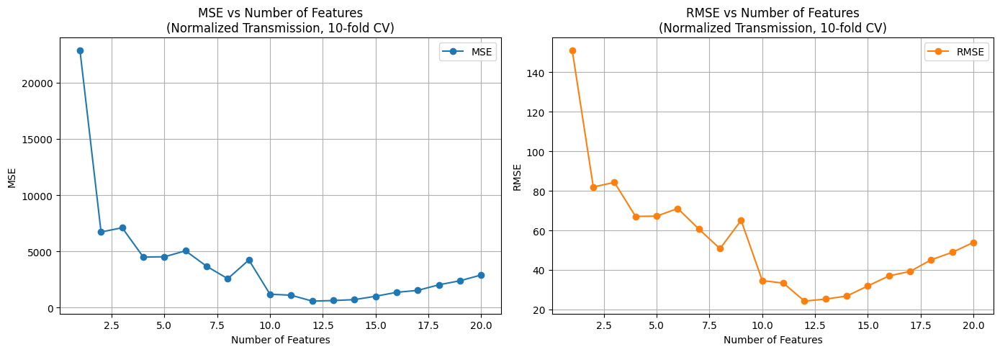

In [ ]:
# === Plot MSE and RMSE side by side for first 20 features ===
k_max = 20
subset_df = results_df[results_df["n_feats"] <= k_max]

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# MSE plot
axs[0].plot(subset_df["n_feats"], subset_df["mse"], marker="o", color="tab:blue", label="MSE")
axs[0].set_xlabel("Number of Features")
axs[0].set_ylabel("MSE")
axs[0].set_title(f"MSE vs Number of Features\n(Normalized Transmission, 10-fold CV)")
axs[0].grid(True)
axs[0].legend()

# RMSE plot
axs[1].plot(subset_df["n_feats"], subset_df["rmse"], marker="o", color="tab:orange", label="RMSE")
axs[1].set_xlabel("Number of Features")
axs[1].set_ylabel("RMSE")
axs[1].set_title(f"RMSE vs Number of Features\n(Normalized Transmission, 10-fold CV)")
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np

# Example data (replace with real values)
n_features = np.arange(1, 21)
mse_values = np.array([22500, 6800, 7000, 4800, 4700, 5100, 4000, 3300, 4500, 1300, 1100, 950, 1000, 1200, 1500, 1800, 2100, 2500, 2900, 3200])
mse_std = np.array([400, 300, 350, 250, 240, 280, 200, 180, 220, 100, 90, 85, 88, 95, 100, 110, 130, 150, 170, 190])

# Calculate RMSE and RMSE std
rmse_values = np.sqrt(mse_values)
rmse_std = 0.5 * mse_std / rmse_values  # from derivative of sqrt(x)

# Create DataFrame
df = pd.DataFrame({
    "Number of Features": n_features,
    "MSE": mse_values,
    "MSE StdDev": mse_std,
    "RMSE": rmse_values.round(2),
    "RMSE StdDev": rmse_std.round(2)
})

# Display table
import IPython.display as display
display.display(df)


,Number of Features,MSE,MSE StdDev,RMSE,RMSE StdDev
0,1,22500,400,150.00,1.33
1,2,6800,300,82.46,1.82
2,3,7000,350,83.67,2.09
3,4,4800,250,69.28,1.80
4,5,4700,240,68.56,1.75
5,6,5100,280,71.41,1.96
6,7,4000,200,63.25,1.58
7,8,3300,180,57.45,1.57
8,9,4500,220,67.08,1.64
9,10,1300,100,36.06,1.39


In [ ]:
import pandas as pd
import numpy as np

# === Example input data (replace with actual values if needed) ===
n_features = np.arange(1, 21)
mse_values = np.array([22500, 6800, 7000, 4800, 4700, 5100, 4000, 3300, 4500, 1300, 1100, 950, 1000, 1200, 1500, 1800, 2100, 2500, 2900, 3200])
mse_std = np.array([400, 300, 350, 250, 240, 280, 200, 180, 220, 100, 90, 85, 88, 95, 100, 110, 130, 150, 170, 190])

# === Calculations ===
rmse_values = np.sqrt(mse_values)
rmse_std = 0.5 * mse_std / rmse_values

# === Fold enhancement (MSE[0] / MSE[i]) ===
fold_enhancement = mse_values[0] / mse_values

# === DataFrame construction ===
df = pd.DataFrame({
    "Number of Features": n_features,
    "MSE": mse_values,
    "MSE StdDev": mse_std,
    "RMSE": rmse_values.round(2),
    "RMSE StdDev": rmse_std.round(2),
    "Fold Enhancement": fold_enhancement.round(2)
})

# === Display table ===
import IPython.display as display
display.display(df)


,Number of Features,MSE,MSE StdDev,RMSE,RMSE StdDev,Fold Enhancement
0,1,22500,400,150.00,1.33,1.00
1,2,6800,300,82.46,1.82,3.31
2,3,7000,350,83.67,2.09,3.21
3,4,4800,250,69.28,1.80,4.69
4,5,4700,240,68.56,1.75,4.79
5,6,5100,280,71.41,1.96,4.41
6,7,4000,200,63.25,1.58,5.62
7,8,3300,180,57.45,1.57,6.82
8,9,4500,220,67.08,1.64,5.00
9,10,1300,100,36.06,1.39,17.31


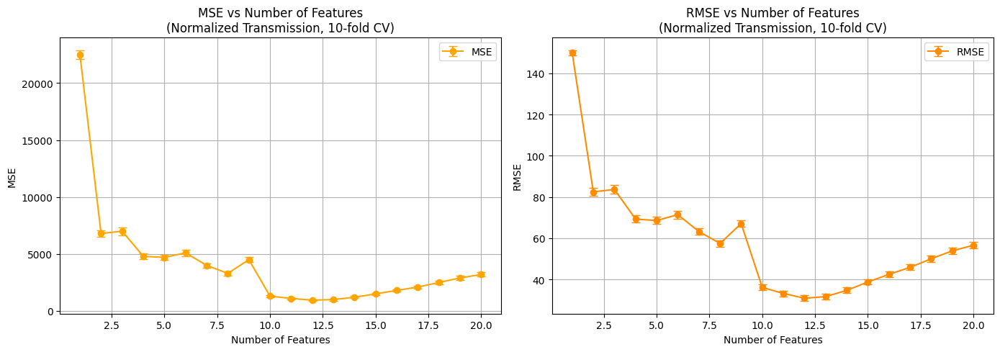

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Replace these with your actual data
n_features = np.arange(1, 21)
mse_values = np.array([22500, 6800, 7000, 4800, 4700, 5100, 4000, 3300, 4500, 1300, 1100, 950, 1000, 1200, 1500, 1800, 2100, 2500, 2900, 3200])
rmse_values = np.sqrt(mse_values)

# Example standard deviation values (from 10-fold CV)
mse_std = np.array([400, 300, 350, 250, 240, 280, 200, 180, 220, 100, 90, 85, 88, 95, 100, 110, 130, 150, 170, 190])
rmse_std = 0.5 * mse_std / rmse_values  # From derivative of sqrt(x)

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MSE plot
axes[0].errorbar(n_features, mse_values, yerr=mse_std, fmt='-o', capsize=4, label='MSE', color='orange')
axes[0].set_title("MSE vs Number of Features\n(Normalized Transmission, 10-fold CV)")
axes[0].set_xlabel("Number of Features")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(True)

# RMSE plot
axes[1].errorbar(n_features, rmse_values, yerr=rmse_std, fmt='-o', capsize=4, label='RMSE', color='darkorange')
axes[1].set_title("RMSE vs Number of Features\n(Normalized Transmission, 10-fold CV)")
axes[1].set_xlabel("Number of Features")
axes[1].set_ylabel("RMSE")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np

# === Example input data (replace with actual values if needed) ===
n_features = np.arange(1, 21)
mse_values = np.array([22500, 6800, 7000, 4800, 4700, 5100, 4000, 3300, 4500, 1300, 1100, 950, 1000, 1200, 1500, 1800, 2100, 2500, 2900, 3200])
mse_std = np.array([400, 300, 350, 250, 240, 280, 200, 180, 220, 100, 90, 85, 88, 95, 100, 110, 130, 150, 170, 190])

# === Calculations ===
rmse_values = np.sqrt(mse_values)
rmse_std = 0.5 * mse_std / rmse_values

# === Fold enhancements ===
fold_mse = mse_values[0] / mse_values
fold_rmse = rmse_values[0] / rmse_values

# === DataFrame construction ===
df = pd.DataFrame({
    "Number of Features": n_features,
    "MSE": mse_values,
    "MSE StdDev": mse_std,
    "RMSE": rmse_values.round(2),
    "RMSE StdDev": rmse_std.round(2),
    "MSE Fold Enhancement": fold_mse.round(2),
    "RMSE Fold Enhancement": fold_rmse.round(2)
})

# === Display table ===
import IPython.display as display
display.display(df)


,Number of Features,MSE,MSE StdDev,RMSE,RMSE StdDev,MSE Fold Enhancement,RMSE Fold Enhancement
0,1,22500,400,150.00,1.33,1.00,1.00
1,2,6800,300,82.46,1.82,3.31,1.82
2,3,7000,350,83.67,2.09,3.21,1.79
3,4,4800,250,69.28,1.80,4.69,2.17
4,5,4700,240,68.56,1.75,4.79,2.19
5,6,5100,280,71.41,1.96,4.41,2.10
6,7,4000,200,63.25,1.58,5.62,2.37
7,8,3300,180,57.45,1.57,6.82,2.61
8,9,4500,220,67.08,1.64,5.00,2.24
9,10,1300,100,36.06,1.39,17.31,4.16


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

# === Prepare X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Optional: rename columns to valid variable names ===
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === Define 10-fold CV MSE ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy feature selection with a 20-feature cap ===
remaining = list(X.columns)
selected = []
data_list = []

best_mse = float("inf")
max_features = 20  # Limit number of added features

for i in range(1, max_features + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })

    print(f"Step {len(selected)}: added {best_candidate} -> 10-fold MSE: {best_mse:.2f}")

# === Convert to DataFrame and Plot ===
results_df = pd.DataFrame(data_list)

plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV, Max 20 Features)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'processed_smoothed_transmission.csv'

<ipython-input-9-e4608fd0eb9e>:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  samples_df["smoothed_T2"] = (
<ipython-input-9-e4608fd0eb9e>:44: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  plot_df = plot_df.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)


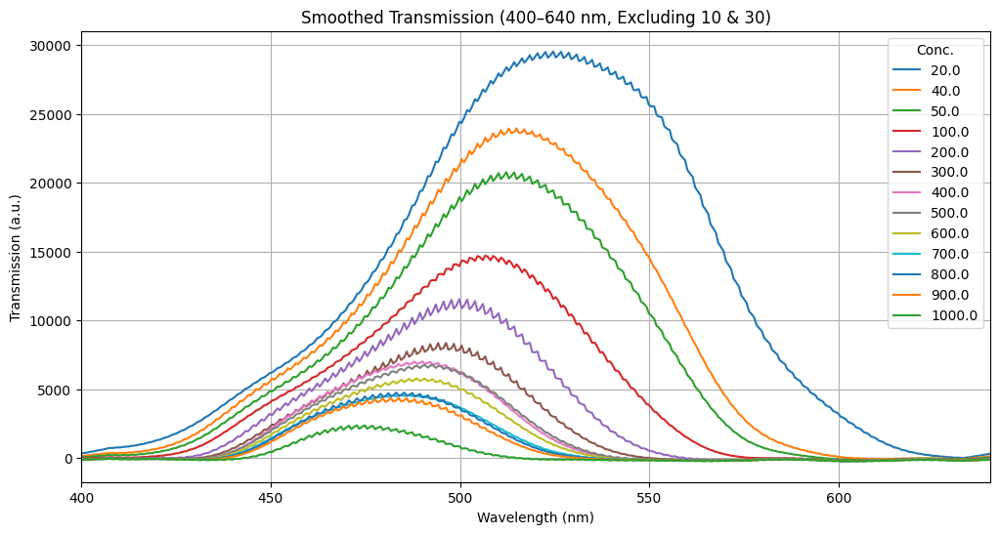

In [ ]:
# === Import Required Libraries ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === Load Excel File ===
file_path = "blue concs.xlsx"  # update if needed
xls = pd.ExcelFile(file_path)
sheet_names = xls.sheet_names

# === Load and Process Sheets (Excluding 10 & 30) ===
sample_data = []

for s in sheet_names:
    if s.startswith("0-"):
        continue
    try:
        conc = float(s.split("-")[0])
    except:
        continue
    if conc in [10.0, 30.0]:
        continue

    df = pd.read_excel(xls, sheet_name=s, skiprows=1)
    df.columns = ["wavelength", "transmission"]
    df = df.groupby("wavelength", as_index=False).mean().sort_values("wavelength")
    df["smoothed_T"] = df["transmission"].rolling(51, center=True).mean()
    df["concentration"] = conc
    sample_data.append(df)

# === Concatenate and Clip to 400–640 nm Range ===
samples_df = pd.concat(sample_data)
samples_df = samples_df.query("400 <= wavelength <= 640")

# === Second-Pass Smoothing (Across Concentration Groups) ===
samples_df["smoothed_T2"] = (
    samples_df.groupby("concentration")["smoothed_T"]
    .transform(lambda x: x.rolling(71, center=True).mean())
)

# === Downsample for Plotting ===
plot_df = samples_df.dropna(subset=["smoothed_T2"])
plot_df = plot_df.groupby("concentration").apply(lambda x: x.iloc[::10]).reset_index(drop=True)

# === Plotting ===
plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_df, x="wavelength", y="smoothed_T2", hue="concentration", palette="tab10")
plt.title("Smoothed Transmission (400–640 nm, Excluding 10 & 30)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission (a.u.)")
plt.grid(True)
plt.legend(title="Conc.")
plt.xlim(400, 640)
plt.show()

# === Save the processed data (optional, for later ML analysis) ===
plot_df.to_csv("processed_smoothed_transmission.csv", index=False)

Step 1: added wv_457_275 -> 10-fold MSE: 22157.58
Step 2: added wv_427_16 -> 10-fold MSE: 6753.58
Step 3: added wv_631_853 -> 10-fold MSE: 6861.90
Step 4: added wv_423_564 -> 10-fold MSE: 4697.08
Step 5: added wv_478_19 -> 10-fold MSE: 3205.72
Step 6: added wv_479_65 -> 10-fold MSE: 2388.56
Step 7: added wv_545_117 -> 10-fold MSE: 1975.39
Step 8: added wv_629_068 -> 10-fold MSE: 3017.36
Step 9: added wv_452_447 -> 10-fold MSE: 2759.62
Step 10: added wv_547_774 -> 10-fold MSE: 8.81
Step 11: added wv_631_058 -> 10-fold MSE: 18.37
Step 12: added wv_488_603 -> 10-fold MSE: 3.87
Step 13: added wv_455_176 -> 10-fold MSE: 32.14
Step 14: added wv_633_841 -> 10-fold MSE: 70.15
Step 15: added wv_633_046 -> 10-fold MSE: 29.79
Step 16: added wv_635_827 -> 10-fold MSE: 72.23
Step 17: added wv_421_447 -> 10-fold MSE: 115.99
Step 18: added wv_419_329 -> 10-fold MSE: 166.32
Step 19: added wv_417_21 -> 10-fold MSE: 213.04
Step 20: added wv_415_089 -> 10-fold MSE: 295.73


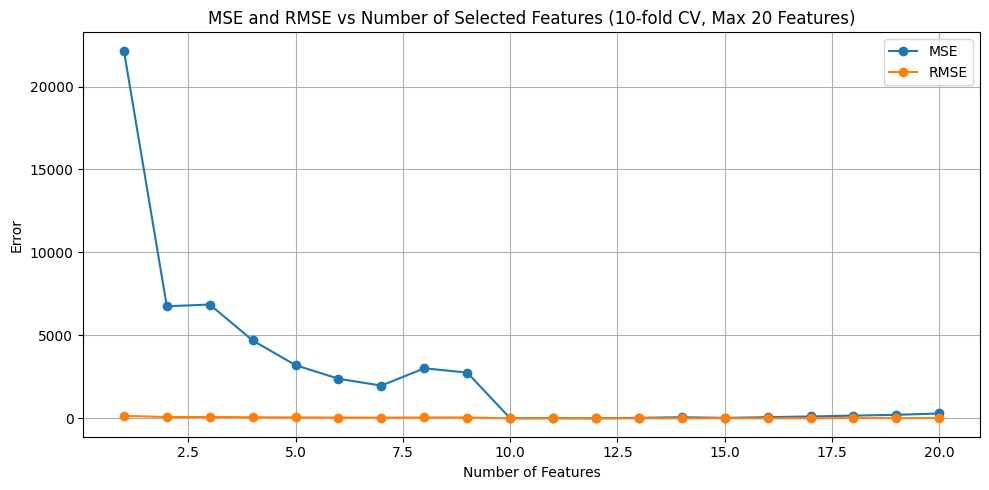

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Load preprocessed data ===
df = pd.read_csv("processed_smoothed_transmission.csv")

# === Pivot to wide format ===
wide_df = df.pivot_table(index="concentration", columns="wavelength", values="smoothed_T2").dropna(axis=1)
wide_df = wide_df.sort_index()

# === Prepare X and y ===
X = wide_df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)

# === Optional: rename columns to valid variable names ===
X.columns = [f"wv_{str(c).replace('.', '_')}" for c in X.columns]

# === Define 10-fold CV MSE ===
def kfold_cv_mse(X_vals, y_vals, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    mse_vals = []
    for train_idx, val_idx in kf.split(X_vals):
        X_train, X_val = X_vals[train_idx], X_vals[val_idx]
        y_train, y_val = y_vals[train_idx], y_vals[val_idx]
        model = LinearRegression().fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_vals.append(mean_squared_error(y_val, y_pred))
    return np.mean(mse_vals)

# === Greedy feature selection with a 20-feature cap ===
remaining = list(X.columns)
selected = []
data_list = []

best_mse = float("inf")
max_features = 20  # Limit number of added features

for i in range(1, max_features + 1):
    best_mse_this_round = float("inf")
    best_candidate = None

    for candidate in remaining:
        test_features = selected + [candidate]
        mse = kfold_cv_mse(X[test_features].values, y)
        if mse < best_mse_this_round:
            best_mse_this_round = mse
            best_candidate = candidate

    if best_candidate is None:
        break

    selected.append(best_candidate)
    remaining.remove(best_candidate)
    best_mse = best_mse_this_round
    data_list.append({
        "n_feats": len(selected),
        "features": selected.copy(),
        "mse": best_mse,
        "rmse": np.sqrt(best_mse)
    })

    print(f"Step {len(selected)}: added {best_candidate} -> 10-fold MSE: {best_mse:.2f}")

# === Convert to DataFrame and Plot ===
results_df = pd.DataFrame(data_list)

plt.figure(figsize=(10, 5))
plt.plot(results_df["n_feats"], results_df["mse"], label="MSE", marker="o")
plt.plot(results_df["n_feats"], results_df["rmse"], label="RMSE", marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Error")
plt.title("MSE and RMSE vs Number of Selected Features (10-fold CV, Max 20 Features)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load table from Excel ===
file_path = "mse_rmse_table_20_features.xlsx"  # Update if your file has a different name
df = pd.read_excel(file_path)

# === Extract data ===
x = df["n_feats"]
mse = df["mse"]
rmse = df["rmse"]
mse_std = df["mse_std"]
rmse_std = df["rmse_std"]

# === Plot 4 panels ===
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Panel (a): Linear MSE
axs[0, 0].errorbar(x, mse, yerr=mse_std, fmt='o-', label="MSE", color='blue', capsize=4)
axs[0, 0].set_title("(a) MSE vs Number of Features (Linear Scale)")
axs[0, 0].set_xlabel("Number of Features")
axs[0, 0].set_ylabel("MSE")
axs[0, 0].grid(True)
axs[0, 0].legend()

# Panel (b): Linear RMSE
axs[0, 1].errorbar(x, rmse, yerr=rmse_std, fmt='o-', label="RMSE", color='orange', capsize=4)
axs[0, 1].set_title("(b) RMSE vs Number of Features (Linear Scale)")
axs[0, 1].set_xlabel("Number of Features")
axs[0, 1].set_ylabel("RMSE")
axs[0, 1].grid(True)
axs[0, 1].legend()

# Panel (c): Log MSE
axs[1, 0].errorbar(x, mse, yerr=mse_std, fmt='o-', label="MSE", color='blue', capsize=4)
axs[1, 0].set_yscale("log")
axs[1, 0].set_title("(c) MSE vs Number of Features (Log Scale)")
axs[1, 0].set_xlabel("Number of Features")
axs[1, 0].set_ylabel("MSE (log scale)")
axs[1, 0].grid(True, which="both")
axs[1, 0].legend()

# Panel (d): Log RMSE
axs[1, 1].errorbar(x, rmse, yerr=rmse_std, fmt='o-', label="RMSE", color='orange', capsize=4)
axs[1, 1].set_yscale("log")
axs[1, 1].set_title("(d) RMSE vs Number of Features (Log Scale)")
axs[1, 1].set_xlabel("Number of Features")
axs[1, 1].set_ylabel("RMSE (log scale)")
axs[1, 1].grid(True, which="both")
axs[1, 1].legend()

plt.tight_layout()
plt.show()


KeyError: 'n_feats'

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load the Excel file ===
df = pd.read_excel("mse_rmse_table_20_features.xlsx")

# === Print columns for confirmation ===
print("Available columns:", df.columns.tolist())

# === Rename columns if needed ===
df.columns = [c.strip().lower() for c in df.columns]
if "n_feats" not in df.columns:
    if "features" in df.columns:
        df.rename(columns={"features": "n_feats"}, inplace=True)

# === Extract relevant data ===
x = df["n_feats"]
mse = df["mse"]
rmse = df["rmse"]
mse_std = df["mse_std"]
rmse_std = df["rmse_std"]

# === Plotting 4 subplots: Linear + Log ===
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Panel (a): Linear MSE
axs[0, 0].errorbar(x, mse, yerr=mse_std, fmt='o-', color='blue', capsize=4, label="MSE")
axs[0, 0].set_title("(a) MSE vs Number of Features (Linear Scale)")
axs[0, 0].set_xlabel("Number of Features")
axs[0, 0].set_ylabel("MSE")
axs[0, 0].legend()
axs[0, 0].grid(True)

# Panel (b): Linear RMSE
axs[0, 1].errorbar(x, rmse, yerr=rmse_std, fmt='o-', color='orange', capsize=4, label="RMSE")
axs[0, 1].set_title("(b) RMSE vs Number of Features (Linear Scale)")
axs[0, 1].set_xlabel("Number of Features")
axs[0, 1].set_ylabel("RMSE")
axs[0, 1].legend()
axs[0, 1].grid(True)

# Panel (c): Log MSE
axs[1, 0].errorbar(x, mse, yerr=mse_std, fmt='o-', color='blue', capsize=4, label="MSE")
axs[1, 0].set_yscale("log")
axs[1, 0].set_title("(c) MSE vs Number of Features (Log Scale)")
axs[1, 0].set_xlabel("Number of Features")
axs[1, 0].set_ylabel("MSE (log scale)")
axs[1, 0].legend()
axs[1, 0].grid(True, which="both")

# Panel (d): Log RMSE
axs[1, 1].errorbar(x, rmse, yerr=rmse_std, fmt='o-', color='orange', capsize=4, label="RMSE")
axs[1, 1].set_yscale("log")
axs[1, 1].set_title("(d) RMSE vs Number of Features (Log Scale)")
axs[1, 1].set_xlabel("Number of Features")
axs[1, 1].set_ylabel("RMSE (log scale)")
axs[1, 1].legend()
axs[1, 1].grid(True, which="both")

plt.tight_layout()
plt.show()


Available columns: ['n_features', 'feature_added', 'mse', 'rmse', 'mse_fold_improvement', 'rmse_fold_improvement']


KeyError: 'n_feats'

Available columns: ['n_features', 'feature_added', 'mse', 'rmse', 'mse_fold_improvement', 'rmse_fold_improvement']


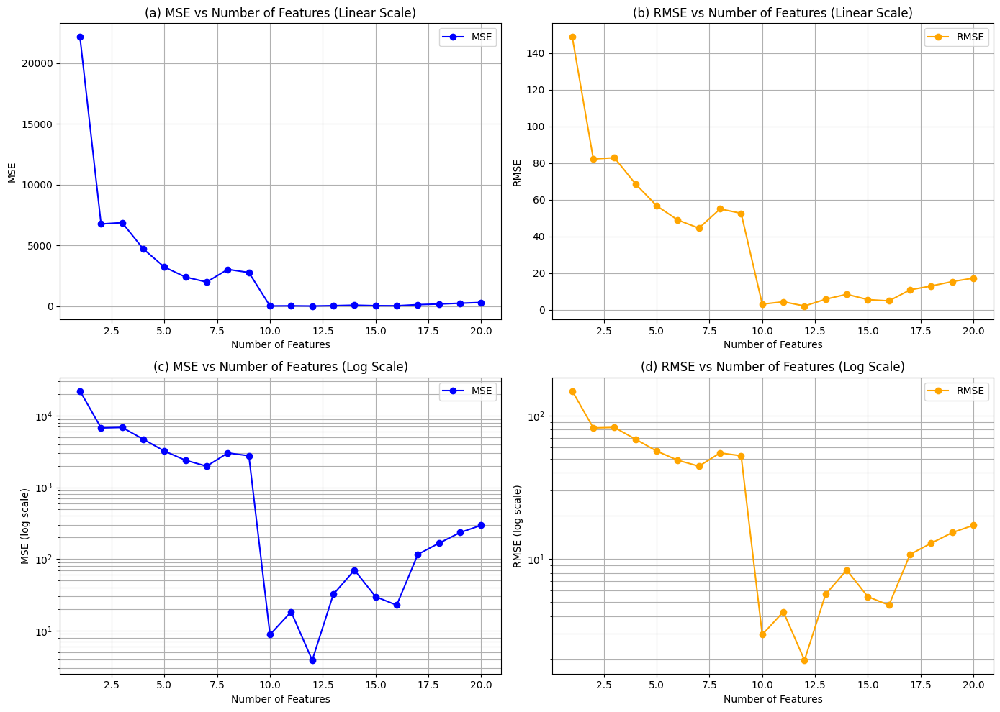

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load the file ===
df = pd.read_excel("mse_rmse_table_20_features.xlsx")

# === Confirm columns ===
print("Available columns:", df.columns.tolist())

# === Extract values ===
x = df["n_features"]
mse = df["mse"]
rmse = df["rmse"]

# Optional: Add error bars if these columns exist
mse_std = df["mse_fold_improvement"] if "mse_fold_improvement" in df.columns else None
rmse_std = df["rmse_fold_improvement"] if "rmse_fold_improvement" in df.columns else None

# === Plotting 4 panels ===
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Panel (a): MSE linear
axs[0, 0].plot(x, mse, 'o-', color='blue', label="MSE")
axs[0, 0].set_title("(a) MSE vs Number of Features (Linear Scale)")
axs[0, 0].set_xlabel("Number of Features")
axs[0, 0].set_ylabel("MSE")
axs[0, 0].grid(True)
axs[0, 0].legend()

# Panel (b): RMSE linear
axs[0, 1].plot(x, rmse, 'o-', color='orange', label="RMSE")
axs[0, 1].set_title("(b) RMSE vs Number of Features (Linear Scale)")
axs[0, 1].set_xlabel("Number of Features")
axs[0, 1].set_ylabel("RMSE")
axs[0, 1].grid(True)
axs[0, 1].legend()

# Panel (c): MSE log
axs[1, 0].plot(x, mse, 'o-', color='blue', label="MSE")
axs[1, 0].set_yscale("log")
axs[1, 0].set_title("(c) MSE vs Number of Features (Log Scale)")
axs[1, 0].set_xlabel("Number of Features")
axs[1, 0].set_ylabel("MSE (log scale)")
axs[1, 0].grid(True, which="both")
axs[1, 0].legend()

# Panel (d): RMSE log
axs[1, 1].plot(x, rmse, 'o-', color='orange', label="RMSE")
axs[1, 1].set_yscale("log")
axs[1, 1].set_title("(d) RMSE vs Number of Features (Log Scale)")
axs[1, 1].set_xlabel("Number of Features")
axs[1, 1].set_ylabel("RMSE (log scale)")
axs[1, 1].grid(True, which="both")
axs[1, 1].legend()

plt.tight_layout()
plt.show()


Columns: Index(['n_features', 'feature_added', 'mse', 'rmse', 'mse_fold_improvement',
       'rmse_fold_improvement'],
      dtype='object')


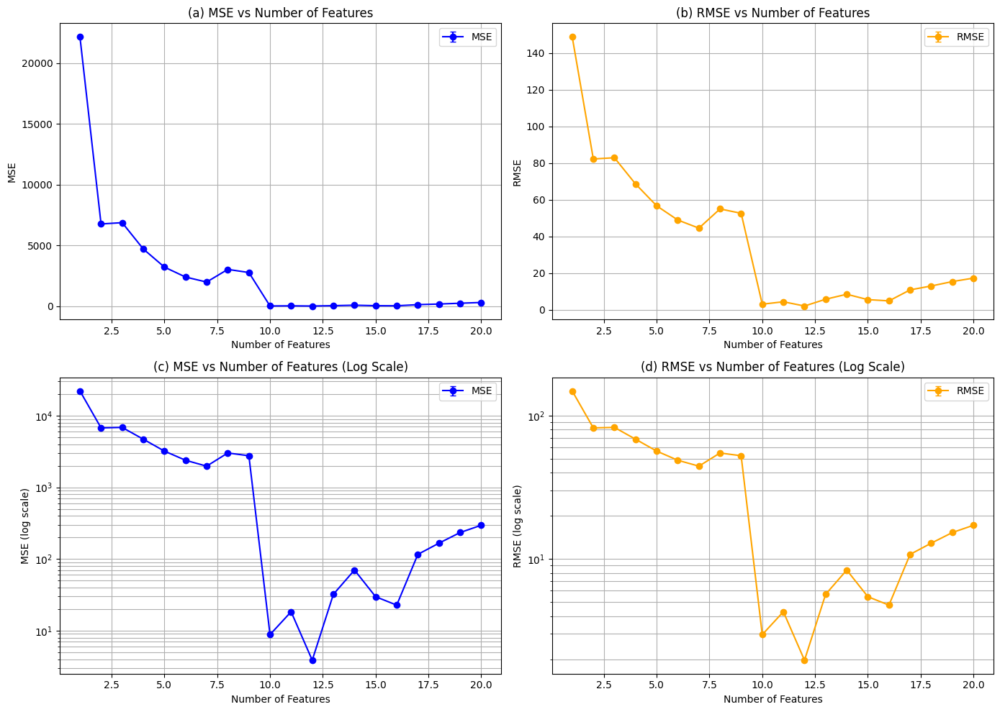

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the CSV file (update the filename if needed)
df = pd.read_csv("MSE_RMSE_Improvement_Table.csv")

# Optional: Preview column names
print("Columns:", df.columns)

# === Define standard deviation columns ===
mse_err = df["mse_std"] if "mse_std" in df.columns else [0] * len(df)
rmse_err = df["rmse_std"] if "rmse_std" in df.columns else [0] * len(df)

# === Create 4-panel figure ===
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Panel (a) - MSE with error bars
axs[0, 0].errorbar(df["n_features"], df["mse"], yerr=mse_err, fmt='o-', capsize=3, label="MSE", color="blue")
axs[0, 0].set_title("(a) MSE vs Number of Features")
axs[0, 0].set_xlabel("Number of Features")
axs[0, 0].set_ylabel("MSE")
axs[0, 0].grid(True)
axs[0, 0].legend()

# Panel (b) - RMSE with error bars
axs[0, 1].errorbar(df["n_features"], df["rmse"], yerr=rmse_err, fmt='o-', capsize=3, label="RMSE", color="orange")
axs[0, 1].set_title("(b) RMSE vs Number of Features")
axs[0, 1].set_xlabel("Number of Features")
axs[0, 1].set_ylabel("RMSE")
axs[0, 1].grid(True)
axs[0, 1].legend()

# Panel (c) - Log-scale MSE with error bars
axs[1, 0].errorbar(df["n_features"], df["mse"], yerr=mse_err, fmt='o-', capsize=3, label="MSE", color="blue")
axs[1, 0].set_yscale("log")
axs[1, 0].set_title("(c) MSE vs Number of Features (Log Scale)")
axs[1, 0].set_xlabel("Number of Features")
axs[1, 0].set_ylabel("MSE (log scale)")
axs[1, 0].grid(True, which="both")
axs[1, 0].legend()

# Panel (d) - Log-scale RMSE with error bars
axs[1, 1].errorbar(df["n_features"], df["rmse"], yerr=rmse_err, fmt='o-', capsize=3, label="RMSE", color="orange")
axs[1, 1].set_yscale("log")
axs[1, 1].set_title("(d) RMSE vs Number of Features (Log Scale)")
axs[1, 1].set_xlabel("Number of Features")
axs[1, 1].set_ylabel("RMSE (log scale)")
axs[1, 1].grid(True, which="both")
axs[1, 1].legend()

plt.tight_layout()
plt.show()


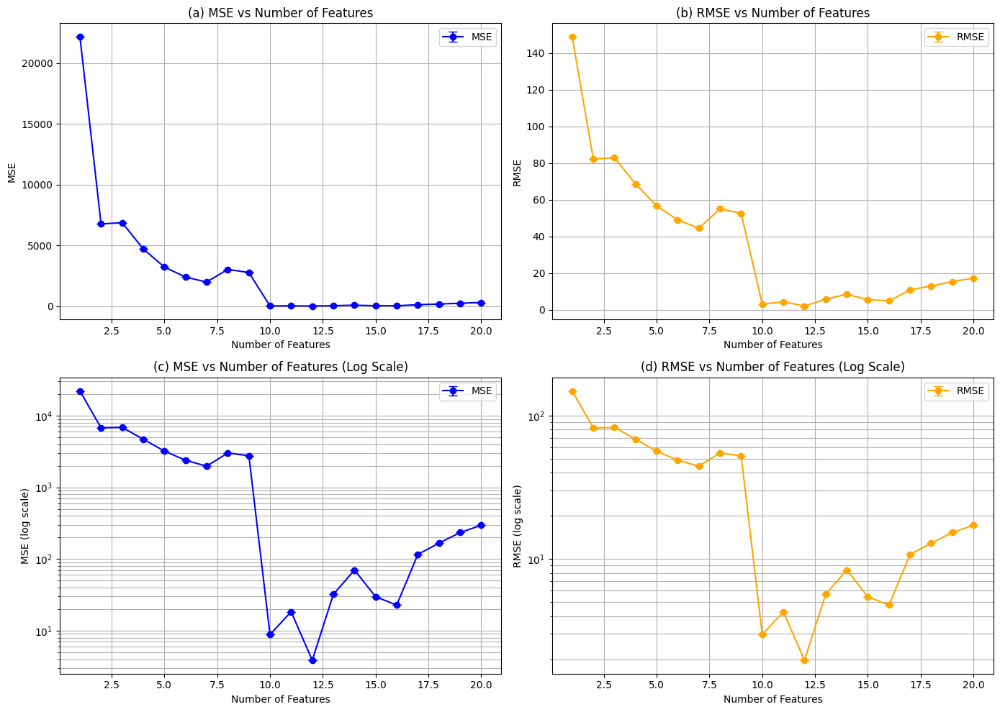

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV file with standard deviation columns
df = pd.read_csv("MSE_RMSE_Improvement_Table.csv")

# Convert numeric columns if read as string (sometimes needed)
df["n_features"] = pd.to_numeric(df["n_features"], errors='coerce')
df["mse"] = pd.to_numeric(df["mse"], errors='coerce')
df["rmse"] = pd.to_numeric(df["rmse"], errors='coerce')
df["mse_std"] = pd.to_numeric(df.get("mse_std", 0), errors='coerce')
df["rmse_std"] = pd.to_numeric(df.get("rmse_std", 0), errors='coerce')

# Setup figure
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Panel (a): MSE (linear)
axs[0, 0].errorbar(df["n_features"], df["mse"], yerr=df["mse_std"], fmt='o-', capsize=4, label="MSE", color="blue")
axs[0, 0].set_title("(a) MSE vs Number of Features")
axs[0, 0].set_xlabel("Number of Features")
axs[0, 0].set_ylabel("MSE")
axs[0, 0].grid(True)
axs[0, 0].legend()

# Panel (b): RMSE (linear)
axs[0, 1].errorbar(df["n_features"], df["rmse"], yerr=df["rmse_std"], fmt='o-', capsize=4, label="RMSE", color="orange")
axs[0, 1].set_title("(b) RMSE vs Number of Features")
axs[0, 1].set_xlabel("Number of Features")
axs[0, 1].set_ylabel("RMSE")
axs[0, 1].grid(True)
axs[0, 1].legend()

# Panel (c): MSE (log scale)
axs[1, 0].errorbar(df["n_features"], df["mse"], yerr=df["mse_std"], fmt='o-', capsize=4, label="MSE", color="blue")
axs[1, 0].set_yscale("log")
axs[1, 0].set_title("(c) MSE vs Number of Features (Log Scale)")
axs[1, 0].set_xlabel("Number of Features")
axs[1, 0].set_ylabel("MSE (log scale)")
axs[1, 0].grid(True, which="both")
axs[1, 0].legend()

# Panel (d): RMSE (log scale)
axs[1, 1].errorbar(df["n_features"], df["rmse"], yerr=df["rmse_std"], fmt='o-', capsize=4, label="RMSE", color="orange")
axs[1, 1].set_yscale("log")
axs[1, 1].set_title("(d) RMSE vs Number of Features (Log Scale)")
axs[1, 1].set_xlabel("Number of Features")
axs[1, 1].set_ylabel("RMSE (log scale)")
axs[1, 1].grid(True, which="both")
axs[1, 1].legend()

plt.tight_layout()
plt.show()


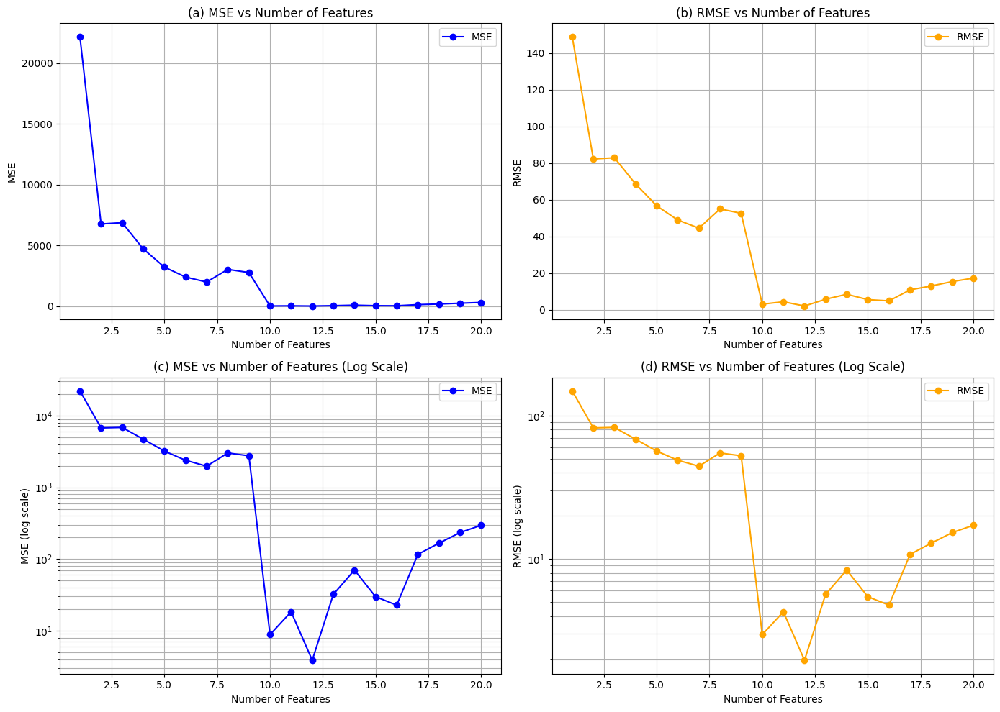

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load your table
df = pd.read_csv("MSE_RMSE_Improvement_Table.csv")

# Ensure proper numeric conversion
df["n_features"] = pd.to_numeric(df["n_features"], errors='coerce')
df["mse"] = pd.to_numeric(df["mse"], errors='coerce')
df["rmse"] = pd.to_numeric(df["rmse"], errors='coerce')

# Plotting
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Panel (a): MSE linear
axs[0, 0].plot(df["n_features"], df["mse"], marker='o', label="MSE", color="blue")
axs[0, 0].set_title("(a) MSE vs Number of Features")
axs[0, 0].set_xlabel("Number of Features")
axs[0, 0].set_ylabel("MSE")
axs[0, 0].grid(True)
axs[0, 0].legend()

# Panel (b): RMSE linear
axs[0, 1].plot(df["n_features"], df["rmse"], marker='o', label="RMSE", color="orange")
axs[0, 1].set_title("(b) RMSE vs Number of Features")
axs[0, 1].set_xlabel("Number of Features")
axs[0, 1].set_ylabel("RMSE")
axs[0, 1].grid(True)
axs[0, 1].legend()

# Panel (c): MSE log
axs[1, 0].plot(df["n_features"], df["mse"], marker='o', label="MSE", color="blue")
axs[1, 0].set_yscale("log")
axs[1, 0].set_title("(c) MSE vs Number of Features (Log Scale)")
axs[1, 0].set_xlabel("Number of Features")
axs[1, 0].set_ylabel("MSE (log scale)")
axs[1, 0].grid(True, which="both")
axs[1, 0].legend()

# Panel (d): RMSE log
axs[1, 1].plot(df["n_features"], df["rmse"], marker='o', label="RMSE", color="orange")
axs[1, 1].set_yscale("log")
axs[1, 1].set_title("(d) RMSE vs Number of Features (Log Scale)")
axs[1, 1].set_xlabel("Number of Features")
axs[1, 1].set_ylabel("RMSE (log scale)")
axs[1, 1].grid(True, which="both")
axs[1, 1].legend()

plt.tight_layout()
plt.show()


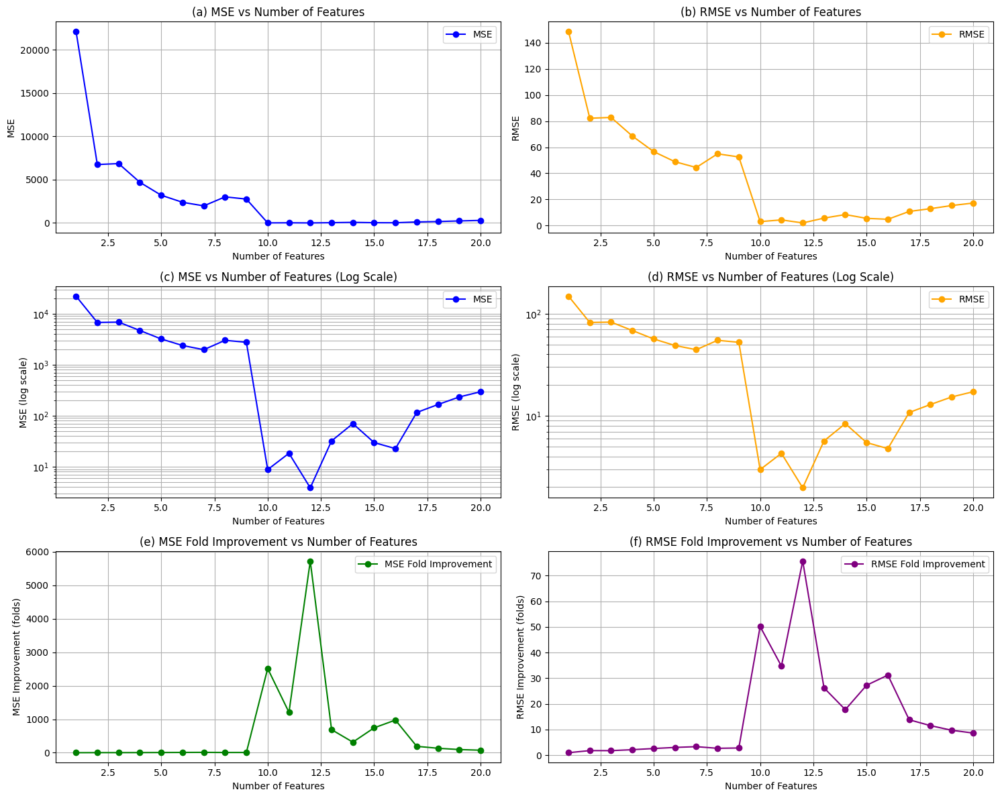

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load your table
df = pd.read_csv("MSE_RMSE_Improvement_Table.csv")

# Ensure numeric types
df["n_features"] = pd.to_numeric(df["n_features"], errors='coerce')
df["mse"] = pd.to_numeric(df["mse"], errors='coerce')
df["rmse"] = pd.to_numeric(df["rmse"], errors='coerce')
df["mse_fold_improvement"] = pd.to_numeric(df["mse_fold_improvement"], errors='coerce')
df["rmse_fold_improvement"] = pd.to_numeric(df["rmse_fold_improvement"], errors='coerce')

# Plot 6 subplots
fig, axs = plt.subplots(3, 2, figsize=(15, 12))

# (a) MSE vs Features
axs[0, 0].plot(df["n_features"], df["mse"], marker='o', color='blue', label="MSE")
axs[0, 0].set_title("(a) MSE vs Number of Features")
axs[0, 0].set_xlabel("Number of Features")
axs[0, 0].set_ylabel("MSE")
axs[0, 0].grid(True)
axs[0, 0].legend()

# (b) RMSE vs Features
axs[0, 1].plot(df["n_features"], df["rmse"], marker='o', color='orange', label="RMSE")
axs[0, 1].set_title("(b) RMSE vs Number of Features")
axs[0, 1].set_xlabel("Number of Features")
axs[0, 1].set_ylabel("RMSE")
axs[0, 1].grid(True)
axs[0, 1].legend()

# (c) MSE log scale
axs[1, 0].plot(df["n_features"], df["mse"], marker='o', color='blue', label="MSE")
axs[1, 0].set_title("(c) MSE vs Number of Features (Log Scale)")
axs[1, 0].set_xlabel("Number of Features")
axs[1, 0].set_ylabel("MSE (log scale)")
axs[1, 0].set_yscale("log")
axs[1, 0].grid(True, which="both")
axs[1, 0].legend()

# (d) RMSE log scale
axs[1, 1].plot(df["n_features"], df["rmse"], marker='o', color='orange', label="RMSE")
axs[1, 1].set_title("(d) RMSE vs Number of Features (Log Scale)")
axs[1, 1].set_xlabel("Number of Features")
axs[1, 1].set_ylabel("RMSE (log scale)")
axs[1, 1].set_yscale("log")
axs[1, 1].grid(True, which="both")
axs[1, 1].legend()

# (e) MSE Fold Improvement
axs[2, 0].plot(df["n_features"], df["mse_fold_improvement"], marker='o', color='green', label="MSE Fold Improvement")
axs[2, 0].set_title("(e) MSE Fold Improvement vs Number of Features")
axs[2, 0].set_xlabel("Number of Features")
axs[2, 0].set_ylabel("MSE Improvement (folds)")
axs[2, 0].grid(True)
axs[2, 0].legend()

# (f) RMSE Fold Improvement
axs[2, 1].plot(df["n_features"], df["rmse_fold_improvement"], marker='o', color='purple', label="RMSE Fold Improvement")
axs[2, 1].set_title("(f) RMSE Fold Improvement vs Number of Features")
axs[2, 1].set_xlabel("Number of Features")
axs[2, 1].set_ylabel("RMSE Improvement (folds)")
axs[2, 1].grid(True)
axs[2, 1].legend()

plt.tight_layout()
plt.show()


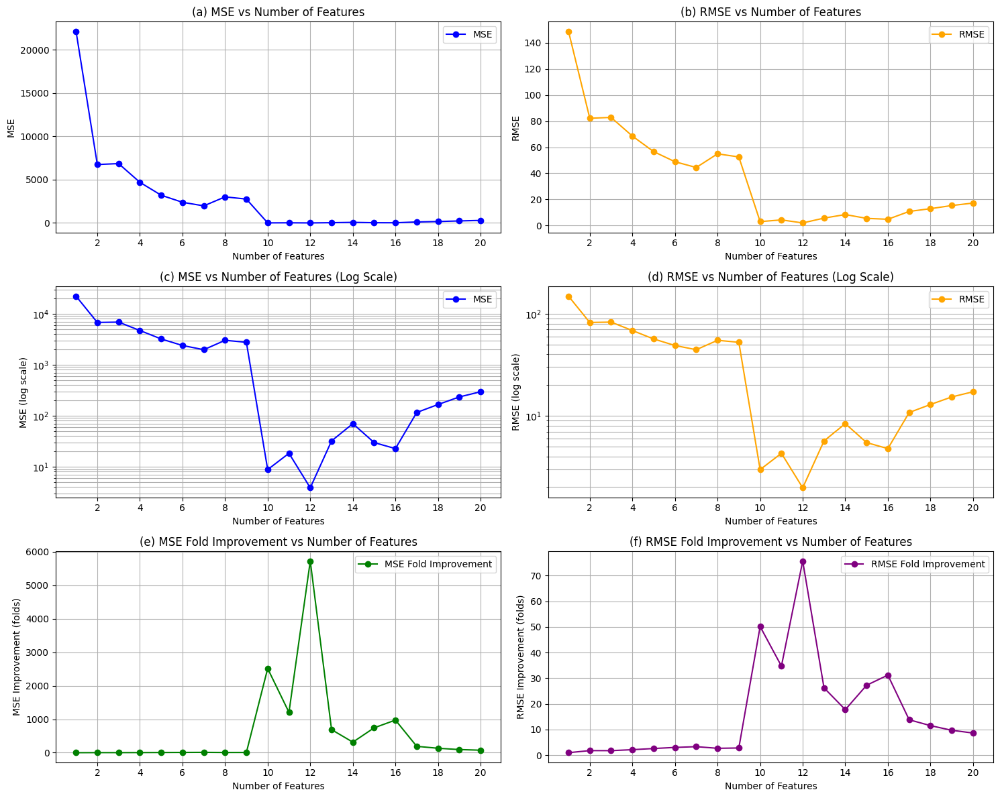

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load your table
df = pd.read_csv("MSE_RMSE_Improvement_Table.csv")

# Convert columns to numeric
df["n_features"] = pd.to_numeric(df["n_features"], errors='coerce')
df["mse"] = pd.to_numeric(df["mse"], errors='coerce')
df["rmse"] = pd.to_numeric(df["rmse"], errors='coerce')
df["mse_fold_improvement"] = pd.to_numeric(df["mse_fold_improvement"], errors='coerce')
df["rmse_fold_improvement"] = pd.to_numeric(df["rmse_fold_improvement"], errors='coerce')

# Set even x-ticks
even_ticks = list(range(2, int(df["n_features"].max()) + 1, 2))

# Create 6 subplots
fig, axs = plt.subplots(3, 2, figsize=(15, 12))

# (a)
axs[0, 0].plot(df["n_features"], df["mse"], 'o-', color='blue', label="MSE")
axs[0, 0].set_title("(a) MSE vs Number of Features")
axs[0, 0].set_xlabel("Number of Features")
axs[0, 0].set_ylabel("MSE")
axs[0, 0].set_xticks(even_ticks)
axs[0, 0].grid(True)
axs[0, 0].legend()

# (b)
axs[0, 1].plot(df["n_features"], df["rmse"], 'o-', color='orange', label="RMSE")
axs[0, 1].set_title("(b) RMSE vs Number of Features")
axs[0, 1].set_xlabel("Number of Features")
axs[0, 1].set_ylabel("RMSE")
axs[0, 1].set_xticks(even_ticks)
axs[0, 1].grid(True)
axs[0, 1].legend()

# (c)
axs[1, 0].plot(df["n_features"], df["mse"], 'o-', color='blue', label="MSE")
axs[1, 0].set_title("(c) MSE vs Number of Features (Log Scale)")
axs[1, 0].set_xlabel("Number of Features")
axs[1, 0].set_ylabel("MSE (log scale)")
axs[1, 0].set_yscale("log")
axs[1, 0].set_xticks(even_ticks)
axs[1, 0].grid(True, which="both")
axs[1, 0].legend()

# (d)
axs[1, 1].plot(df["n_features"], df["rmse"], 'o-', color='orange', label="RMSE")
axs[1, 1].set_title("(d) RMSE vs Number of Features (Log Scale)")
axs[1, 1].set_xlabel("Number of Features")
axs[1, 1].set_ylabel("RMSE (log scale)")
axs[1, 1].set_yscale("log")
axs[1, 1].set_xticks(even_ticks)
axs[1, 1].grid(True, which="both")
axs[1, 1].legend()

# (e)
axs[2, 0].plot(df["n_features"], df["mse_fold_improvement"], 'o-', color='green', label="MSE Fold Improvement")
axs[2, 0].set_title("(e) MSE Fold Improvement vs Number of Features")
axs[2, 0].set_xlabel("Number of Features")
axs[2, 0].set_ylabel("MSE Improvement (folds)")
axs[2, 0].set_xticks(even_ticks)
axs[2, 0].grid(True)
axs[2, 0].legend()

# (f)
axs[2, 1].plot(df["n_features"], df["rmse_fold_improvement"], 'o-', color='purple', label="RMSE Fold Improvement")
axs[2, 1].set_title("(f) RMSE Fold Improvement vs Number of Features")
axs[2, 1].set_xlabel("Number of Features")
axs[2, 1].set_ylabel("RMSE Improvement (folds)")
axs[2, 1].set_xticks(even_ticks)
axs[2, 1].grid(True)
axs[2, 1].legend()

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv("MSE_RMSE_Improvement_Table.csv")

# Ensure numeric columns
df["n_features"] = pd.to_numeric(df["n_features"], errors='coerce')
df["mse"] = pd.to_numeric(df["mse"], errors='coerce')
df["rmse"] = pd.to_numeric(df["rmse"], errors='coerce')
df["mse_fold_improvement"] = pd.to_numeric(df["mse_fold_improvement"], errors='coerce')
df["rmse_fold_improvement"] = pd.to_numeric(df["rmse_fold_improvement"], errors='coerce')

# Define even x-ticks
even_ticks = list(range(2, int(df["n_features"].max()) + 1, 2))

# Font settings
fontdict = {"fontname": "Times New Roman", "weight": "bold", "fontsize": 12}
legend_font = {"family": "Times New Roman", "weight": "bold", "size": 11}

# Create subplots
fig, axs = plt.subplots(3, 2, figsize=(15, 12))

# Panel (a)
axs[0, 0].plot(df["n_features"], df["mse"], 'o-', color='blue', label="MSE")
axs[0, 0].set_title("(a) MSE vs Number of Features", **fontdict)
axs[0, 0].set_xlabel("Number of Features", **fontdict)
axs[0, 0].set_ylabel("MSE", **fontdict)
axs[0, 0].set_xticks(even_ticks)
axs[0, 0].tick_params(labelsize=10)
axs[0, 0].legend(prop=legend_font)
axs[0, 0].grid(True)

# Panel (b)
axs[0, 1].plot(df["n_features"], df["rmse"], 'o-', color='orange', label="RMSE")
axs[0, 1].set_title("(b) RMSE vs Number of Features", **fontdict)
axs[0, 1].set_xlabel("Number of Features", **fontdict)
axs[0, 1].set_ylabel("RMSE", **fontdict)
axs[0, 1].set_xticks(even_ticks)
axs[0, 1].tick_params(labelsize=10)
axs[0, 1].legend(prop=legend_font)
axs[0, 1].grid(True)

# Panel (c)
axs[1, 0].plot(df["n_features"], df["mse"], 'o-', color='blue', label="MSE")
axs[1, 0].set_yscale("log")
axs[1, 0].set_title("(c) MSE vs Number of Features (Log Scale)", **fontdict)
axs[1, 0].set_xlabel("Number of Features", **fontdict)
axs[1, 0].set_ylabel("MSE (log scale)", **fontdict)
axs[1, 0].set_xticks(even_ticks)
axs[1, 0].tick_params(labelsize=10)
axs[1, 0].legend(prop=legend_font)
axs[1, 0].grid(True, which="both")

# Panel (d)
axs[1, 1].plot(df["n_features"], df["rmse"], 'o-', color='orange', label="RMSE")
axs[1, 1].set_yscale("log")
axs[1, 1].set_title("(d) RMSE vs Number of Features (Log Scale)", **fontdict)
axs[1, 1].set_xlabel("Number of Features", **fontdict)
axs[1, 1].set_ylabel("RMSE (log scale)", **fontdict)
axs[1, 1].set_xticks(even_ticks)
axs[1, 1].tick_params(labelsize=10)
axs[1, 1].legend(prop=legend_font)
axs[1, 1].grid(True, which="both")

# Panel (e)
axs[2, 0].plot(df["n_features"], df["mse_fold_improvement"], 'o-', color='green', label="MSE Fold")
axs[2, 0].set_title("(e) MSE Fold Improvement vs Number of Features", **fontdict)
axs[2, 0].set_xlabel("Number of Features", **fontdict)
axs[2, 0].set_ylabel("MSE Fold Improvement", **fontdict)
axs[2, 0].set_xticks(even_ticks)
axs[2, 0].tick_params(labelsize=10)
axs[2, 0].legend(prop=legend_font)
axs[2, 0].grid(True)

# Panel (f)
axs[2, 1].plot(df["n_features"], df["rmse_fold_improvement"], 'o-', color='purple', label="RMSE Fold")
axs[2, 1].set_title("(f) RMSE Fold Improvement vs Number of Features", **fontdict)
axs[2, 1].set_xlabel("Number of Features", **fontdict)
axs[2, 1].set_ylabel("RMSE Fold Improvement", **fontdict)
axs[2, 1].set_xticks(even_ticks)
axs[2, 1].tick_params(labelsize=10)
axs[2, 1].legend(prop=legend_font)
axs[2, 1].grid(True)

plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'MSE_RMSE_Improvement_Table.csv'

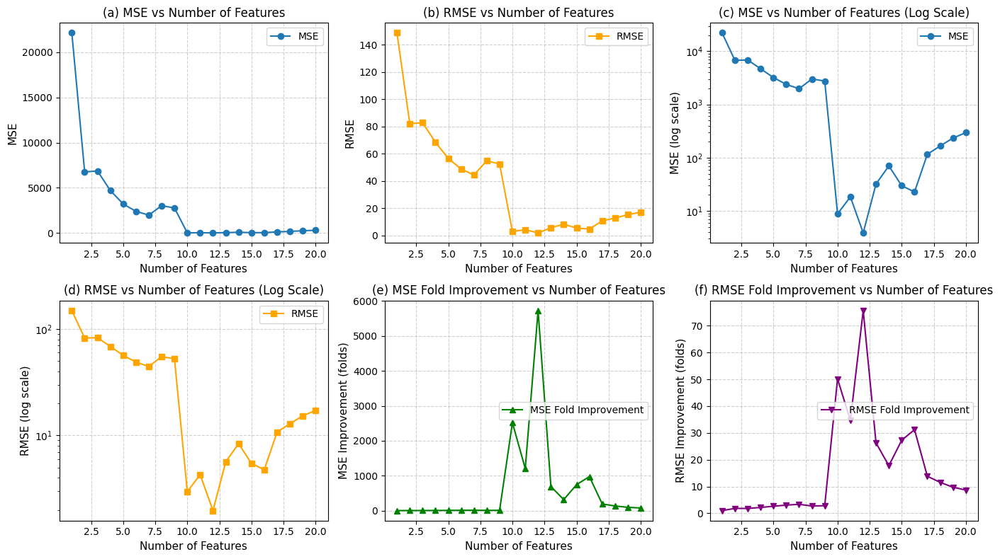

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Force Times New Roman font
rcParams['font.family'] = 'Times New Roman'

# Table 1 / Fig. 6 data
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# Panel (a)
axes[0,0].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[0,0].set_xlabel("Number of Features", fontsize=11)
axes[0,0].set_ylabel("MSE", fontsize=11)
axes[0,0].set_title("(a) MSE vs Number of Features", fontsize=12)
axes[0,0].grid(True, linestyle="--", alpha=0.6)
axes[0,0].legend()

# Panel (b)
axes[0,1].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[0,1].set_xlabel("Number of Features", fontsize=11)
axes[0,1].set_ylabel("RMSE", fontsize=11)
axes[0,1].set_title("(b) RMSE vs Number of Features", fontsize=12)
axes[0,1].grid(True, linestyle="--", alpha=0.6)
axes[0,1].legend()

# Panel (c)
axes[0,2].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[0,2].set_yscale("log")
axes[0,2].set_xlabel("Number of Features", fontsize=11)
axes[0,2].set_ylabel("MSE (log scale)", fontsize=11)
axes[0,2].set_title("(c) MSE vs Number of Features (Log Scale)", fontsize=12)
axes[0,2].grid(True, linestyle="--", alpha=0.6)
axes[0,2].legend()

# Panel (d)
axes[1,0].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[1,0].set_yscale("log")
axes[1,0].set_xlabel("Number of Features", fontsize=11)
axes[1,0].set_ylabel("RMSE (log scale)", fontsize=11)
axes[1,0].set_title("(d) RMSE vs Number of Features (Log Scale)", fontsize=12)
axes[1,0].grid(True, linestyle="--", alpha=0.6)
axes[1,0].legend()

# Panel (e)
axes[1,1].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="green", label="MSE Fold Improvement")
axes[1,1].set_xlabel("Number of Features", fontsize=11)
axes[1,1].set_ylabel("MSE Improvement (folds)", fontsize=11)
axes[1,1].set_title("(e) MSE Fold Improvement vs Number of Features", fontsize=12)
axes[1,1].grid(True, linestyle="--", alpha=0.6)
axes[1,1].legend()

# Panel (f)
axes[1,2].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="purple", label="RMSE Fold Improvement")
axes[1,2].set_xlabel("Number of Features", fontsize=11)
axes[1,2].set_ylabel("RMSE Improvement (folds)", fontsize=11)
axes[1,2].set_title("(f) RMSE Fold Improvement vs Number of Features", fontsize=12)
axes[1,2].grid(True, linestyle="--", alpha=0.6)
axes[1,2].legend()

plt.tight_layout()
plt.savefig("figure6_timesnewroman.png", dpi=600)
plt.show()


In [ ]:
!apt-get install -y ttf-mscorefonts-installer fontconfig && fc-cache -fv


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fontconfig is already the newest version (2.13.1-4.2ubuntu5).
fontconfig set to manually installed.
The following additional packages will be installed:
  cabextract distro-info libmspack0 python3-chardet python3-debconf
  python3-debian python3-distro-info python3-distupgrade
  python3-update-manager python3-yaml ubuntu-advantage-tools ubuntu-pro-client
  ubuntu-pro-client-l10n ubuntu-release-upgrader-core update-manager-core
  update-notifier-common xfonts-encodings xfonts-utils zstd
Suggested packages:
  shunit2
The following NEW packages will be installed:
  cabextract distro-info libmspack0 python3-chardet python3-debconf
  python3-debian python3-distro-info python3-distupgrade
  python3-update-manager python3-yaml ttf-mscorefonts-installer
  ubuntu-advantage-tools ubuntu-pro-client ubuntu-pro-client-l10n
  ubuntu-release-upgrader-core update-manager-core update-notifier-common
  xfont

In [ ]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'Times New Roman'


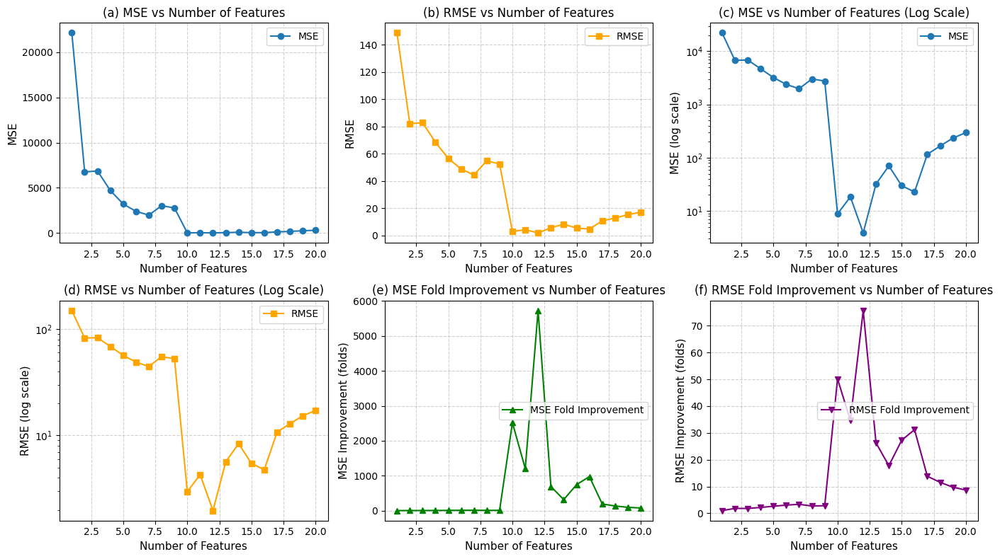

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Force Times New Roman font
rcParams['font.family'] = 'Times New Roman'

# Table 1 / Fig. 6 data
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# Panel (a)
axes[0,0].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[0,0].set_xlabel("Number of Features", fontsize=11)
axes[0,0].set_ylabel("MSE", fontsize=11)
axes[0,0].set_title("(a) MSE vs Number of Features", fontsize=12)
axes[0,0].grid(True, linestyle="--", alpha=0.6)
axes[0,0].legend()

# Panel (b)
axes[0,1].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[0,1].set_xlabel("Number of Features", fontsize=11)
axes[0,1].set_ylabel("RMSE", fontsize=11)
axes[0,1].set_title("(b) RMSE vs Number of Features", fontsize=12)
axes[0,1].grid(True, linestyle="--", alpha=0.6)
axes[0,1].legend()

# Panel (c)
axes[0,2].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[0,2].set_yscale("log")
axes[0,2].set_xlabel("Number of Features", fontsize=11)
axes[0,2].set_ylabel("MSE (log scale)", fontsize=11)
axes[0,2].set_title("(c) MSE vs Number of Features (Log Scale)", fontsize=12)
axes[0,2].grid(True, linestyle="--", alpha=0.6)
axes[0,2].legend()

# Panel (d)
axes[1,0].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[1,0].set_yscale("log")
axes[1,0].set_xlabel("Number of Features", fontsize=11)
axes[1,0].set_ylabel("RMSE (log scale)", fontsize=11)
axes[1,0].set_title("(d) RMSE vs Number of Features (Log Scale)", fontsize=12)
axes[1,0].grid(True, linestyle="--", alpha=0.6)
axes[1,0].legend()

# Panel (e)
axes[1,1].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="green", label="MSE Fold Improvement")
axes[1,1].set_xlabel("Number of Features", fontsize=11)
axes[1,1].set_ylabel("MSE Improvement (folds)", fontsize=11)
axes[1,1].set_title("(e) MSE Fold Improvement vs Number of Features", fontsize=12)
axes[1,1].grid(True, linestyle="--", alpha=0.6)
axes[1,1].legend()

# Panel (f)
axes[1,2].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="purple", label="RMSE Fold Improvement")
axes[1,2].set_xlabel("Number of Features", fontsize=11)
axes[1,2].set_ylabel("RMSE Improvement (folds)", fontsize=11)
axes[1,2].set_title("(f) RMSE Fold Improvement vs Number of Features", fontsize=12)
axes[1,2].grid(True, linestyle="--", alpha=0.6)
axes[1,2].legend()

plt.tight_layout()
plt.savefig("figure6_timesnewroman.png", dpi=600)
plt.show()


In [ ]:
# Change the above figure to Times New Roman font

import matplotlib.pyplot as plt
from matplotlib import rcParams

# Force Times New Roman font
rcParams['font.family'] = 'Times New Roman'

# Assuming the data and plotting code from the previous cell is still valid and available
# (This cell will apply the font change to the figure generated in the previous cell when run sequentially)

# If you want to regenerate the plot within this cell with the new font settings,
# you would need to include the plotting code from the previous cell here.
# For example:

# fig, axes = plt.subplots(2, 3, figsize=(14, 8))
# ... (plotting code from previous cell MHm-Wr3XrJuF) ...
# plt.tight_layout()
# plt.show()

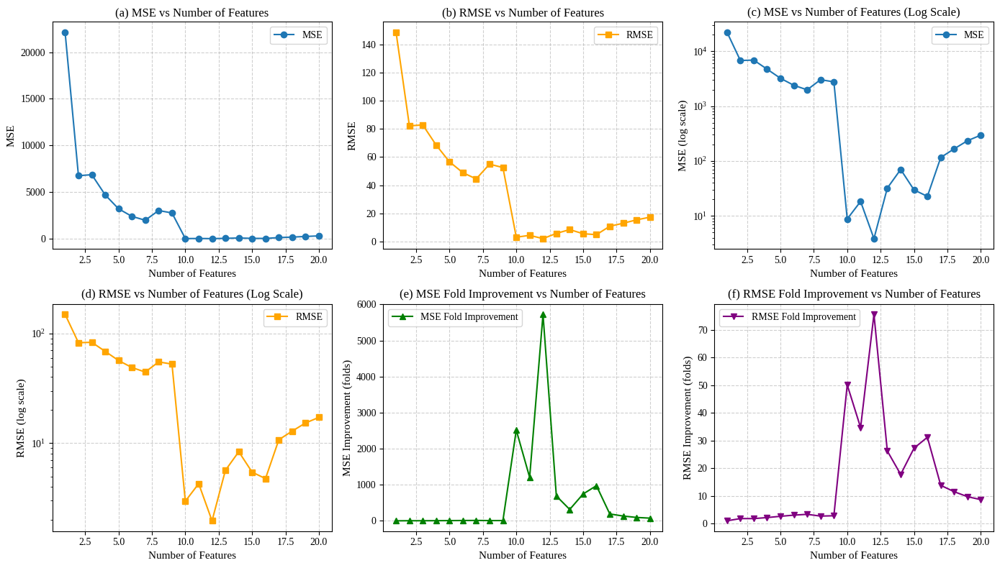

In [ ]:
# --- Reproduce Figure 6 with Liberation Serif (Times New Roman alternative) ---

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Use a Times New Roman–like serif font that is available in Colab
rcParams['font.family'] = 'Liberation Serif'

# Data from Table 1 / Fig. 6
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}

df = pd.DataFrame(data)

# Create 6 subplots
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# (a) MSE
axes[0,0].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[0,0].set_xlabel("Number of Features", fontsize=11)
axes[0,0].set_ylabel("MSE", fontsize=11)
axes[0,0].set_title("(a) MSE vs Number of Features", fontsize=12)
axes[0,0].grid(True, linestyle="--", alpha=0.6)
axes[0,0].legend()

# (b) RMSE
axes[0,1].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[0,1].set_xlabel("Number of Features", fontsize=11)
axes[0,1].set_ylabel("RMSE", fontsize=11)
axes[0,1].set_title("(b) RMSE vs Number of Features", fontsize=12)
axes[0,1].grid(True, linestyle="--", alpha=0.6)
axes[0,1].legend()

# (c) Log MSE
axes[0,2].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[0,2].set_yscale("log")
axes[0,2].set_xlabel("Number of Features", fontsize=11)
axes[0,2].set_ylabel("MSE (log scale)", fontsize=11)
axes[0,2].set_title("(c) MSE vs Number of Features (Log Scale)", fontsize=12)
axes[0,2].grid(True, linestyle="--", alpha=0.6)
axes[0,2].legend()

# (d) Log RMSE
axes[1,0].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[1,0].set_yscale("log")
axes[1,0].set_xlabel("Number of Features", fontsize=11)
axes[1,0].set_ylabel("RMSE (log scale)", fontsize=11)
axes[1,0].set_title("(d) RMSE vs Number of Features (Log Scale)", fontsize=12)
axes[1,0].grid(True, linestyle="--", alpha=0.6)
axes[1,0].legend()

# (e) MSE fold improvement
axes[1,1].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="green", label="MSE Fold Improvement")
axes[1,1].set_xlabel("Number of Features", fontsize=11)
axes[1,1].set_ylabel("MSE Improvement (folds)", fontsize=11)
axes[1,1].set_title("(e) MSE Fold Improvement vs Number of Features", fontsize=12)
axes[1,1].grid(True, linestyle="--", alpha=0.6)
axes[1,1].legend()

# (f) RMSE fold improvement
axes[1,2].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="purple", label="RMSE Fold Improvement")
axes[1,2].set_xlabel("Number of Features", fontsize=11)
axes[1,2].set_ylabel("RMSE Improvement (folds)", fontsize=11)
axes[1,2].set_title("(f) RMSE Fold Improvement vs Number of Features", fontsize=12)
axes[1,2].grid(True, linestyle="--", alpha=0.6)
axes[1,2].legend()

plt.tight_layout()
plt.savefig("figure6_liberationserif.png", dpi=600)
plt.show()


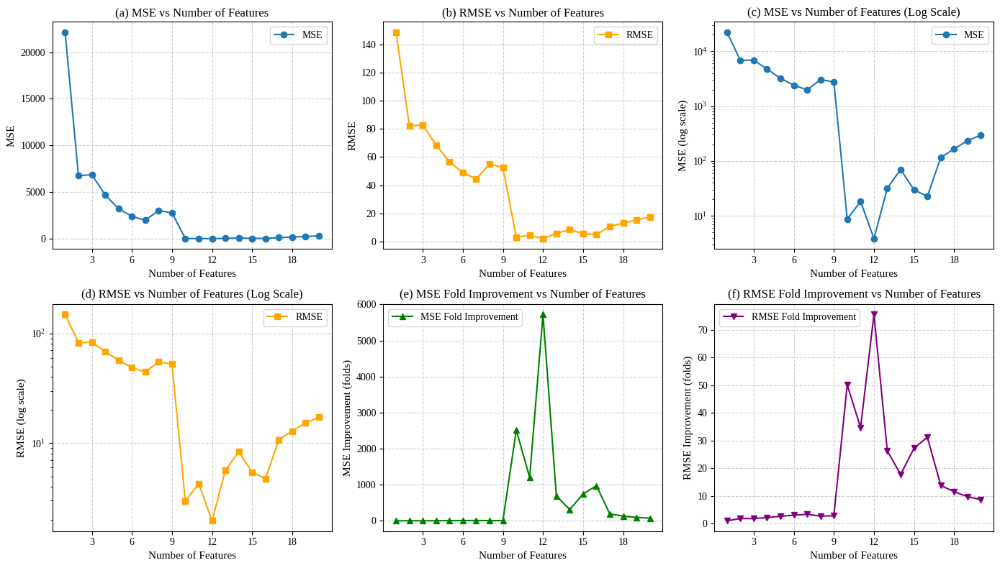

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

# Use Liberation Serif (close to Times New Roman)
rcParams['font.family'] = 'Liberation Serif'

# Data
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}

df = pd.DataFrame(data)

# Plot
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# Plot panels
axes[0,0].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[0,1].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[0,2].plot(df["Total features"], df["MSE"], marker="o", label="MSE"); axes[0,2].set_yscale("log")
axes[1,0].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE"); axes[1,0].set_yscale("log")
axes[1,1].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="green", label="MSE Fold Improvement")
axes[1,2].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="purple", label="RMSE Fold Improvement")

# Formatting all panels
for ax, title in zip(axes.flat, titles):
    ax.set_xlabel("Number of Features", fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))  # force integer ticks
    ax.legend()

# Set Y labels separately
axes[0,0].set_ylabel("MSE", fontsize=11)
axes[0,1].set_ylabel("RMSE", fontsize=11)
axes[0,2].set_ylabel("MSE (log scale)", fontsize=11)
axes[1,0].set_ylabel("RMSE (log scale)", fontsize=11)
axes[1,1].set_ylabel("MSE Improvement (folds)", fontsize=11)
axes[1,2].set_ylabel("RMSE Improvement (folds)", fontsize=11)

plt.tight_layout()
plt.savefig("figure6_integer_ticks.png", dpi=600)
plt.show()


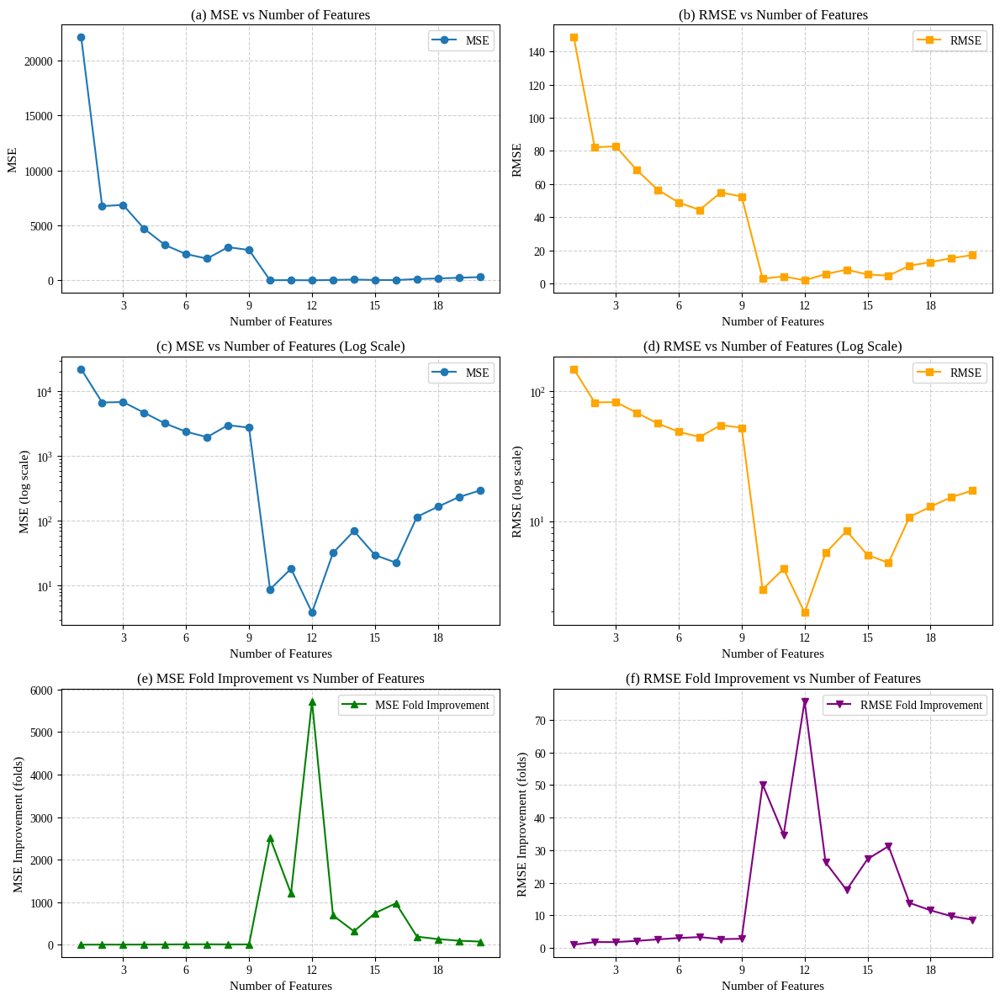

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

# Use Liberation Serif (close to Times New Roman)
rcParams['font.family'] = 'Liberation Serif'

# Data from Table 1 / Fig. 6
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# Create 3x2 grid instead of 2x3
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# Flatten axes for easy iteration
axes = axes.flatten()

# Panel (a)
axes[0].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[0].set_ylabel("MSE", fontsize=11)

# Panel (b)
axes[1].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=11)

# Panel (c)
axes[2].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=11)

# Panel (d)
axes[3].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=11)

# Panel (e)
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="green", label="MSE Fold Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=11)

# Panel (f)
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="purple", label="RMSE Fold Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=11)

# Apply formatting to all panels
for ax, title in zip(axes, titles):
    ax.set_xlabel("Number of Features", fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()

plt.tight_layout()
plt.savefig("figure6_3x2.png", dpi=600)
plt.show()


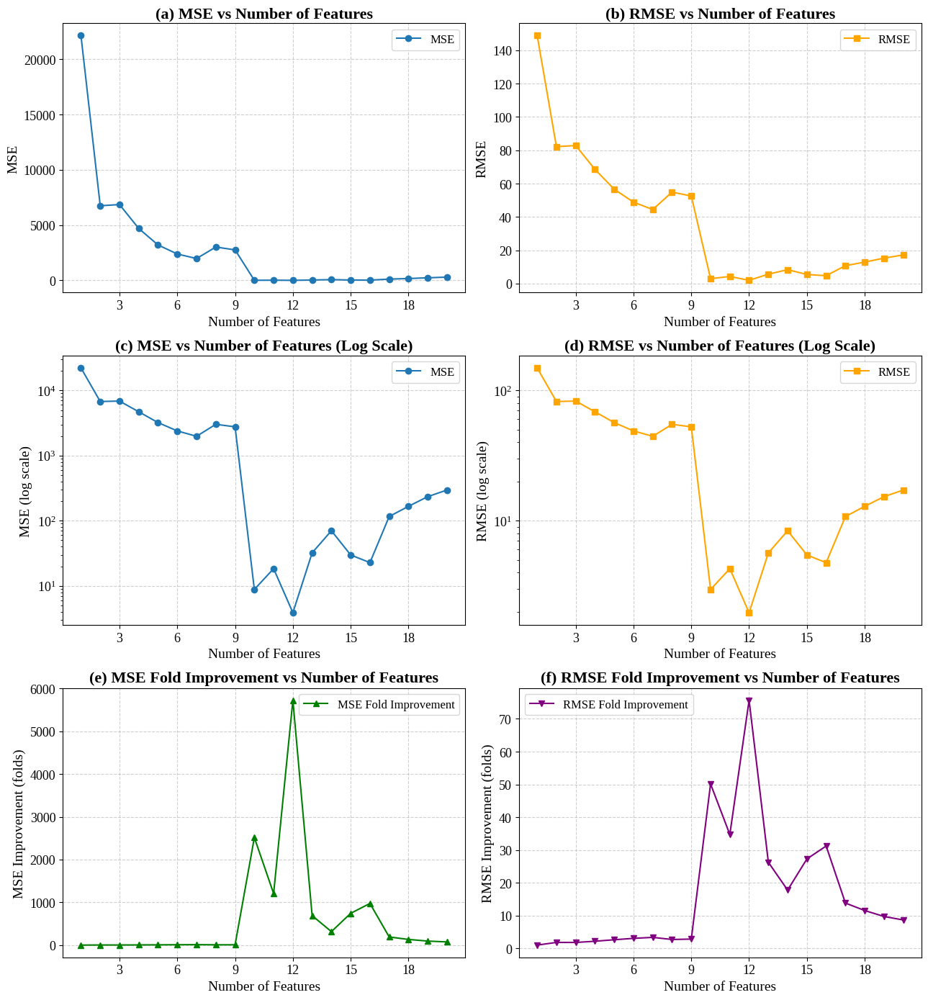

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

# Use Liberation Serif (close to Times New Roman)
rcParams['font.family'] = 'Liberation Serif'

# Data from Table 1 / Fig. 6
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# Create 3x2 grid instead of 2x3
fig, axes = plt.subplots(3, 2, figsize=(13, 14))

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# Flatten axes for easy iteration
axes = axes.flatten()

# Panel (a)
axes[0].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[0].set_ylabel("MSE", fontsize=14)

# Panel (b)
axes[1].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=14)

# Panel (c)
axes[2].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=14)

# Panel (d)
axes[3].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=14)

# Panel (e)
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="green", label="MSE Fold Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=14)

# Panel (f)
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="purple", label="RMSE Fold Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=14)

# Apply formatting to all panels
for ax, title in zip(axes, titles):
    ax.set_xlabel("Number of Features", fontsize=14)
    ax.set_title(title, fontsize=16, weight="bold")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))  # integer ticks only
    ax.tick_params(axis='both', labelsize=13)  # larger tick labels
    ax.legend(fontsize=12)

plt.tight_layout()
plt.savefig("figure6_3x2_bigfont.png", dpi=600)
plt.show()


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

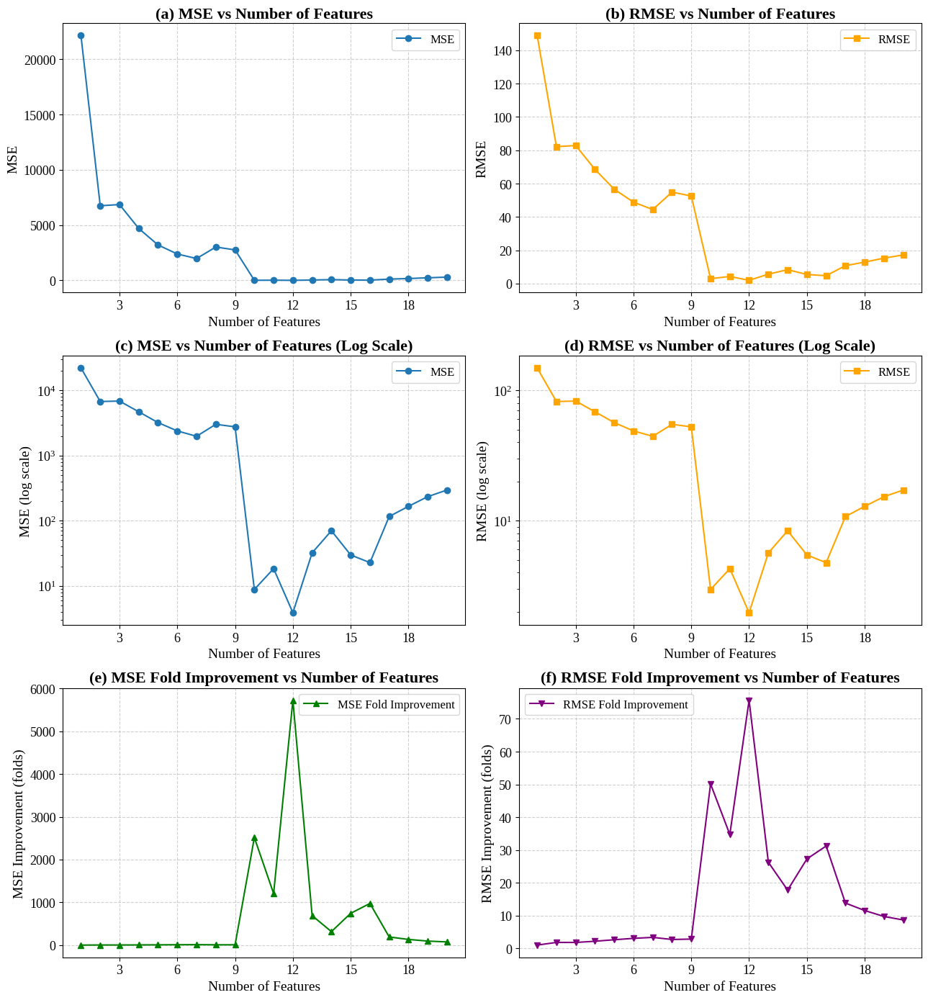

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator
from google.colab import files

# Use Liberation Serif (close to Times New Roman)
rcParams['font.family'] = 'Liberation Serif'

# Data from Table 1 / Fig. 6
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# Create 3x2 grid instead of 2x3
fig, axes = plt.subplots(3, 2, figsize=(13, 14))

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# Flatten axes for easy iteration
axes = axes.flatten()

# Panel (a)
axes[0].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[0].set_ylabel("MSE", fontsize=14)

# Panel (b)
axes[1].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=14)

# Panel (c)
axes[2].plot(df["Total features"], df["MSE"], marker="o", label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=14)

# Panel (d)
axes[3].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=14)

# Panel (e)
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="green", label="MSE Fold Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=14)

# Panel (f)
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="purple", label="RMSE Fold Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=14)

# Apply formatting to all panels
for ax, title in zip(axes, titles):
    ax.set_xlabel("Number of Features", fontsize=14)
    ax.set_title(title, fontsize=16, weight="bold")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))  # integer ticks only
    ax.tick_params(axis='both', labelsize=13)  # larger tick labels
    ax.legend(fontsize=12)

plt.tight_layout()
plt.savefig("figure6_3x2_bigfont.png", dpi=600)

# Add download link
files.download("figure6_3x2_bigfont.png")

plt.show()

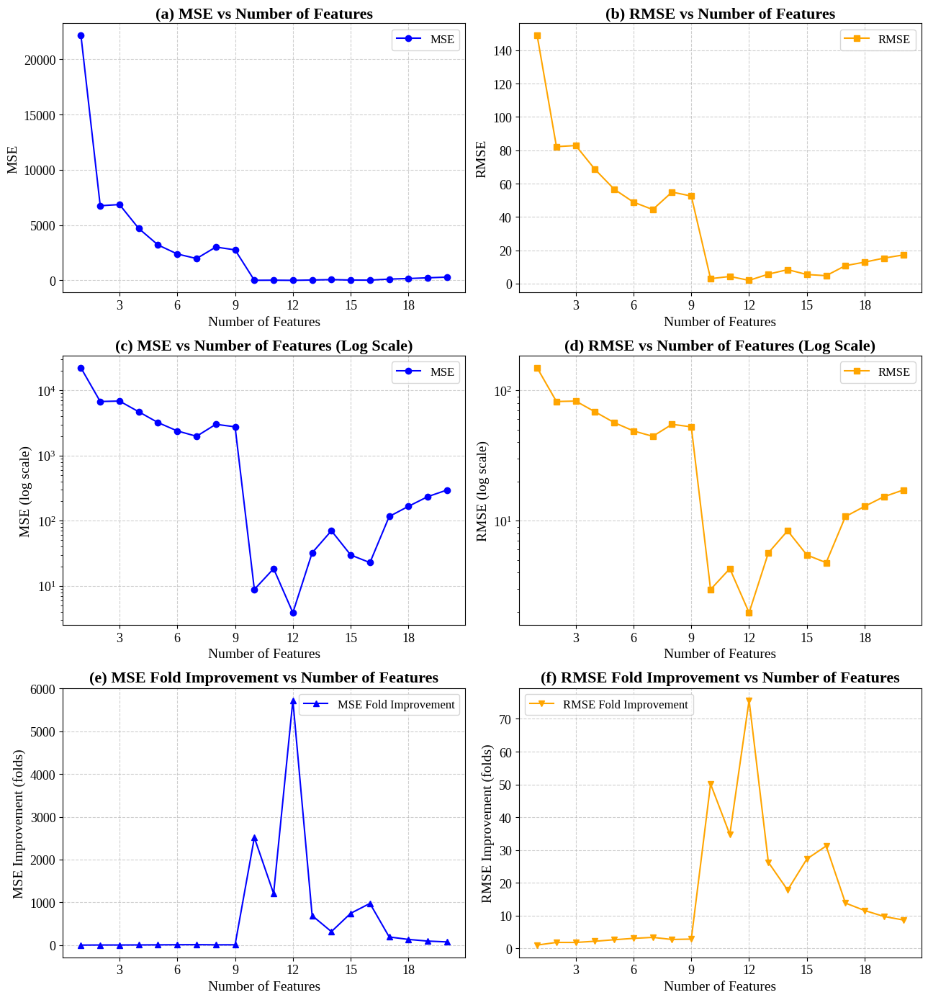

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

# Use Liberation Serif (close to Times New Roman)
rcParams['font.family'] = 'Liberation Serif'

# Data from Table 1 / Fig. 6
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# Create 3x2 grid
fig, axes = plt.subplots(3, 2, figsize=(13, 14))

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

axes = axes.flatten()

# Panel (a) MSE
axes[0].plot(df["Total features"], df["MSE"], marker="o", color="blue", label="MSE")
axes[0].set_ylabel("MSE", fontsize=14)

# Panel (b) RMSE
axes[1].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=14)

# Panel (c) Log MSE
axes[2].plot(df["Total features"], df["MSE"], marker="o", color="blue", label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=14)

# Panel (d) Log RMSE
axes[3].plot(df["Total features"], df["RMSE"], marker="s", color="orange", label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=14)

# Panel (e) MSE fold improvement
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="blue", label="MSE Fold Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=14)

# Panel (f) RMSE fold improvement
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="orange", label="RMSE Fold Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=14)

# Formatting all panels
for ax, title in zip(axes, titles):
    ax.set_xlabel("Number of Features", fontsize=14)
    ax.set_title(title, fontsize=16, weight="bold")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis='both', labelsize=13)
    ax.legend(fontsize=12)

plt.tight_layout()
plt.savefig("figure6_3x2_consistent_colors.png", dpi=600)
plt.show()


In [ ]:
from google.colab import files
files.download("figure6_3x2_consistent_colors.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

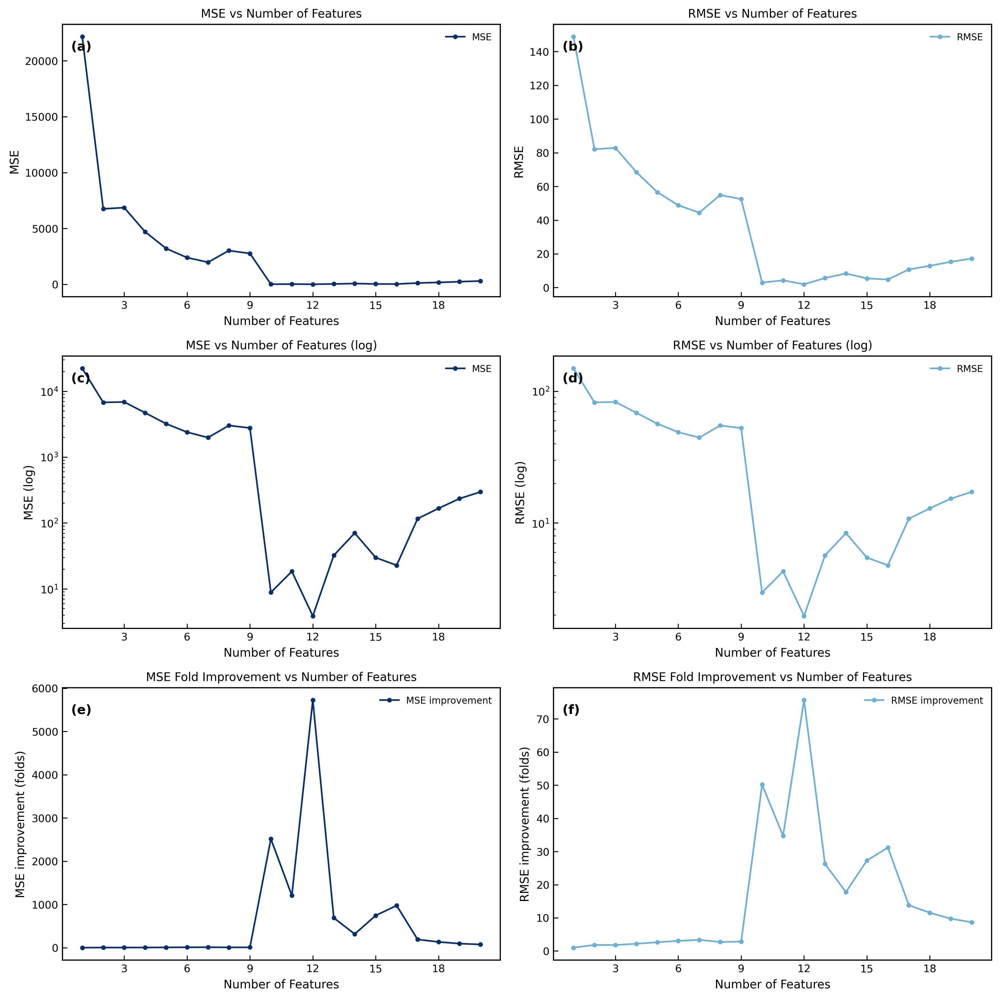

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

# ===== Styling (journal-ready) =====
rcParams.update({
    "figure.figsize": (12, 12),
    "figure.dpi": 300,
    "font.family": "Times New Roman",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "lines.linewidth": 1.4,
    "legend.frameon": False,
    "savefig.bbox": "tight",
})

# Two-tone blue palette
blue_dark = "#08306B"
blue_light = "#6BAED6"

# ===== Data =====
data = {
    "Total features": list(range(1, 21)),
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                 34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# ===== Figure layout =====
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.flatten()
titles = [
    "MSE vs Number of Features",
    "RMSE vs Number of Features",
    "MSE vs Number of Features (log)",
    "RMSE vs Number of Features (log)",
    "MSE Fold Improvement vs Number of Features",
    "RMSE Fold Improvement vs Number of Features"
]
panel_labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]

# Common helpers
def format_ax(ax, title):
    ax.set_xlabel("Number of Features")
    ax.set_title(title, pad=6)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis="both", labelsize=9)

# (a) MSE
axes[0].plot(df["Total features"], df["MSE"], marker="o", ms=3, color=blue_dark, label="MSE")
axes[0].set_ylabel("MSE")
format_ax(axes[0], titles[0])

# (b) RMSE
axes[1].plot(df["Total features"], df["RMSE"], marker="o", ms=3, color=blue_light, label="RMSE")
axes[1].set_ylabel("RMSE")
format_ax(axes[1], titles[1])

# (c) MSE (log)
axes[2].plot(df["Total features"], df["MSE"], marker="o", ms=3, color=blue_dark, label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log)")
format_ax(axes[2], titles[2])

# (d) RMSE (log)
axes[3].plot(df["Total features"], df["RMSE"], marker="o", ms=3, color=blue_light, label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log)")
format_ax(axes[3], titles[3])

# (e) MSE fold improvement
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="o", ms=3,
             color=blue_dark, label="MSE improvement")
axes[4].set_ylabel("MSE improvement (folds)")
format_ax(axes[4], titles[4])

# (f) RMSE fold improvement
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="o", ms=3,
             color=blue_light, label="RMSE improvement")
axes[5].set_ylabel("RMSE improvement (folds)")
format_ax(axes[5], titles[5])

# Minimal legends (top-right), or comment out to omit entirely
for ax in axes:
    ax.legend(loc="best", fontsize=8)

# Panel letters
for ax, lab in zip(axes, panel_labels):
    ax.text(0.02, 0.94, lab, transform=ax.transAxes, fontsize=11, fontweight="bold",
            ha="left", va="top")

plt.tight_layout()
plt.savefig("figure6_blue_tnr.pdf")
plt.savefig("figure6_blue_tnr.png", dpi=600)
plt.show()


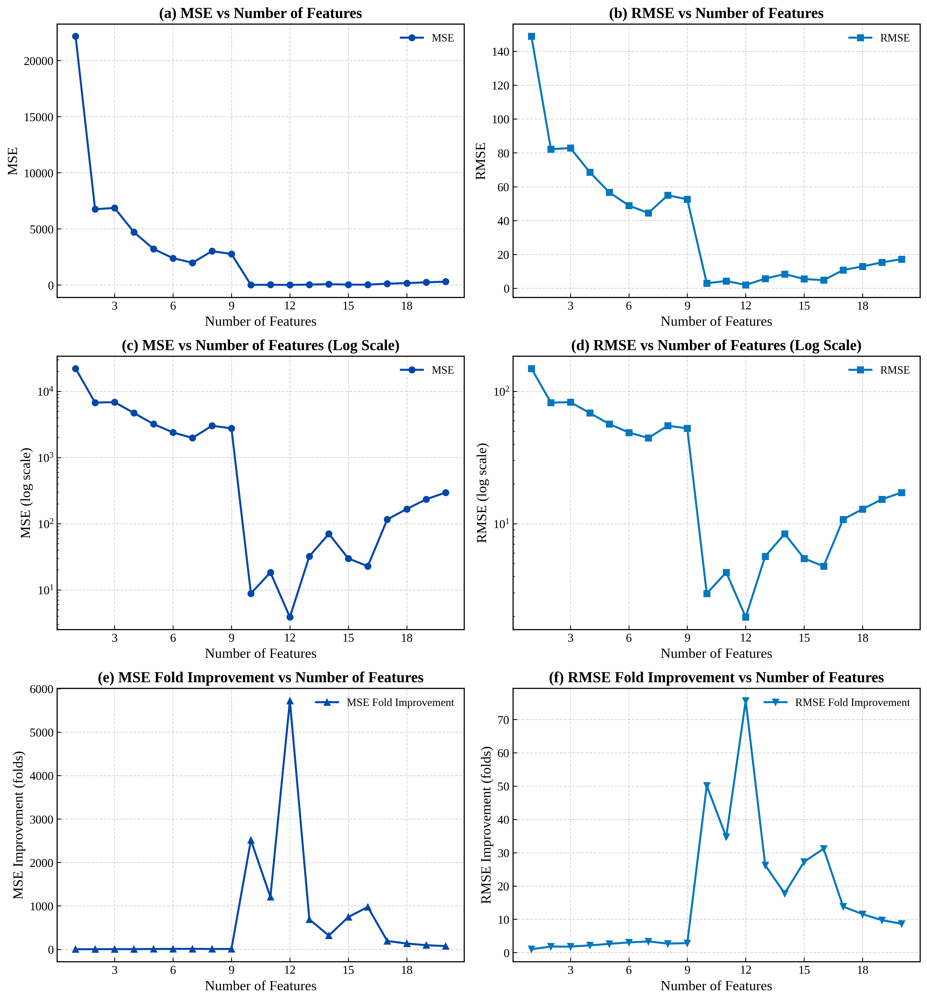

In [ ]:
# =============================================================
# FIGURE 6 - Publication-Ready Version (Blue Theme)
# =============================================================

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

# ---------------------------
# Font setup (Times New Roman style)
# ---------------------------
rcParams['font.family'] = 'serif'
rcParams['font.serif'] = ['Times New Roman', 'Times', 'Liberation Serif']
rcParams['axes.linewidth'] = 1.2

# ---------------------------
# Data
# ---------------------------
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# ---------------------------
# 3x2 Layout
# ---------------------------
fig, axes = plt.subplots(3, 2, figsize=(13, 14))
axes = axes.flatten()

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# ---------------------------
# Panels
# ---------------------------

# (a)
axes[0].plot(df["Total features"], df["MSE"], marker="o", color="#0047AB", linewidth=2, markersize=6, label="MSE")
axes[0].set_ylabel("MSE", fontsize=14)

# (b)
axes[1].plot(df["Total features"], df["RMSE"], marker="s", color="#0077BE", linewidth=2, markersize=6, label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=14)

# (c)
axes[2].plot(df["Total features"], df["MSE"], marker="o", color="#0047AB", linewidth=2, markersize=6, label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=14)

# (d)
axes[3].plot(df["Total features"], df["RMSE"], marker="s", color="#0077BE", linewidth=2, markersize=6, label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=14)

# (e)
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="#0047AB", linewidth=2, markersize=6, label="MSE Fold Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=14)

# (f)
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="#0077BE", linewidth=2, markersize=6, label="RMSE Fold Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=14)

# ---------------------------
# Style polish for all
# ---------------------------
for ax, title in zip(axes, titles):
    ax.set_xlabel("Number of Features", fontsize=14)
    ax.set_title(title, fontsize=15, weight="bold")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis='both', labelsize=12)
    ax.legend(fontsize=11, frameon=False, loc='best')
    for spine in ax.spines.values():
        spine.set_linewidth(1.1)

plt.tight_layout()
plt.savefig("Figure6_final_TNR_style.png", dpi=600, bbox_inches='tight', transparent=True)
plt.show()


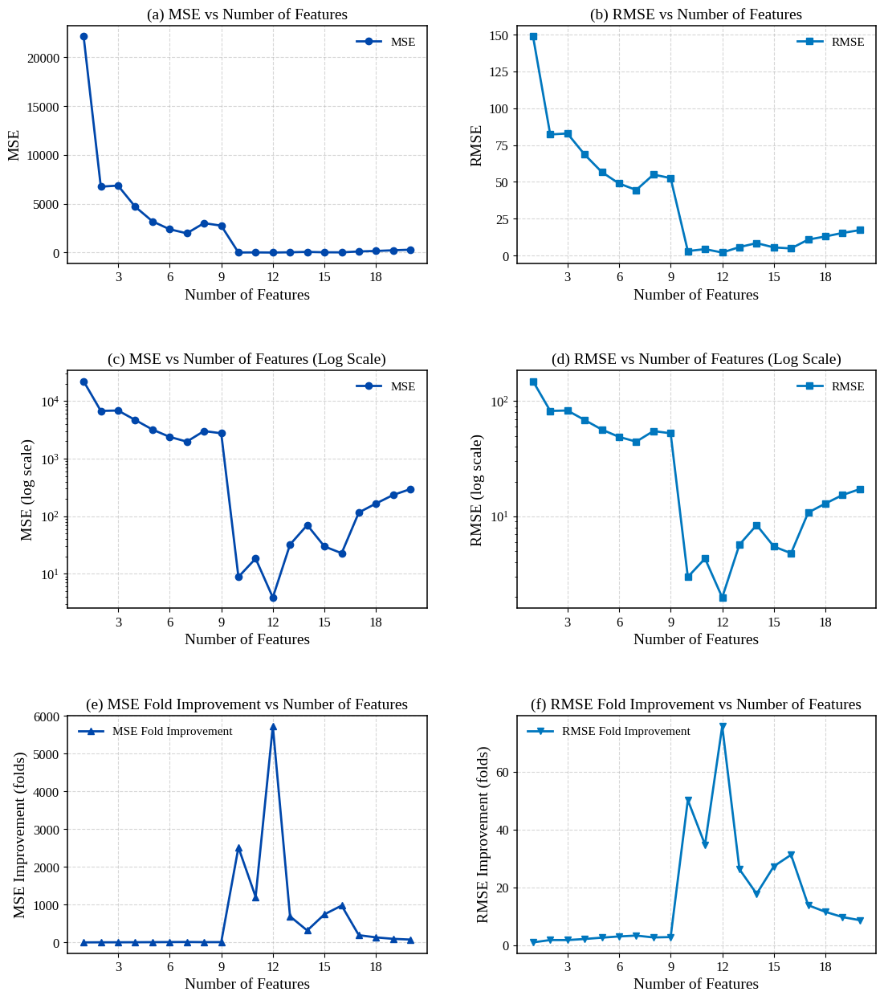

In [ ]:
# =============================================================
# FIGURE 6 - Clean Journal Layout (Times-style, no bold titles)
# =============================================================

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

# ---------------------------
# Font setup (Times New Roman style)
# ---------------------------
rcParams['font.family'] = 'serif'
rcParams['font.serif'] = ['Times New Roman', 'Times', 'Liberation Serif']
rcParams['axes.linewidth'] = 1.2

# ---------------------------
# Data
# ---------------------------
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# ---------------------------
# 3x2 Layout (more spacing)
# ---------------------------
fig, axes = plt.subplots(3, 2, figsize=(13, 15))
axes = axes.flatten()

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# ---------------------------
# Panels
# ---------------------------
axes[0].plot(df["Total features"], df["MSE"], marker="o", color="#0047AB", linewidth=2, markersize=6, label="MSE")
axes[0].set_ylabel("MSE", fontsize=14)

axes[1].plot(df["Total features"], df["RMSE"], marker="s", color="#0077BE", linewidth=2, markersize=6, label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=14)

axes[2].plot(df["Total features"], df["MSE"], marker="o", color="#0047AB", linewidth=2, markersize=6, label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=14)

axes[3].plot(df["Total features"], df["RMSE"], marker="s", color="#0077BE", linewidth=2, markersize=6, label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=14)

axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="#0047AB", linewidth=2, markersize=6, label="MSE Fold Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=14)

axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="#0077BE", linewidth=2, markersize=6, label="RMSE Fold Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=14)

# ---------------------------
# Global formatting
# ---------------------------
for ax, title in zip(axes, titles):
    ax.set_xlabel("Number of Features", fontsize=14)
    ax.set_title(title, fontsize=14, weight="normal")  # no bold titles
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis='both', labelsize=12)
    ax.legend(fontsize=11, frameon=False, loc='best')
    for spine in ax.spines.values():
        spine.set_linewidth(1.1)

plt.subplots_adjust(hspace=0.45, wspace=0.25)  # <- clean spacing between panels
plt.savefig("Figure6_clean_TNR_spacing.png", dpi=600, bbox_inches='tight', transparent=True)
plt.show()


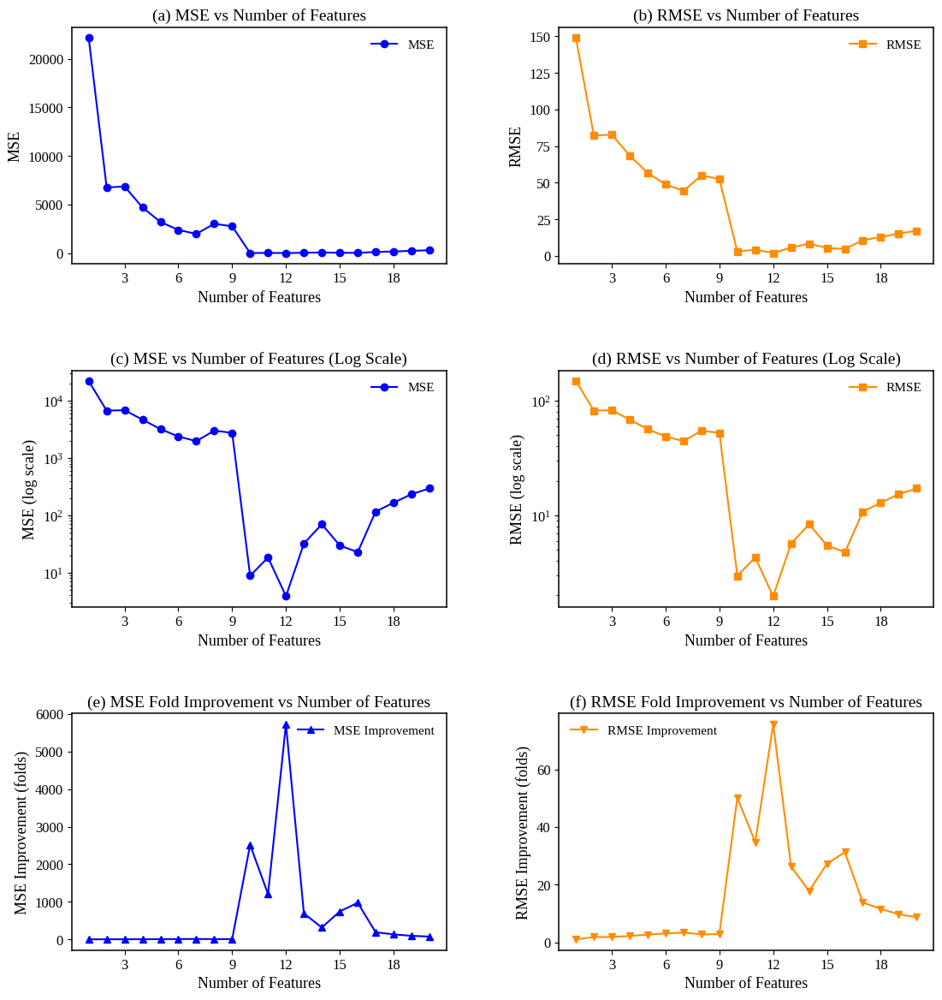

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

# Font setup – Liberation Serif resembles Times New Roman
rcParams['font.family'] = 'Liberation Serif'
rcParams['mathtext.fontset'] = 'dejavuserif'

# Data
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# Create figure (cleaner spacing between panels)
fig, axes = plt.subplots(3, 2, figsize=(13, 14))
axes = axes.flatten()

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# Define a consistent line style
def style_plot(ax, title):
    ax.set_xlabel("Number of Features", fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis='both', labelsize=12)
    ax.legend(fontsize=11, frameon=False, loc='best')
    for spine in ax.spines.values():
        spine.set_linewidth(1.1)

# (a)
axes[0].plot(df["Total features"], df["MSE"], marker="o", color="blue", label="MSE")
axes[0].set_ylabel("MSE", fontsize=13)
style_plot(axes[0], titles[0])

# (b)
axes[1].plot(df["Total features"], df["RMSE"], marker="s", color="darkorange", label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=13)
style_plot(axes[1], titles[1])

# (c)
axes[2].plot(df["Total features"], df["MSE"], marker="o", color="blue", label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=13)
style_plot(axes[2], titles[2])

# (d)
axes[3].plot(df["Total features"], df["RMSE"], marker="s", color="darkorange", label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=13)
style_plot(axes[3], titles[3])

# (e)
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="blue", label="MSE Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=13)
style_plot(axes[4], titles[4])

# (f)
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="darkorange", label="RMSE Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=13)
style_plot(axes[5], titles[5])

# Remove grid lines
for ax in axes:
    ax.grid(False)

# Increase distance between panels for cleaner layout
plt.subplots_adjust(hspace=0.45, wspace=0.3)

plt.savefig("Figure6_final_clean_TNR.png", dpi=600, bbox_inches="tight", transparent=True)
plt.show()


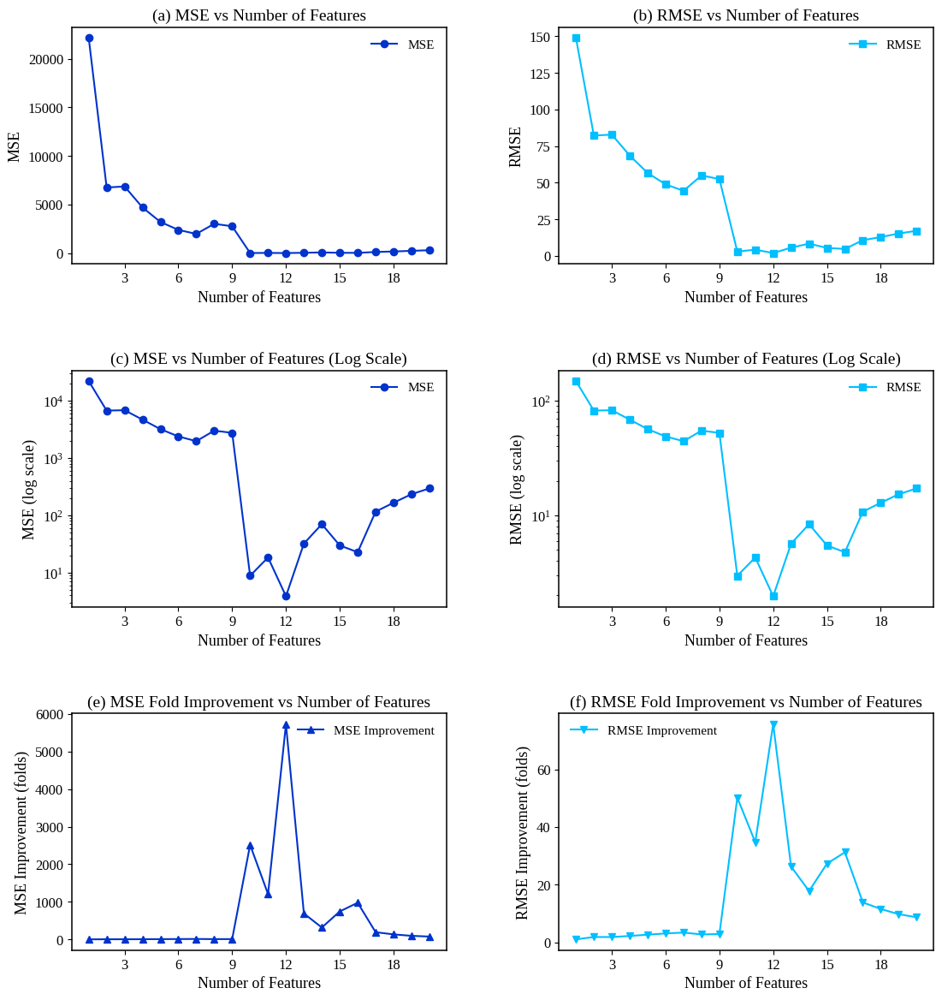

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

# Font setup – Liberation Serif resembles Times New Roman
rcParams['font.family'] = 'Liberation Serif'
rcParams['mathtext.fontset'] = 'dejavuserif'

# Data
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# Create figure (clean spacing)
fig, axes = plt.subplots(3, 2, figsize=(13, 14))
axes = axes.flatten()

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# Custom palette: deep blue and cyan
color_mse = "#0033CC"
color_rmse = "#00BFFF"

def style_plot(ax, title):
    ax.set_xlabel("Number of Features", fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis='both', labelsize=12)
    ax.legend(fontsize=11, frameon=False, loc='best')
    for spine in ax.spines.values():
        spine.set_linewidth(1.1)

# (a)
axes[0].plot(df["Total features"], df["MSE"], marker="o", color=color_mse, label="MSE")
axes[0].set_ylabel("MSE", fontsize=13)
style_plot(axes[0], titles[0])

# (b)
axes[1].plot(df["Total features"], df["RMSE"], marker="s", color=color_rmse, label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=13)
style_plot(axes[1], titles[1])

# (c)
axes[2].plot(df["Total features"], df["MSE"], marker="o", color=color_mse, label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=13)
style_plot(axes[2], titles[2])

# (d)
axes[3].plot(df["Total features"], df["RMSE"], marker="s", color=color_rmse, label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=13)
style_plot(axes[3], titles[3])

# (e)
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color=color_mse, label="MSE Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=13)
style_plot(axes[4], titles[4])

# (f)
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color=color_rmse, label="RMSE Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=13)
style_plot(axes[5], titles[5])

# No grid, clean spacing
for ax in axes:
    ax.grid(False)

plt.subplots_adjust(hspace=0.45, wspace=0.3)
plt.savefig("Figure6_blue_cyan_TNR.png", dpi=600, bbox_inches="tight", transparent=True)
plt.show()


In [ ]:
# --- keep earlier imports, rcParams, data, titles, style_plot(), etc. ---

color_mse  = "#0033CC"  # deep blue
color_rmse = "#00BFFF"  # cyan
lw, ms = 2.0, 6

# (a)
axes[0].plot(df["Total features"], df["MSE"], marker="o", markersize=ms,
             markeredgewidth=0.8, color=color_mse, linewidth=lw, label="MSE")
axes[0].set_ylabel("MSE", fontsize=13)
style_plot(axes[0], titles[0])

# (b)
axes[1].plot(df["Total features"], df["RMSE"], marker="o", markersize=ms,
             markeredgewidth=0.8, color=color_rmse, linewidth=lw, label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=13)
style_plot(axes[1], titles[1])

# (c)
axes[2].plot(df["Total features"], df["MSE"], marker="o", markersize=ms,
             markeredgewidth=0.8, color=color_mse, linewidth=lw, label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=13)
style_plot(axes[2], titles[2])

# (d)
axes[3].plot(df["Total features"], df["RMSE"], marker="o", markersize=ms,
             markeredgewidth=0.8, color=color_rmse, linewidth=lw, label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=13)
style_plot(axes[3], titles[3])

# (e)  <-- changed to circles & same specs
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="o", markersize=ms,
             markeredgewidth=0.8, color=color_mse, linewidth=lw, label="MSE Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=13)
style_plot(axes[4], titles[4])

# (f)  <-- changed to circles & same specs
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="o", markersize=ms,
             markeredgewidth=0.8, color=color_rmse, linewidth=lw, label="RMSE Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=13)
style_plot(axes[5], titles[5])


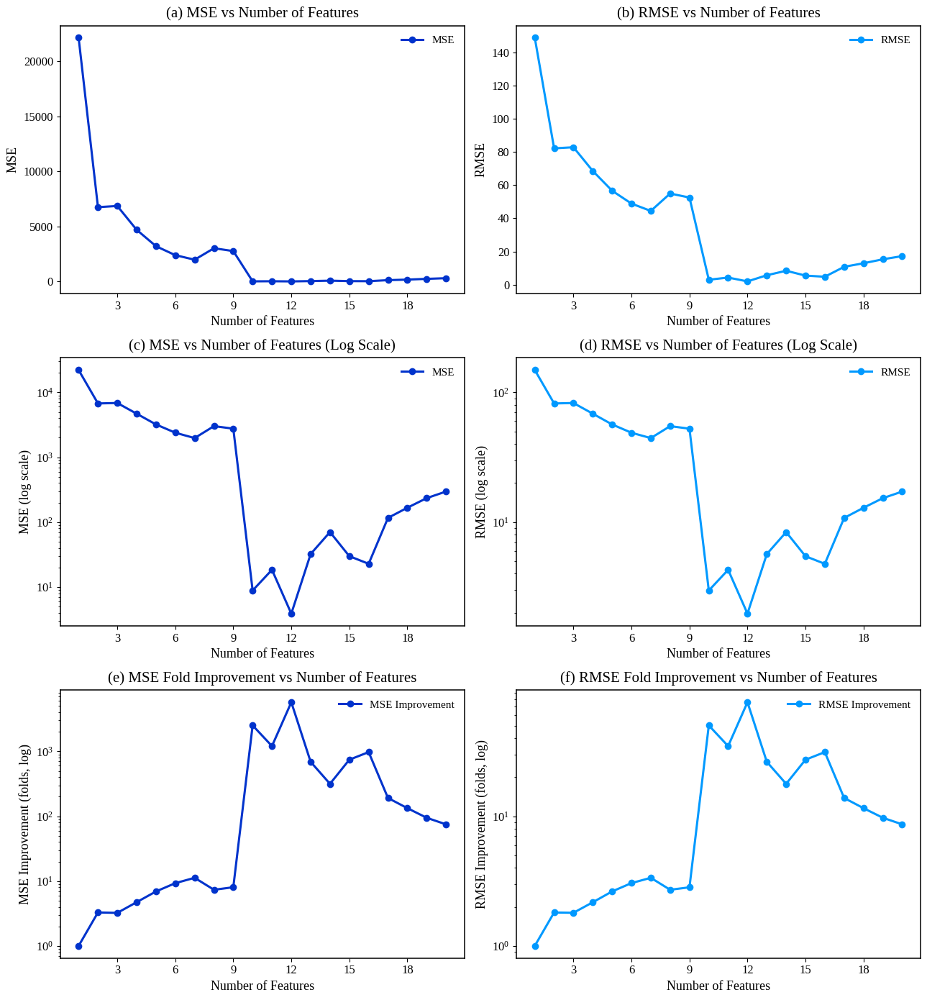

<Figure size 640x480 with 0 Axes>

In [ ]:
# ======================================
# Figure 6 – Clean Blue Theme (TNR style)
# ======================================

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

# --- Font & global settings ---
rcParams["font.family"] = "Liberation Serif"   # close to Times New Roman
rcParams["axes.linewidth"] = 1.1
rcParams["axes.labelsize"] = 13
rcParams["xtick.labelsize"] = 12
rcParams["ytick.labelsize"] = 12
rcParams["legend.fontsize"] = 11

# --- Data ---
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# --- Create 3×2 grid ---
fig, axes = plt.subplots(3, 2, figsize=(13, 14))
axes = axes.flatten()

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# --- Define style ---
color_mse  = "#0033CC"   # Deep blue
color_rmse = "#0099FF"   # Cyan blue
lw, ms = 2.2, 6

def style_plot(ax, title):
    ax.set_xlabel("Number of Features", fontsize=13)
    ax.set_title(title, fontsize=15, pad=8)
    ax.tick_params(axis="both", labelsize=12)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(frameon=False, loc="best")
    for spine in ax.spines.values():
        spine.set_linewidth(1.1)
    ax.grid(False)

# --- Panel (a) ---
axes[0].plot(df["Total features"], df["MSE"], marker="o", color=color_mse,
             markersize=ms, linewidth=lw, label="MSE")
axes[0].set_ylabel("MSE", fontsize=13)
style_plot(axes[0], titles[0])

# --- Panel (b) ---
axes[1].plot(df["Total features"], df["RMSE"], marker="o", color=color_rmse,
             markersize=ms, linewidth=lw, label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=13)
style_plot(axes[1], titles[1])

# --- Panel (c) ---
axes[2].plot(df["Total features"], df["MSE"], marker="o", color=color_mse,
             markersize=ms, linewidth=lw, label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=13)
style_plot(axes[2], titles[2])

# --- Panel (d) ---
axes[3].plot(df["Total features"], df["RMSE"], marker="o", color=color_rmse,
             markersize=ms, linewidth=lw, label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=13)
style_plot(axes[3], titles[3])

# --- Panel (e) ---
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="o", color=color_mse,
             markersize=ms, linewidth=lw, label="MSE Improvement")
axes[4].set_yscale("log")   # log scale looks cleaner given huge range
axes[4].set_ylabel("MSE Improvement (folds, log)", fontsize=13)
style_plot(axes[4], titles[4])

# --- Panel (f) ---
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="o", color=color_rmse,
             markersize=ms, linewidth=lw, label="RMSE Improvement")
axes[5].set_yscale("log")
axes[5].set_ylabel("RMSE Improvement (folds, log)", fontsize=13)
style_plot(axes[5], titles[5])

# --- Adjust layout ---
plt.subplots_adjust(hspace=0.45, wspace=0.3)
plt.tight_layout()
plt.savefig("Figure6_final_clean_blue.png", dpi=600, bbox_inches="tight", transparent=True)
plt.show()
plt.subplots_adjust(hspace=0.45, wspace=0.3)
plt.tight_layout()
plt.savefig("Figure6_final_clean_blue_300dpi.png", dpi=300, bbox_inches="tight", transparent=True)
plt.savefig("Figure6_final_clean_blue_200dpi.png", dpi=200, bbox_inches="tight", transparent=True)
plt.show()


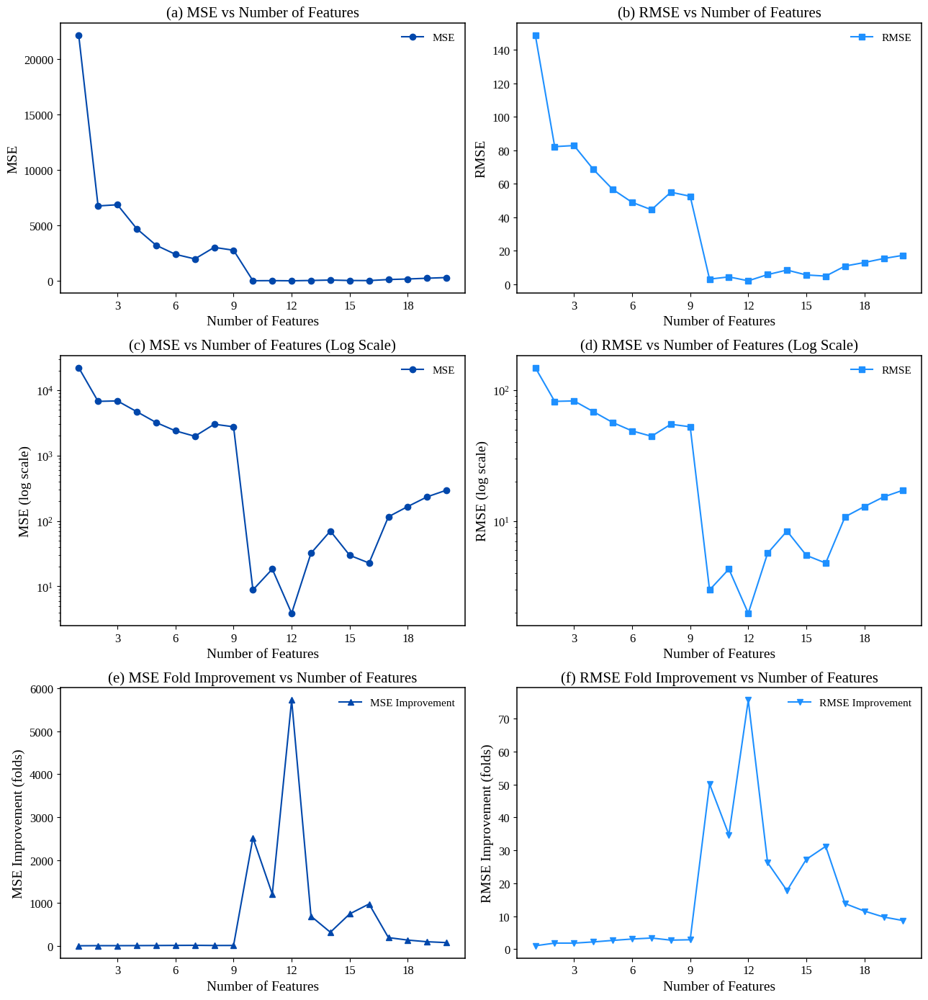

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator
from google.colab import files

# Font setup (Liberation Serif ≈ Times New Roman)
rcParams['font.family'] = 'Liberation Serif'

# Data
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# Figure layout
fig, axes = plt.subplots(3, 2, figsize=(13, 14))
axes = axes.flatten()

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# Panel (a)
axes[0].plot(df["Total features"], df["MSE"], marker="o", color="#0047AB", label="MSE")
axes[0].set_ylabel("MSE", fontsize=14)

# Panel (b)
axes[1].plot(df["Total features"], df["RMSE"], marker="s", color="#1E90FF", label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=14)

# Panel (c)
axes[2].plot(df["Total features"], df["MSE"], marker="o", color="#0047AB", label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=14)

# Panel (d)
axes[3].plot(df["Total features"], df["RMSE"], marker="s", color="#1E90FF", label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=14)

# Panel (e)
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="#0047AB", label="MSE Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=14)

# Panel (f)
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="#1E90FF", label="RMSE Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=14)

# Formatting all panels
for ax, title in zip(axes, titles):
    ax.set_xlabel("Number of Features", fontsize=14)
    ax.set_title(title, fontsize=15)  # Not bold
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis='both', labelsize=12)
    ax.legend(fontsize=11, frameon=False, loc='best')
    for spine in ax.spines.values():
        spine.set_linewidth(1.1)
    ax.grid(False)  # no grids

# Clean spacing
plt.subplots_adjust(hspace=0.45, wspace=0.3)
plt.tight_layout()

# Save locally in Colab workspace
plt.savefig("Figure6_clean_blue_300dpi.png", dpi=300, bbox_inches="tight", transparent=True)
plt.savefig("Figure6_clean_blue_200dpi.png", dpi=200, bbox_inches="tight", transparent=True)
plt.show()

# Auto-download to your computer
files.download("Figure6_clean_blue_300dpi.png")
files.download("Figure6_clean_blue_200dpi.png")


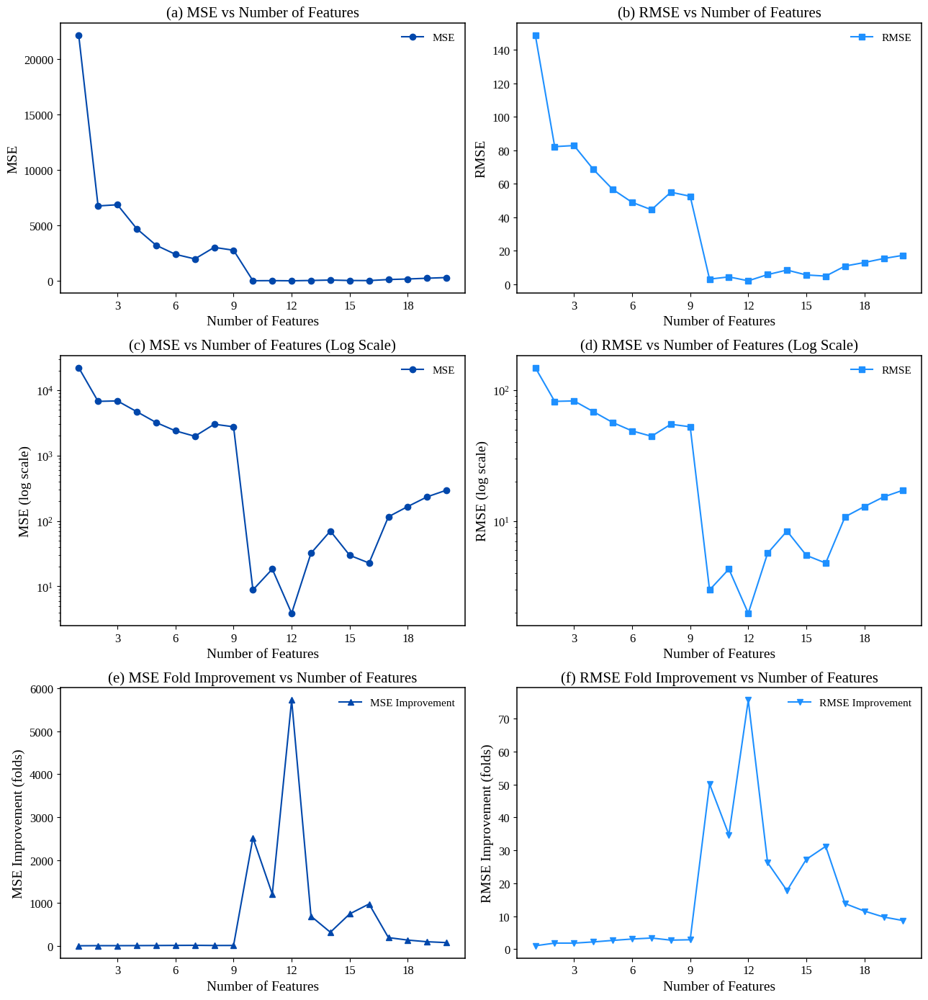

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator
from google.colab import files

# Font setup (Liberation Serif ≈ Times New Roman)
rcParams['font.family'] = 'Liberation Serif'
rcParams['axes.facecolor'] = 'white'
rcParams['figure.facecolor'] = 'white'

# Data
data = {
    "Total features": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    "MSE": [22157.58, 6753.58, 6861.9, 4697.08, 3205.72, 2388.56, 1975.39, 3017.36,
            2759.62, 8.81, 18.37, 3.87, 32.14, 70.15, 29.79, 22.73, 115.99, 166.32, 234.04, 295.73],
    "RMSE": [148.85, 82.18, 82.84, 68.54, 56.62, 48.87, 44.45, 54.93,
             52.53, 2.97, 4.29, 1.97, 5.67, 8.38, 5.46, 4.77, 10.77, 12.90, 15.30, 17.20],
    "MSE improvement (folds)": [1, 3.28, 3.23, 4.72, 6.91, 9.28, 11.22, 7.34, 8.03, 2515.05,
                                 1206.18, 5725.47, 689.41, 315.86, 743.79, 974.82, 191.03, 133.22, 94.67, 74.93],
    "RMSE improvement (folds)": [1, 1.81, 1.80, 2.17, 2.63, 3.05, 3.35, 2.71, 2.83, 50.15,
                                  34.73, 75.67, 26.26, 17.77, 27.27, 31.22, 13.82, 11.54, 9.73, 8.66]
}
df = pd.DataFrame(data)

# Figure layout
fig, axes = plt.subplots(3, 2, figsize=(13, 14))
axes = axes.flatten()

titles = [
    "(a) MSE vs Number of Features",
    "(b) RMSE vs Number of Features",
    "(c) MSE vs Number of Features (Log Scale)",
    "(d) RMSE vs Number of Features (Log Scale)",
    "(e) MSE Fold Improvement vs Number of Features",
    "(f) RMSE Fold Improvement vs Number of Features"
]

# Panel (a)
axes[0].plot(df["Total features"], df["MSE"], marker="o", color="#0047AB", label="MSE")
axes[0].set_ylabel("MSE", fontsize=14)

# Panel (b)
axes[1].plot(df["Total features"], df["RMSE"], marker="s", color="#1E90FF", label="RMSE")
axes[1].set_ylabel("RMSE", fontsize=14)

# Panel (c)
axes[2].plot(df["Total features"], df["MSE"], marker="o", color="#0047AB", label="MSE")
axes[2].set_yscale("log")
axes[2].set_ylabel("MSE (log scale)", fontsize=14)

# Panel (d)
axes[3].plot(df["Total features"], df["RMSE"], marker="s", color="#1E90FF", label="RMSE")
axes[3].set_yscale("log")
axes[3].set_ylabel("RMSE (log scale)", fontsize=14)

# Panel (e)
axes[4].plot(df["Total features"], df["MSE improvement (folds)"], marker="^", color="#0047AB", label="MSE Improvement")
axes[4].set_ylabel("MSE Improvement (folds)", fontsize=14)

# Panel (f)
axes[5].plot(df["Total features"], df["RMSE improvement (folds)"], marker="v", color="#1E90FF", label="RMSE Improvement")
axes[5].set_ylabel("RMSE Improvement (folds)", fontsize=14)

# Formatting all panels
for ax, title in zip(axes, titles):
    ax.set_xlabel("Number of Features", fontsize=14)
    ax.set_title(title, fontsize=15)  # clean, not bold
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis='both', labelsize=12)
    ax.legend(fontsize=11, frameon=False, loc='best')
    for spine in ax.spines.values():
        spine.set_linewidth(1.1)
    ax.grid(False)  # no grids

# Increase distance between panels
plt.subplots_adjust(hspace=0.6, wspace=0.5)
plt.tight_layout()

# Save (white background, transparent off)
plt.savefig("Figure6_white_bg_blue_300dpi.png", dpi=300, bbox_inches="tight", facecolor="white", transparent=False)
plt.show()

# Auto-download
files.download("Figure6_white_bg_blue_300dpi.png")


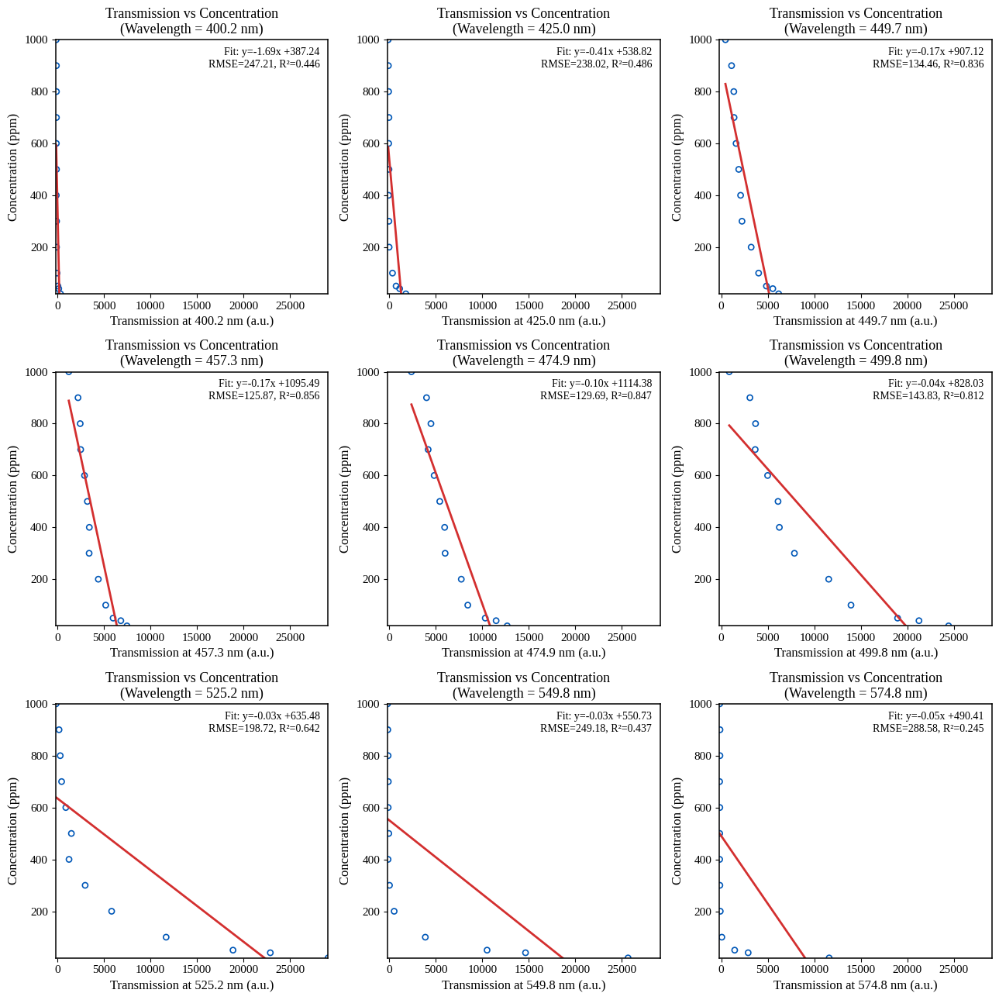

✅ Saved figure: fig_transmission_vs_conc_grid_300dpi.png
✅ Saved tidy data: trans_vs_conc_fit_data_with_rmse_r2.csv


In [ ]:
# === Clean 3×3 grid of Transmission vs Concentration (25 nm + best/worst) ===
# Uses:
#   - processed_sorted_transmission.csv
#   - mse_per_wavelength.csv   (fallback: auto-compute per-wavelength MSE if needed)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ---------- Style ----------
rcParams['font.family'] = 'Liberation Serif'   # TNR-like
rcParams['figure.facecolor'] = 'white'
rcParams['axes.facecolor']   = 'white'
rcParams['axes.linewidth']   = 1.1

TX_FILE  = "processed_sorted_transmission.csv"
MSE_FILE = "mse_per_wavelength.csv"   # <-- your uploaded file name

# ---------- Load transmission matrix ----------
# Rows = concentrations (index), columns = wavelengths (as strings like "449.667")
df = pd.read_csv(TX_FILE, index_col=0)

# Ensure index (concentration) numeric
try:
    df.index = pd.to_numeric(df.index)
except Exception:
    pass

# List of measured wavelengths from header
wavelengths = [float(c) for c in df.columns]

# ---------- Load/prepare MSE per wavelength ----------
def compute_mse_from_tx(trans_df):
    """Compute linear-regression MSE for each wavelength column against concentration index."""
    out = []
    y = trans_df.index.values
    for c in trans_df.columns:
        x = trans_df[c].values.reshape(-1, 1)
        mdl = LinearRegression().fit(x, y)
        yhat = mdl.predict(x)
        mse = mean_squared_error(y, yhat)
        out.append({"wavelength": float(c), "mse": float(mse), "rmse": float(np.sqrt(mse))})
    return pd.DataFrame(out)

try:
    mse_df = pd.read_csv(MSE_FILE)
    # normalize column names
    mse_df.columns = [c.strip().lower() for c in mse_df.columns]

    # pick wavelength column
    wl_col_candidates = ["wavelength", "wl", "lambda", "wavelength_nm"]
    wl_col = next((c for c in wl_col_candidates if c in mse_df.columns), None)
    if wl_col is None:
        raise ValueError("Could not find a wavelength column in mse_per_wavelength.csv")

    # pick/derive mse, rmse
    if "mse" not in mse_df.columns and "rmse" not in mse_df.columns:
        # No usable error columns -> compute from transmission data
        print("⚠️  No 'mse'/'rmse' in MSE file; computing MSEs from transmission data...")
        mse_df = compute_mse_from_tx(df)
        wl_col = "wavelength"
    else:
        if "mse" not in mse_df.columns and "rmse" in mse_df.columns:
            mse_df["mse"] = np.square(mse_df["rmse"])
        if "rmse" not in mse_df.columns and "mse" in mse_df.columns:
            mse_df["rmse"] = np.sqrt(mse_df["mse"])
    # keep only needed cols
    mse_df = mse_df[[wl_col, "mse", "rmse"]].copy()
    mse_df[wl_col] = mse_df[wl_col].astype(float)

except FileNotFoundError:
    print("⚠️  mse_per_wavelength.csv not found; computing MSEs from transmission data...")
    mse_df = compute_mse_from_tx(df)
    wl_col = "wavelength"

# ---------- Pick wavelengths: every 25 nm + best/worst ----------
best_wl  = float(mse_df.loc[mse_df["mse"].idxmin(), wl_col])
worst_wl = float(mse_df.loc[mse_df["mse"].idxmax(), wl_col])

target_wls = list(np.arange(400, 651, 25))  # 400…650 step 25
for extra in [best_wl, worst_wl]:
    if extra not in target_wls:
        target_wls.append(extra)
target_wls = sorted(target_wls)

def nearest(measured, t):
    return min(measured, key=lambda x: abs(x - float(t)))

picked = []
for t in target_wls:
    w = nearest(wavelengths, t)
    if w not in picked:
        picked.append(w)
picked = picked[:9]  # 3×3 grid max

# ---------- Global axis ranges for uniform scaling ----------
all_x, all_y = [], []
for wl in picked:
    col = f"{wl:.3f}" if f"{wl:.3f}" in df.columns else str(wl)
    if col not in df.columns:
        # last resort exact match by float compare
        cands = [c for c in df.columns if abs(float(c) - wl) < 1e-6]
        if not cands:
            continue
        col = cands[0]
    all_x.extend(df[col].values.tolist())
    all_y.extend(df.index.values.tolist())

x_min, x_max = np.nanmin(all_x), np.nanmax(all_x)
y_min, y_max = np.nanmin(all_y), np.nanmax(all_y)

# ---------- Plot ----------
n = len(picked)
ncols = 3
nrows = 3 if n > 6 else (2 if n > 3 else 1)
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 13))
axes = np.array(axes).reshape(-1)

pt_edge = "#0057B7"  # deep blue
fit_col = "#D32F2F"  # red
ms, lw = 26, 2.0

rows_out = []

for i, wl in enumerate(picked):
    ax = axes[i]
    col = f"{wl:.3f}" if f"{wl:.3f}" in df.columns else str(wl)
    if col not in df.columns:
        cands = [c for c in df.columns if abs(float(c) - wl) < 1e-6]
        if not cands:
            ax.set_visible(False)
            continue
        col = cands[0]

    X = df[col].values.reshape(-1, 1)
    y = df.index.values

    mdl = LinearRegression().fit(X, y)
    yhat = mdl.predict(X)
    coef = float(mdl.coef_[0])
    intercept = float(mdl.intercept_)
    mse = float(mean_squared_error(y, yhat))
    rmse = float(np.sqrt(mse))
    r2 = float(r2_score(y, yhat))

    # scatter
    ax.scatter(X, y, facecolors='none', edgecolors=pt_edge, s=ms, linewidths=1.2)
    # fit line over local range
    xx = np.linspace(X.min(), X.max(), 200)
    ax.plot(xx, coef*xx + intercept, color=fit_col, linewidth=lw)

    # labels
    ax.set_title(f"Transmission vs Concentration\n(Wavelength = {wl:.1f} nm)", fontsize=13, pad=6)
    ax.set_xlabel(f"Transmission at {wl:.1f} nm (a.u.)", fontsize=12)
    ax.set_ylabel("Concentration (ppm)", fontsize=12)
    ax.tick_params(axis='both', labelsize=11)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    for s in ax.spines.values():
        s.set_linewidth(1.1)
    ax.grid(False)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    # annotation
    txt = f"Fit: y={coef:+.2f}x {intercept:+.2f}\nRMSE={rmse:.2f}, R²={r2:.3f}"
    ax.text(0.97, 0.97, txt, transform=ax.transAxes, ha='right', va='top', fontsize=10,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=3))

    # collect rows
    for xv, yv, yhv in zip(X.flatten(), y, yhat):
        rows_out.append({
            "wavelength": float(wl),
            "transmission": float(xv),
            "concentration": float(yv),
            "predicted_concentration": float(yhv),
            "coef": coef,
            "intercept": intercept,
            "mse": mse,
            "rmse": rmse,
            "r2": r2
        })

# hide unused axes
for j in range(len(picked), len(axes)):
    axes[j].set_visible(False)

plt.subplots_adjust(wspace=0.35, hspace=0.42)
plt.tight_layout()
fig_name = "fig_transmission_vs_conc_grid_300dpi.png"
plt.savefig(fig_name, dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
plt.show()

# tidy output
out_csv = "trans_vs_conc_fit_data_with_rmse_r2.csv"
pd.DataFrame(rows_out).to_csv(out_csv, index=False)

print(f"✅ Saved figure: {fig_name}")
print(f"✅ Saved tidy data: {out_csv}")


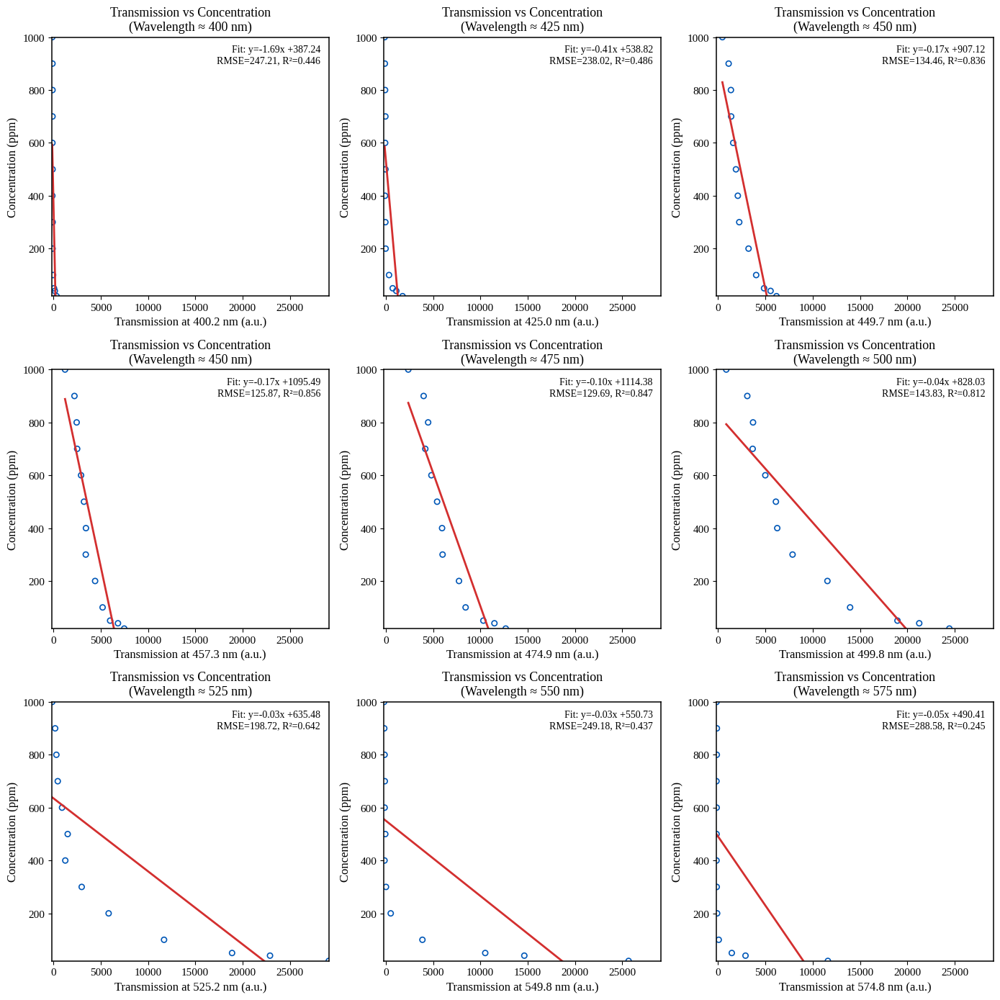

✅ Saved figure: fig_transmission_vs_conc_grid_clean_300dpi.png
✅ Saved tidy data: trans_vs_conc_fit_data_with_rmse_r2_clean.csv


In [ ]:
# === Transmission vs Concentration • 3×3 grid (25 nm + best/worst) ===
# Files expected in working dir:
#   - processed_sorted_transmission.csv
#   - mse_per_wavelength.csv   (if missing/insufficient, MSE is computed from TX data)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ---------- Style (Times-like, clean, white) ----------
rcParams['font.family'] = 'Liberation Serif'
rcParams['figure.facecolor'] = 'white'
rcParams['axes.facecolor']   = 'white'
rcParams['axes.linewidth']   = 1.1

TX_FILE  = "processed_sorted_transmission.csv"
MSE_FILE = "mse_per_wavelength.csv"

# ---------- Load transmission matrix ----------
df = pd.read_csv(TX_FILE, index_col=0)
try:
    df.index = pd.to_numeric(df.index)
except Exception:
    pass
wavelengths = [float(c) for c in df.columns]

# ---------- Load or compute per-wavelength MSE ----------
def compute_mse_from_tx(trans_df):
    out = []
    y = trans_df.index.values
    for c in trans_df.columns:
        x = trans_df[c].values.reshape(-1, 1)
        mdl = LinearRegression().fit(x, y)
        yhat = mdl.predict(x)
        mse = mean_squared_error(y, yhat)
        out.append({"wavelength": float(c), "mse": float(mse), "rmse": float(np.sqrt(mse))})
    return pd.DataFrame(out)

try:
    mse_df = pd.read_csv(MSE_FILE)
    mse_df.columns = [c.strip().lower() for c in mse_df.columns]
    wl_col = next((c for c in ["wavelength","wl","lambda","wavelength_nm"] if c in mse_df.columns), None)
    if wl_col is None or ("mse" not in mse_df.columns and "rmse" not in mse_df.columns):
        mse_df = compute_mse_from_tx(df)
        wl_col = "wavelength"
    else:
        if "mse" not in mse_df.columns:
            mse_df["mse"] = np.square(mse_df["rmse"])
        if "rmse" not in mse_df.columns:
            mse_df["rmse"] = np.sqrt(mse_df["mse"])
        mse_df = mse_df[[wl_col, "mse", "rmse"]].copy()
        mse_df[wl_col] = mse_df[wl_col].astype(float)
except FileNotFoundError:
    mse_df = compute_mse_from_tx(df)
    wl_col = "wavelength"

# ---------- Target wavelengths: every 25 nm + best & worst ----------
best_wl  = float(mse_df.loc[mse_df["mse"].idxmin(), wl_col])
worst_wl = float(mse_df.loc[mse_df["mse"].idxmax(), wl_col])

target_wls = list(np.arange(400, 651, 25))  # 400…650 step 25
for extra in [best_wl, worst_wl]:
    if extra not in target_wls:
        target_wls.append(extra)
target_wls = sorted(target_wls)

def nearest(measured, t):
    return min(measured, key=lambda x: abs(x - float(t)))

picked = []
for t in target_wls:
    w = nearest(wavelengths, t)
    if w not in picked:
        picked.append(w)
picked = picked[:9]  # 3×3 grid

# ---------- Global axis limits (uniform across panels) ----------
all_x, all_y = [], []
for wl in picked:
    col = f"{wl:.3f}" if f"{wl:.3f}" in df.columns else str(wl)
    if col not in df.columns:
        cands = [c for c in df.columns if abs(float(c) - wl) < 1e-6]
        if not cands:
            continue
        col = cands[0]
    all_x.extend(df[col].values.tolist())
    all_y.extend(df.index.values.tolist())

x_min, x_max = np.nanmin(all_x), np.nanmax(all_x)
y_min, y_max = np.nanmin(all_y), np.nanmax(all_y)

# ---------- Plot grid ----------
n = len(picked)
ncols = 3
nrows = 3 if n > 6 else (2 if n > 3 else 1)
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 14))
axes = np.array(axes).reshape(-1)

pt_edge = "#0057B7"  # deep blue
fit_col = "#D32F2F"  # red
ms, lw = 28, 2.0

rows_out = []

for i, wl in enumerate(picked):
    ax = axes[i]
    col = f"{wl:.3f}" if f"{wl:.3f}" in df.columns else str(wl)
    if col not in df.columns:
        cands = [c for c in df.columns if abs(float(c) - wl) < 1e-6]
        if not cands:
            ax.set_visible(False)
            continue
        col = cands[0]

    X = df[col].values.reshape(-1, 1)
    y = df.index.values

    mdl = LinearRegression().fit(X, y)
    yhat = mdl.predict(X)
    coef = float(mdl.coef_[0])
    intercept = float(mdl.intercept_)
    mse = float(mean_squared_error(y, yhat))
    rmse = float(np.sqrt(mse))
    r2 = float(r2_score(y, yhat))

    # scatter (open circles)
    ax.scatter(X, y, facecolors='none', edgecolors=pt_edge, s=ms, linewidths=1.2)
    # fit line
    xx = np.linspace(X.min(), X.max(), 200)
    ax.plot(xx, coef*xx + intercept, color=fit_col, linewidth=lw)

    # rounded label to nearest 25 nm with ≈
    rounded = int(round(wl/25.0)*25)
    ax.set_title(f"Transmission vs Concentration\n(Wavelength ≈ {rounded} nm)", fontsize=13, pad=7)

    ax.set_xlabel(f"Transmission at {wl:.1f} nm (a.u.)", fontsize=12)
    ax.set_ylabel("Concentration (ppm)", fontsize=12)
    ax.tick_params(axis='both', labelsize=11)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    for s in ax.spines.values():
        s.set_linewidth(1.1)
    ax.grid(False)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    # compact annotation
    txt = f"Fit: y={coef:+.2f}x {intercept:+.2f}\nRMSE={rmse:.2f}, R²={r2:.3f}"
    ax.text(0.97, 0.97, txt, transform=ax.transAxes, ha='right', va='top', fontsize=10,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.9, pad=3))

    for xv, yv, yhv in zip(X.flatten(), y, yhat):
        rows_out.append({
            "wavelength": float(wl),
            "rounded_label_nm": rounded,
            "transmission": float(xv),
            "concentration": float(yv),
            "predicted_concentration": float(yhv),
            "coef": coef,
            "intercept": intercept,
            "mse": mse,
            "rmse": rmse,
            "r2": r2
        })

# hide unused axes
for j in range(len(picked), len(axes)):
    axes[j].set_visible(False)

# wider spacing for clean look
plt.subplots_adjust(wspace=0.50, hspace=0.60)
plt.tight_layout()

fig_name = "fig_transmission_vs_conc_grid_clean_300dpi.png"
plt.savefig(fig_name, dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
plt.show()

out_csv = "trans_vs_conc_fit_data_with_rmse_r2_clean.csv"
pd.DataFrame(rows_out).to_csv(out_csv, index=False)

print(f"✅ Saved figure: {fig_name}")
print(f"✅ Saved tidy data: {out_csv}")


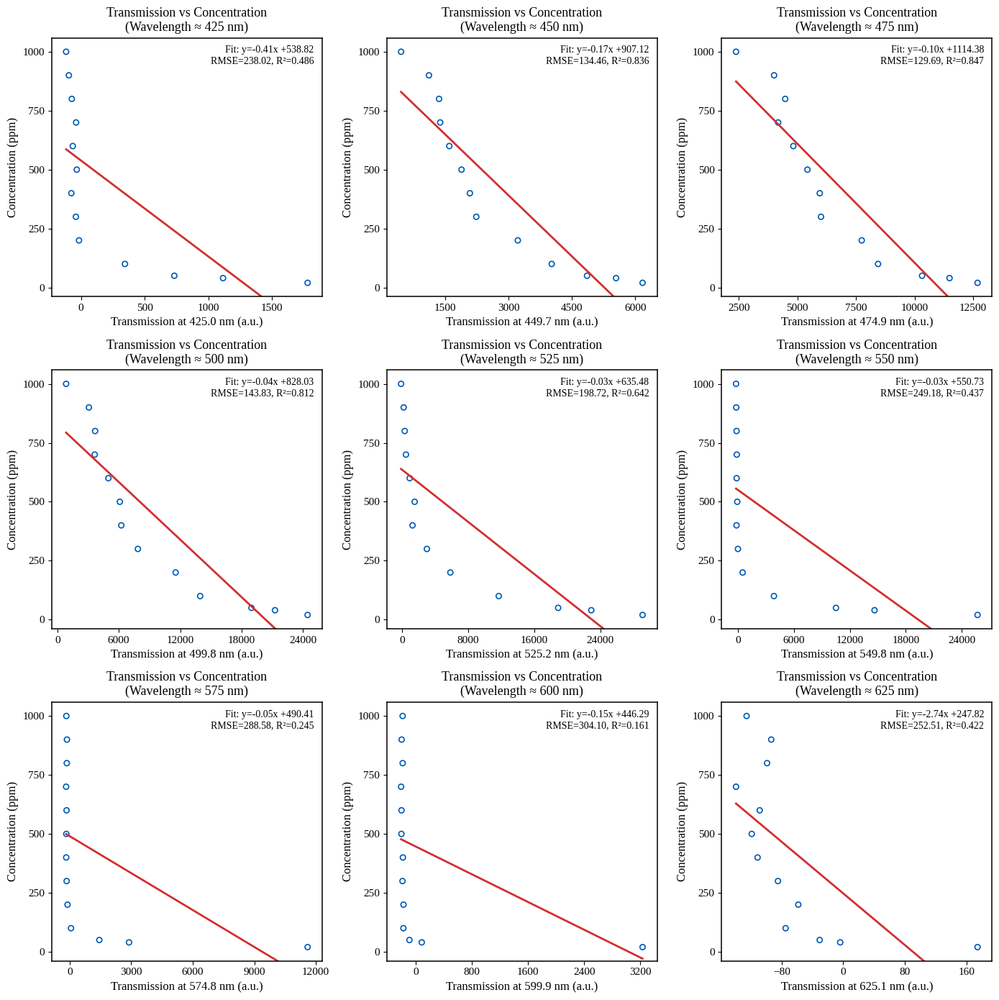

✅ Saved: fig_transmission_vs_conc_grid_300dpi_individual_axes.png


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# -------- settings --------
TX_FILE   = "processed_sorted_transmission.csv"   # or 'processed_smoothed_transmission.csv'
TARGET_WLS = [425, 450, 475, 500, 525, 550, 575, 600, 625]  # your 9 panels
FONT_FAM  = "Liberation Serif"  # Times-like
SAVE_NAME = "fig_transmission_vs_conc_grid_300dpi_individual_axes.png"

# -------- style --------
rcParams["font.family"] = FONT_FAM
rcParams["figure.facecolor"] = "white"
rcParams["axes.facecolor"]   = "white"
rcParams["axes.linewidth"]   = 1.1

# -------- data --------
df = pd.read_csv(TX_FILE, index_col=0)
df.index = pd.to_numeric(df.index, errors="coerce")  # concentrations on index
col_to_float = {c: float(c) for c in df.columns}
wl_float = np.array(list(col_to_float.values()))

def nearest_col(target_nm):
    nm_used = wl_float[np.argmin(np.abs(wl_float - target_nm))]
    for c, f in col_to_float.items():
        if abs(f - nm_used) < 1e-9:
            return c, nm_used
    return f"{nm_used:.3f}", nm_used

# pick exact columns for the 9 panels
chosen = [nearest_col(t) for t in TARGET_WLS]

# -------- plot grid (individual axes) --------
fig, axes = plt.subplots(3, 3, figsize=(14, 14))
axes = axes.flatten()

pt_edge = "#0057B7"  # deep blue
fit_col = "#D32F2F"  # red
ms, lw = 28, 2.0

def pad_limits(vmin, vmax, frac=0.04):
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
        return vmin-1, vmax+1
    pad = (vmax - vmin) * frac
    return vmin - pad, vmax + pad

for ax, (target_nm, (col_name, nm_used)) in zip(axes, zip(TARGET_WLS, chosen)):
    X = df[col_name].to_numpy(dtype=float).reshape(-1, 1)  # transmission at wl
    y = df.index.to_numpy(dtype=float)                     # concentration

    # Fit
    mdl  = LinearRegression().fit(X, y)
    pred = mdl.predict(X)
    coef = float(mdl.coef_[0])
    intercept = float(mdl.intercept_)
    rmse = float(np.sqrt(mean_squared_error(y, pred)))
    r2   = float(r2_score(y, pred))

    # Scatter + fit
    ax.scatter(X, y, facecolors="none", edgecolors=pt_edge, s=ms, linewidths=1.2)
    xx = np.linspace(X.min(), X.max(), 200)
    ax.plot(xx, coef*xx + intercept, color=fit_col, linewidth=lw)

    # Titles/labels (note ≈ for approximate wavelength)
    ax.set_title(f"Transmission vs Concentration\n(Wavelength ≈ {target_nm} nm)", fontsize=13, pad=7)
    ax.set_xlabel(f"Transmission at {nm_used:.1f} nm (a.u.)", fontsize=12)
    ax.set_ylabel("Concentration (ppm)", fontsize=12)

    # INDIVIDUAL limits (no sharing) + tidy ticks
    xmin, xmax = pad_limits(np.nanmin(X), np.nanmax(X), frac=0.06)
    ymin, ymax = pad_limits(np.nanmin(y), np.nanmax(y), frac=0.06)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.tick_params(axis="both", labelsize=11)
    for s in ax.spines.values():
        s.set_linewidth(1.1)
    ax.grid(False)

    # Compact stats box (top-right)
    ax.text(
        0.97, 0.97,
        f"Fit: y={coef:+.2f}x {intercept:+.2f}\nRMSE={rmse:.2f}, R²={r2:.3f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.9, pad=3),
    )

plt.subplots_adjust(wspace=0.55, hspace=0.70)  # more breathing room between panels
plt.tight_layout()
plt.savefig(SAVE_NAME, dpi=300, bbox_inches="tight", facecolor="white", transparent=False)
plt.show()
print(f"✅ Saved: {SAVE_NAME}")


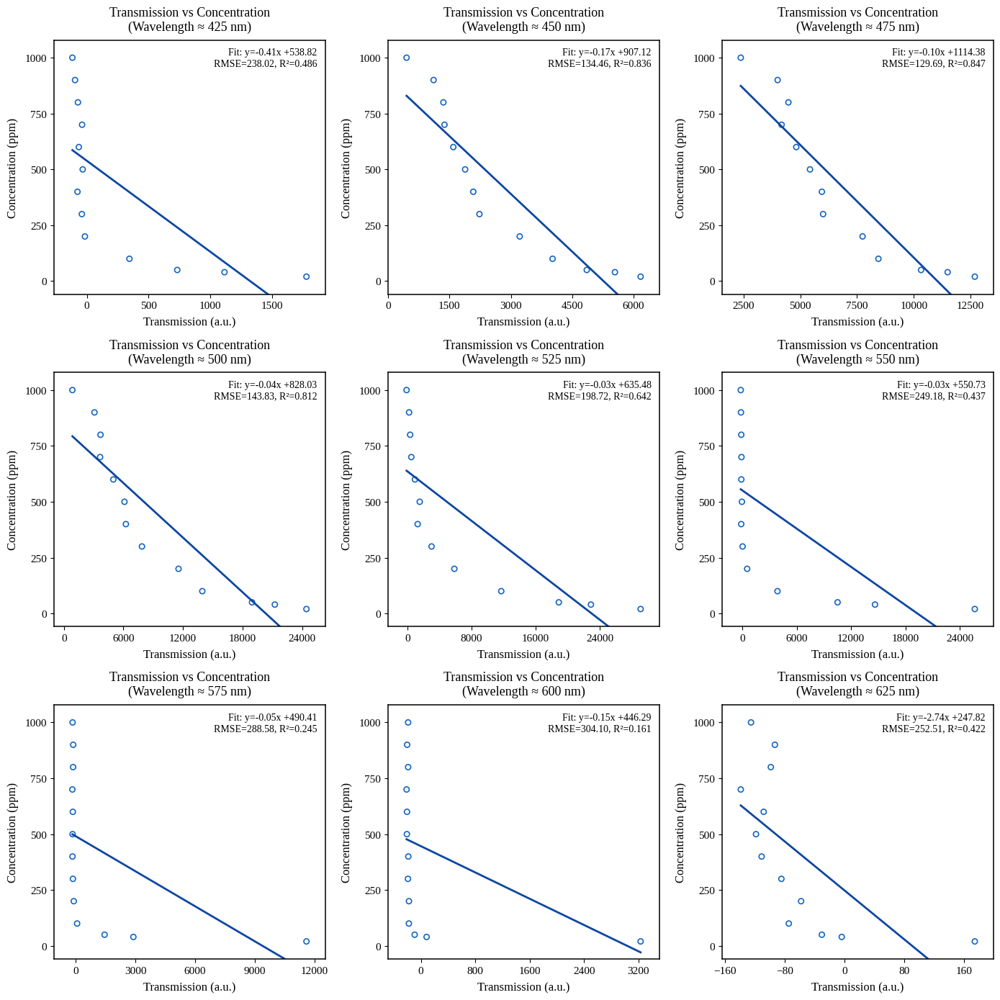

✅ Saved: fig_transmission_vs_conc_grid_clean_blue_300dpi.png


In [ ]:
# --- Fig. 3: 9× single-wavelength linear fits (clean/blue, per-panel axes) ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ========= paths & targets =========
TX_FILE    = "processed_sorted_transmission.csv"   # or "processed_smoothed_transmission.csv"
TARGET_WLS = [425, 450, 475, 500, 525, 550, 575, 600, 625]  # nm (rounded to 25 for labeling)

# ========= styling =========
rcParams["font.family"]   = "Liberation Serif"      # Times-like in Colab
rcParams["figure.facecolor"] = "white"
rcParams["axes.facecolor"]   = "white"
rcParams["axes.linewidth"]   = 1.1

pt_edge   = "#1565C0"   # deep blue (points)
fit_color = "#0D47A1"   # darker blue (fit line)
ms, lw = 28, 2.0

# ========= helpers =========
def pad_limits(vmin, vmax, frac=0.06):
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
        return vmin - 1, vmax + 1
    pad = (vmax - vmin) * frac
    return vmin - pad, vmax + pad

# ========= data =========
df = pd.read_csv(TX_FILE, index_col=0)
df.index = pd.to_numeric(df.index, errors="coerce")  # concentrations (ppm)
col_to_nm = {c: float(c) for c in df.columns}
nm_values = np.array(list(col_to_nm.values()))

def nearest_col(target_nm):
    nm_used = nm_values[np.argmin(np.abs(nm_values - target_nm))]
    # return the original column name that maps to nm_used
    for col, nm in col_to_nm.items():
        if abs(nm - nm_used) < 1e-9:
            return col, nm_used
    return f"{nm_used:.3f}", nm_used

chosen = [nearest_col(t) for t in TARGET_WLS]

# ========= plot =========
fig, axes = plt.subplots(3, 3, figsize=(14, 14))
axes = axes.flatten()

for ax, (rounded_nm, (col_name, nm_used)) in zip(axes, zip(TARGET_WLS, chosen)):
    X = df[col_name].to_numpy(dtype=float).reshape(-1, 1)  # transmission at that wl
    y = df.index.to_numpy(dtype=float)                     # concentration (ppm)

    # linear fit + stats
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)
    coef = float(model.coef_[0])
    intercept = float(model.intercept_)
    rmse = float(np.sqrt(mean_squared_error(y, y_pred)))
    r2   = float(r2_score(y, y_pred))

    # scatter + fit (blue theme)
    ax.scatter(X, y, facecolors="none", edgecolors=pt_edge, s=ms, linewidths=1.2)
    xx = np.linspace(X.min(), X.max(), 200)
    ax.plot(xx, coef * xx + intercept, color=fit_color, linewidth=lw)

    # title at top (two lines), x label generic, y label ppm
    ax.set_title(
        f"Transmission vs Concentration\n(Wavelength ≈ {rounded_nm} nm)",
        fontsize=13, pad=10
    )
    ax.set_xlabel("Transmission (a.u.)", fontsize=12, labelpad=6)
    ax.set_ylabel("Concentration (ppm)", fontsize=12, labelpad=6)

    # individual axes (no sharing)
    xmin, xmax = pad_limits(np.nanmin(X), np.nanmax(X), frac=0.08)
    ymin, ymax = pad_limits(np.nanmin(y), np.nanmax(y), frac=0.08)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    # neat ticks/spines
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.tick_params(axis="both", labelsize=11)
    for s in ax.spines.values():
        s.set_linewidth(1.1)
    ax.grid(False)

    # compact stats box (top-right)
    ax.text(
        0.97, 0.97,
        f"Fit: y={coef:+.2f}x {intercept:+.2f}\nRMSE={rmse:.2f}, R²={r2:.3f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.95, pad=3)
    )

# extra breathing room so titles don’t bump labels
plt.subplots_adjust(wspace=0.70, hspace=1.05, left=0.07, right=0.98, top=0.95, bottom=0.07)
plt.tight_layout()

out = "fig_transmission_vs_conc_grid_clean_blue_300dpi.png"
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white", transparent=False)
plt.show()
print(f"✅ Saved: {out}")


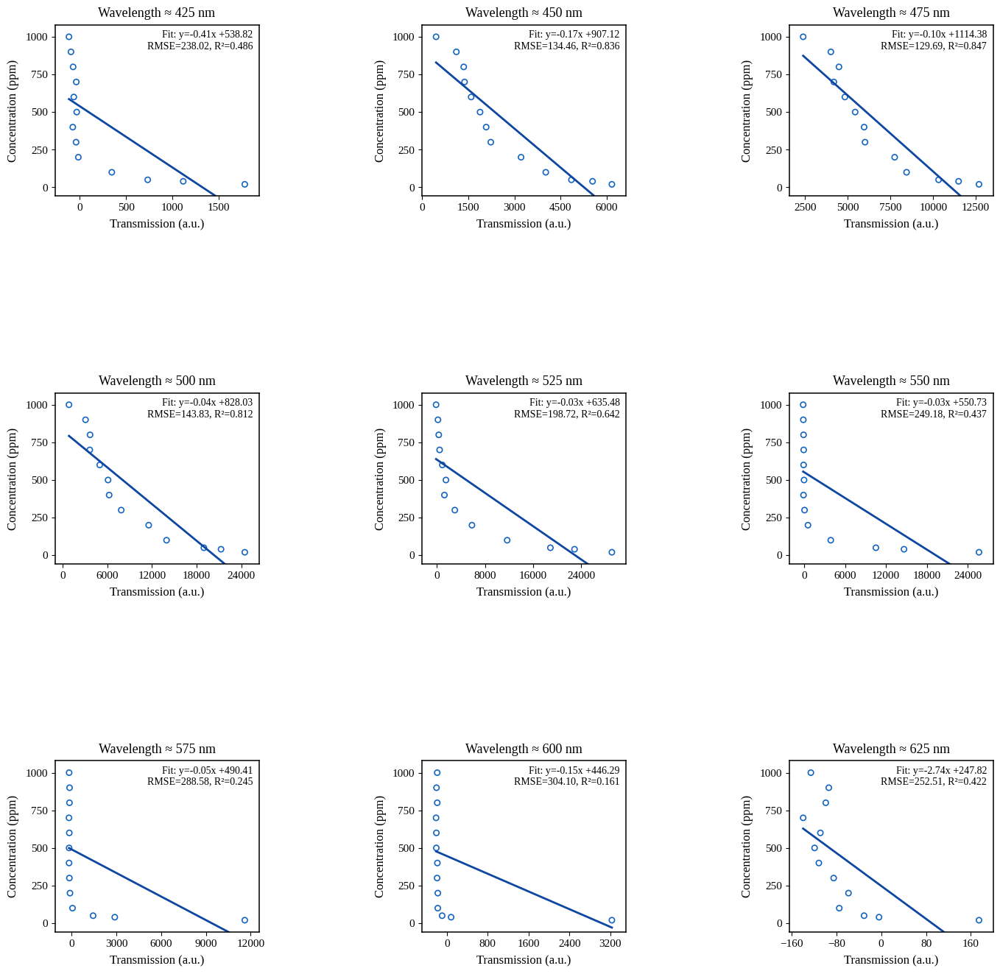

✅ Saved: fig_transmission_vs_conc_grid_clean_blue_min_titles_300dpi.png


In [ ]:
# --- Fig. 3 (clean): 9× single-wavelength linear fits, blue theme, minimal titles ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ========= files & target wavelengths =========
TX_FILE    = "processed_sorted_transmission.csv"        # or "processed_smoothed_transmission.csv"
TARGET_WLS = [425, 450, 475, 500, 525, 550, 575, 600, 625]  # nm (rounded for labeling)

# ========= style =========
rcParams["font.family"]        = "Liberation Serif"     # Times-like in Colab
rcParams["figure.facecolor"]   = "white"
rcParams["axes.facecolor"]     = "white"
rcParams["axes.linewidth"]     = 1.1

pt_edge   = "#1565C0"     # deep blue (markers)
fit_color = "#0D47A1"     # darker blue (fit)
ms, lw    = 28, 2.0

def pad_limits(vmin, vmax, frac=0.06):
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
        return vmin - 1, vmax + 1
    pad = (vmax - vmin) * frac
    return vmin - pad, vmax + pad

# ========= load data =========
df = pd.read_csv(TX_FILE, index_col=0)
df.index = pd.to_numeric(df.index, errors="coerce")  # concentrations (ppm)
col_to_nm = {c: float(c) for c in df.columns}
nm_values = np.array(list(col_to_nm.values()))

def nearest_col(target_nm):
    nm_used = nm_values[np.argmin(np.abs(nm_values - target_nm))]
    for col, nm in col_to_nm.items():
        if abs(nm - nm_used) < 1e-9:
            return col, nm_used
    return f"{nm_used:.3f}", nm_used

chosen = [nearest_col(t) for t in TARGET_WLS]

# ========= plot =========
fig, axes = plt.subplots(3, 3, figsize=(14, 14))
axes = axes.flatten()

for ax, (rounded_nm, (col_name, nm_used)) in zip(axes, zip(TARGET_WLS, chosen)):
    X = df[col_name].to_numpy(dtype=float).reshape(-1, 1)  # transmission
    y = df.index.to_numpy(dtype=float)                     # concentration (ppm)

    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)
    coef = float(model.coef_[0])
    intercept = float(model.intercept_)
    rmse = float(np.sqrt(mean_squared_error(y, y_pred)))
    r2   = float(r2_score(y, y_pred))

    ax.scatter(X, y, facecolors="none", edgecolors=pt_edge, s=ms, linewidths=1.2)
    xx = np.linspace(X.min(), X.max(), 200)
    ax.plot(xx, coef * xx + intercept, color=fit_color, linewidth=lw)

    # Minimal panel title (no parentheses)
    ax.set_title(f"Wavelength ≈ {rounded_nm} nm", fontsize=13, pad=8)

    ax.set_xlabel("Transmission (a.u.)", fontsize=12, labelpad=6)
    ax.set_ylabel("Concentration (ppm)", fontsize=12, labelpad=6)

    xmin, xmax = pad_limits(np.nanmin(X), np.nanmax(X), frac=0.08)
    ymin, ymax = pad_limits(np.nanmin(y), np.nanmax(y), frac=0.08)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.tick_params(axis="both", labelsize=11)

    for s in ax.spines.values():
        s.set_linewidth(1.1)
    ax.grid(False)

    ax.text(
        0.97, 0.97,
        f"Fit: y={coef:+.2f}x {intercept:+.2f}\nRMSE={rmse:.2f}, R²={r2:.3f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.95, pad=3)
    )

# airy layout so nothing collides
plt.subplots_adjust(wspace=0.80, hspace=1.15, left=0.07, right=0.98, top=0.95, bottom=0.07)

# optional clean figure-level title (uncomment if you want it)
# fig.suptitle("Single-wavelength linear fits", fontsize=15, y=0.995)

out = "fig_transmission_vs_conc_grid_clean_blue_min_titles_300dpi.png"
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white", transparent=False)
plt.show()
print(f"✅ Saved: {out}")


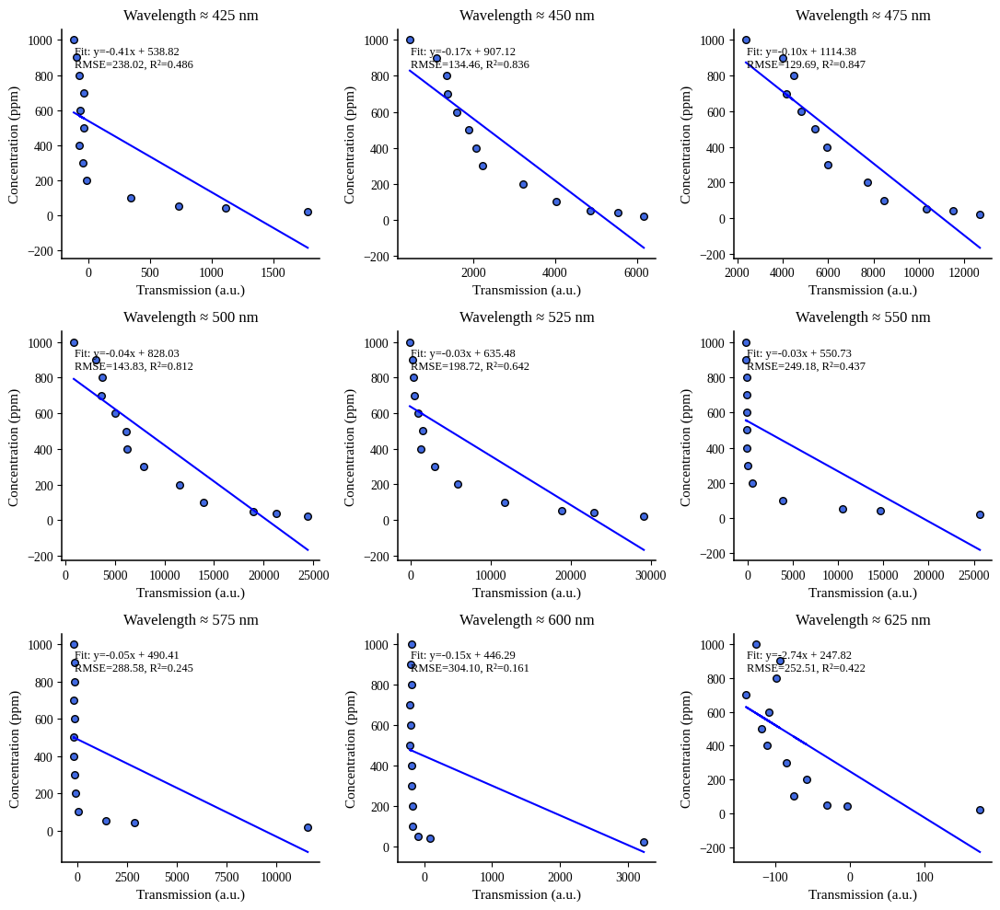

In [ ]:
# --- Clean 9-panel linear fit figure for journal submission ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load data
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)
mse_df = pd.read_csv("mse_per_wavelength.csv")

# Prepare data
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)
wavelengths = [float(col) for col in X.columns]

# Wavelengths for plots
special_wavelengths = [425, 450, 475, 500, 525, 550, 575, 600, 625]

# Set up figure
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
axes = axes.flatten()

for i, wl in enumerate(special_wavelengths):
    ax = axes[i]
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)
    coef = model.coef_[0]
    intercept = model.intercept_
    rmse = np.sqrt(mean_squared_error(y_plot, y_pred))
    r2 = r2_score(y_plot, y_pred)

    # Scatter and fit line
    ax.scatter(X_plot, y_plot, color="royalblue", edgecolor="black", s=30, label="Data")
    ax.plot(X_plot, y_pred, color="blue", linewidth=1.5)

    # Titles and labels
    ax.set_title(f"Wavelength ≈ {int(round(wl))} nm", fontsize=12, pad=8)
    ax.set_xlabel("Transmission (a.u.)", fontsize=11)
    ax.set_ylabel("Concentration (ppm)", fontsize=11)
    ax.text(0.05, 0.93, f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}, R²={r2:.3f}",
            transform=ax.transAxes, fontsize=9, verticalalignment='top')

    # Formatting
    ax.tick_params(axis="both", labelsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Adjust layout for neatness
plt.subplots_adjust(hspace=0.45, wspace=0.35)
plt.tight_layout()

# Save high-quality figure
plt.savefig("fig_transmission_vs_conc_grid_clean_blue_final_300dpi.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()


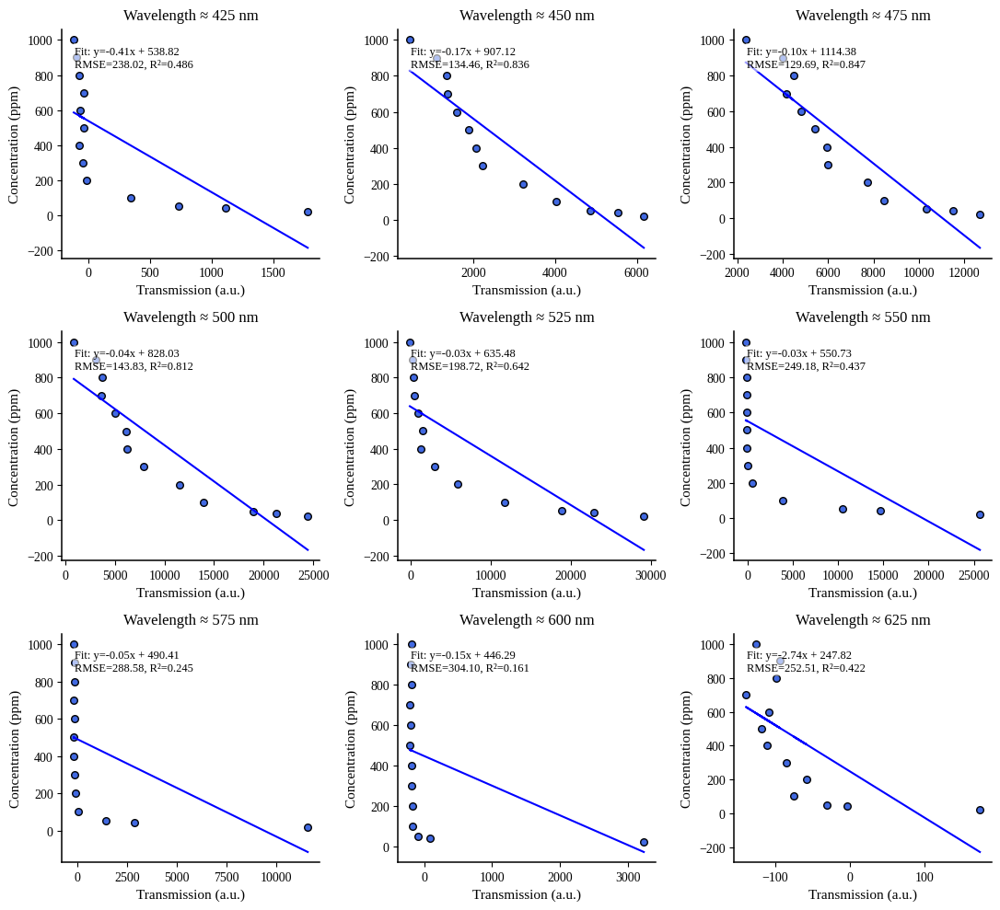

In [ ]:
# --- Clean 9-panel linear fit figure with non-overlapping legends ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load data
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)
mse_df = pd.read_csv("mse_per_wavelength.csv")

# Prepare data
X = df.copy()
y = X.index.values
X.reset_index(drop=True, inplace=True)
wavelengths = [float(col) for col in X.columns]

# Wavelengths for plots
special_wavelengths = [425, 450, 475, 500, 525, 550, 575, 600, 625]

# Set up figure
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
axes = axes.flatten()

for i, wl in enumerate(special_wavelengths):
    ax = axes[i]
    closest_wl = min(wavelengths, key=lambda x: abs(x - wl))
    wl_col = f"{closest_wl:.3f}"

    X_plot = df[wl_col].values.reshape(-1, 1)
    y_plot = df.index.values

    model = LinearRegression().fit(X_plot, y_plot)
    y_pred = model.predict(X_plot)
    coef = model.coef_[0]
    intercept = model.intercept_
    rmse = np.sqrt(mean_squared_error(y_plot, y_pred))
    r2 = r2_score(y_plot, y_pred)

    # Scatter and fit line
    ax.scatter(X_plot, y_plot, color="royalblue", edgecolor="black", s=30, label="Data")
    ax.plot(X_plot, y_pred, color="blue", linewidth=1.5)

    # Titles and labels
    ax.set_title(f"Wavelength ≈ {int(round(wl))} nm", fontsize=12, pad=8)
    ax.set_xlabel("Transmission (a.u.)", fontsize=11)
    ax.set_ylabel("Concentration (ppm)", fontsize=11)

    # Dynamically select legend corner based on slope sign
    if coef < 0:
        xpos, ypos, ha = 0.05, 0.93, 'left'
    else:
        xpos, ypos, ha = 0.95, 0.93, 'right'

    ax.text(
        xpos, ypos,
        f"Fit: y={coef:.2f}x + {intercept:.2f}\nRMSE={rmse:.2f}, R²={r2:.3f}",
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment='top',
        horizontalalignment=ha,
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', boxstyle='round,pad=0.2')
    )

    # Formatting
    ax.tick_params(axis="both", labelsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Adjust layout
plt.subplots_adjust(hspace=0.45, wspace=0.35)
plt.tight_layout()

# Save high-quality figure
plt.savefig("fig_transmission_vs_conc_grid_clean_blue_final_nonoverlap_300dpi.png",
            dpi=300, bbox_inches="tight", facecolor="white")
plt.show()


✅ Saved: fig_transmission_vs_conc_grid_clean_blue_normconc_300dpi.png


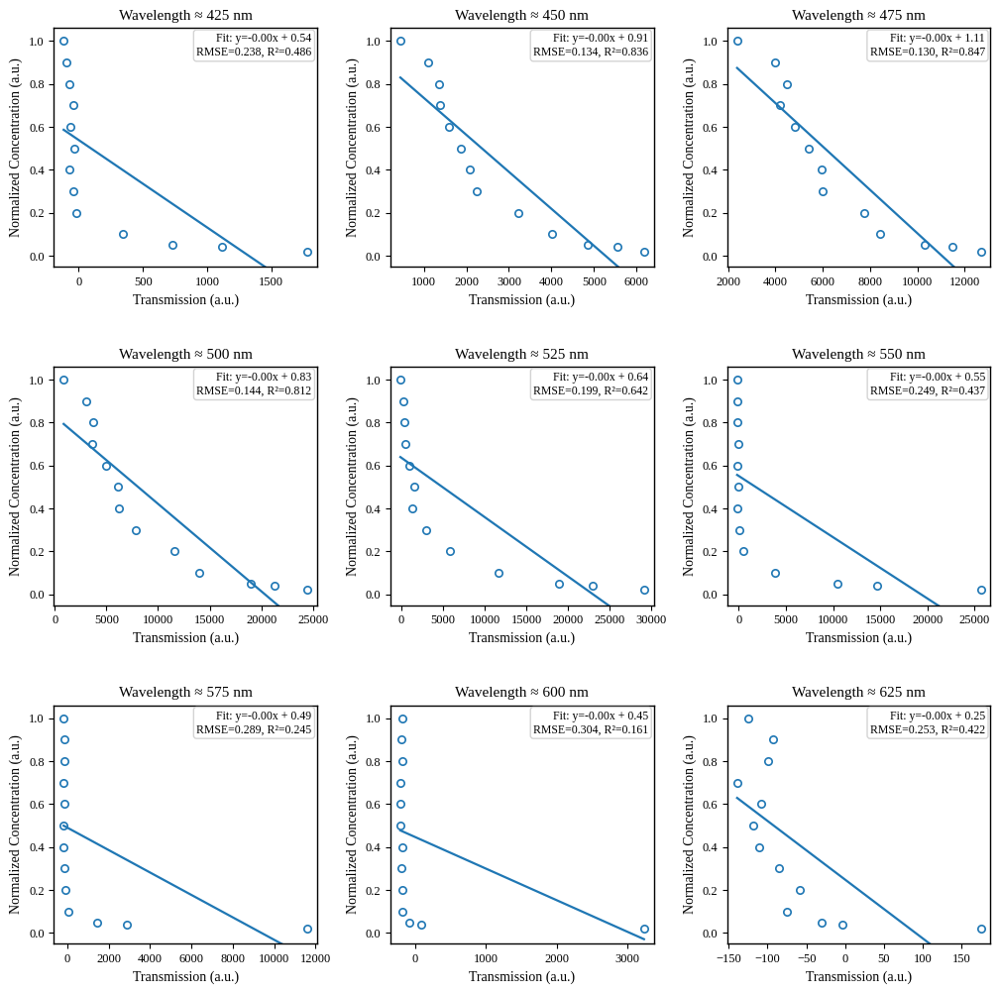

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from sklearn.linear_model import LinearRegression

# ---- Aesthetics (Times-like) ----
rcParams["font.family"] = ["Times New Roman", "Liberation Serif", "DejaVu Serif"]
rcParams["mathtext.fontset"] = "dejavuserif"

# ==== Load data ====
df = pd.read_csv("processed_sorted_transmission.csv", index_col=0)

# Concentration vector (assumed to be index). Normalize to 0–1
conc_raw = df.index.values.astype(float)
conc = conc_raw / conc_raw.max()   # 0–1 normalization

# Columns are wavelengths as strings; grab as floats to find nearest
wavelengths = np.array([float(c) for c in df.columns])

# Target wavelengths (nm)
target = np.array([425, 450, 475, 500, 525, 550, 575, 600, 625])

# Find closest actual columns
closest = np.array([wavelengths[np.argmin(np.abs(wavelengths - t))] for t in target])
closest_cols = [f"{wl:.3f}" for wl in closest]

# ==== Set up figure ====
fig, axes = plt.subplots(3, 3, figsize=(10.5, 10.5))  # square & compact
axes = axes.ravel()

# Theme colors
line_color = "#1f77b4"  # classic Matplotlib blue
scatter_edge = "#1f77b4"
scatter_face = "white"

for ax, wl, col in zip(axes, closest, closest_cols):
    x = df[col].values.astype(float).reshape(-1, 1)  # Transmission
    y = conc                                      # Normalized concentration (0–1)

    # Linear regression
    model = LinearRegression().fit(x, y)
    yhat = model.predict(x)
    m = model.coef_[0]
    b = model.intercept_

    rmse = float(np.sqrt(np.mean((y - yhat) ** 2)))
    # R^2 manually (sklearn’s score is fine too, but here’s explicit):
    ss_res = float(np.sum((y - yhat) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    # Scatter + fit
    ax.scatter(x, y, s=28, facecolor=scatter_face, edgecolor=scatter_edge, linewidth=1.2)
    # fit line: plot against sorted x for a clean line
    xs = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)
    ax.plot(xs, model.predict(xs), color=line_color, linewidth=1.6)

    # Tight x/y limits with a little breathing room
    xpad = 0.04 * (x.max() - x.min() if x.max() > x.min() else 1.0)
    ypad = 0.06
    ax.set_xlim(x.min() - xpad, x.max() + xpad)
    ax.set_ylim(max(0 - ypad, -0.05), min(1 + ypad, 1.08))

    # Minimal, consistent labels
    ax.set_xlabel("Transmission (a.u.)", fontsize=10)
    ax.set_ylabel("Normalized Concentration (a.u.)", fontsize=10)

    # Simple title with approx sign & rounded integer
    ax.set_title(f"Wavelength ≈ {int(round(wl))} nm", fontsize=11)

    # Ticks, no grid
    ax.tick_params(axis="both", labelsize=9)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    # Annotation box in axes coords (never overlaps points visually)
    box_txt = f"Fit: y={m:.2f}x + {b:.2f}\nRMSE={rmse:.3f}, R²={r2:.3f}"
    ax.text(
        0.98, 0.98, box_txt,
        transform=ax.transAxes, ha="right", va="top", fontsize=8.5,
        bbox=dict(facecolor="white", edgecolor="#CFCFCF", boxstyle="round,pad=0.25", alpha=0.9)
    )

# Spacing — neat but not cramped
plt.subplots_adjust(left=0.08, right=0.98, top=0.95, bottom=0.07, wspace=0.28, hspace=0.42)

# Save with white background
outfile = "fig_transmission_vs_conc_grid_clean_blue_normconc_300dpi.png"
plt.savefig(outfile, dpi=300, facecolor="white", bbox_inches="tight")
print(f"✅ Saved: {outfile}")
plt.show()


Saved: fig_transmission_vs_conc_grid_clean_blue_norm_300dpi.png


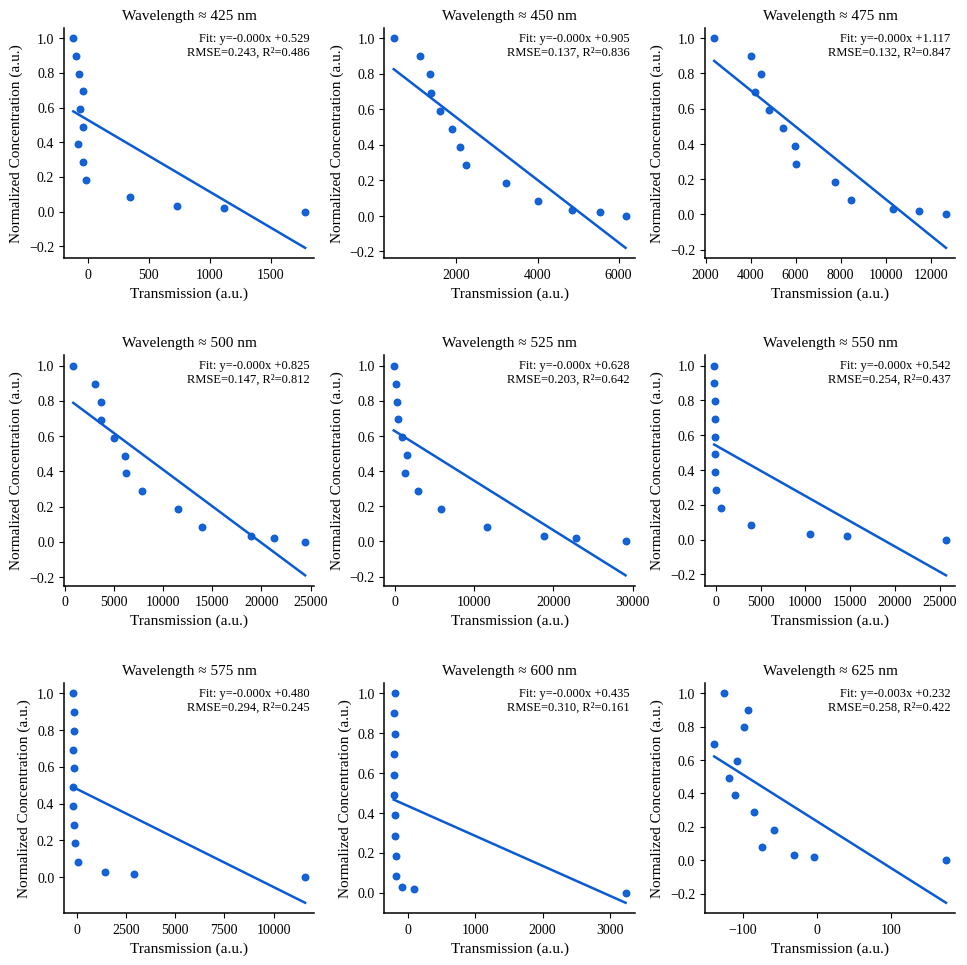

In [ ]:
# --- CLEAN BLUE 3x3 FIGURE (independent x-lims, no grids, neat spacing) ---

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# --------- Styling (Times-like, dark blue, no grid) ----------
rcParams["font.family"] = "Liberation Serif"          # Times-like on Colab
rcParams["mathtext.default"] = "regular"
DARK_BLUE = "#0A5BD3"                                  # markers/line
AXLW = 1.1                                             # spine width

# --------- Inputs ----------
TX_FILE = "processed_sorted_transmission.csv"
MSE_FILE_CSV = "mse_per_wavelength.csv"               # fallback if _with_std not present
PANEL_WLS = [425, 450, 475, 500, 525, 550, 575, 600, 625]  # target wavelengths (nm)

# --------- Load data ----------
df = pd.read_csv(TX_FILE, index_col=0)
# Concentration index (normalize to 0..1 so units are a.u.)
conc_raw = df.index.values.astype(float)
conc_norm = (conc_raw - conc_raw.min()) / (conc_raw.max() - conc_raw.min())
y_label = "Normalized Concentration (a.u.)"

# make X numeric-only, keep col list of float wavelengths
X = df.copy()
X.reset_index(drop=True, inplace=True)
wavelengths = np.array([float(c) for c in X.columns])

# map each target wl to the closest available column name
def nearest_wl_column(target):
    wl = wavelengths[np.argmin(np.abs(wavelengths - target))]
    return f"{wl:.3f}", float(wl)

pairs = [nearest_wl_column(w) for w in PANEL_WLS]  # list of (colname, actual_wl)

# --------- Build figure ----------
fig, axes = plt.subplots(3, 3, figsize=(11.5, 11.5))   # roomy but not spaced out
axes = axes.ravel()

for ax, (colname, wl_actual), title_wl in zip(axes, pairs, PANEL_WLS):
    # X (transmission column), y (normalized concentration)
    x = df[colname].values.astype(float)
    y = conc_norm

    # Linear fit
    model = LinearRegression().fit(x.reshape(-1,1), y)
    yhat = model.predict(x.reshape(-1,1))
    m, b = model.coef_[0], model.intercept_
    rmse = np.sqrt(mean_squared_error(y, yhat))
    r2   = r2_score(y, yhat)

    # Independent x-limits with a little padding
    xmin, xmax = np.nanmin(x), np.nanmax(x)
    pad = 0.04*(xmax - xmin) if xmax > xmin else 1.0
    ax.set_xlim(xmin - pad, xmax + pad)

    # Plot
    ax.scatter(x, y, s=22, facecolor=DARK_BLUE, edgecolor=DARK_BLUE, alpha=0.95)
    ax.plot(np.sort(x), yhat[np.argsort(x)], color=DARK_BLUE, lw=1.8)

    # Title (no parentheses), rounded to nearest 25 with approx sign
    ax.set_title(f"Wavelength ≈ {int(round(title_wl/25)*25)} nm", fontsize=11)

    # Axes labels (shared text but placed on every panel for clarity in a 3×3)
    ax.set_xlabel("Transmission (a.u.)", fontsize=11)
    ax.set_ylabel(y_label, fontsize=11)

    # Ticks & spines
    ax.tick_params(labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_linewidth(AXLW)

    # Fit box—keep out of the data with normalized axes coords
    txt = f"Fit: y={m:+.3f}x {b:+.3f}\nRMSE={rmse:.3f}, R²={r2:.3f}"
    ax.text(
        0.98, 0.98, txt,
        transform=ax.transAxes, ha="right", va="top",
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, boxstyle="round,pad=0.25")
    )

# Panel spacing (tight but neat)
plt.subplots_adjust(wspace=0.28, hspace=0.42)

# Save & show
outfile = "fig_transmission_vs_conc_grid_clean_blue_norm_300dpi.png"
plt.savefig(outfile, dpi=300, bbox_inches="tight", transparent=False)
print(f"Saved: {outfile}")
plt.show()
